# Libraries

In [2]:
#### libraries ####
import os
import mne
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import signal
from scipy.io import wavfile

# from pybv import write_brainvision
from pyprep.prep_pipeline import PrepPipeline
from mne_icalabel import label_components

# autoreject
from autoreject import AutoReject

# working directory
work_dir = '/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/'
exp_dir = work_dir + 'Experiments/experiment_english/'

# read in participant file
df = pd.read_csv(work_dir + 'Data/data_english/data_analysis/participants_include.txt', delimiter = '\t')
include_ppts = df[df['include']==1]['participant'].astype(str).tolist()
include_ppts = [x for x in include_ppts if x.split('_')[0]=='VOT']

# create a montage file for the pipeline
montage = mne.channels.make_standard_montage("standard_1020")

# Raw data quality check

In [ ]:
# directory
input_dir = work_dir + '/Data/data_english/eeg_raw/eeg_brainvision/'

# file name
file = 'CUE2024_0016_F0.vhdr'

# read in file
raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

# drop the audio channel in data
raw.drop_channels(['StimTrak'])

# set montage
raw.set_montage('standard_1020')

# # drop channels
# raw.drop_channels(['FC6'])

# check information
print(raw.info)

# plot spectrum of raw EEG
raw.compute_psd().plot()
plt.show()

# event distributions
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
fig = mne.viz.plot_events(
    events_from_annot, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp
)


# segmentation for ERP
epochs = mne.Epochs(
    raw,
    events = events_from_annot, event_id = event_dict,
    tmin = -0.2, tmax = 1,
    # remove epochs that meet the rejection criteria
    reject = None,
    preload = True,
)

# plot epochs
epochs.plot_image(combine="mean", vmin=-100, vmax=100)

# butterfly
epochs.average().plot()
plt.show()

# Save as EEGLAB file
# file = 'CUE2024_0008_VOT_corr_prep_ica.fif'

# # read in file
# raw = mne.io.read_raw_fif(input_dir + file, preload = True)

# # save
# mne.export.export_raw(output_dir + "CUE2024_0008_VOT_corr_prep_ica.set", 
#                       raw, fmt='auto', physical_range='auto', add_ch_type=False, overwrite=True, verbose=None)

In [ ]:
# if needed, plot a spectrum for fewer channels together
raw.compute_psd(picks = ['Fp1', 'Fp2', 'F3','F7','Fz','F4','F8']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['FT9', 'FT10', 'FC5','FC1','FC2','FC6']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['T7', 'T8', 'C3','Cz','C4']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['CP5', 'CP1', 'CP2','CP6','TP10']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['P7', 'P3', 'Pz','P4','P8']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['O1', 'Oz', 'O2']).plot(show=False, amplitude=False)

plt.show()

# Trigger latency correction
Fixing trigger timing & renaming events

In [ ]:
##### parameters #####

# directory
input_dir = work_dir + 'Data/data_english/eeg_raw/eeg_brainvision/'
output_dir = work_dir + 'eeg_preprocessed_NEW/1_trigger_lag_corrected/'

# create a dictionary for blocks and block markers
block_dict = {
    'dorsal_highStan_lowDevi': 1000, # standard: dorsal_high; deviant: dorsal_low
    'dorsal_lowStan_highDevi': 2000, # standard: dorsal_low; deviant: dorsal_high
    'glottal_highStan_lowDevi': 3000, # standard: glottal_high; deviant: glottal_low
    'glottal_lowStan_highDevi': 4000, # standard: glottal_low; deviant: glottal_high
}

# create a condition-level mapping
condition_mapping = {
    1000: 'dorsal_highStan_lowDevi_stan',
    1100: 'dorsal_highStan_lowDevi_devi',
    2000: 'dorsal_lowStan_highDevi_stan',
    2100: 'dorsal_lowStan_highDevi_devi',
    3000: 'glottal_highStan_lowDevi_stan',
    3100: 'glottal_highStan_lowDevi_devi',
    4000: 'glottal_lowStan_highDevi_stan',
    4100: 'glottal_lowStan_highDevi_devi',
}

# trigger searching window (actual trigger time based on audio - trigger time in the data)
t_left = -0.01
t_right = 0.4 # long latency due to using pygame sound library

# set a threshold for good stims
max_corr_thres = 0.3

##### trigger lag fix #####

# read in eeg data files
all_files = os.listdir(input_dir)

#### for each file, create a dictionary to store each block and the indices of trials of that block  ####
for file in all_files:
    if file.endswith('.vhdr') and (file.split('.')[0]+ '_corr.fif' not in os.listdir(output_dir)):

        # check participants
        if file.split('.')[0].split('_')[2]+'_'+file.split('.')[0].split('_')[1] not in include_ppts:
            continue
        
        # read in vhdr files
        raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

        # If the aux channel is not named 'StimTrak', change the channel name to 'StimTrak'
        if raw.info['ch_names'][31] != 'StimTrak':
            # change the channel name
            raw.rename_channels({raw.info['ch_names'][31]: 'StimTrak'})
            # specify the audio channel
            raw.set_channel_types({'StimTrak':'misc'})
        
        # extract the info of experiment version
        exp_ver = file.split('.')[0].split('_')[2]

        # extract sampling rate
        eeg_sfreq = raw.info['sfreq']
        
        #############################################################################################
        #### create a dictionary for each stim's standard version and deviant version of markers ####
        
        # intialize a dictionary for triggers
        trigger_dict = {}
        
        # read in trigger_codes file, and create a standard trigger code and a deviant triggre code for each stimulus
        with open(exp_dir + exp_ver+'_eeg/trigger_codes.txt','r') as tf:
            for line in tf:
                # read in the current line
                line = line.replace('\n','')
                # separate fileNames and triggerMarker
                label, marker = line.split('\t')
                # convert trigger markers to integer
                marker = int(marker)
                # create label for stims used as standards
                trigger_dict[marker] = label + '-s'
                # add 100 for deviant marker
                marker_deviant = marker + 100
                # create label for stims used as deviants
                trigger_dict[marker_deviant] = label + '-d'
        #############################################################################################

        ########################
        #### get audio data ####
        
        # initialize dictionaries
        audio = {}
        lengths = {}
        
        # del trigger_dict[99999]
        # for each trigger code and label in the trigger dictionary
        for marker,label in trigger_dict.items():
            # extract file name
            file_name = label.split('-')[0]
            # if not already in audio dictionary, get the info of the audio file
            if file_name not in audio:
                # get sample rate and data of the audio file
                sampleRate, data = wavfile.read(exp_dir + exp_ver + '_eeg/stimuli/{}.wav'.format(file_name))
                # calculate sound file length
                lengths[file_name] = len(data)/sampleRate
                # reduce the sampling rate of the audio file by the factor of int(sampleRate/eeg_sfreq)
                data_downsampled = signal.decimate(data, int(sampleRate/eeg_sfreq), ftype='fir')
                # add info the audio dictionary
                audio[file_name] = data_downsampled
        ########################

        
        ##################################################################
        #### recode trigger marker to reflect condition and stim info ####

        # for each stimulus, mark the block info
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        # remove the non-stim marker
        events_from_annot = events_from_annot[events_from_annot[:, 2] < 200]
        
        # initialize the train for each standards+deviant sequence
        train = np.array([]).astype(int)
        
        all_block = {}
        isStandard = True # whether the standard in a train has been noted
        
        # loop over each trigger
        for i in range(events_from_annot.shape[0]):

            # get trigger value
            trigger_value = events_from_annot[i,2]
            
            # add the current token to the train
            train = np.append(train,i)

            # if the trigger value is smaller than 100 and the standard toggle is true
            if (trigger_value<100) & isStandard:
                # split the file name
                trigger_splitted = trigger_dict[trigger_value].split('_')
                # get the standard category name
                block = trigger_splitted[1] + '_' + trigger_splitted[2] + 'Stan'
                # toggle standard
                isStandard = False

            # if the trigger value is over 100
            elif trigger_value>100:
                # split the file name
                trigger_splitted = trigger_dict[trigger_value].split('_')
                # append the deviant stim category 
                block = block + '_' + trigger_splitted[2] + 'Devi'

                # if the block is not present in all block
                if block not in all_block:
                    # add the new block and the token idx
                    all_block[block] = train[-2:] # [-2:] to include one standard + one eviant sequence
                else:
                    # add the token idx to the existing block
                    all_block[block] = np.concatenate([ all_block[block],train[-2:] ],axis = None) # # [-2:] to include one standard + one eviant sequence

                # reset train
                train = np.array([]).astype(int)

                # toggle standard note
                isStandard = True
        
        # loop over each block and its trigger index
        for k,v in all_block.items():
            # recode the trigger value to reflect block and stim category
            events_from_annot[tuple(v),2] += block_dict[k]

        # generate new events
        events_from_annot = events_from_annot[events_from_annot[:,2]>1000]
        ##################################################################

        
        ######################################################
        #### cross correction to detect the trigger delay ####
        
        # initialize delay list
        delays = np.array([])
        # initialize bad stim list
        bad_stim = []
        corr_results = []
        
        # loop over each event
        for i in range(events_from_annot.shape[0]):
        
            # get current event info [time, duration, annotation]
            event = events_from_annot[i]
            # get the onset latency (s) of the event
            time = event[0]/eeg_sfreq
            # get the file name of the event
            name = trigger_dict[event[2]%100].split('-')[0]
            # get the data from the sound channel
            audio_eeg = raw.get_data(
                picks = ['StimTrak'],
                tmin = time + t_left,
                tmax = time + lengths[name] + t_right,
            )[0]
            # actual stimulus
            audio_stim = audio[name]
            # Z-score normalization (subtract mean, divide by std)
            audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
            audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
            
            # cross-correlation
            corr = signal.correlate(audio_eeg, audio_stim, mode='full')
            # Normalize cross-correlation
            corr = corr / (np.linalg.norm(audio_eeg) * np.linalg.norm(audio_stim))
            # Find peak correlation value
            max_corr = np.max(corr)            
            
            # if the maximum correction (sum of products) is less than a threshold (empirical threshold, 0.5 is generally good)
            if max_corr < max_corr_thres:
                # mark the stim bad
                bad_stim.append(i)

            # append the maximum correlation
            corr_results.append(max_corr)

            
            # the lags for cross-correlation
            lags = signal.correlation_lags(
                audio_eeg.size,
                audio_stim.size,
                mode="full")
            # get the lag of the maximum cross-correlation
            lag = lags[np.argmax(corr)] + t_left*eeg_sfreq
            
            # save the lag for non-starting events
            delays = np.append(delays,lag)

        # log the number of bad stims
        with open(output_dir + 'bad_stims.txt', 'a+') as f:
            f.write(file + '\t' + str(len(bad_stim)) + '\n')
        ######################################################

        
        ##################################################################################################
        #### plot the wave from the stim track and the eeg channel of the token with the minimum corr ####
        min_corr = np.argmin(corr_results)
        # get current event info [time, duration, annotation]
        event = events_from_annot[min_corr]
        # get the onset latency (s) of the event
        time = event[0]/eeg_sfreq
        # get the file name of the event
        name = trigger_dict[event[2]%100].split('-')[0]
        # get the data from the sound channel
        audio_eeg = raw.get_data(
            picks = ['StimTrak'],
            tmin = time + t_left,
            tmax = time + lengths[name] + t_right,
        )[0]
        # actual stimulus
        audio_stim = audio[name]
        # Z-score normalization (subtract mean, divide by std)
        audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
        audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
        # plot
        fig, ax = plt.subplots()
        ax.plot(audio_eeg, label = 'StimTrak', alpha = 0.6)
        ax.plot(audio_stim, label = 'wave', alpha = 0.6)
        ax.set_title(file)
        ax.legend()
        fig.savefig(output_dir + file.split('.')[0] + "_minCor.png", dpi=300, bbox_inches='tight')
        ##################################################################################################
        
        
        ################################################
        #### correct for trigger lag and save files ####
        
        # remove items associated with bad stims from the event list
        events_from_annot = np.delete(events_from_annot, bad_stim, 0)
        
        # remove items associated with bad stims from the delay list
        delays = np.delete(delays, bad_stim, 0)

        ########## recode trigger marker ##########
        # add delay back to the onset latency of each event
        events_from_annot[:,0] = events_from_annot[:,0] + delays
        
        # # create item-level annotations
        # annot_from_events = mne.annotations_from_events(
        #     events = events_from_annot,
        #     event_desc = eval(exp_ver + '_mapping'),
        #     sfreq = eeg_sfreq
        # )
        
        # convert individual event marker to conditions
        events_from_annot[:,2] = events_from_annot[:,2] - events_from_annot[:,2]%100
        # create condition-level annotations
        annot_from_events = mne.annotations_from_events(
            events = events_from_annot,
            event_desc = condition_mapping,
            sfreq = eeg_sfreq
        )
        
        # set annotations
        raw.set_annotations(annot_from_events)
        
        # drop the audio channel in data
        raw.drop_channels(['StimTrak'])
        
        # save as a file-into-file data
        raw.save(output_dir + file.split('.')[0]+ '_corr.fif')

        # save lag data
        np.savetxt(output_dir + file.replace('.vhdr', '_delays.txt'), delays, fmt='%i')
        ################################################

## mannual correct

Extracting parameters from /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/Data/data_english/eeg_raw/eeg_brainvision/CUE2024_0047_VOT.vhdr...
Setting channel info structure...
Reading 0 ... 2083779  =      0.000 ...  4167.558 secs...
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/manual/CUE2024_0047_VOT_corr.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_98342/2472556288.py:293: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/manual/CUE2024_0047_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_corr.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/manual/CUE2024_0047_VOT_corr.fif
[done]


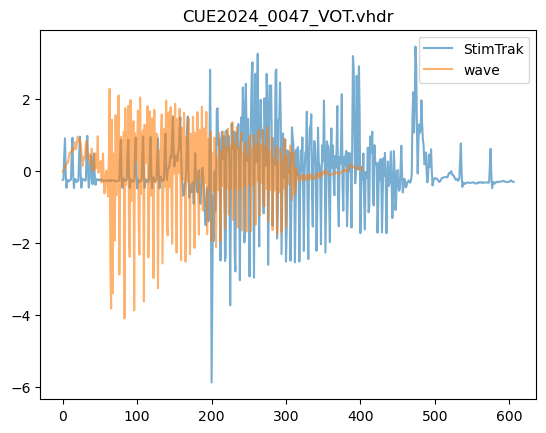

In [10]:
##### parameters #####

# directory
input_dir = work_dir + 'Data/data_english/eeg_raw/eeg_brainvision/'
output_dir = work_dir + 'eeg_preprocessed_NEW/1_trigger_lag_corrected/manual/'

# create a dictionary for blocks and block markers
block_dict = {
    'dorsal_highStan_lowDevi': 1000, # standard: dorsal_high; deviant: dorsal_low
    'dorsal_lowStan_highDevi': 2000, # standard: dorsal_low; deviant: dorsal_high
    'glottal_highStan_lowDevi': 3000, # standard: glottal_high; deviant: glottal_low
    'glottal_lowStan_highDevi': 4000, # standard: glottal_low; deviant: glottal_high
}

# create a condition-level mapping
condition_mapping = {
    1000: 'dorsal_highStan_lowDevi_stan',
    1100: 'dorsal_highStan_lowDevi_devi',
    2000: 'dorsal_lowStan_highDevi_stan',
    2100: 'dorsal_lowStan_highDevi_devi',
    3000: 'glottal_highStan_lowDevi_stan',
    3100: 'glottal_highStan_lowDevi_devi',
    4000: 'glottal_lowStan_highDevi_stan',
    4100: 'glottal_lowStan_highDevi_devi',
}

# trigger searching window (actual trigger time based on audio - trigger time in the data)
t_left = -0.01
t_right = 0.4 # long latency due to using pygame sound library

##### trigger lag fix #####

file = 'CUE2024_0047_VOT.vhdr'

max_corr_thres = 0.3
       
# read in vhdr files
raw = mne.io.read_raw_brainvision(input_dir + file, preload = True)

# If the aux channel is not named 'StimTrak', change the channel name to 'StimTrak'
if raw.info['ch_names'][31] != 'StimTrak':
    # change the channel name
    raw.rename_channels({raw.info['ch_names'][31]: 'StimTrak'})
    # specify the audio channel
    raw.set_channel_types({'StimTrak':'misc'})

# extract the info of experiment version
exp_ver = file.split('.')[0].split('_')[2]

# extract sampling rate
eeg_sfreq = raw.info['sfreq']

#############################################################################################
#### create a dictionary for each stim's standard version and deviant version of markers ####

# intialize a dictionary for triggers
trigger_dict = {}

# read in trigger_codes file, and create a standard trigger code and a deviant triggre code for each stimulus
with open(exp_dir + exp_ver+'_eeg/trigger_codes.txt','r') as tf:
    for line in tf:
        # read in the current line
        line = line.replace('\n','')
        # separate fileNames and triggerMarker
        label, marker = line.split('\t')
        # convert trigger markers to integer
        marker = int(marker)
        # create label for stims used as standards
        trigger_dict[marker] = label + '-s'
        # add 100 for deviant marker
        marker_deviant = marker + 100
        # create label for stims used as deviants
        trigger_dict[marker_deviant] = label + '-d'
#############################################################################################

########################
#### get audio data ####

# initialize dictionaries
audio = {}
lengths = {}

# del trigger_dict[99999]
# for each trigger code and label in the trigger dictionary
for marker,label in trigger_dict.items():
    # extract file name
    file_name = label.split('-')[0]
    # if not already in audio dictionary, get the info of the audio file
    if file_name not in audio:
        # get sample rate and data of the audio file
        sampleRate, data = wavfile.read(exp_dir + exp_ver + '_eeg/stimuli/{}.wav'.format(file_name))
        # calculate sound file length
        lengths[file_name] = len(data)/sampleRate
        # reduce the sampling rate of the audio file by the factor of int(sampleRate/eeg_sfreq)
        data_downsampled = signal.decimate(data, int(sampleRate/eeg_sfreq), ftype='fir')
        # add info the audio dictionary
        audio[file_name] = data_downsampled
########################


##################################################################
#### recode trigger marker to reflect condition and stim info ####

# for each stimulus, mark the block info
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
# remove the non-stim marker
events_from_annot = events_from_annot[events_from_annot[:, 2] < 200]

# initialize the train for each standards+deviant sequence
train = np.array([]).astype(int)

all_block = {}
isStandard = True # whether the standard in a train has been noted

# loop over each trigger
for i in range(events_from_annot.shape[0]):

    # get trigger value
    trigger_value = events_from_annot[i,2]
    
    # add the current token to the train
    train = np.append(train,i)

    # if the trigger value is smaller than 100 and the standard toggle is true
    if (trigger_value<100) & isStandard:
        # split the file name
        trigger_splitted = trigger_dict[trigger_value].split('_')
        # get the standard category name
        block = trigger_splitted[1] + '_' + trigger_splitted[2] + 'Stan'
        # toggle standard
        isStandard = False

    # if the trigger value is over 100
    elif trigger_value>100:
        # split the file name
        trigger_splitted = trigger_dict[trigger_value].split('_')
        # append the deviant stim category 
        block = block + '_' + trigger_splitted[2] + 'Devi'

        # if the block is not present in all block
        if block not in all_block:
            # add the new block and the token idx
            all_block[block] = train[-2:] # [-2:] to include one standard + one eviant sequence
        else:
            # add the token idx to the existing block
            all_block[block] = np.concatenate([ all_block[block],train[-2:] ],axis = None) # # [-2:] to include one standard + one eviant sequence

        # reset train
        train = np.array([]).astype(int)

        # toggle standard note
        isStandard = True

# loop over each block and its trigger index
for k,v in all_block.items():
    # recode the trigger value to reflect block and stim category
    events_from_annot[tuple(v),2] += block_dict[k]

# generate new events
events_from_annot = events_from_annot[events_from_annot[:,2]>1000]
##################################################################


######################################################
#### cross correction to detect the trigger delay ####

# initialize delay list
delays = np.array([])
# initialize bad stim list
bad_stim = []
corr_results = []

# loop over each event
for i in range(events_from_annot.shape[0]):

    # get current event info [time, duration, annotation]
    event = events_from_annot[i]
    # get the onset latency (s) of the event
    time = event[0]/eeg_sfreq
    # get the file name of the event
    name = trigger_dict[event[2]%100].split('-')[0]
    # get the data from the sound channel
    audio_eeg = raw.get_data(
        picks = ['StimTrak'],
        tmin = time + t_left,
        tmax = time + lengths[name] + t_right,
    )[0]
    # actual stimulus
    audio_stim = audio[name]
    # Z-score normalization (subtract mean, divide by std)
    audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
    audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
    
    # cross-correlation
    corr = signal.correlate(audio_eeg, audio_stim, mode='full')
    # Normalize cross-correlation
    corr = corr / (np.linalg.norm(audio_eeg) * np.linalg.norm(audio_stim))
    # Find peak correlation value
    max_corr = np.max(corr)            
    
    # if the maximum correction (sum of products) is less than a threshold (empirical threshold, 0.5 is generally good)
    if max_corr < max_corr_thres:
        # mark the stim bad
        bad_stim.append(i)

    # append the maximum correlation
    corr_results.append(max_corr)

    
    # the lags for cross-correlation
    lags = signal.correlation_lags(
        audio_eeg.size,
        audio_stim.size,
        mode="full")
    # get the lag of the maximum cross-correlation
    lag = lags[np.argmax(corr)] + t_left*eeg_sfreq
    
    # save the lag for non-starting events
    delays = np.append(delays,lag)

# log the number of bad stims
with open(output_dir + 'bad_stims.txt', 'a+') as f:
    f.write(file + '\t' + str(len(bad_stim)) + '\n')
######################################################


##################################################################################################
#### plot the wave from the stim track and the eeg channel of the token with the minimum corr ####
min_corr = np.argmin(corr_results)
# get current event info [time, duration, annotation]
event = events_from_annot[min_corr]
# get the onset latency (s) of the event
time = event[0]/eeg_sfreq
# get the file name of the event
name = trigger_dict[event[2]%100].split('-')[0]
# get the data from the sound channel
audio_eeg = raw.get_data(
    picks = ['StimTrak'],
    tmin = time + t_left,
    tmax = time + lengths[name] + t_right,
)[0]
# actual stimulus
audio_stim = audio[name]
# Z-score normalization (subtract mean, divide by std)
audio_eeg = (audio_eeg - np.mean(audio_eeg)) / np.std(audio_eeg)
audio_stim = (audio_stim - np.mean(audio_stim)) / np.std(audio_stim)
# plot
fig, ax = plt.subplots()
ax.plot(audio_eeg, label = 'StimTrak', alpha = 0.6)
ax.plot(audio_stim, label = 'wave', alpha = 0.6)
ax.set_title(file)
ax.legend()
fig.savefig(output_dir + file.split('.')[0] + "_minCor.png", dpi=300, bbox_inches='tight')
##################################################################################################


################################################
#### correct for trigger lag and save files ####

# remove items associated with bad stims from the event list
events_from_annot = np.delete(events_from_annot, bad_stim, 0)

# remove items associated with bad stims from the delay list
delays = np.delete(delays, bad_stim, 0)

########## recode trigger marker ##########
# add delay back to the onset latency of each event
events_from_annot[:,0] = events_from_annot[:,0] + delays

# # create item-level annotations
# annot_from_events = mne.annotations_from_events(
#     events = events_from_annot,
#     event_desc = eval(exp_ver + '_mapping'),
#     sfreq = eeg_sfreq
# )

# convert individual event marker to conditions
events_from_annot[:,2] = events_from_annot[:,2] - events_from_annot[:,2]%100
# create condition-level annotations
annot_from_events = mne.annotations_from_events(
    events = events_from_annot,
    event_desc = condition_mapping,
    sfreq = eeg_sfreq
)

# set annotations
raw.set_annotations(annot_from_events)

# drop the audio channel in data
raw.drop_channels(['StimTrak'])

# save as a file-into-file data
raw.save(output_dir + file.split('.')[0]+ '_corr.fif')

# save lag data
np.savetxt(output_dir + file.replace('.vhdr', '_delays.txt'), delays, fmt='%i')
################################################

# Filter, resample, and remove line noise
- filtering
- resampling
- remove line noise

In [11]:
#### parameters ####

# set directory
input_dir = work_dir + 'eeg_preprocessed_NEW/1_trigger_lag_corrected/'
output_dir = work_dir + 'eeg_preprocessed_NEW/2_filtered/'

# filter cutoff frequencies (low/high)
f_low = 0.5

# resampling frequency
f_res = 250

# line frequency
line_freq = 60

#####################################################
#### filtering, resampling, bad channel detection/interpoloation ####
#####################################################

# get all file namesin the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


for file in all_input:
    if file.endswith("corr.fif") and (file.split('.')[0]+ '_prep.fif' not in all_output):

        # select participants
        if file.split('_')[2] + '_' + file.split('_')[1] not in include_ppts:
            continue
            
        # read in file
        raw = mne.io.read_raw_fif(input_dir + file, preload=True)

        #### cut off the beginning and ending part ####
        # # get the onset of the first and the last event ####
        # events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        # # define the beginning time (in seconds)
        # crop_start = events_from_annot[0][0]/raw.info['sfreq'] - 10
        # # define the ending time (in seconds)
        # crop_end = events_from_annot[-1][0]/raw.info['sfreq'] + 10
        # # crop the data
        # raw.crop(
        #     tmin=max(crop_start, raw.times[0]), 
        #     tmax=min(crop_end, raw.times[-1])
        # )

        # filter
        raw.filter(l_freq = f_low, h_freq = None)

        # notch filter to remove line noise
        freqs = np.arange(line_freq, f_res/2, line_freq)
        raw = raw.notch_filter(freqs=freqs)

        # resample
        raw.resample(sfreq = f_res)

        # save
        raw.save(output_dir + file.split('.')[0]+ '_filt.fif')

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/CUE2024_0069_VOT_corr.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_98342/3140454744.py:33: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/CUE2024_0069_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


Isotrak not found
    Range : 0 ... 2106039 =      0.000 ...  4212.078 secs
Ready.
Reading 0 ... 2106039  =      0.000 ...  4212.078 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 3301 samples (6.602 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 3301 samples (6

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_98342/3140454744.py:59: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/2_filtered/CUE2024_0069_VOT_corr_filt.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_filt.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/2_filtered/CUE2024_0069_VOT_corr_filt.fif
[done]
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/CUE2024_0019_VOT_corr.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_98342/3140454744.py:33: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/CUE2024_0019_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


... (87 outputs left out)

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_98342/3140454744.py:33: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/1_trigger_lag_corrected/CUE2024_0039_VOT_corr.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


Isotrak not found
    Range : 0 ... 2065279 =      0.000 ...  4130.558 secs
Ready.
Reading 0 ... 2065279  =      0.000 ...  4130.558 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 3301 samples (6.602 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 3301 samples (6

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_98342/3140454744.py:59: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/2_filtered/CUE2024_0039_VOT_corr_filt.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_filt.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/2_filtered/CUE2024_0039_VOT_corr_filt.fif
[done]


# Manual bad channel detection quality check

In [ ]:
# directory
input_dir = work_dir + 'eeg_preprocessed_2025-11-13/2_bad_channel_corrected/'

# file name
file = 'CUE2024_0060_VOT_corr_prep.fif'

# read in file
raw = mne.io.read_raw_fif(input_dir + file, preload = True)


# set Fp1 and Fp2 back to eeg
# raw.set_channel_types({'Fp1':'eeg', 'Fp2':'eeg'})

# add the channel loc info (for the newly added reference channel)
raw.set_montage(montage)

# check information
print(raw.info)

# event distributions
events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')

# segmentation for ERP
epochs = mne.Epochs(
    raw,
    events = events_from_annot, event_id = event_dict,
    tmin = -0.2, tmax = 1,
    # apply baseline correction
    # baseline = None,
    # remove epochs that meet the rejection criteria
    reject = None,
    preload = True,
)

# plot epochs
epochs.plot_image(combine="mean")

# butterfly
epochs.average().plot()
plt.show()


# if needed, plot a spectrum for fewer channels together
raw.compute_psd(picks = ['Fp1', 'Fp2', 'F3','F7','Fz','F4','F8']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['FT9', 'FT10', 'FC5','FC1','FC2','FC6']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['T7', 'T8', 'C3','Cz','C4']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['CP5', 'CP1', 'CP2','CP6','TP10']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['P7', 'P3', 'Pz','P4','P8']).plot(show=False, amplitude=False)

raw.compute_psd(picks = ['O1', 'Oz', 'O2']).plot(show=False, amplitude=False)

plt.show()

# Bad channel detection
* set EOG channel
* detect bad channels
* add back reference channel
* average re-reference for ICA

In [2]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_NEW/2_filtered/'
output_dir = work_dir + 'eeg_preprocessed_NEW/3_bad_channel_detected/'


# get all file names in the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)

# initialize a log file
if ('bads_log.txt' not in all_output):
    with open(output_dir + '/bads_log.txt', 'a+') as f:
        f.write('file' + '\t' + 'bad_channels' + '\n')

# run artifact correction
for file in all_input:
    if file.endswith("filt.fif") and (file.split('.')[0]+ '_bads.fif' not in all_output):

        # read in file
        raw = mne.io.read_raw_fif(input_dir + file, preload=True)

        # set EOG channels
        raw.set_channel_types({'Fp1':'eog', 'Fp2':'eog'})

        # read in channel location info
        raw.set_montage(montage)

        
        ########## detect bad channels ##########
        ####  bad channel detection using lof ####
        bad_chans = mne.preprocessing.find_bad_channels_lof(raw)
        # mark bad channels
        raw.info['bads'] = bad_chans
        # log bad channels and bad ics
        with open(output_dir + '/bads_log.txt', 'a+') as f:
            f.write(file + '\t' + str(bad_chans) + '\n')
            
        # add back the reference channel
        raw = mne.add_reference_channels(raw,'TP9')
        # add the channel loc info (for the newly added reference channel)
        raw.set_montage(montage)

        # save
        raw.save(output_dir + file.split('.')[0]+ '_bads.fif')

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/2_filtered/CUE2024_0062_VOT_corr_filt.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:22: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/2_filtered/CUE2024_0062_VOT_corr_filt.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


Isotrak not found
    Range : 0 ... 1048569 =      0.000 ...  4194.276 secs
Ready.
Reading 0 ... 1048569  =      0.000 ...  4194.276 secs...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:28: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp1', 'Fp2']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)


LOF: Detected bad channel(s): ['F7']
EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0062_VOT_corr_filt_bads.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:41: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  raw = mne.add_reference_channels(raw,'TP9')
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:43: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp1', 'Fp2']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:48: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0062_V

... (137 outputs left out)

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:28: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp1', 'Fp2']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:41: RuntimeWarning: Location for this channel is unknown or ambiguous; consider calling set_montage() after adding new reference channels if needed. Applying a montage will only set locations of channels that exist at the time it is applied.
  raw = mne.add_reference_channels(raw,'TP9')


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0039_VOT_corr_filt_bads.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:43: RuntimeWarning: Not setting positions of 2 eog channels found in montage:
['Fp1', 'Fp2']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(montage)
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27385/811594620.py:48: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0039_VOT_corr_filt_bads.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_bads.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0039_VOT_corr_filt_bads.fif
[done]


# ICA

In [5]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_NEW/3_bad_channel_detected/'
output_dir = work_dir + 'eeg_preprocessed_NEW/4_ica/'

# run ica on epoched data or continuous data
ica_input_type = 'continuous'
# ica_input_type = 'epochs'

# Epoch window: 
erp_t_start = -0.2; erp_t_end = 1

#### ICA ####

# get all file names in the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)

# Any segment louder than this will be ignored by ICA.
reject_criteria = dict(eeg=500e-6)

# initialize a log file
if ('ica_log.txt' not in all_output):
    with open(output_dir + '/ica_log.txt', 'a+') as f:
        f.write('file' + '\t' + 'excluded_components' + '\n')

# run artifact correction
for file in all_input:
    if file.endswith("bads.fif") and (file.split('.')[0]+ '_ica.fif' not in all_output):

        # read in file
        raw = mne.io.read_raw_fif(input_dir + file, preload=True)

        # apply a common average referencing (only applies to eeg channels), to comply with the ICLabel requirements
        raw.set_eeg_reference("average")
    
        # make a filtered file copy ICA. It works better on signals with 1 Hz high-pass filtered and 100 Hz low-pass filtered
        filt_raw = raw.copy().filter(l_freq = 1, h_freq = 100)
        
        # initialize ica parameters
        ica = mne.preprocessing.ICA(
            # n_components=0.999999,
            max_iter='auto', # n-1
            # use ‘extended infomax’ method for fitting the ICA, to comply with the ICLabel requirements
            method = 'infomax', 
            fit_params = dict(extended=True),
            random_state = 42,
        )

        # run ica on epochs or continuous
        if ica_input_type=="continuous":
            ica_input = filt_raw
        elif ica_input_type=="epochs":
            # get event info for segmentation
            events_from_annot, event_dict = mne.events_from_annotations(filt_raw, verbose='WARNING')
            # segmentation for ERP
            epochs = mne.Epochs(
                filt_raw,
                events = events_from_annot, event_id = event_dict,
                tmin = erp_t_start, tmax = erp_t_end,
                # apply baseline correction
                baseline = None,
                # remove epochs that meet the rejection criteria
                reject = None,
                preload = True,
            )
            # set ica_input
            ica_input = epochs
    
        #### get ica solution ####
        ica.fit(ica_input, reject=reject_criteria)
        # save ica solutions
        ica.save(output_dir + file.split('.')[0]+ '_fit.fif')

        #### ICLabel ####
        ic_labels = label_components(ica_input, ica, method="iclabel")
        labels = ic_labels["labels"]
        probs = ic_labels['y_pred_proba']

        # remove components
        exclude_idx = [ ind for ind, label in enumerate(labels) if label not in ["brain", "other"] and probs[ind]>0.9 ]
        
        # log bad channels and bad ics
        with open(output_dir + '/ica_log.txt', 'a+') as f:
            f.write(file + '\t' + str(exclude_idx) + '\n')

        # ica.apply() changes the Raw object in-place
        ica.apply(raw, exclude=exclude_idx) # apply continuous data

        #### spline interpolating remaining bad channels if any ####
        raw.interpolate_bads()

        # save data after ICA
        raw.save(output_dir + file.split('.')[0]+ '_ica.fif')

        # release memory
        del raw, filt_raw, ica_input

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0062_VOT_corr_filt_bads.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3186050460.py:30: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0062_VOT_corr_filt_bads.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


    Range : 0 ... 1048569 =      0.000 ...  4194.276 secs
Ready.
Reading 0 ... 1048569  =      0.000 ...  4194.276 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 825 samples (3.300 s)

Fitting ICA to data using 29 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 28 components
Computing Extended Infomax ICA
Fitting ICA took 266.7s.
Writing ICA solution to /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocess

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3186050460.py:68: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0062_VOT_corr_filt_bads_fit.fif) does not conform to MNE naming conventions. All ICA files should end with -ica.fif, -ica.fif.gz, _ica.fif or _ica.fif.gz
  ica.save(output_dir + file.split('.')[0]+ '_fit.fif')


Applying ICA to Raw instance
    Transforming to ICA space (28 components)
    Zeroing out 2 ICA components
    Projecting back using 29 PCA components
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 94.5 mm
Computing interpolation matrix from 29 sensor positions
Interpolating 1 sensors
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0062_VOT_corr_filt_bads_ica.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3186050460.py:89: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0062_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_ica.fif')


... (135 outputs left out)

/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3186050460.py:68: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0041_VOT_corr_filt_bads_fit.fif) does not conform to MNE naming conventions. All ICA files should end with -ica.fif, -ica.fif.gz, _ica.fif or _ica.fif.gz
  ica.save(output_dir + file.split('.')[0]+ '_fit.fif')


Applying ICA to Raw instance
    Transforming to ICA space (29 components)
    Zeroing out 13 ICA components
    Projecting back using 30 PCA components
Setting channel interpolation method to {'eeg': 'spline'}.
Writing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0041_VOT_corr_filt_bads_ica.fif


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3186050460.py:86: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  raw.interpolate_bads()
/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3186050460.py:89: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0041_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw.save(output_dir + file.split('.')[0]+ '_ica.fif')


Closing /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0041_VOT_corr_filt_bads_ica.fif
[done]


## manual check ICA and interpolate bad channels

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0006_VOT_corr_filt_bads.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/4159952070.py:18: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/3_bad_channel_detected/CUE2024_0006_VOT_corr_filt_bads.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload=True)


    Range : 0 ... 1043284 =      0.000 ...  4173.136 secs
Ready.
Reading 0 ... 1043284  =      0.000 ...  4173.136 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 825 samples (3.300 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Fitting ICA to data using 29 channels (please be patient, this may take a while)
    Rejecting  epoch based on EEG : ['F7']
Artifact detected in [273000, 273500]
    Rejecting  epoch based on EEG : ['

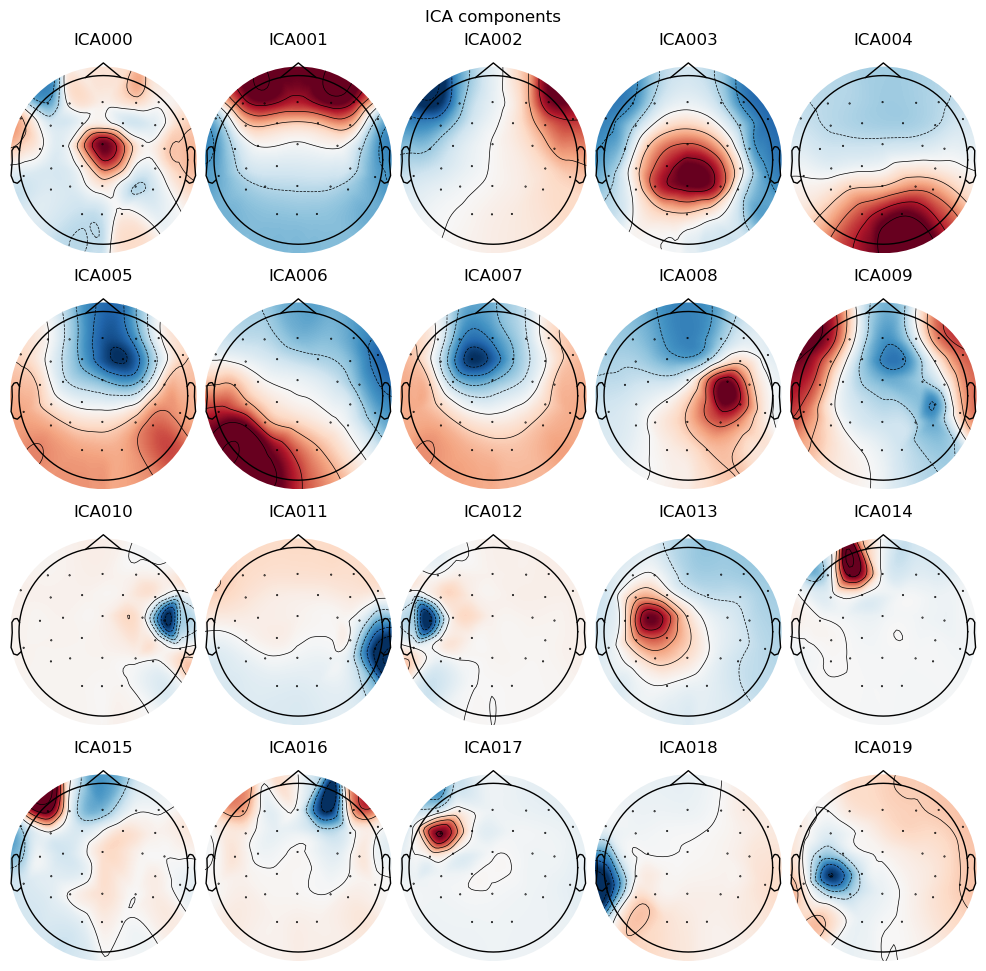

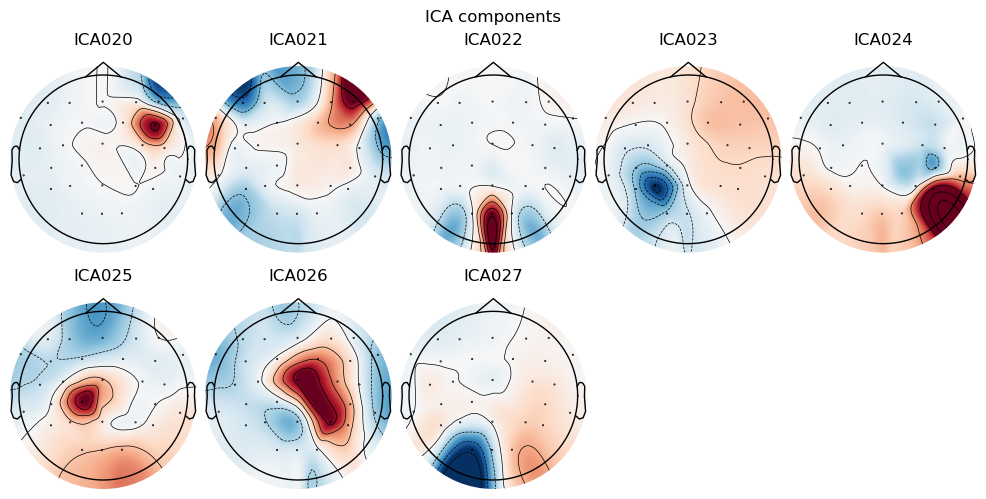

Creating RawArray with float64 data, n_channels=30, n_times=1043285
    Range : 0 ... 1043284 =      0.000 ...  4173.136 secs
Ready.


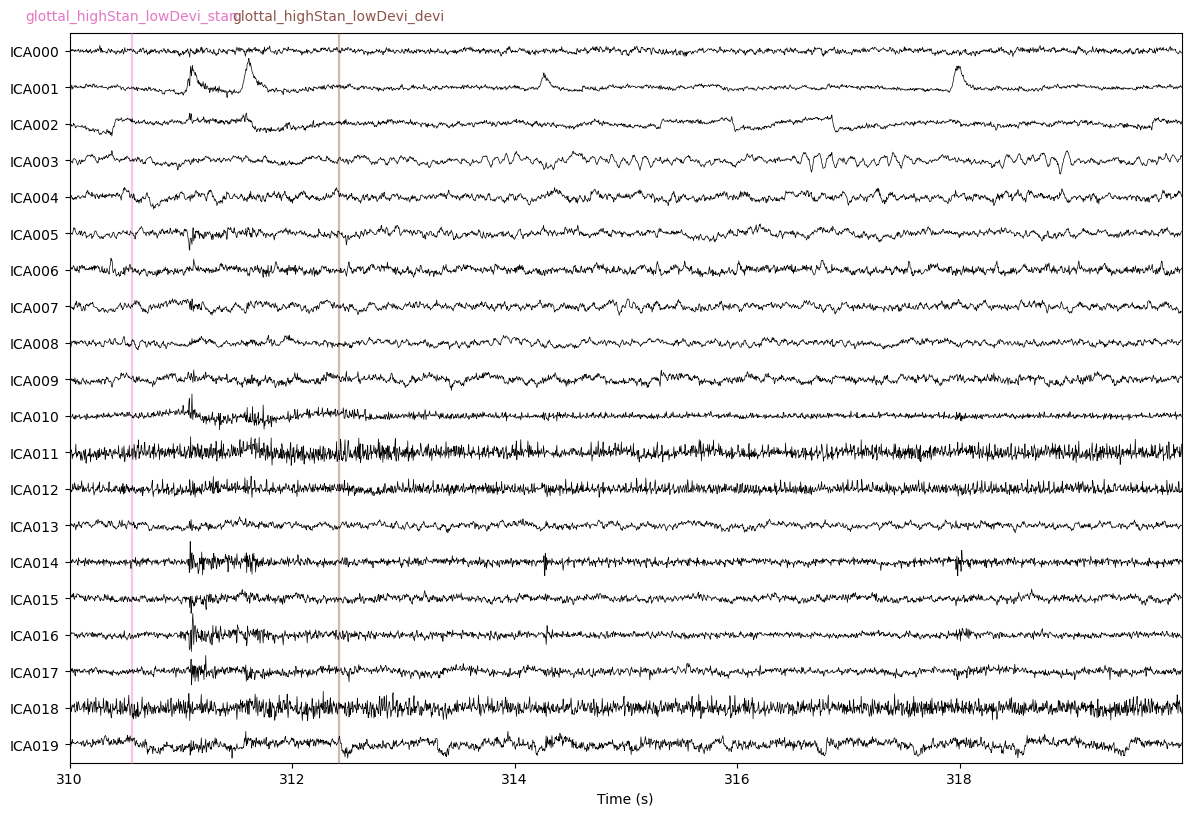

In [16]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_NEW/3_bad_channel_detected/'
ica_dir = work_dir + 'eeg_preprocessed_NEW/4_ica/'

# get all file names in the folder
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)

# Any segment louder than this will be ignored by ICA.
reject_criteria = dict(eeg=500e-6)


file = 'CUE2024_0006_VOT_corr_filt_bads.fif'

# read in file
raw = mne.io.read_raw_fif(input_dir + file, preload=True)

# make a filtered file copy ICA. It works better on signals with 1 Hz high-pass filtered and 100 Hz low-pass filtered
filt_raw = raw.copy().filter(l_freq = 1, h_freq = 100)

filt_raw.set_eeg_reference('average', projection=False)

ica_input = filt_raw

# initialize ica parameters
ica = mne.preprocessing.ICA(
    # n_components=0.999999,
    max_iter='auto', # n-1
    # use ‘extended infomax’ method for fitting the ICA, to comply with the ICLabel requirements
    method = 'infomax', 
    fit_params = dict(extended=True),
    random_state = 42,
)

# This ignores the "3000 AU" spike from the training data
ica.fit(ica_input, reject=reject_criteria)

# read in ica solution
# ica = mne.preprocessing.read_ica(ica_dir + file.split('.')[0] + '_fit.fif')

# ICLabel
ic_labels = label_components(ica_input, ica, method="iclabel")
labels = ic_labels["labels"]
probs = ic_labels['y_pred_proba']

# remove components
exclude_idx = [ ind for ind, label in enumerate(labels) if label not in ["brain", "other"] and probs[ind]>0.9 ]


# print the file name
print(file)
print()

# get the label and probability of ICs
for idx in range(15):
    print( 'ICA' + f"{idx:03}" + ': ' + labels[idx] + ' - ' + str(round(probs[idx], ndigits=4)) )
print()

print(exclude_idx)

# plot topos
ica.plot_components()
plt.show()


# Continuous waveforms for components.
ica.plot_sources(ica_input,
                 start = 310, stop = 320,
                 show_scrollbars=False)
plt.show()

ica.plot_properties(raw, picks=0)

# Epochs, autoreject, and evokeds
segmenting continuous EEG into epochs, then autoreject, then evoked
- re-reference
- segmentation

Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0063_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0063_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1152499 =      0.000 ...  4609.996 secs
Ready.
Reading 0 ... 1152499  =      0.000 ...  4609.996 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 16, 53, 68


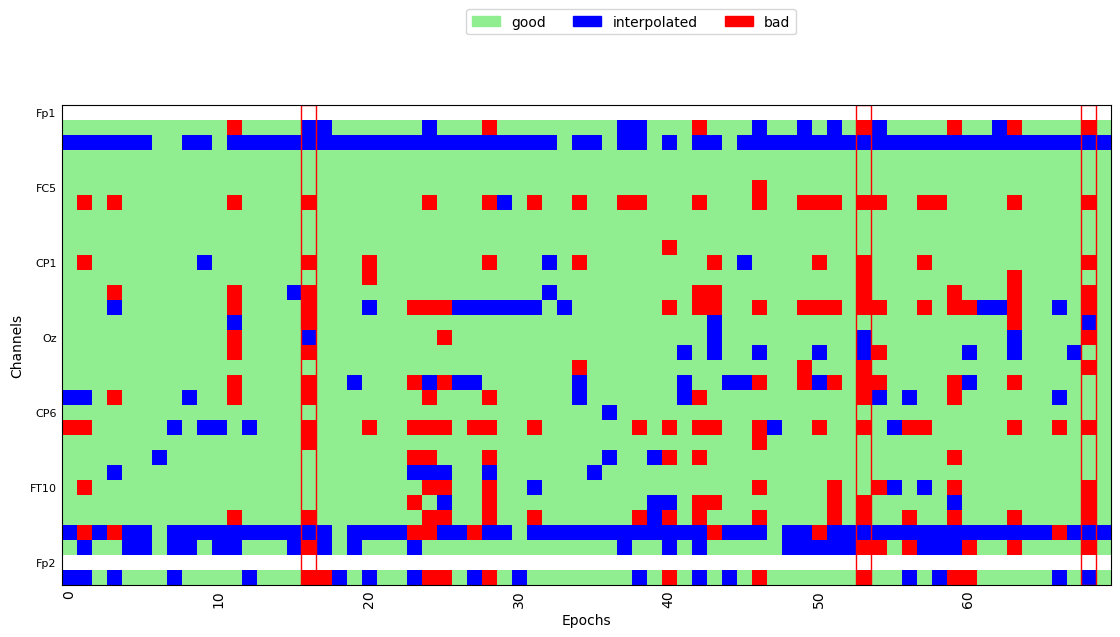

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


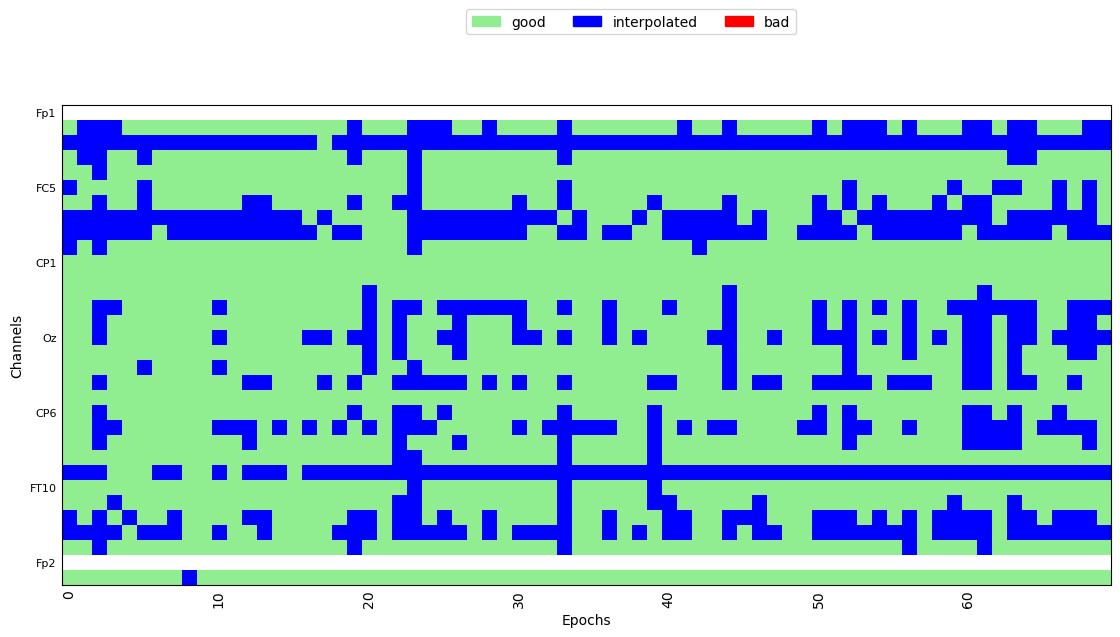

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 65, 67


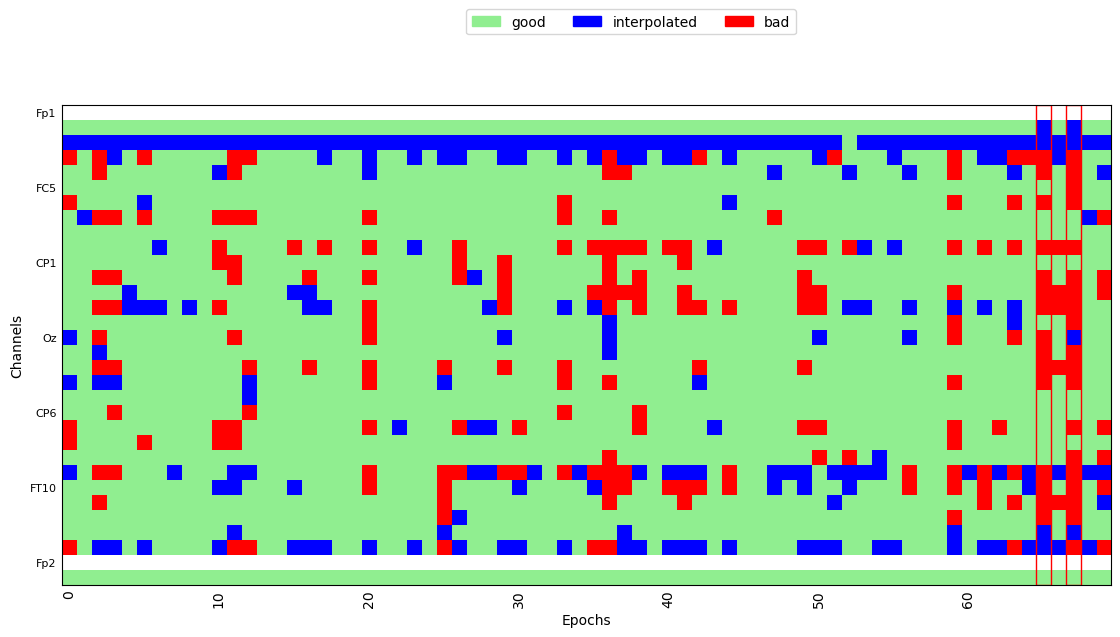

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


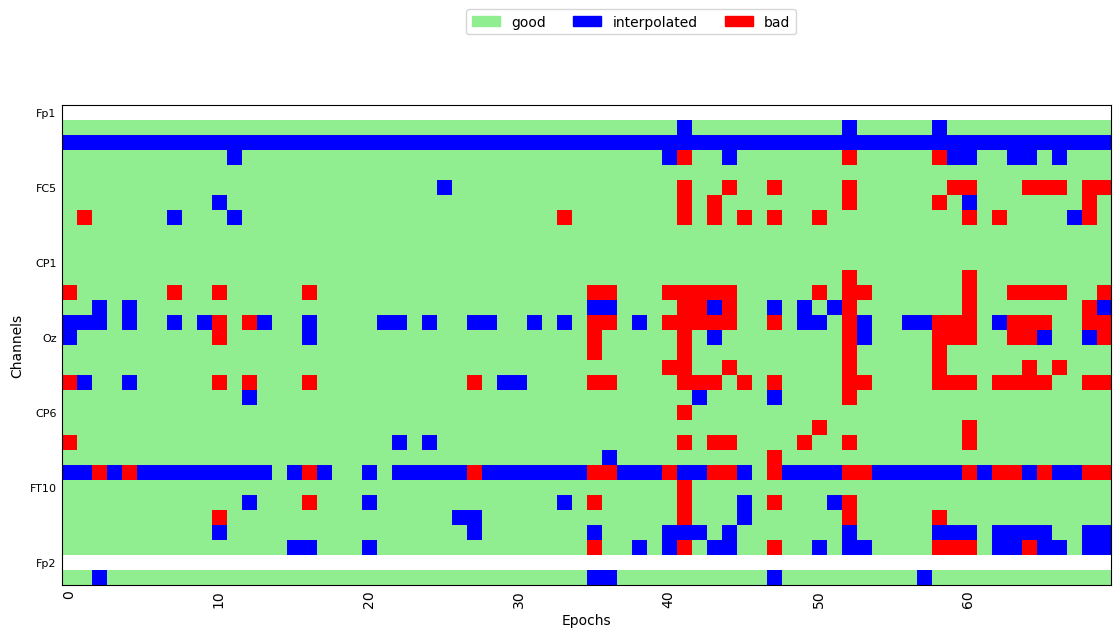

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 4


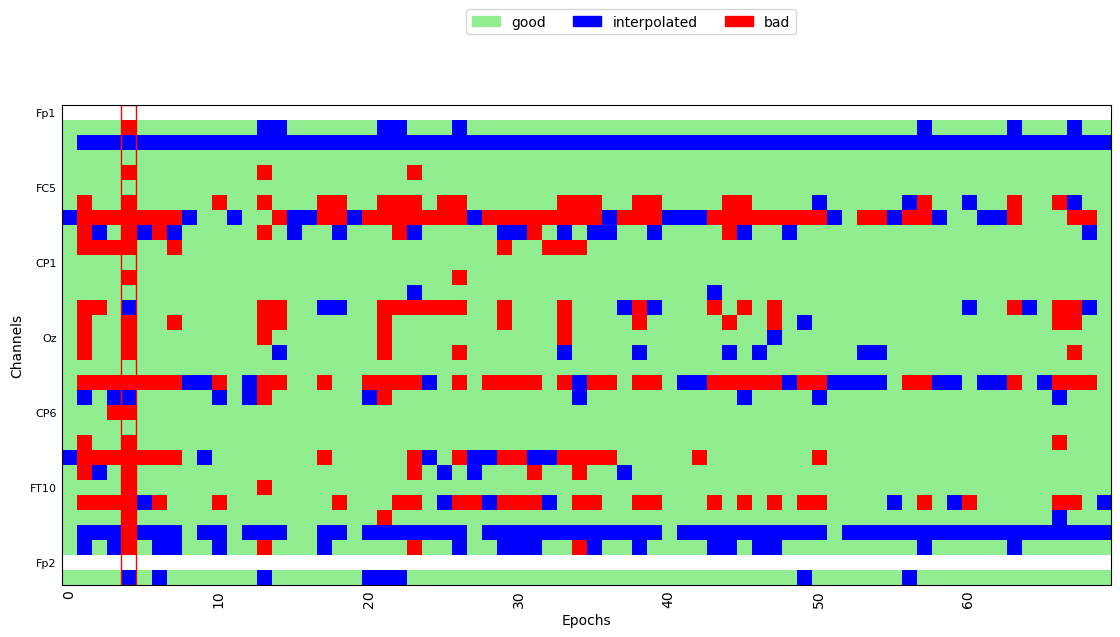

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 3, 4, 5, 13, 27, 29, 30, 55, 66, 69


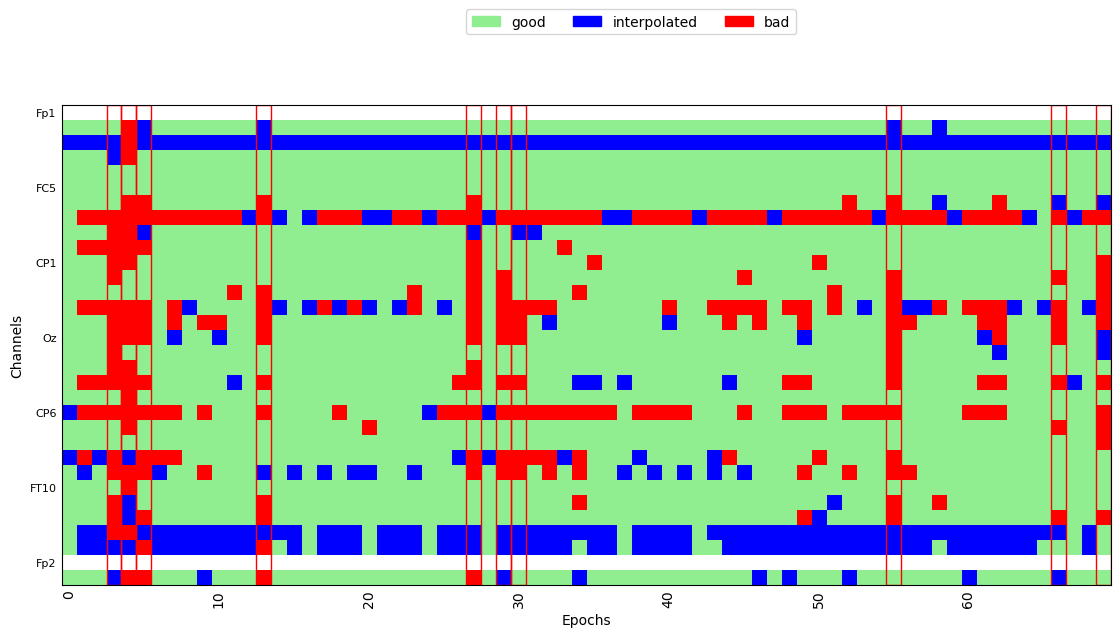

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 0, 1, 2, 4, 25, 28, 32, 33, 44, 53, 55, 58, 59, 62, 65


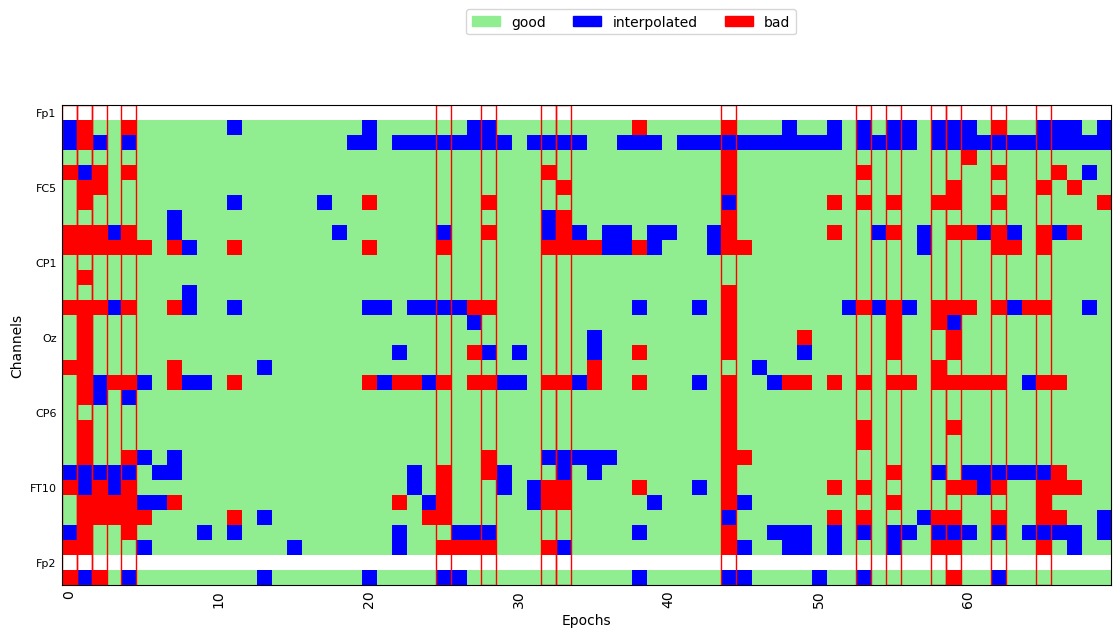

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 0, 1, 44, 45, 61, 62


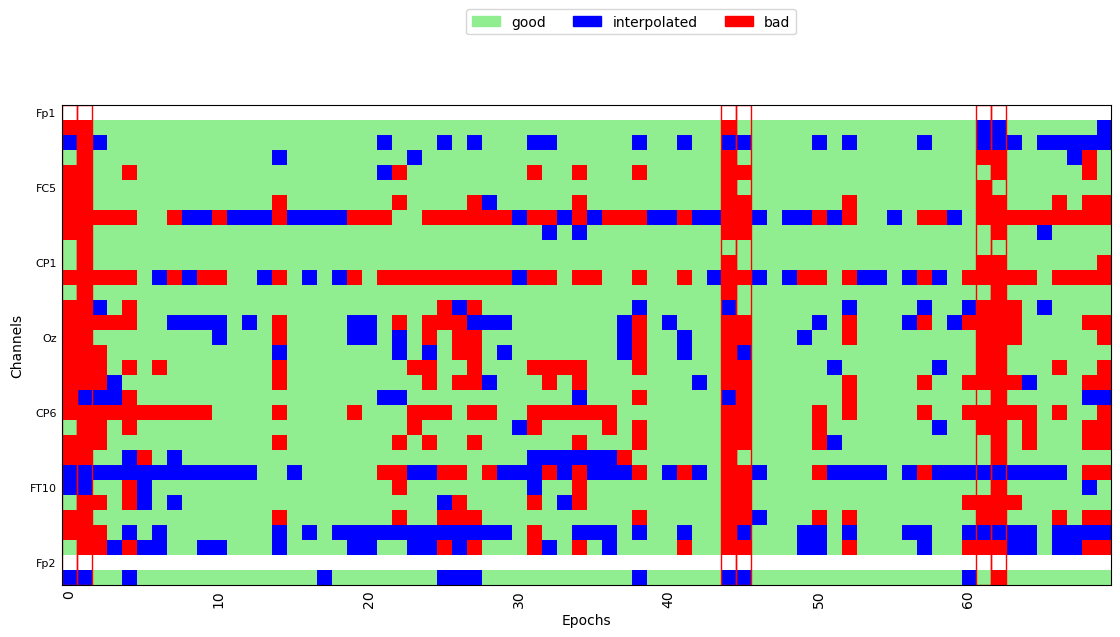

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0006_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0006_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1043284 =      0.000 ...  4173.136 secs
Ready.
Reading 0 ... 1043284  =      0.000 ...  4173.136 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/71 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/71 [00:00<?,       ?it/s]

Dropped 2 epochs: 12, 58


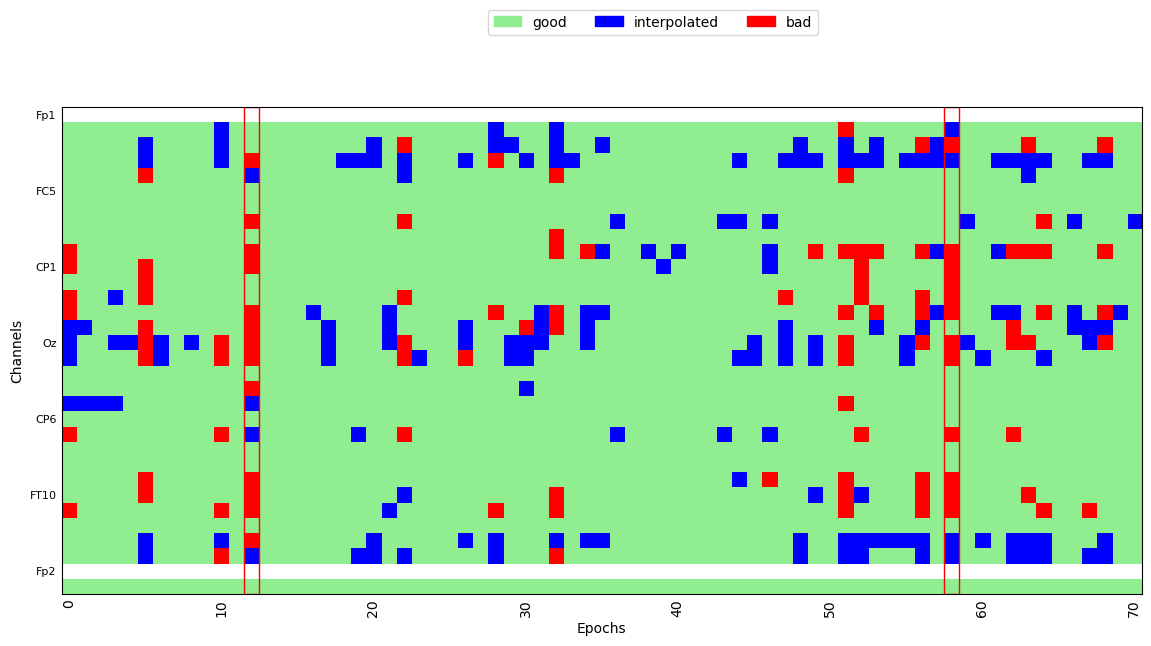

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/71 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/71 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/71 [00:00<?,       ?it/s]

Dropped 5 epochs: 0, 5, 11, 19, 32


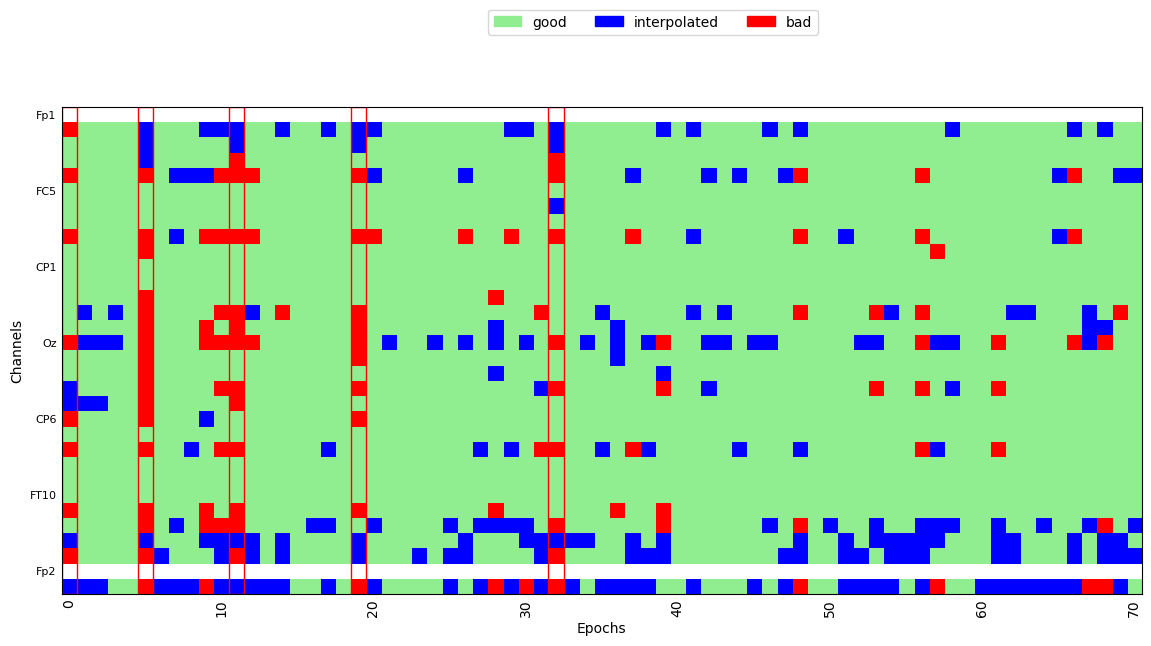

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 21, 25, 26, 27, 30, 31, 32, 41, 42, 61, 63


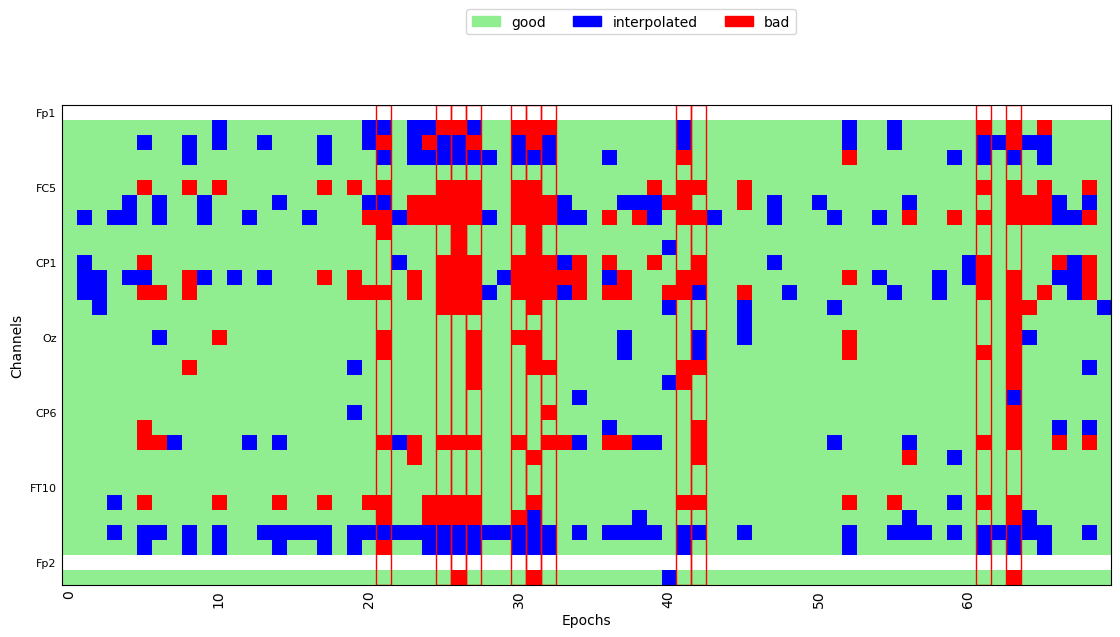

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


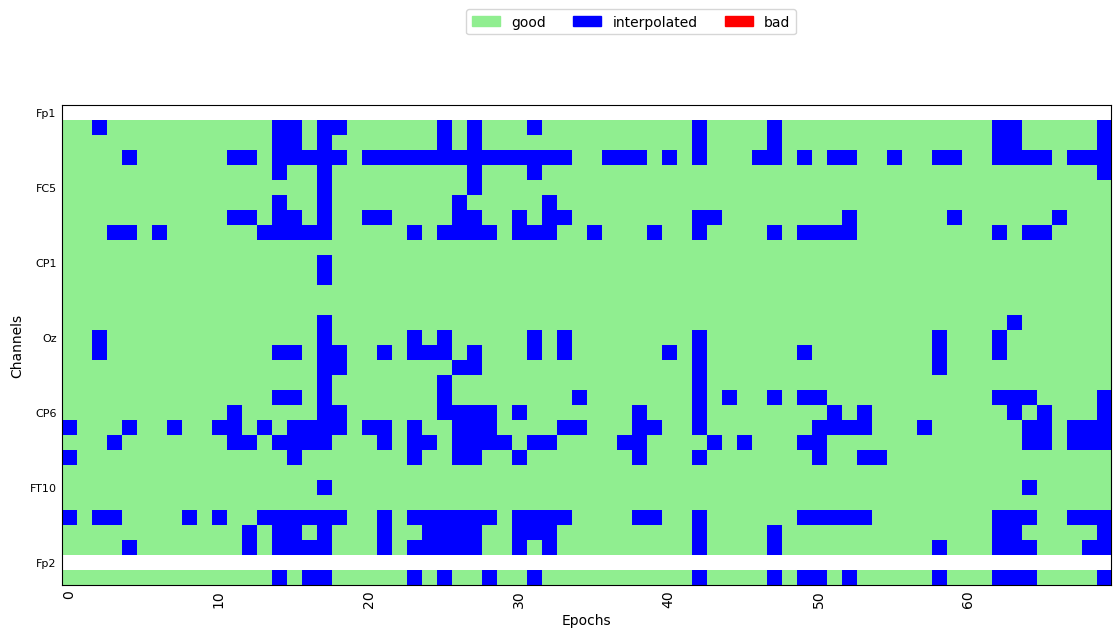

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 4 epochs: 0, 9, 18, 49


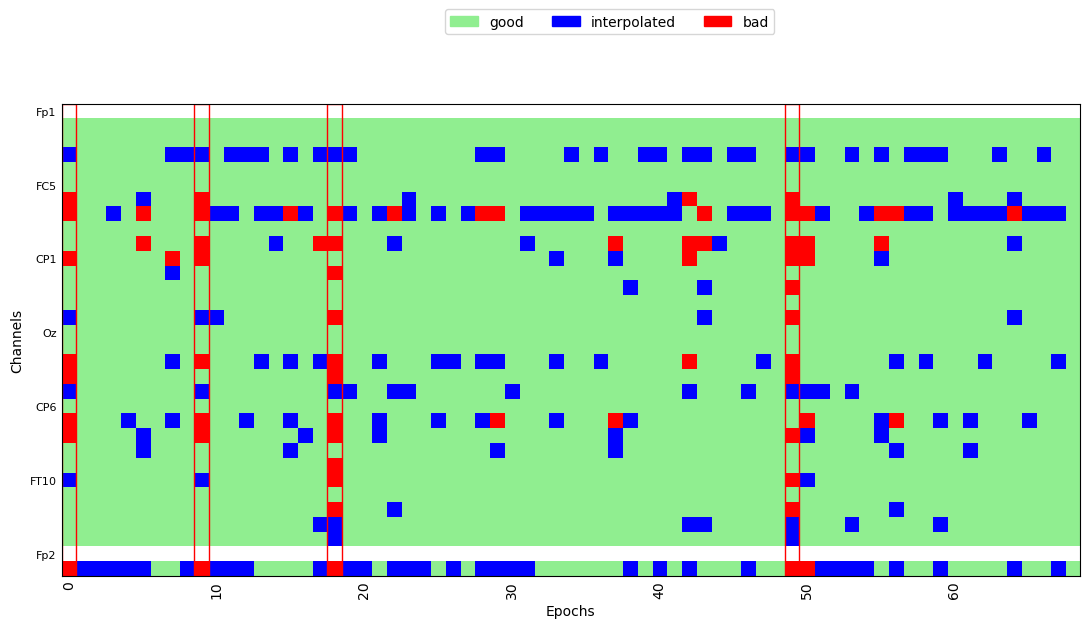

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/69 [00:00<?,       ?it/s]

Dropped 2 epochs: 39, 49


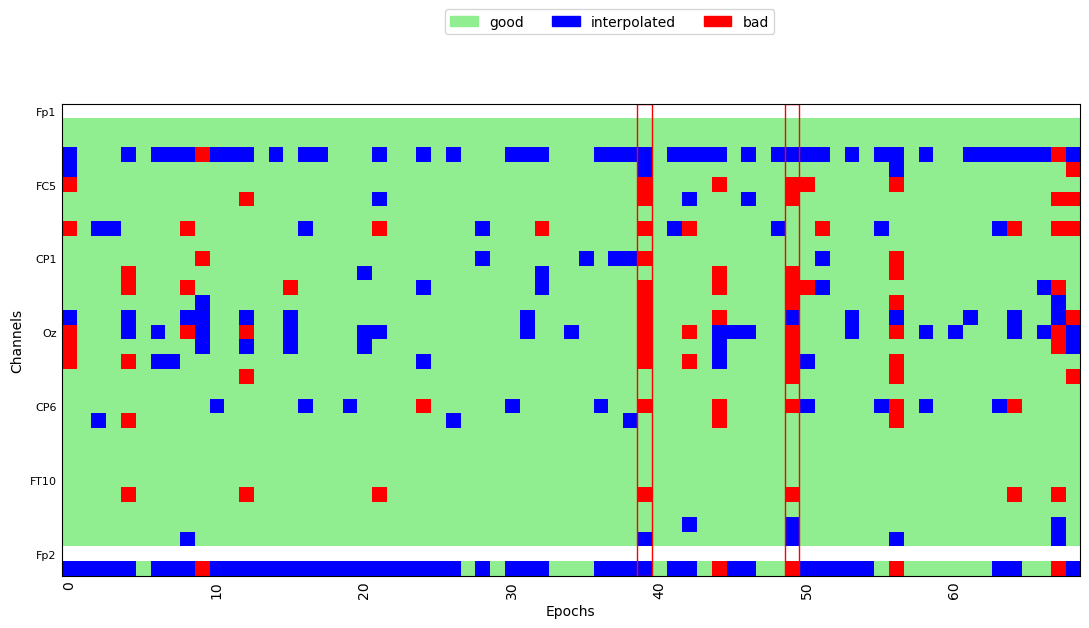

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 4, 7, 47


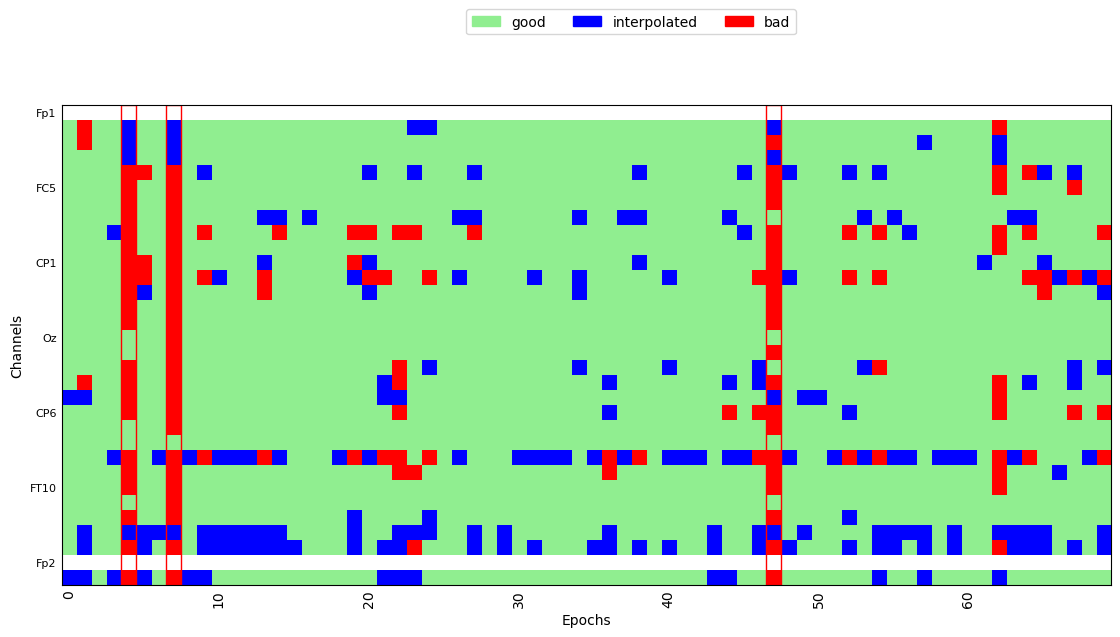

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


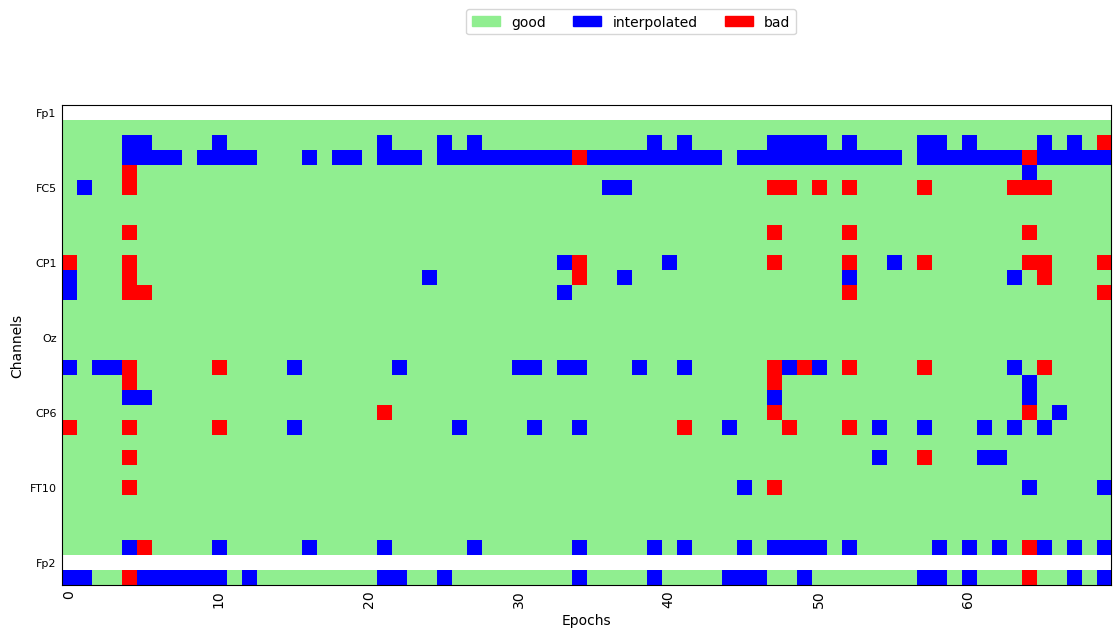

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0033_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0033_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1052734 =      0.000 ...  4210.936 secs
Ready.
Reading 0 ... 1052734  =      0.000 ...  4210.936 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 13 epochs: 0, 1, 20, 29, 35, 39, 42, 48, 55, 60, 62, 63, 69


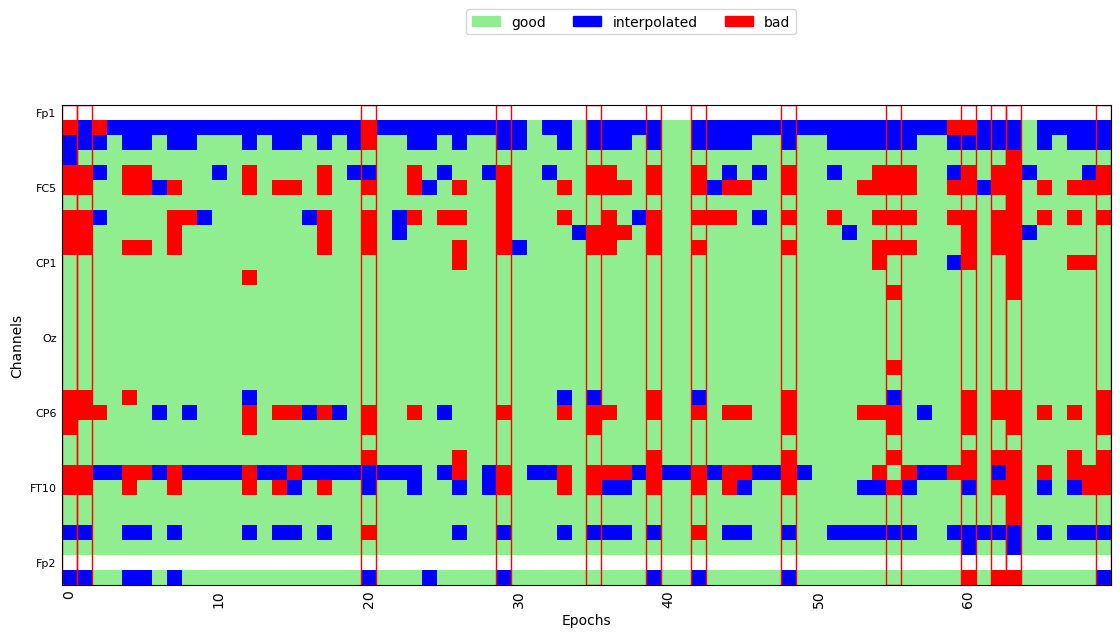

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 34 epochs: 0, 1, 2, 3, 9, 10, 11, 13, 15, 16, 19, 22, 32, 34, 35, 38, 42, 43, 48, 49, 50, 51, 53, 54, 55, 56, 57, 60, 61, 62, 63, 66, 67, 69


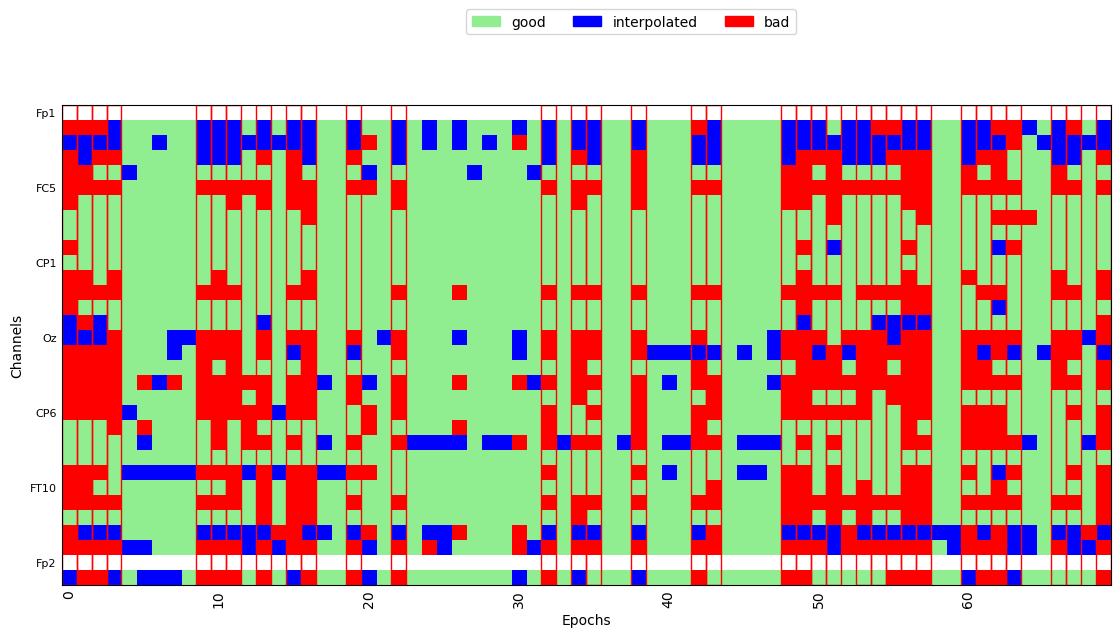

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 27 epochs: 0, 3, 5, 6, 8, 9, 10, 12, 14, 15, 17, 19, 24, 25, 29, 36, 46, 49, 53, 57, 58, 61, 62, 63, 64, 66, 67


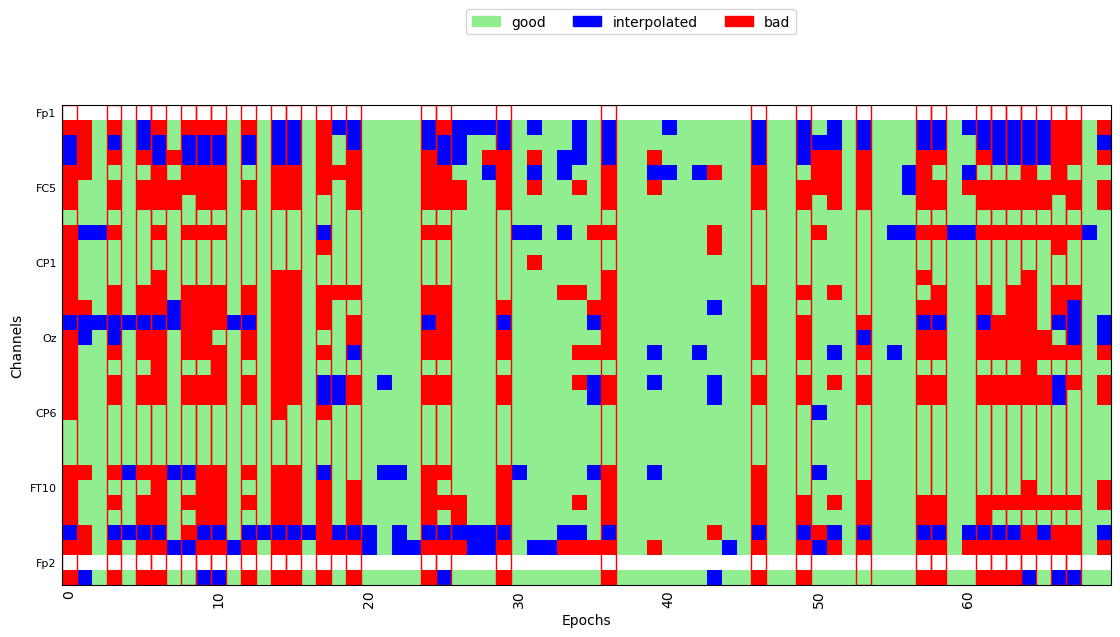

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 7, 14, 17, 35, 63, 66


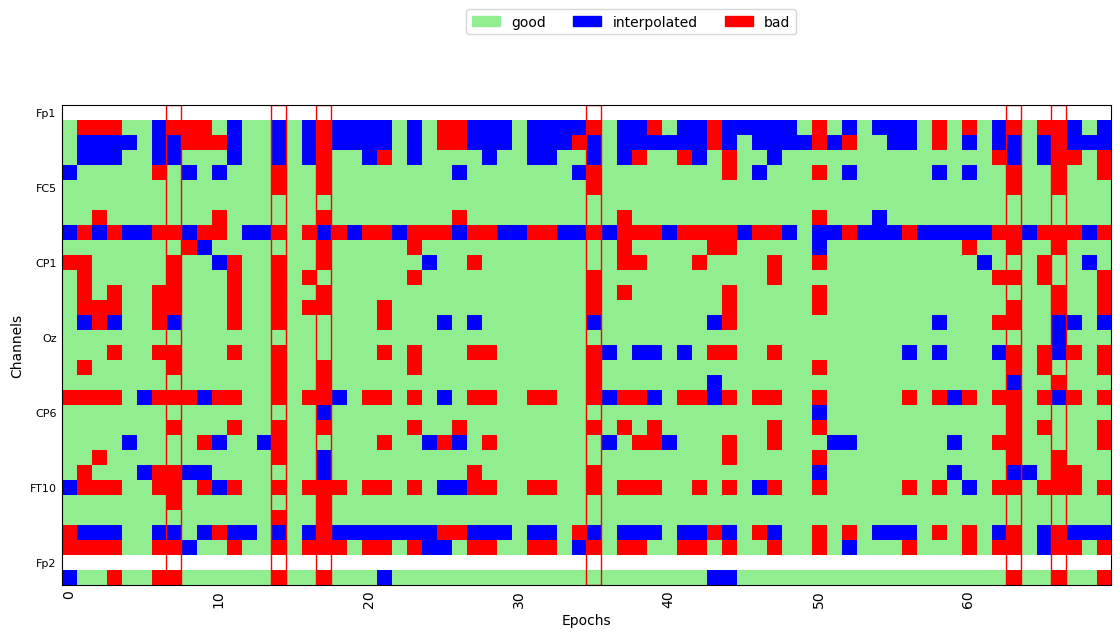

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 21 epochs: 3, 6, 11, 12, 13, 19, 21, 27, 36, 38, 39, 40, 43, 47, 50, 51, 53, 54, 60, 64, 66


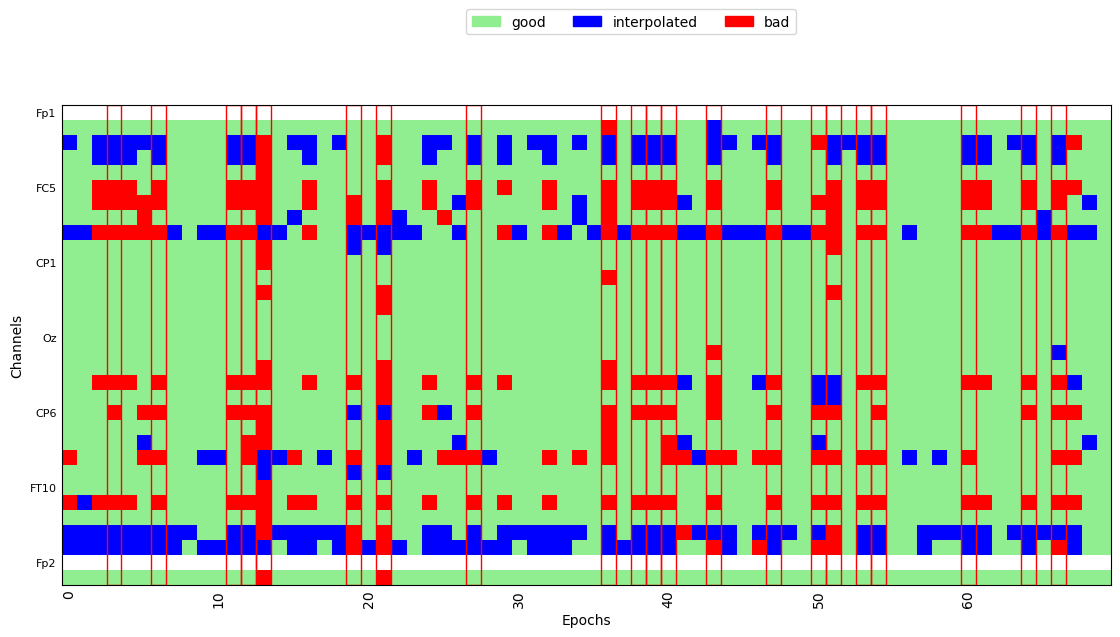

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 0, 12, 13, 21, 34, 36, 45, 48, 51, 55, 67


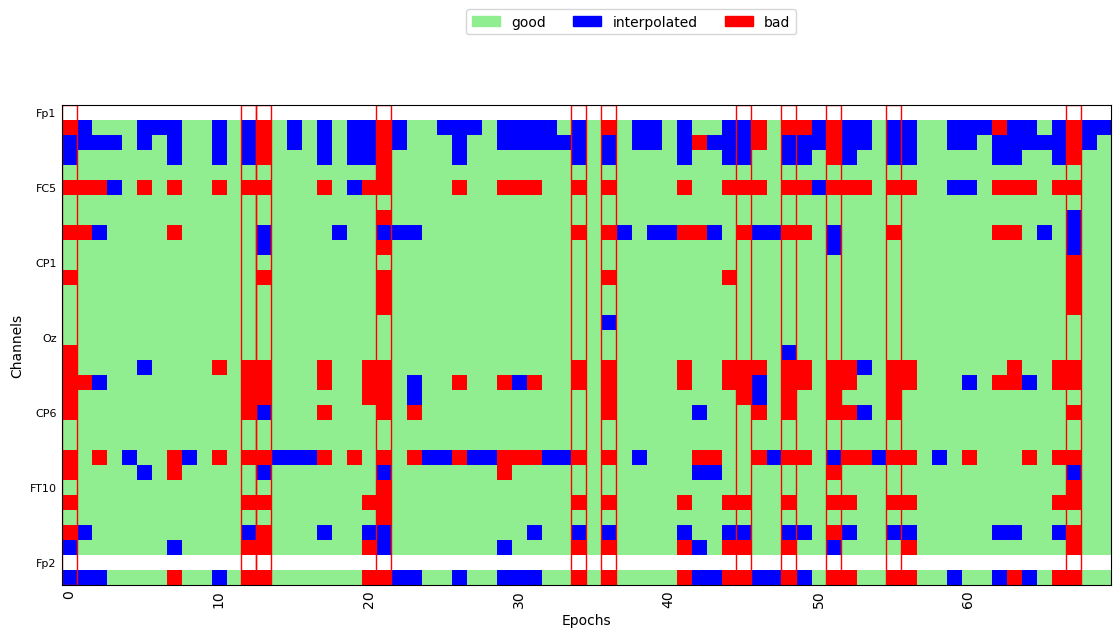

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 29 epochs: 0, 3, 5, 7, 11, 12, 13, 14, 15, 18, 25, 27, 30, 33, 39, 43, 45, 46, 48, 49, 50, 51, 54, 56, 57, 58, 60, 61, 67


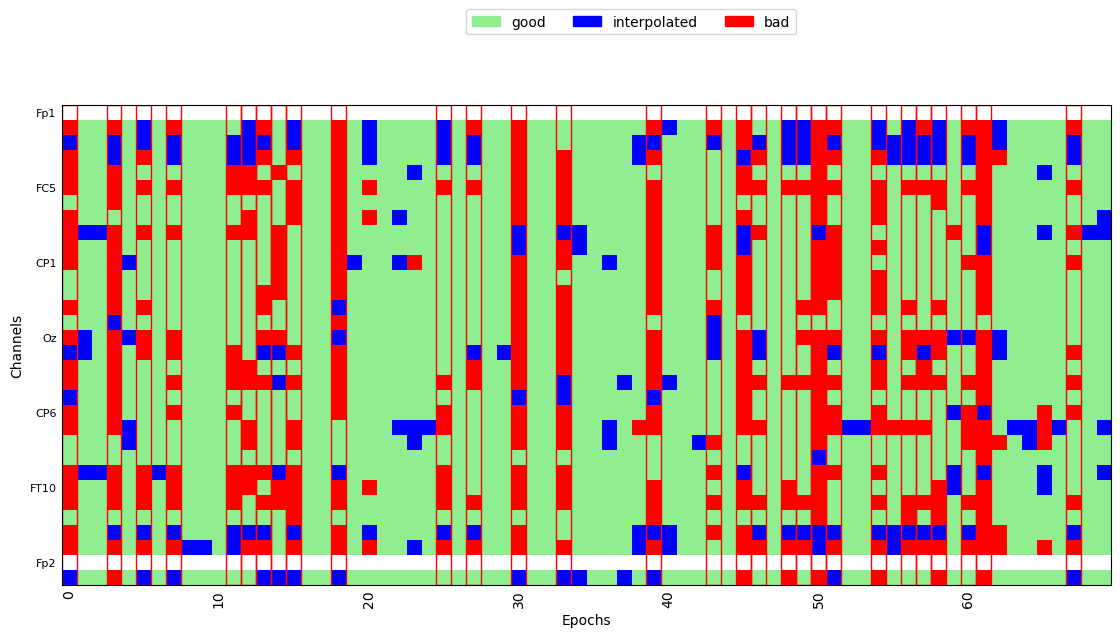

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 28 epochs: 3, 4, 6, 8, 11, 12, 14, 17, 21, 23, 28, 32, 33, 38, 43, 45, 47, 50, 51, 54, 55, 56, 59, 60, 62, 64, 65, 67


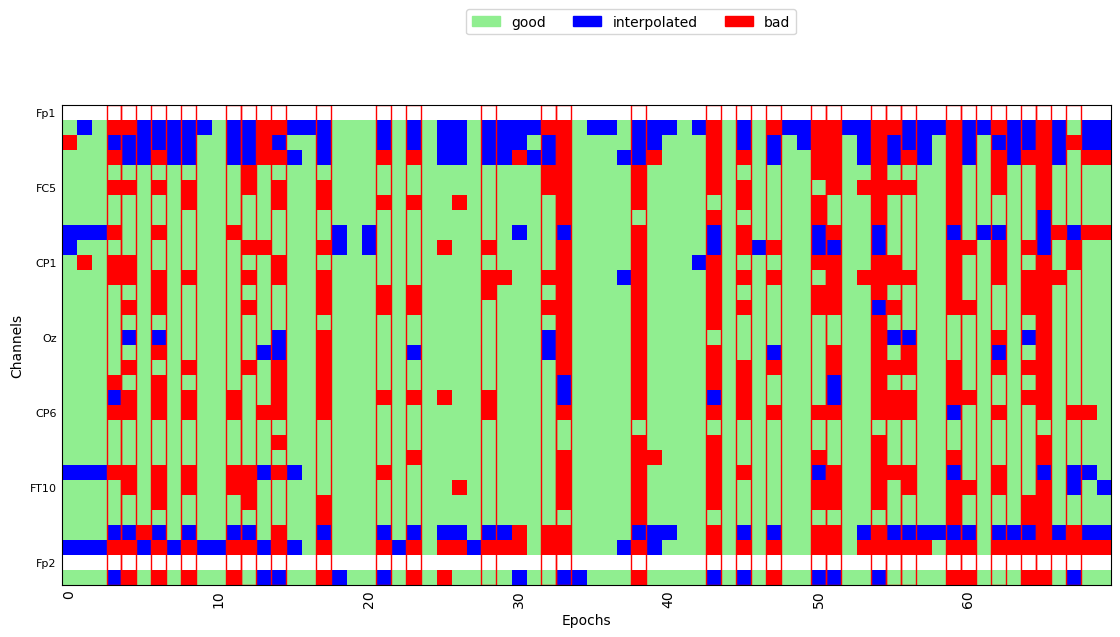

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0017_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0017_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1034384 =      0.000 ...  4137.536 secs
Ready.
Reading 0 ... 1034384  =      0.000 ...  4137.536 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 12 epochs: 9, 10, 14, 25, 27, 42, 45, 49, 53, 58, 67, 69


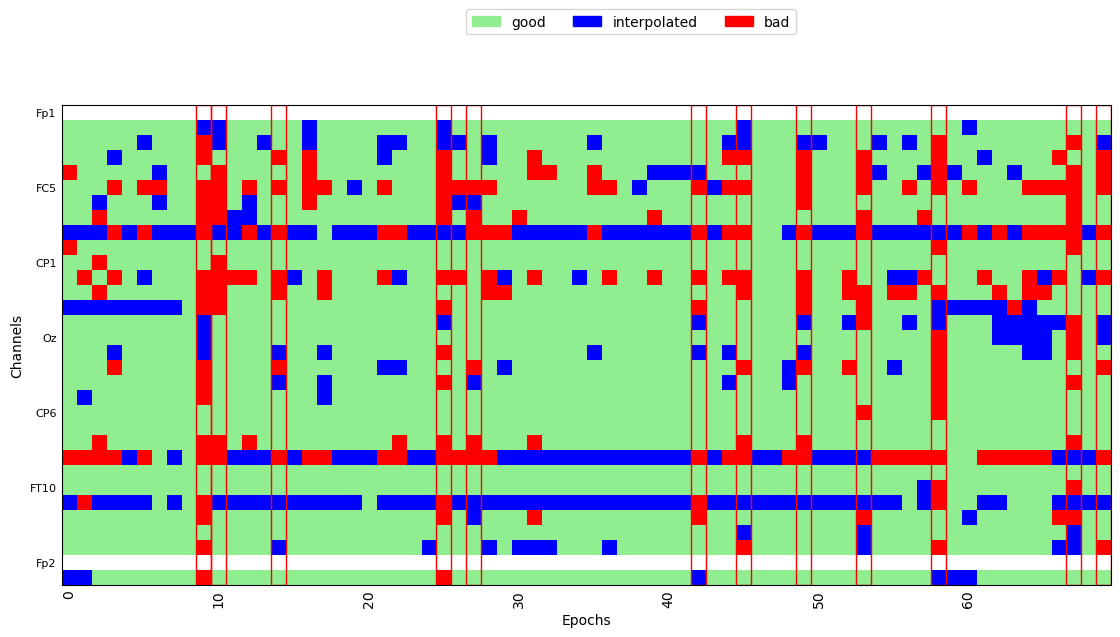

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 69


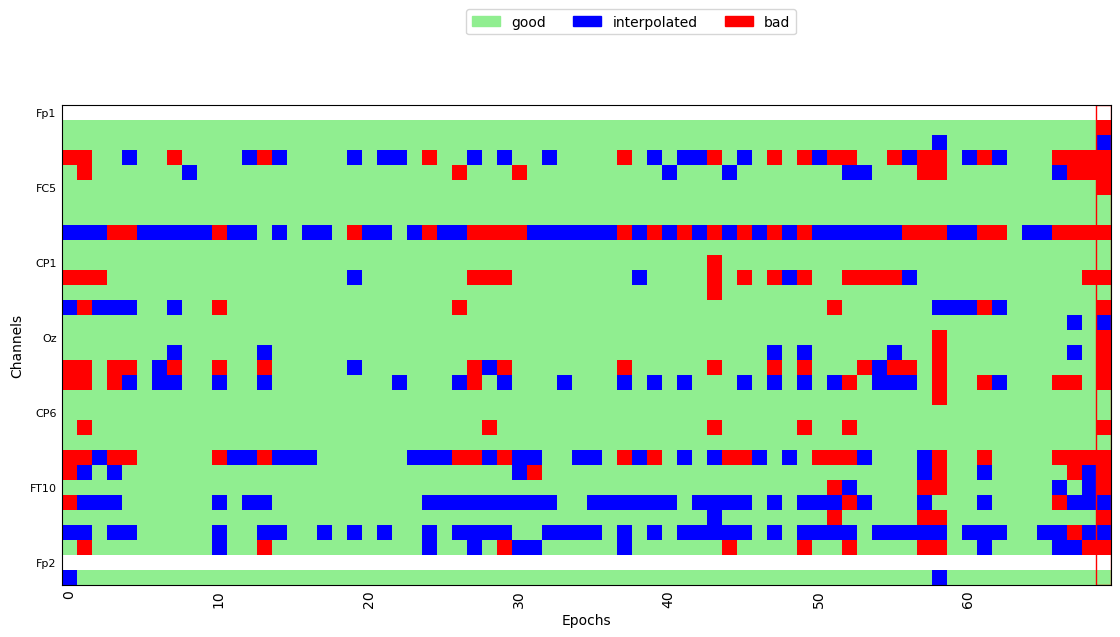

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 9, 57, 66, 67


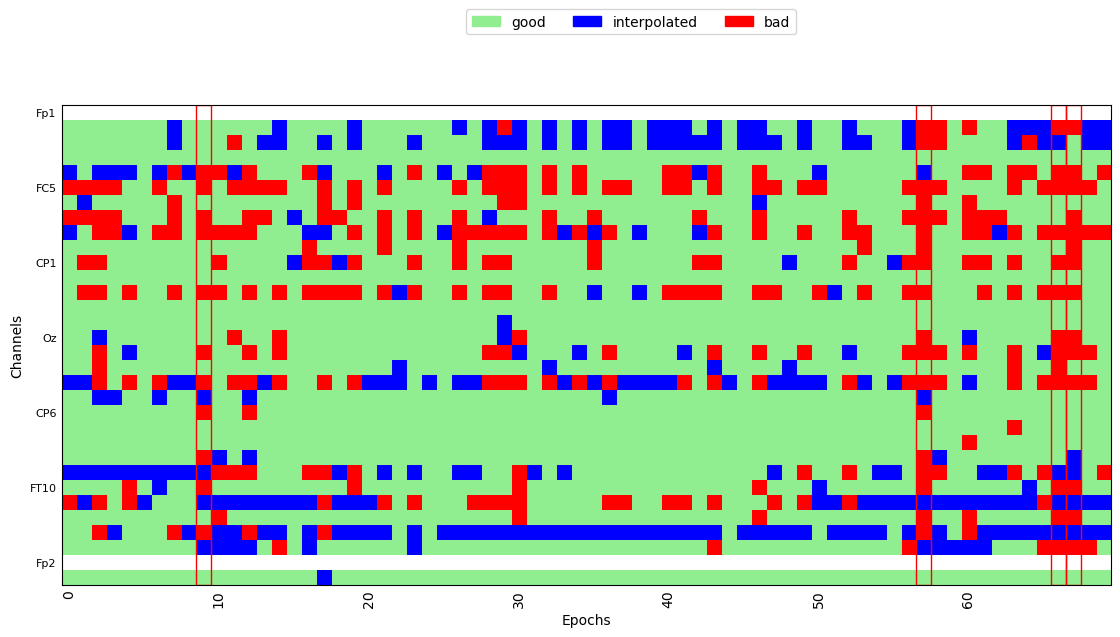

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


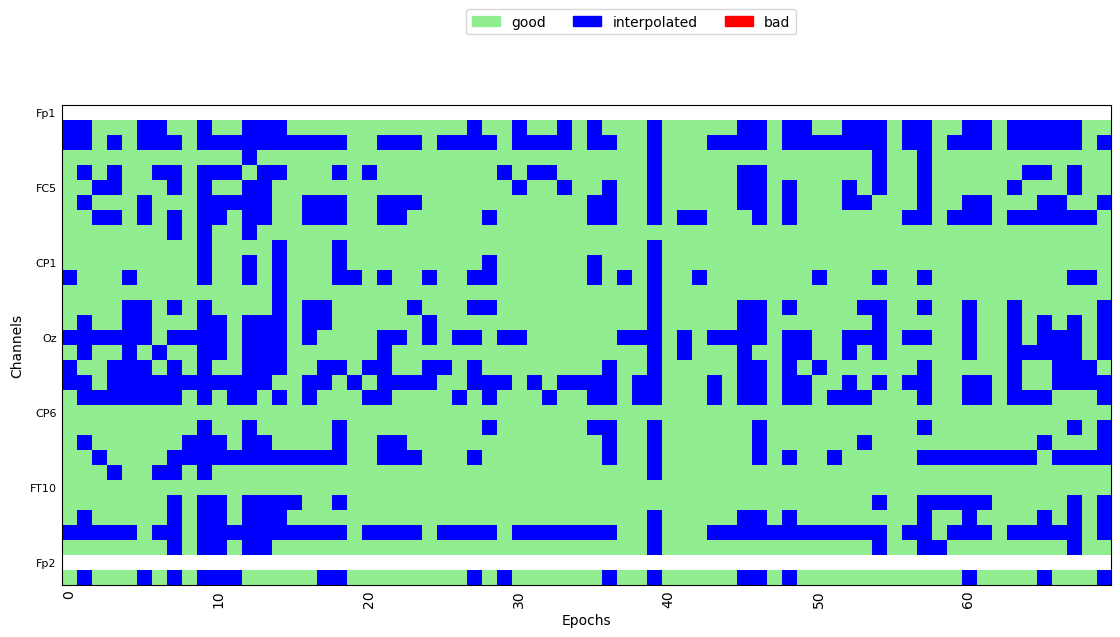

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 9, 16, 52, 54, 64


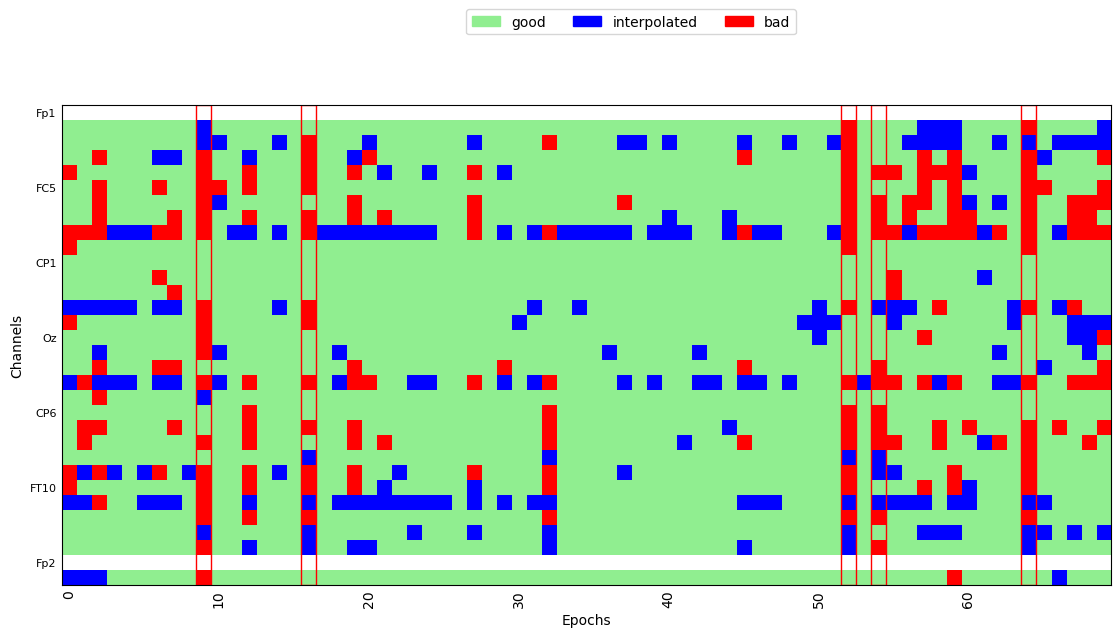

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 0, 3, 16, 19, 27, 29, 40, 45, 52, 55, 64


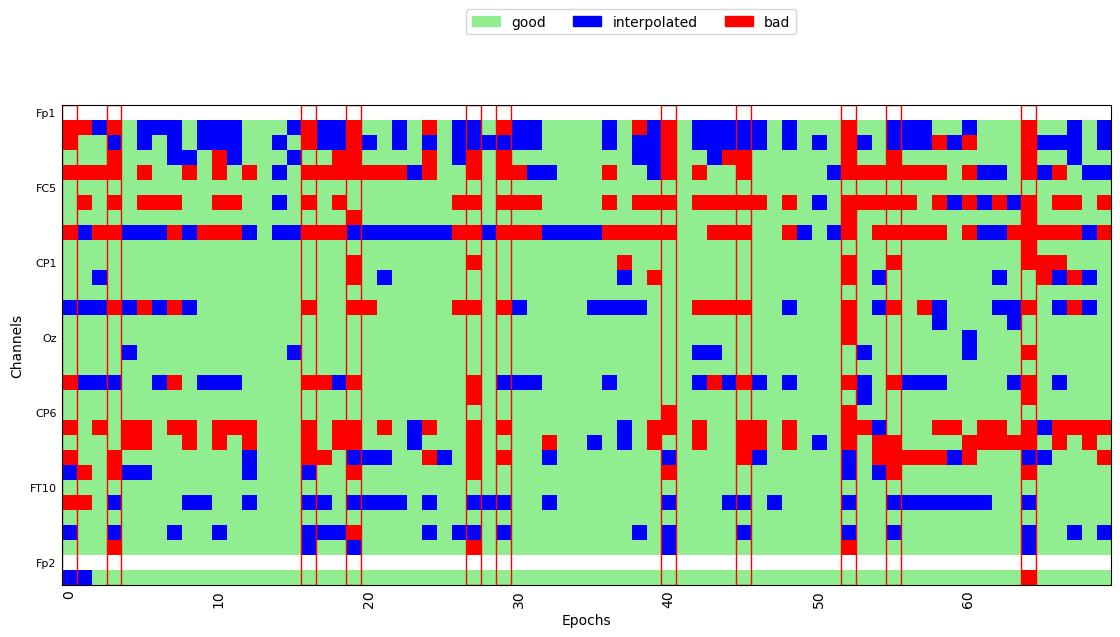

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 13, 36, 41, 49, 52, 53


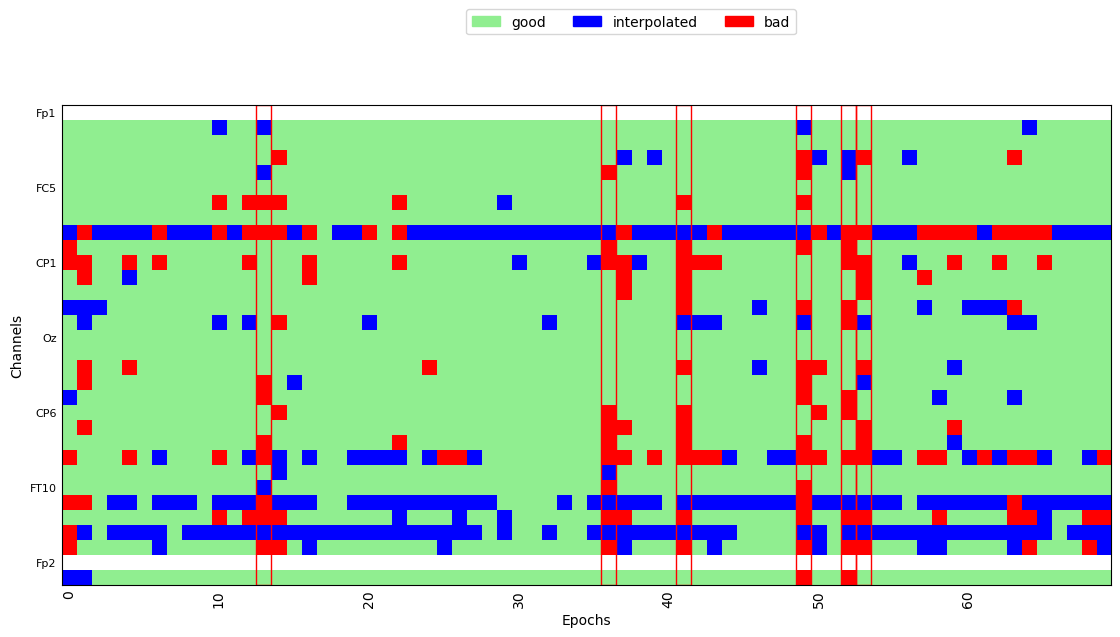

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 0, 3, 26, 53, 54


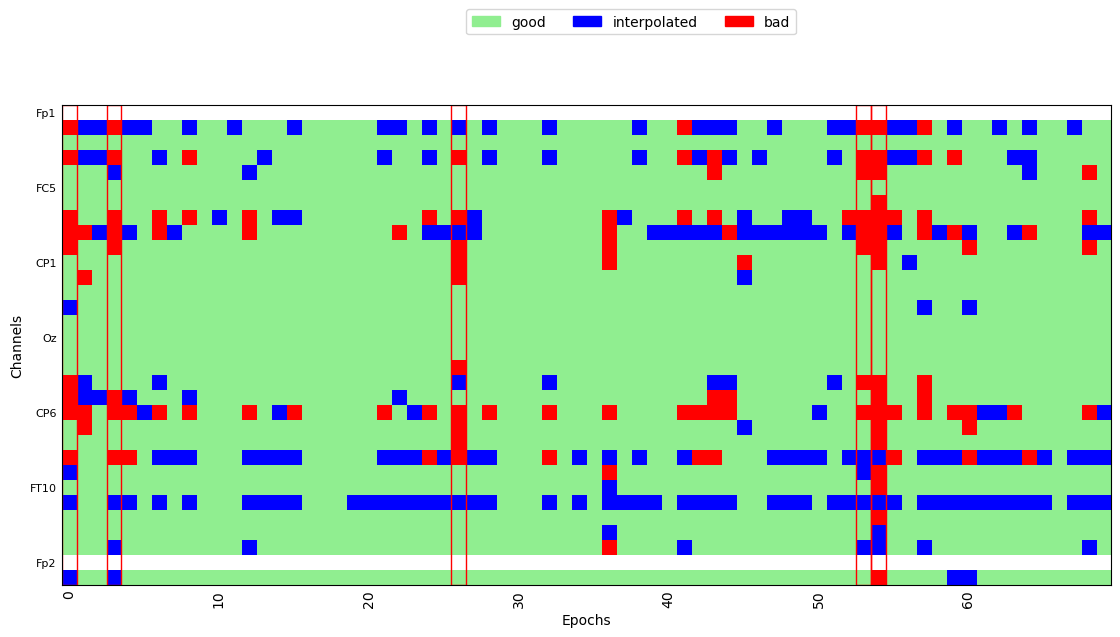

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0051_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0051_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1062194 =      0.000 ...  4248.776 secs
Ready.
Reading 0 ... 1062194  =      0.000 ...  4248.776 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 23, 46


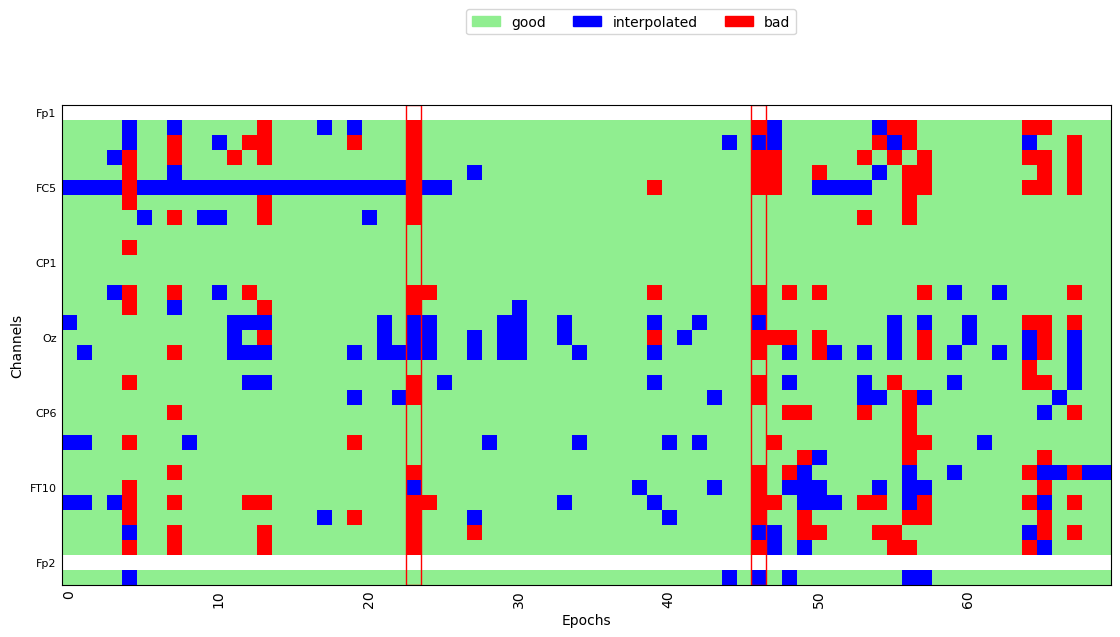

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 12, 46, 49, 56, 58, 59, 65


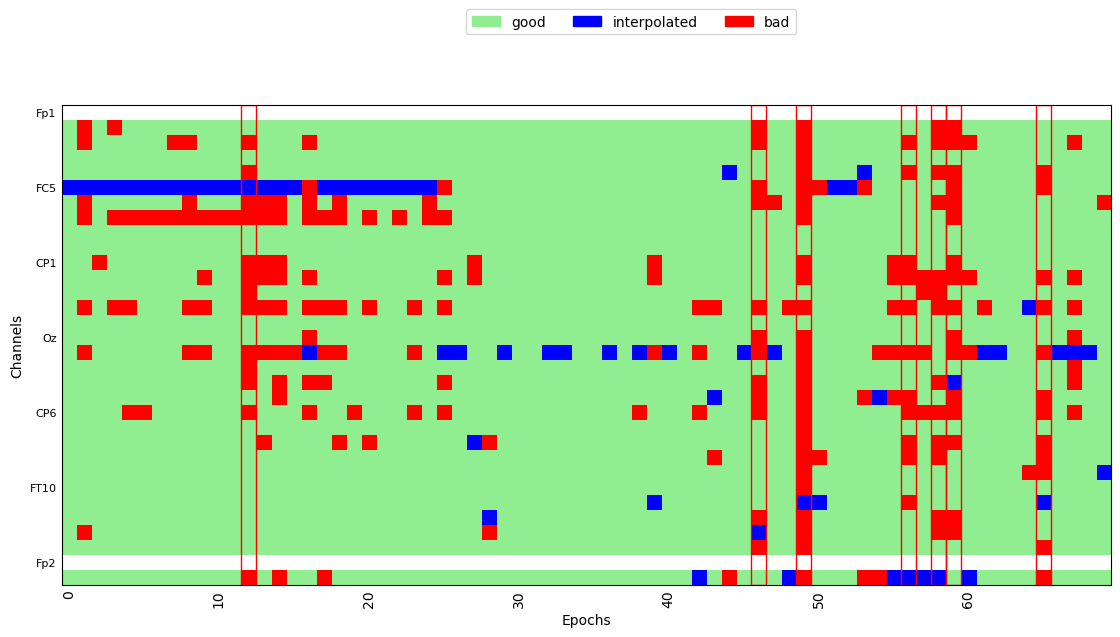

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 11, 19, 20, 51, 52, 53, 55, 57, 65, 67, 68


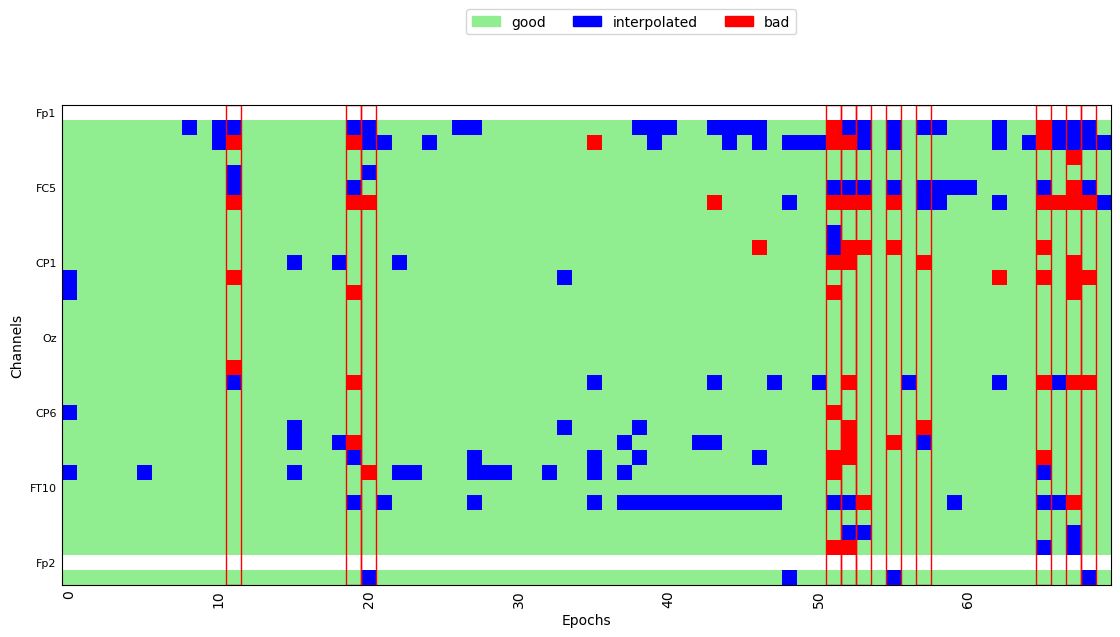

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 8, 18, 56


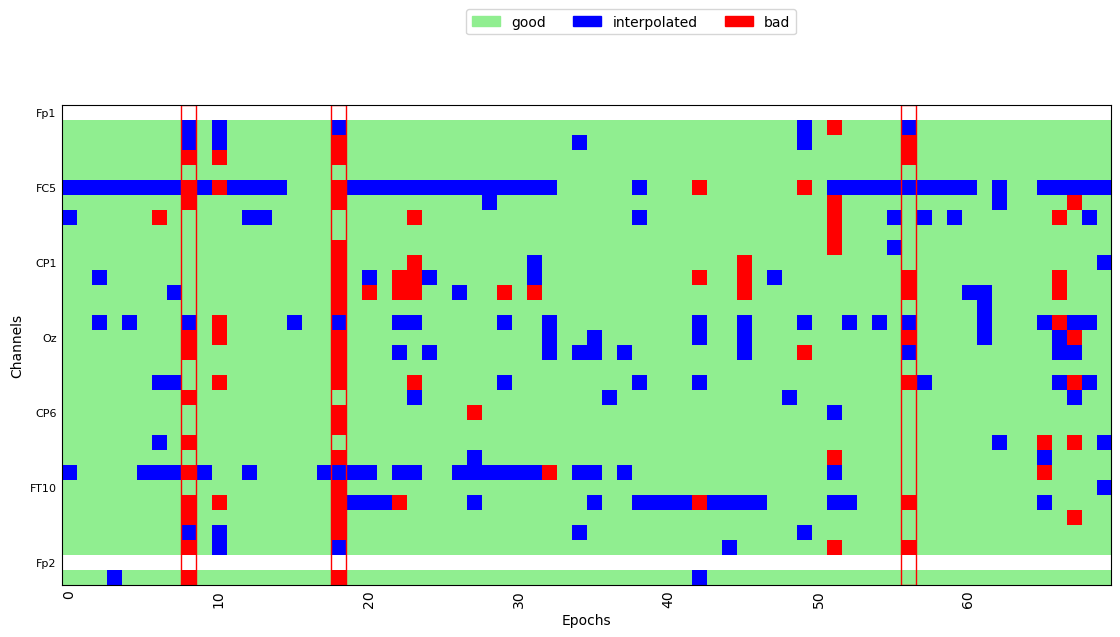

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 1, 4, 29, 42


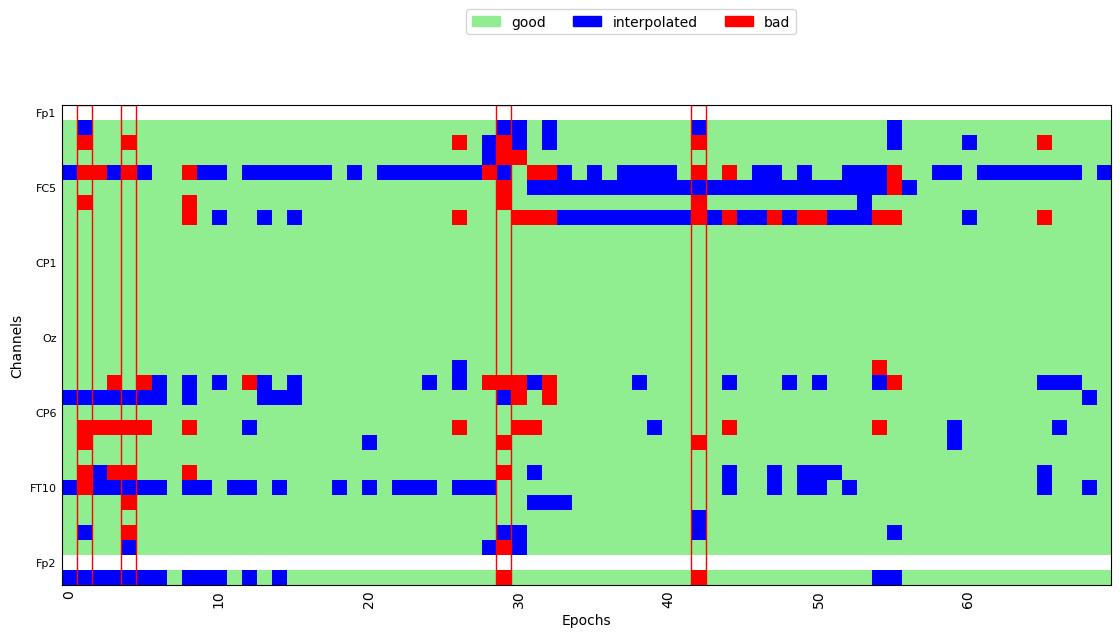

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 1, 3, 11, 31, 32


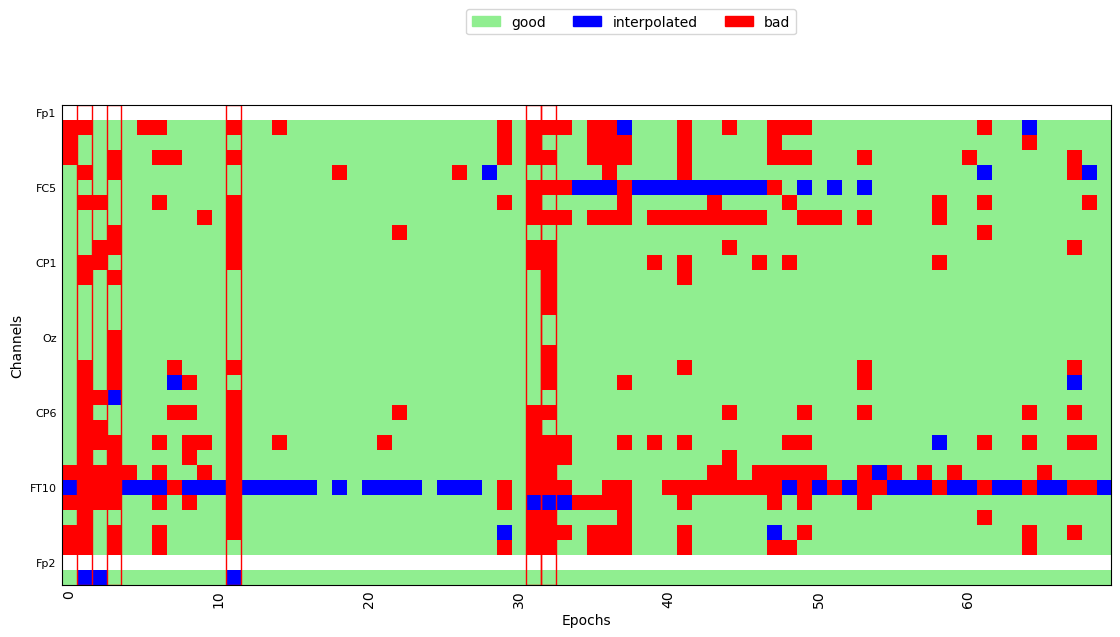

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 17, 42, 53, 65, 68


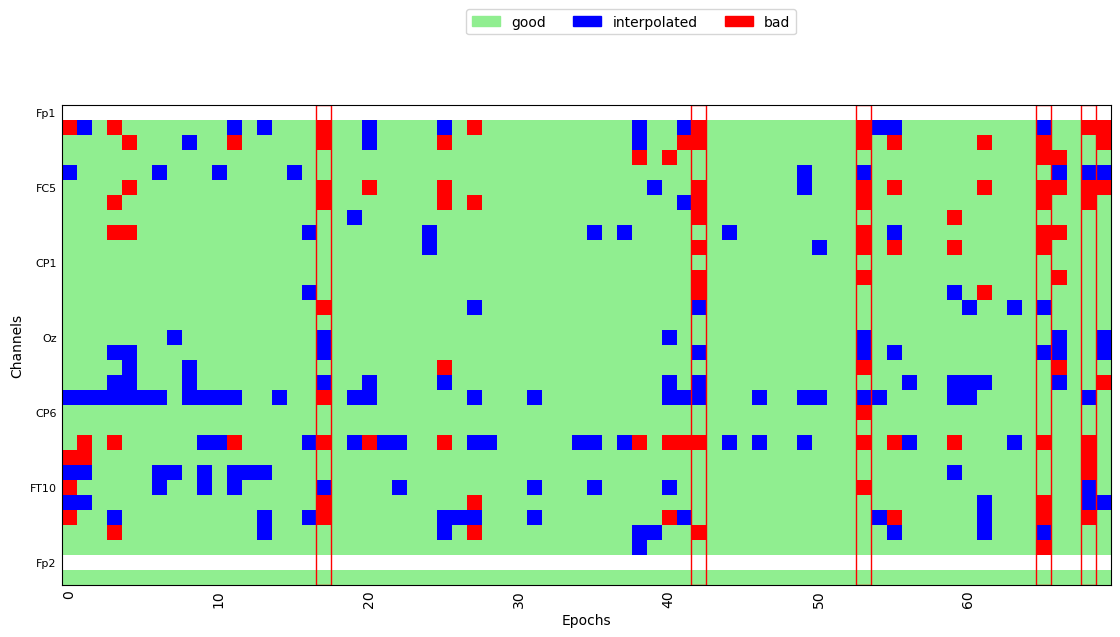

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


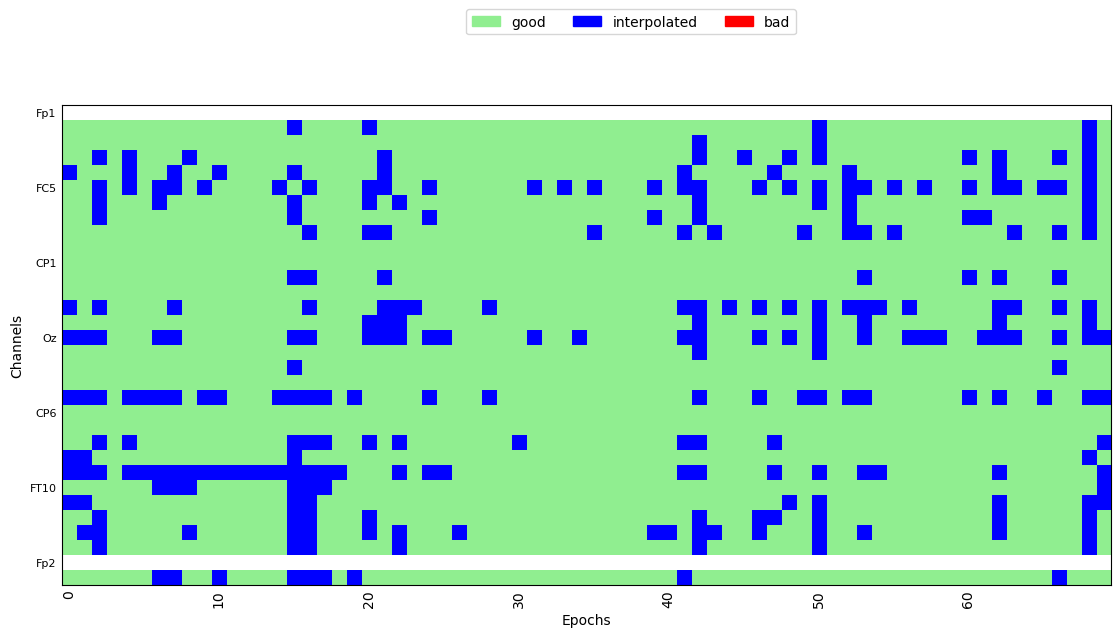

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0064_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1004589 =      0.000 ...  4018.356 secs
Ready.


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0064_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1004589  =      0.000 ...  4018.356 secs...
Not setting metadata
556 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 556 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

Dropped 6 epochs: 11, 22, 51, 54, 56, 67


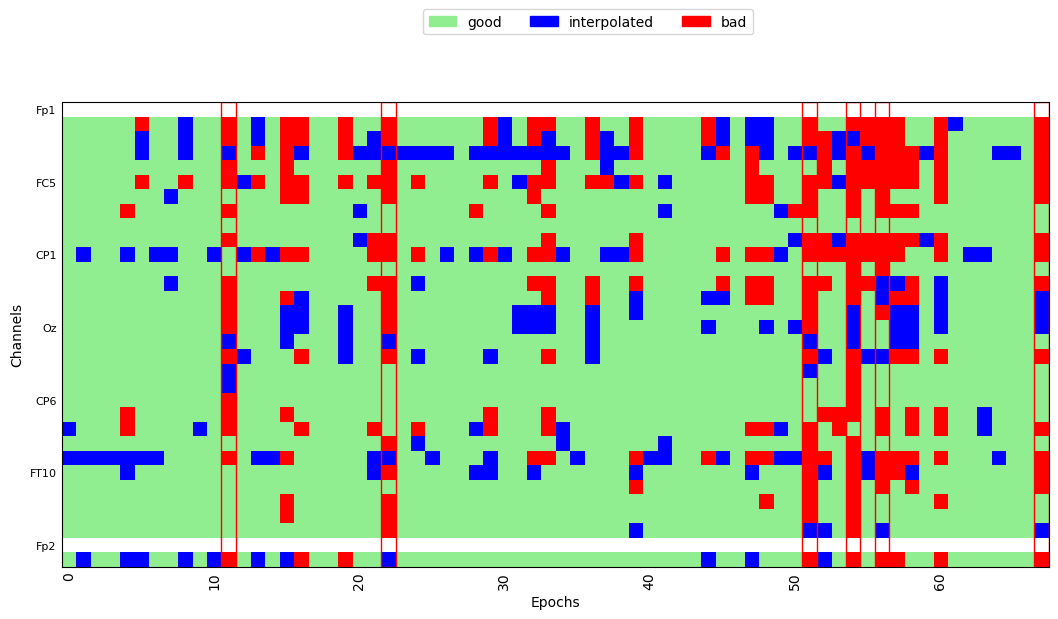

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/68 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


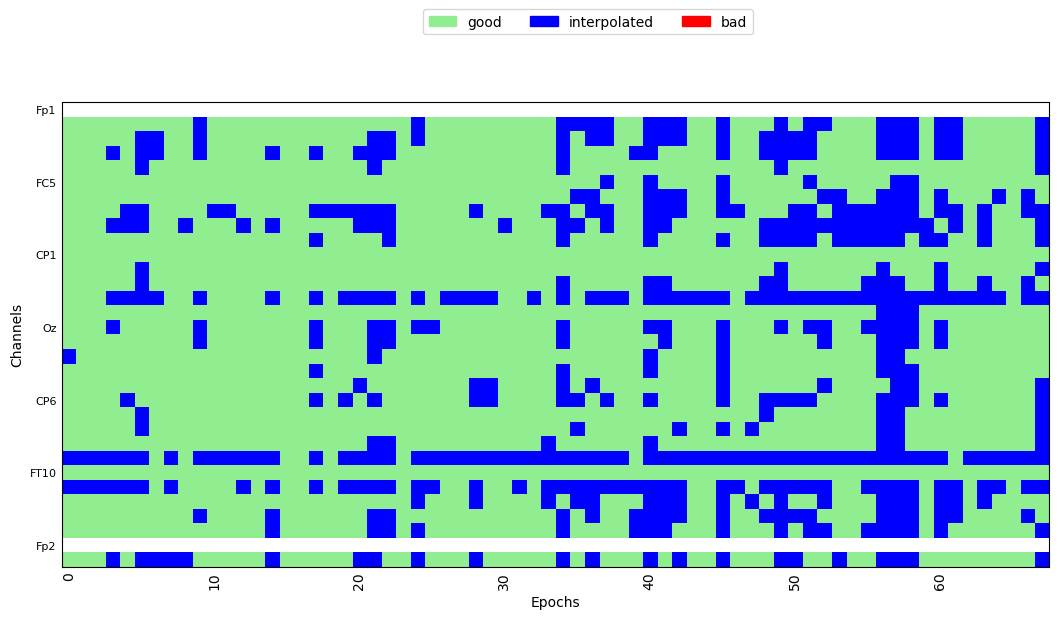

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 39, 42, 46, 55, 64


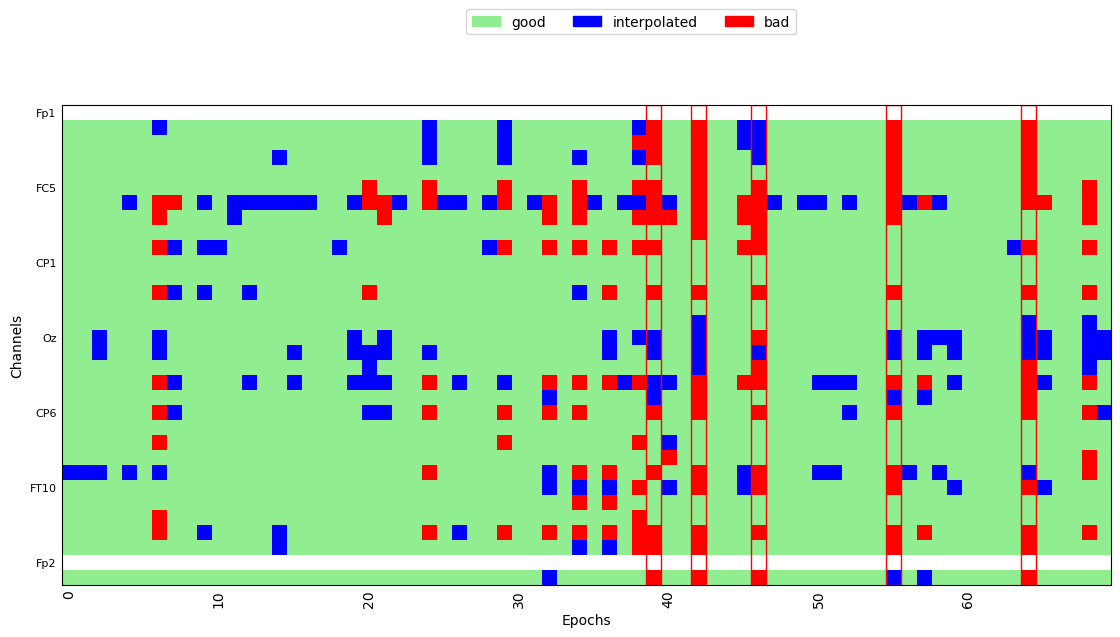

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 31 epochs: 5, 6, 9, 11, 14, 17, 19, 20, 21, 24, 26, 28, 29, 32, 33, 36, 38, 40, 41, 42, 43, 44, 46, 51, 55, 57, 58, 63, 64, 68, 69


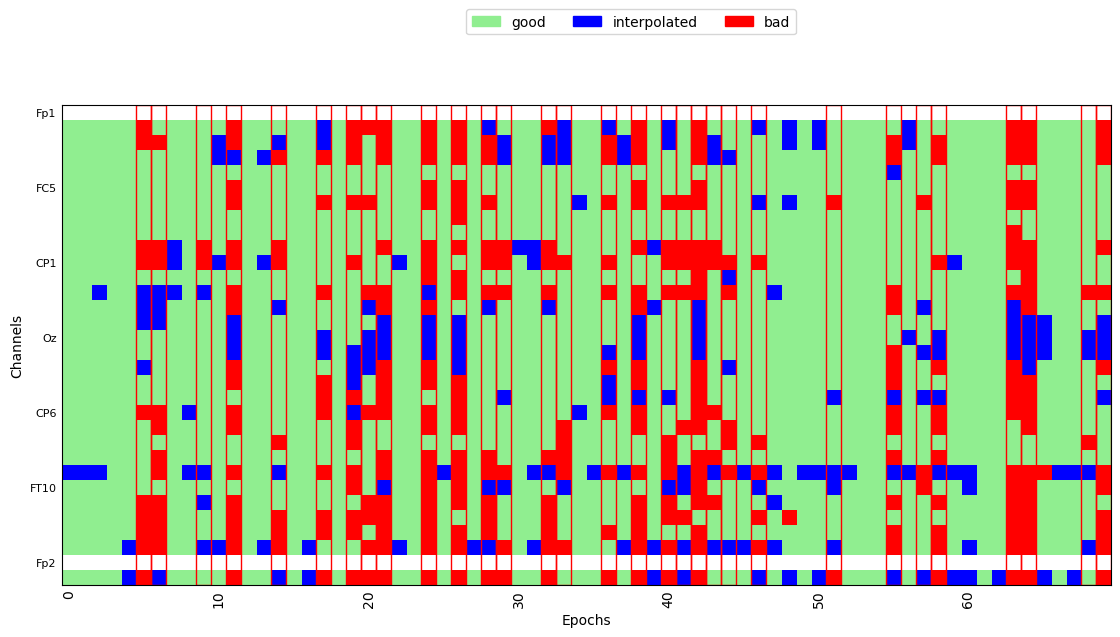

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 24 epochs: 0, 11, 14, 16, 21, 25, 31, 35, 37, 39, 40, 43, 45, 48, 50, 51, 52, 55, 57, 58, 59, 63, 67, 68


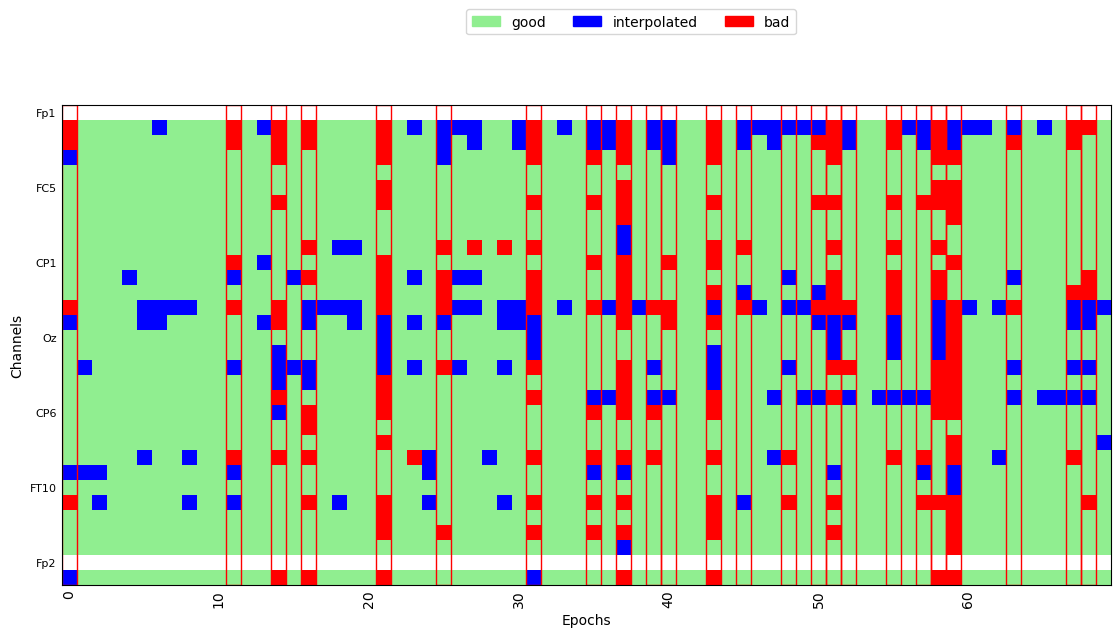

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 17 epochs: 15, 18, 21, 23, 25, 26, 27, 29, 31, 35, 37, 40, 45, 46, 57, 59, 68


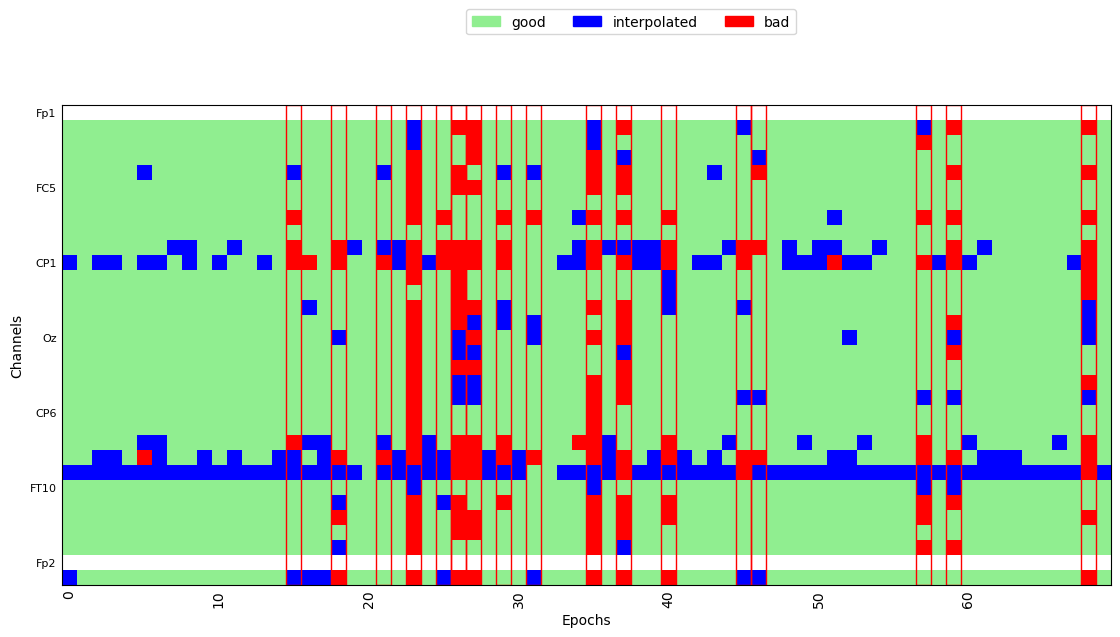

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 12, 19, 36, 47


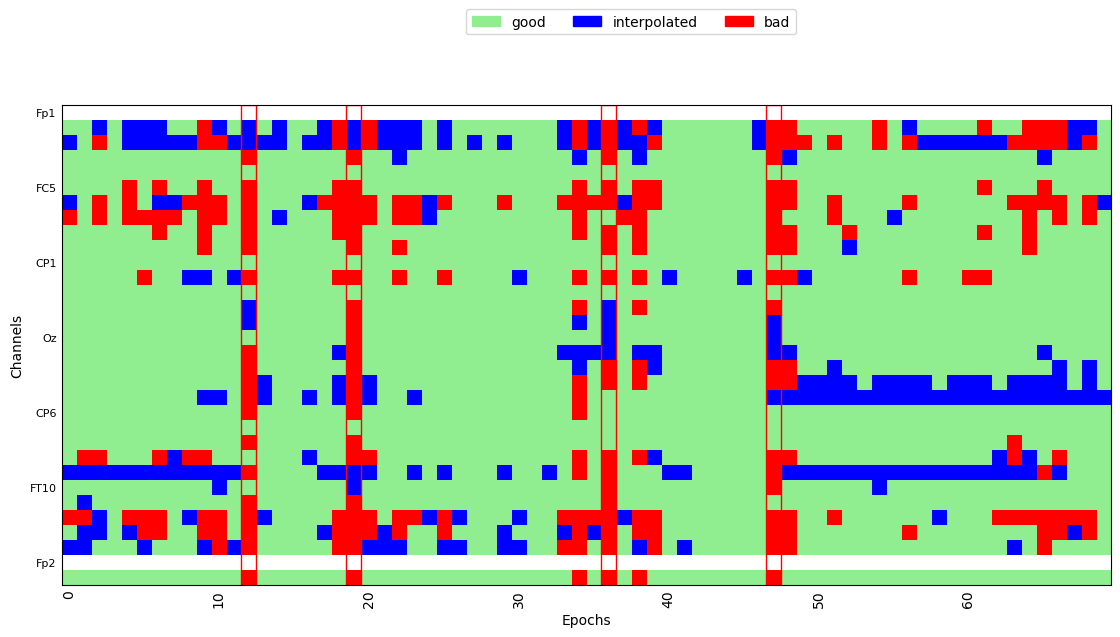

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 5, 6, 8, 12, 13, 18, 19, 23, 28, 34, 35, 36, 39, 49, 50, 52


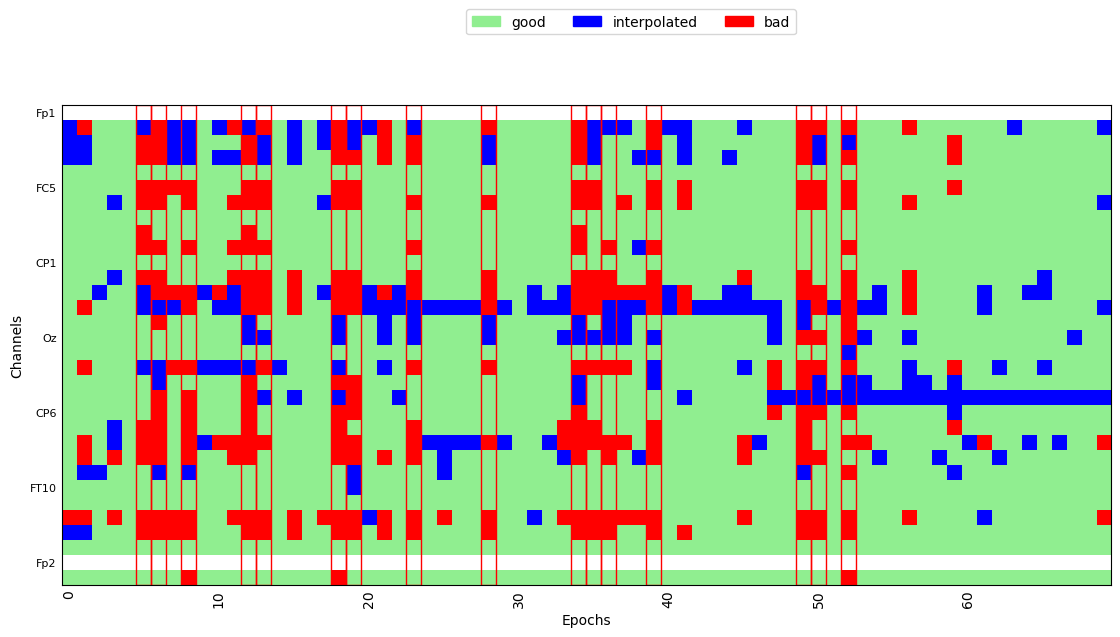

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0047_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1041889 =      0.000 ...  4167.556 secs
Ready.


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0047_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1041889  =      0.000 ...  4167.556 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 33, 41, 66, 68, 69


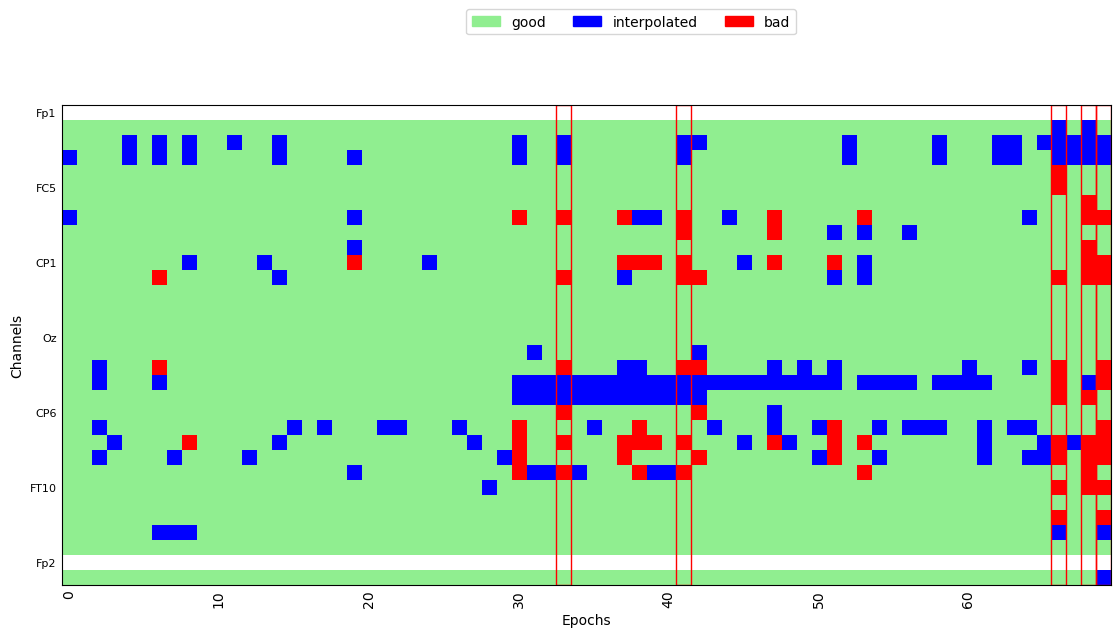

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 66, 68, 69


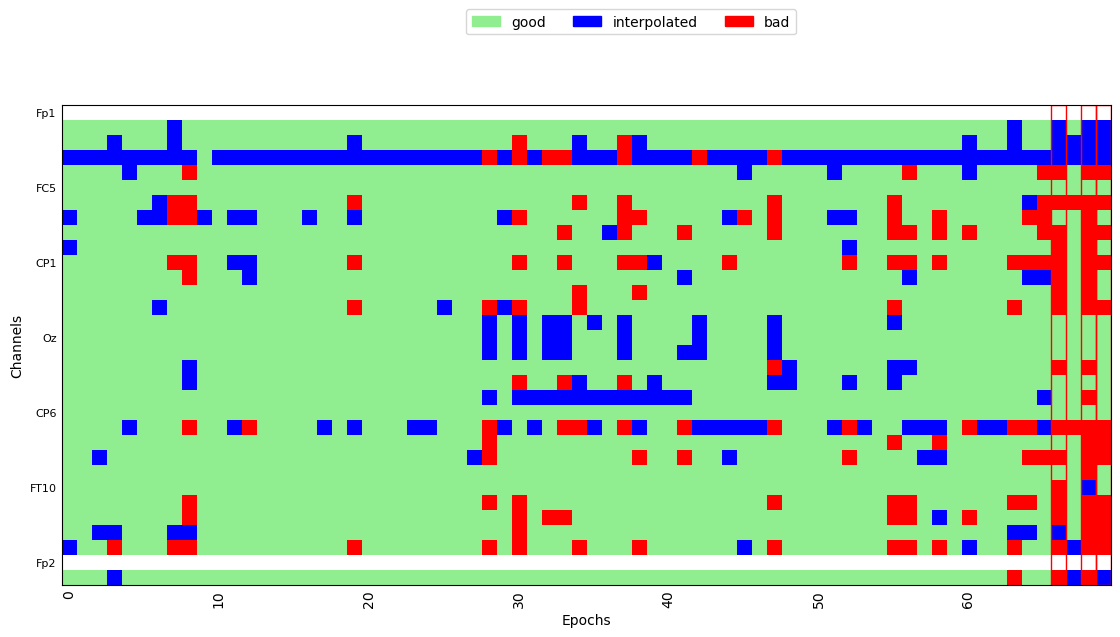

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 56, 57


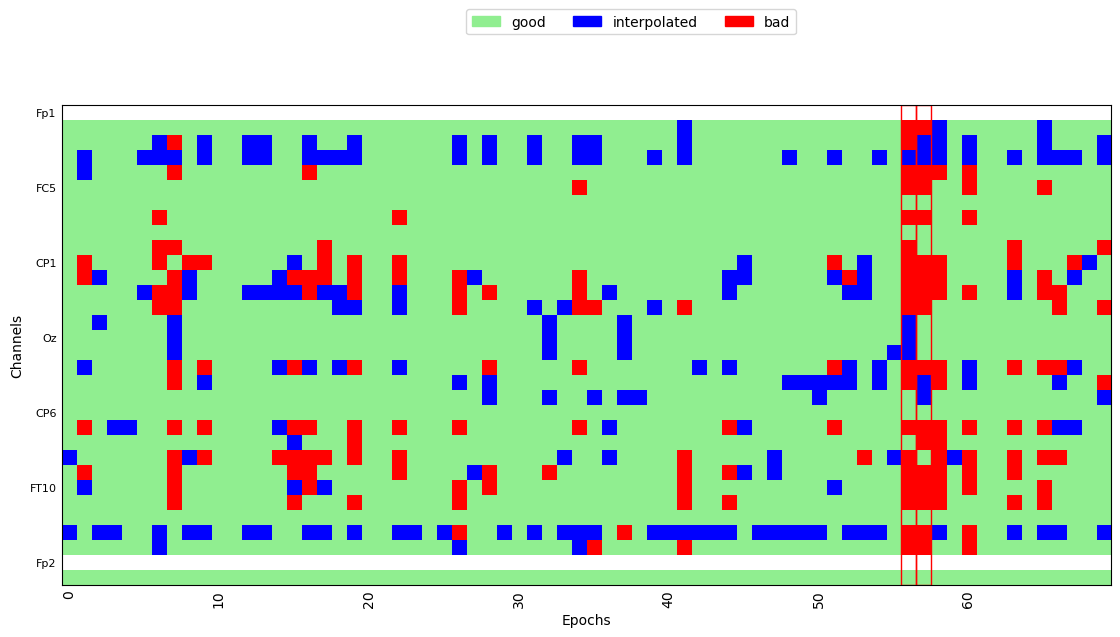

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


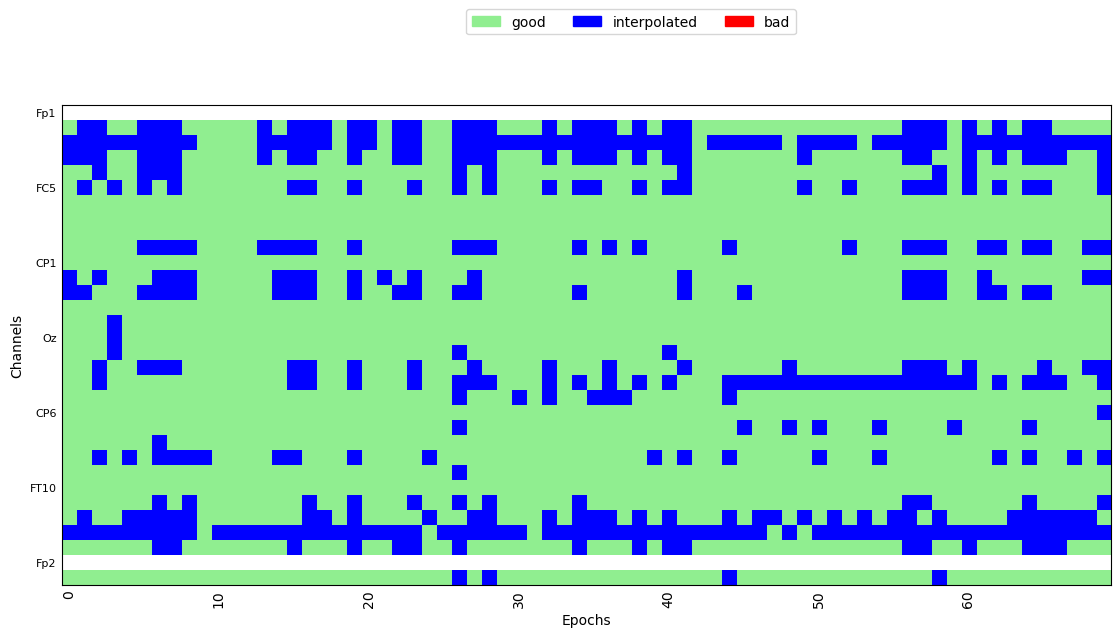

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 21 epochs: 0, 1, 3, 4, 12, 13, 14, 16, 21, 24, 25, 27, 32, 33, 42, 43, 44, 45, 52, 55, 58


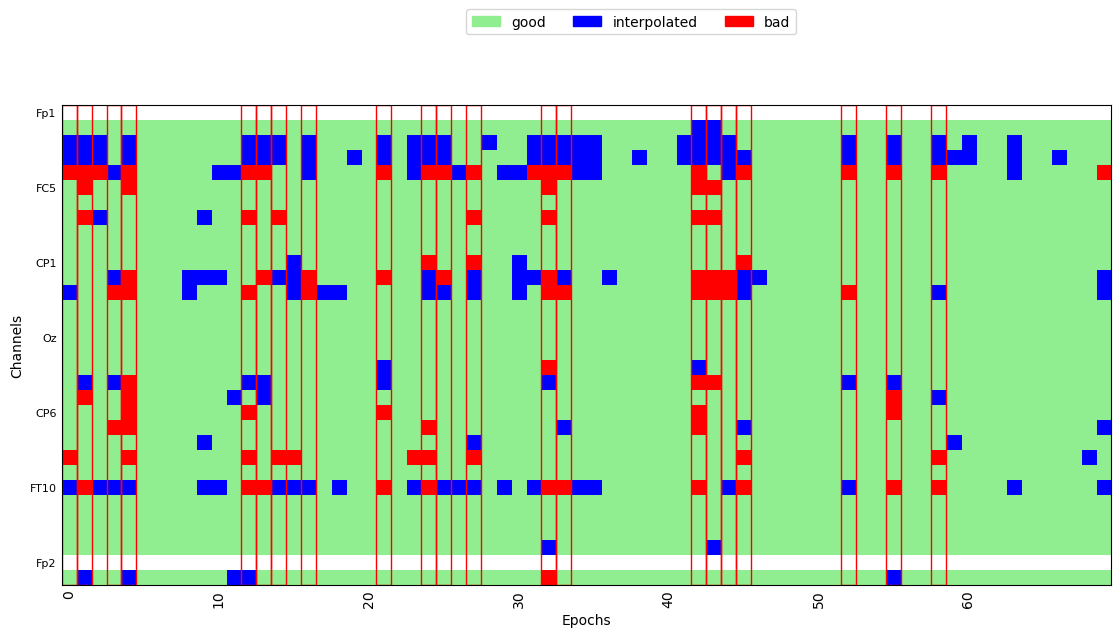

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 0, 4, 15, 30, 32, 42, 45


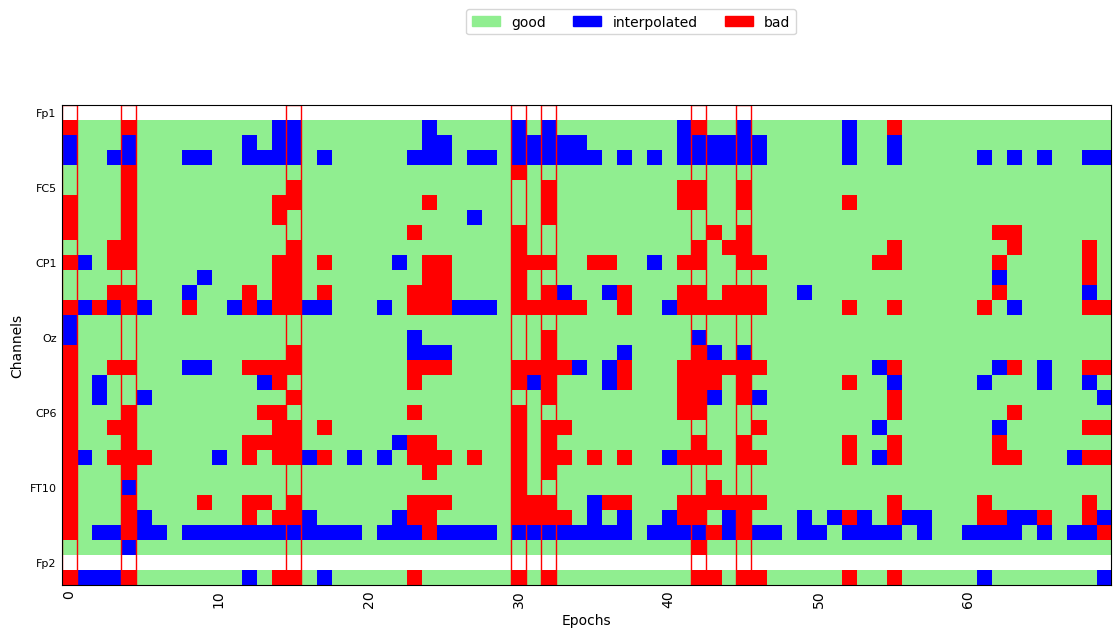

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 8, 9, 15, 16, 17, 26, 29, 31, 55


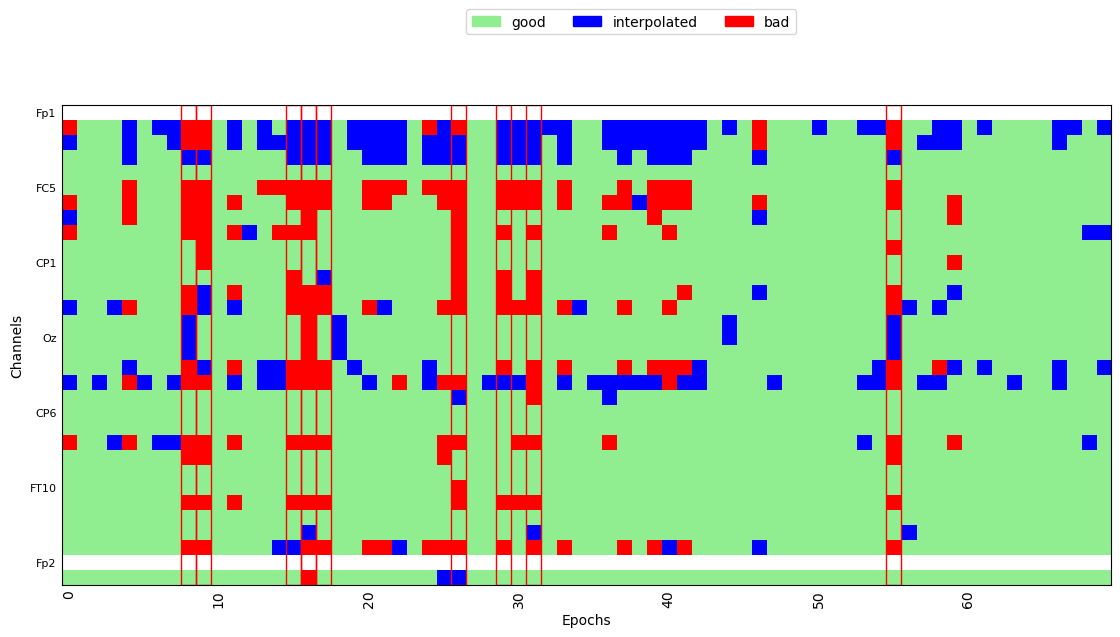

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 25, 26, 40


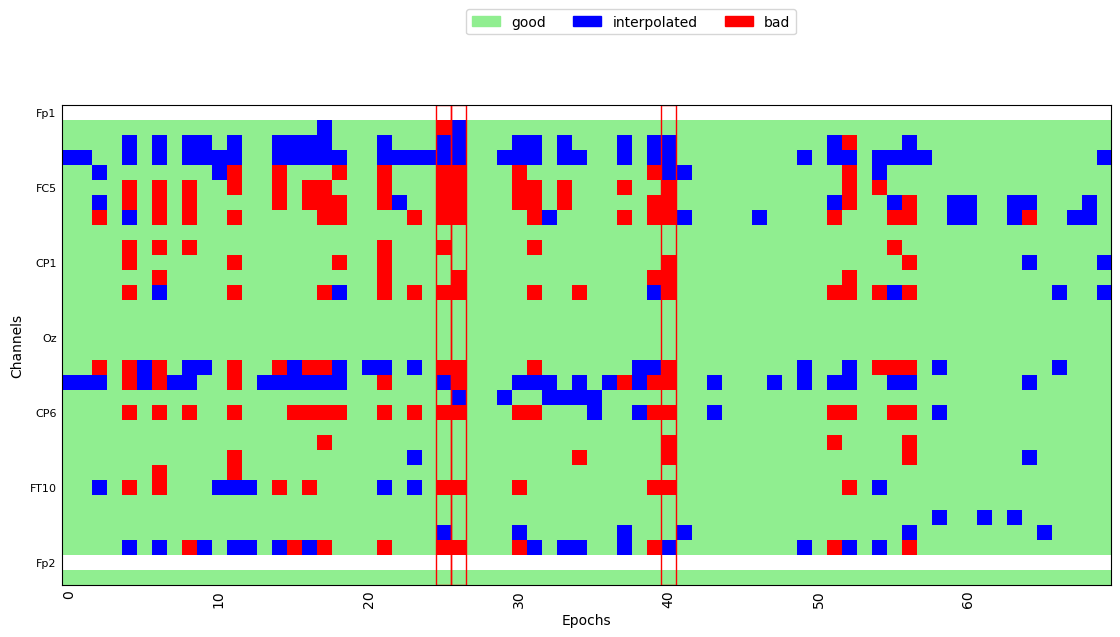

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0072_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1030249 =      0.000 ...  4120.996 secs
Ready.
Reading 0 ... 1030249  =      0.000 ...  4120.996 secs...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0072_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 0, 1, 2, 4, 48, 58, 59


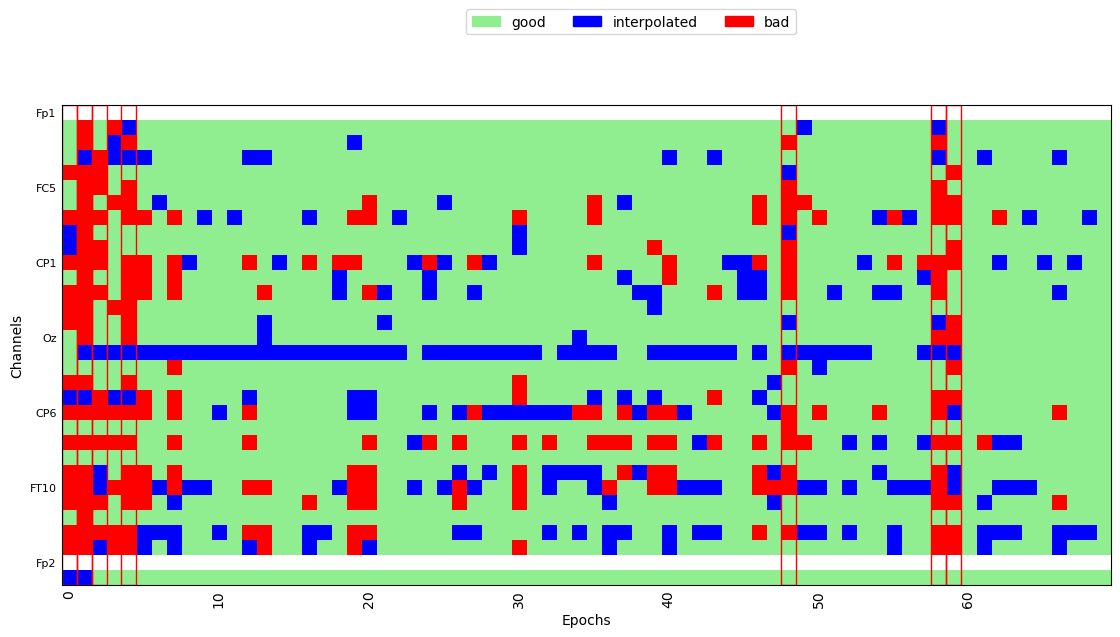

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


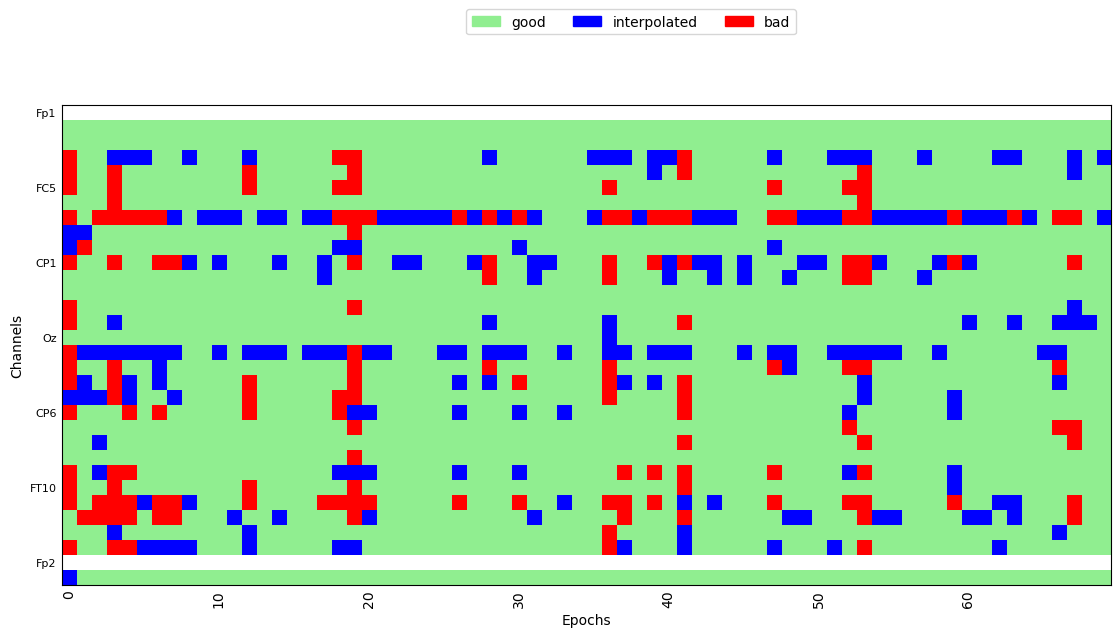

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 1, 3, 10, 11, 16, 24, 31, 35, 57


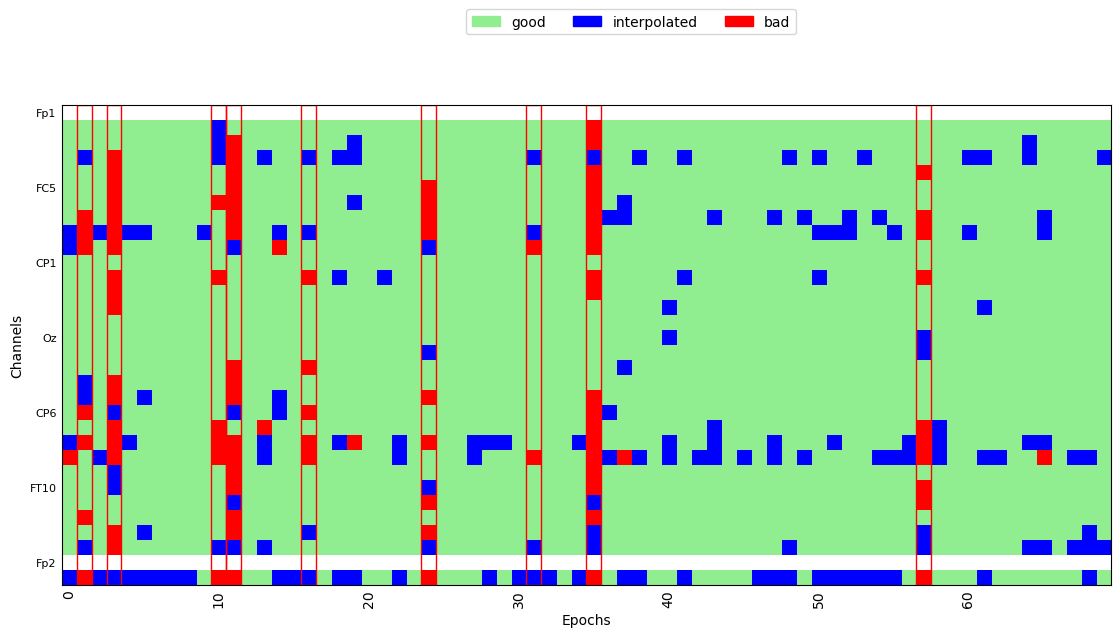

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 21, 46


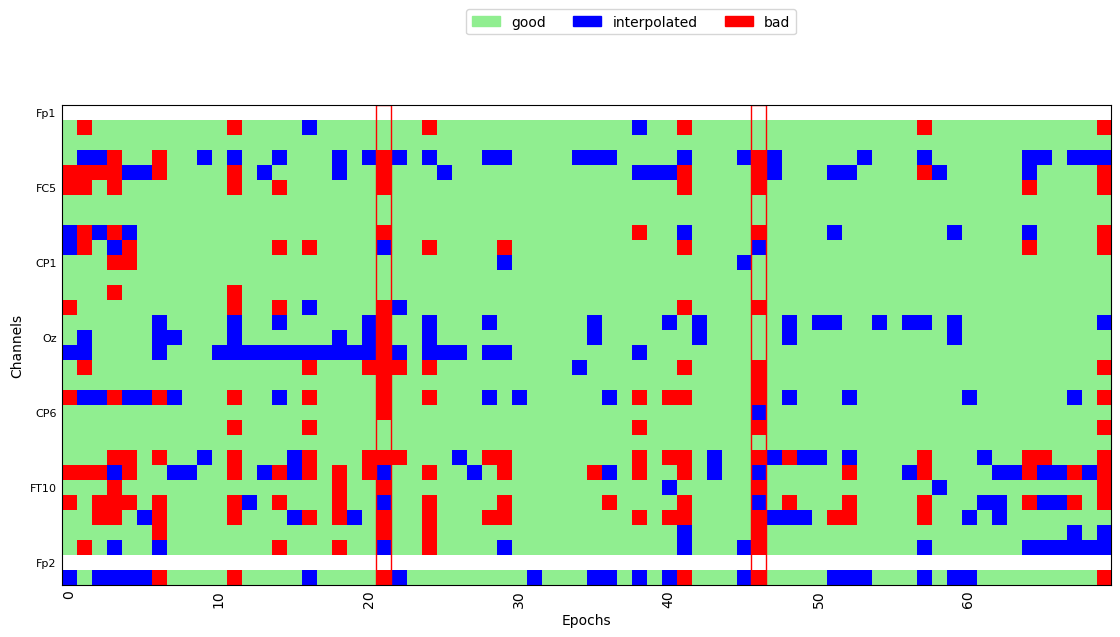

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 1, 2, 3, 6, 11, 24, 38


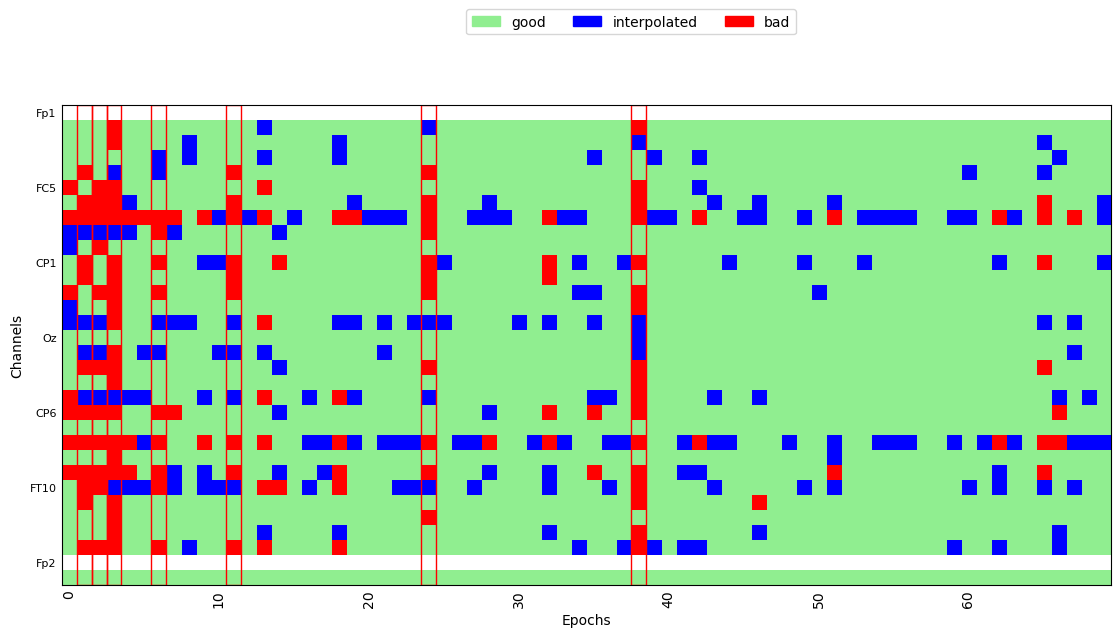

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 0, 1, 3, 16, 38


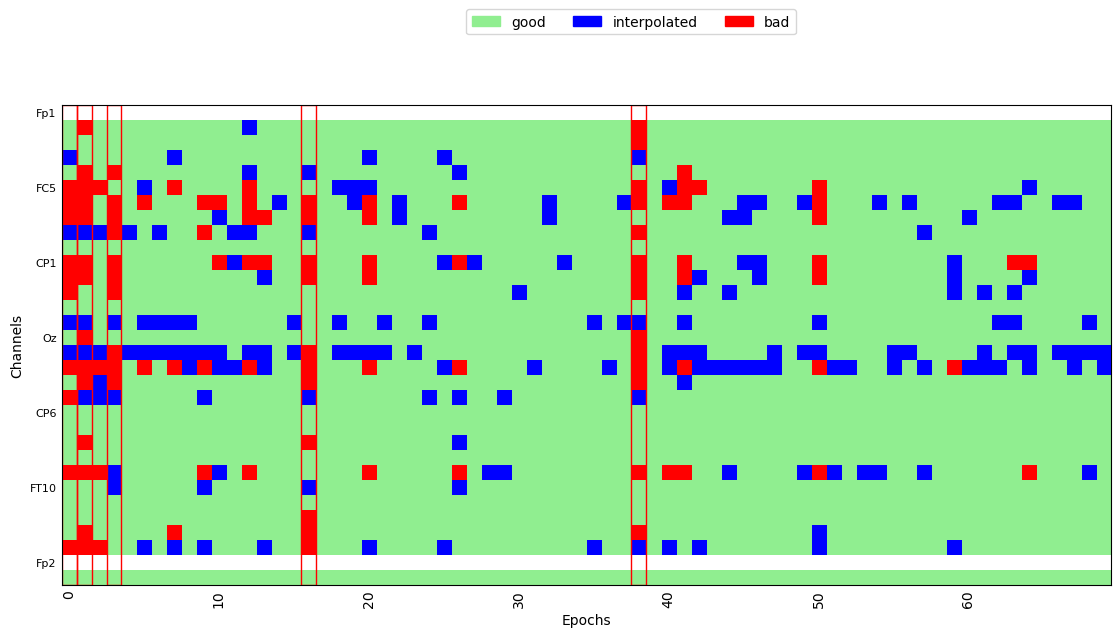

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 0, 3, 5, 27, 38, 45, 50, 54, 60, 69


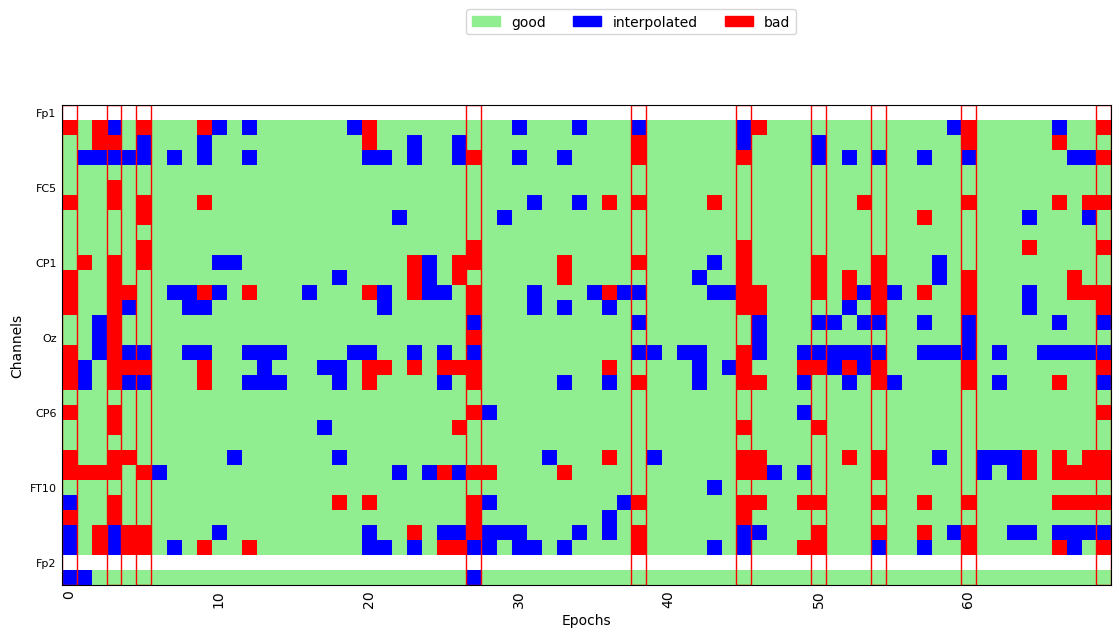

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 0, 4, 29, 55


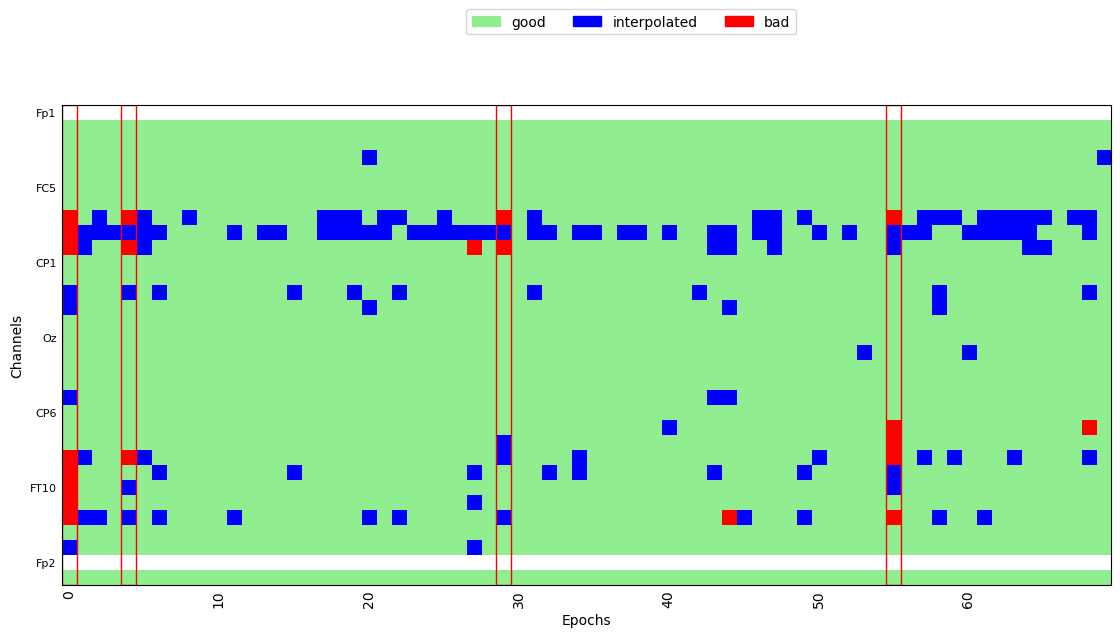

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0035_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0035_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1046744 =      0.000 ...  4186.976 secs
Ready.
Reading 0 ... 1046744  =      0.000 ...  4186.976 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 47 epochs: 0, 1, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 18, 19, 20, 21, 22, 23, 24, 25, 27, 30, 31, 32, 34, 35, 36, 38, 39, 41, 43, 47, 48, 50, 51, 53, 54, 55, 56, 57, 58, 59, 64, 66, 68, 69


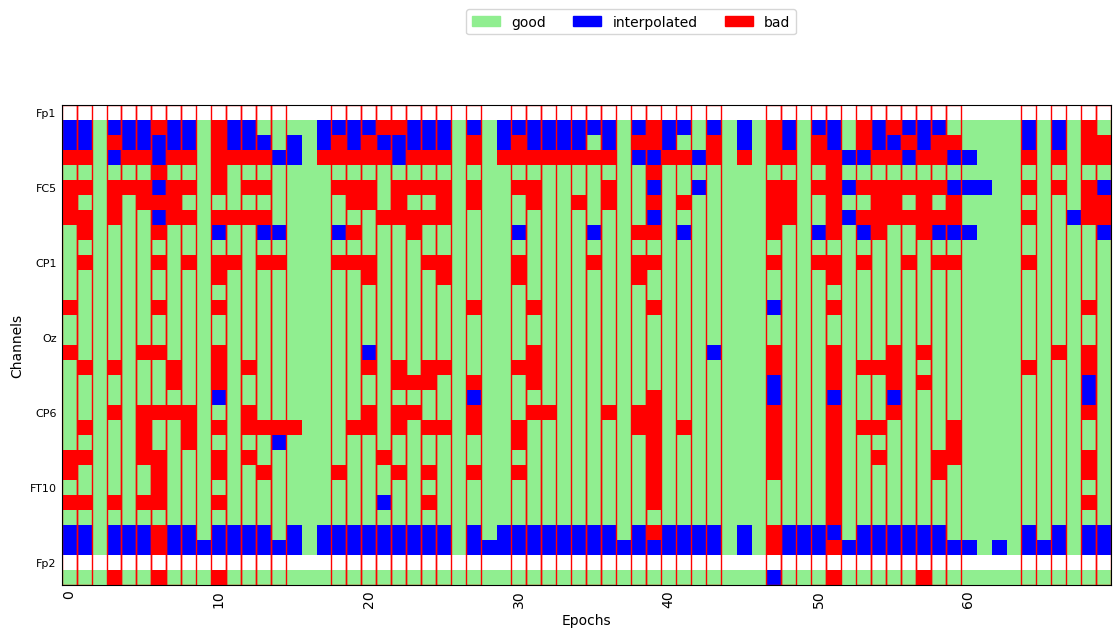

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 0, 2, 12, 18, 20, 27, 39, 47, 57, 69


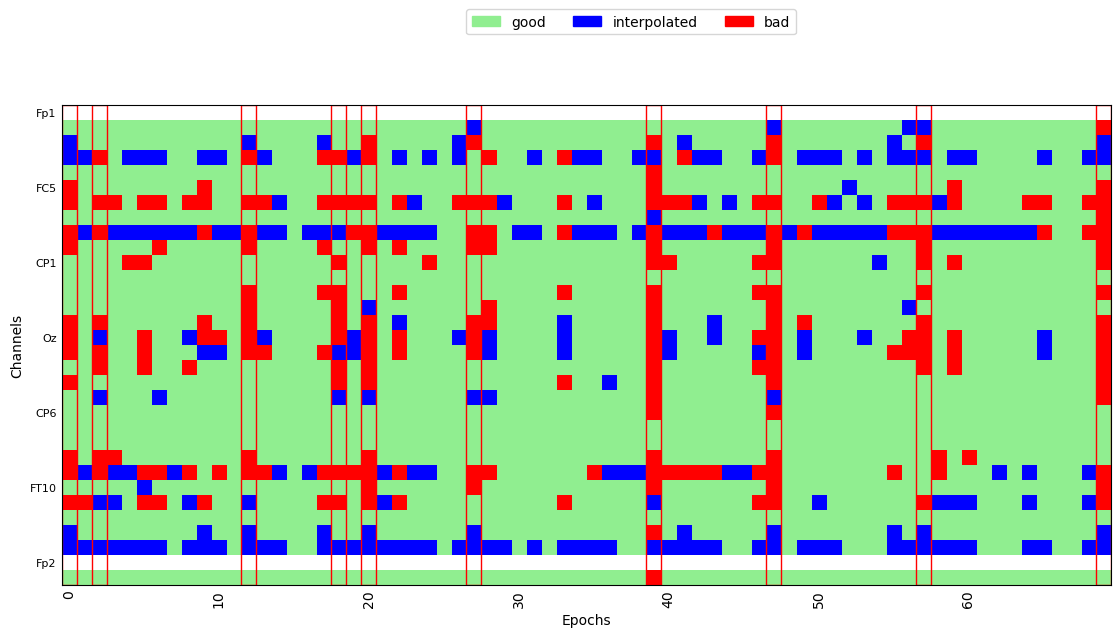

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 21 epochs: 0, 1, 3, 4, 6, 7, 8, 9, 10, 11, 20, 25, 26, 31, 34, 37, 42, 43, 45, 67, 68


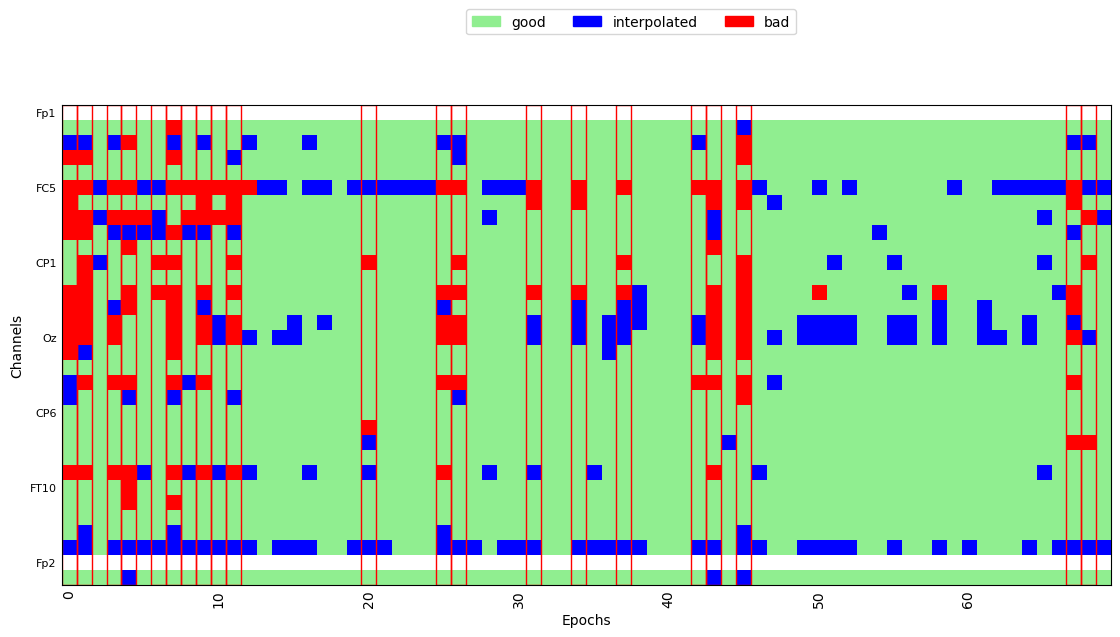

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


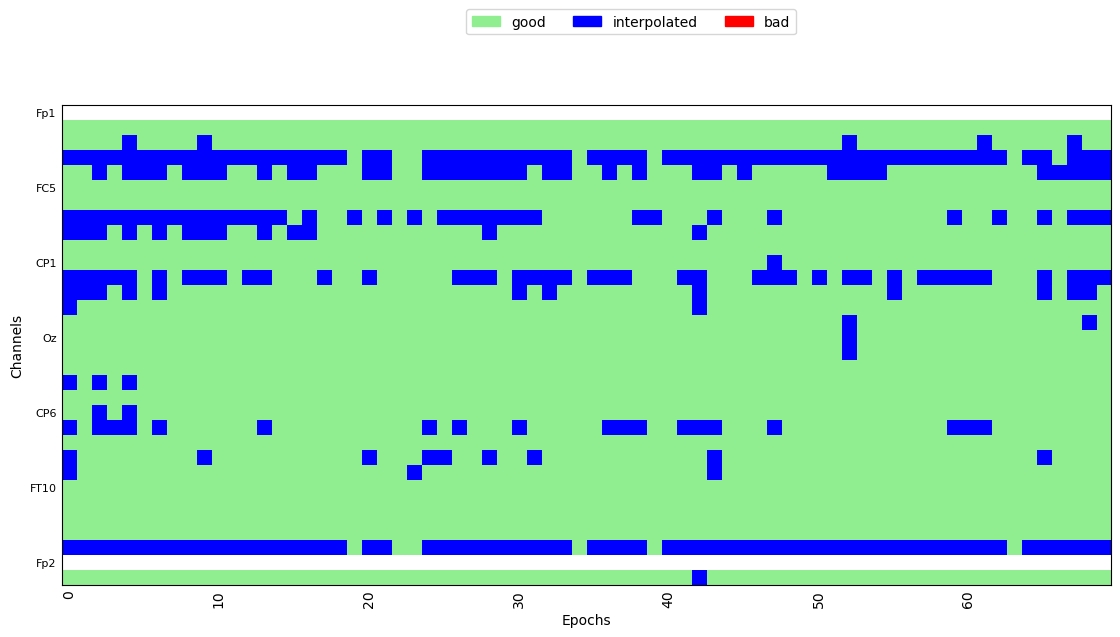

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


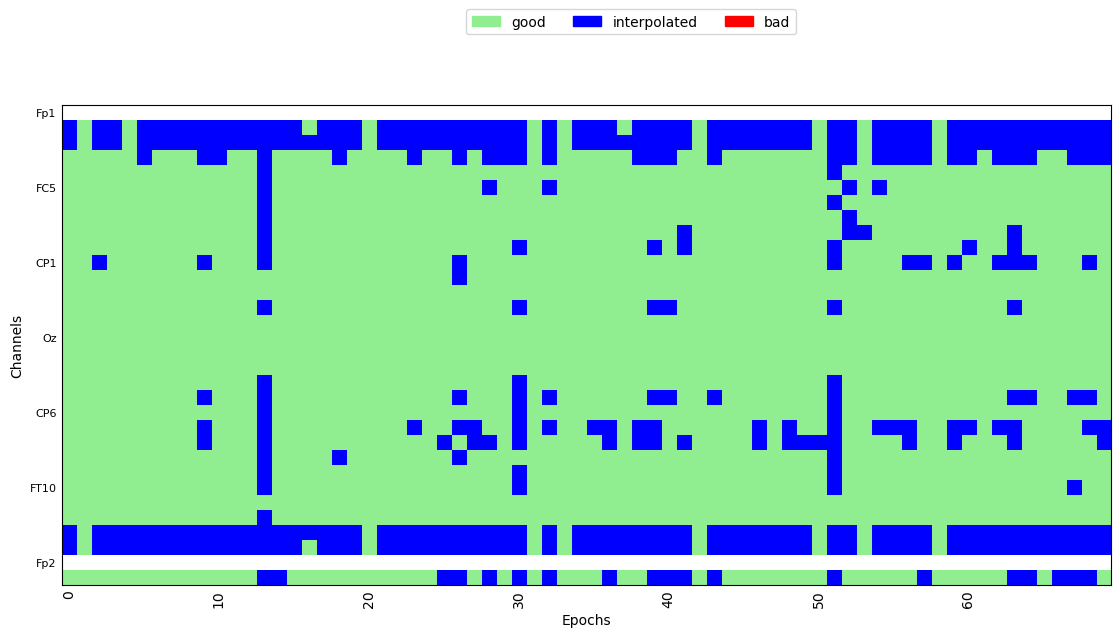

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 9, 13, 14, 19, 28, 30, 31, 40, 51, 53, 55, 57, 58, 63, 64, 68


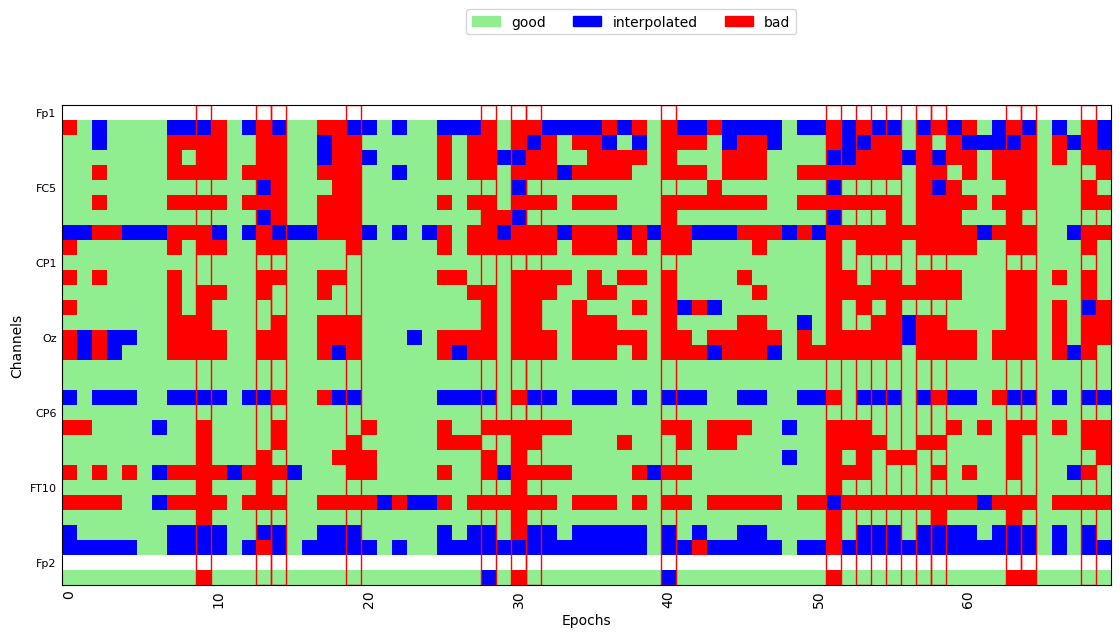

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


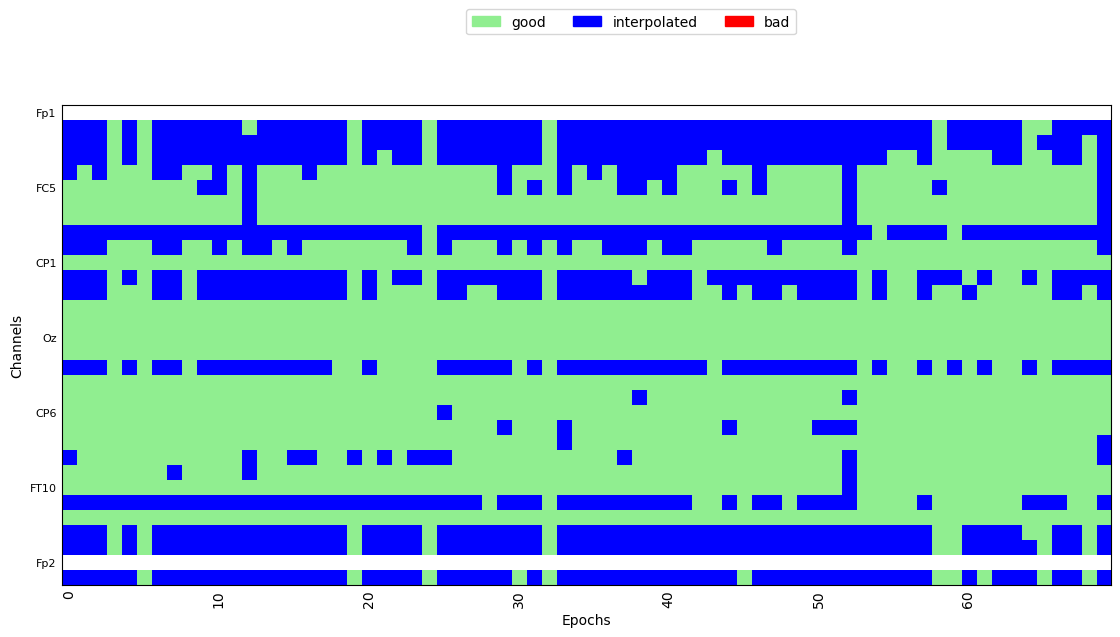

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 12, 25, 41, 52


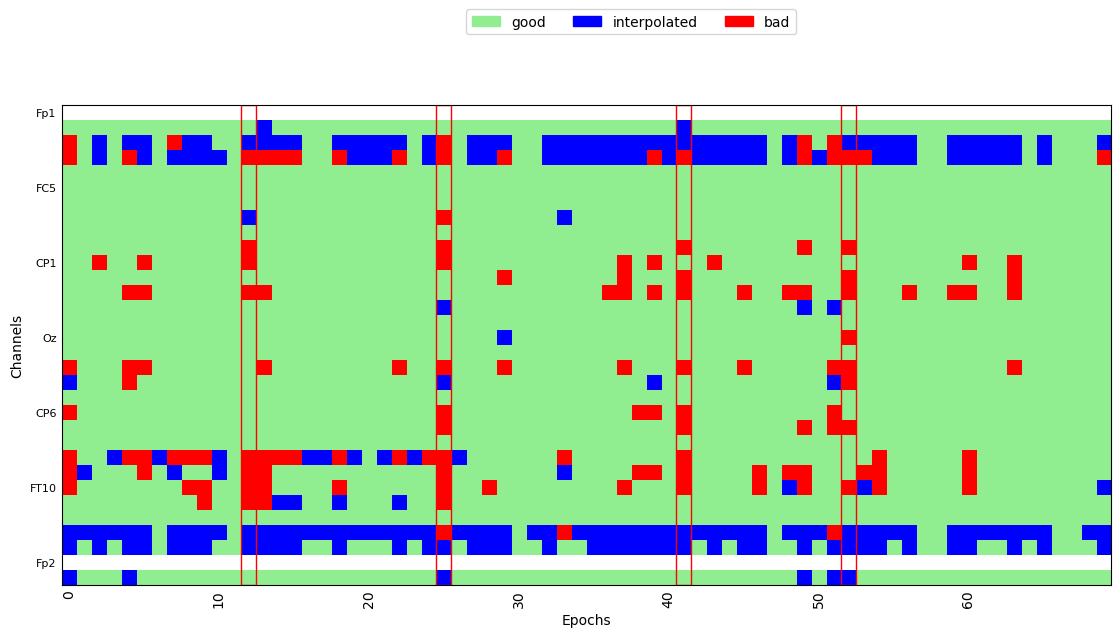

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0039_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1032639 =      0.000 ...  4130.556 secs
Ready.
Reading 0 ... 1032639  =      0.000 ...  4130.556 secs...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0039_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


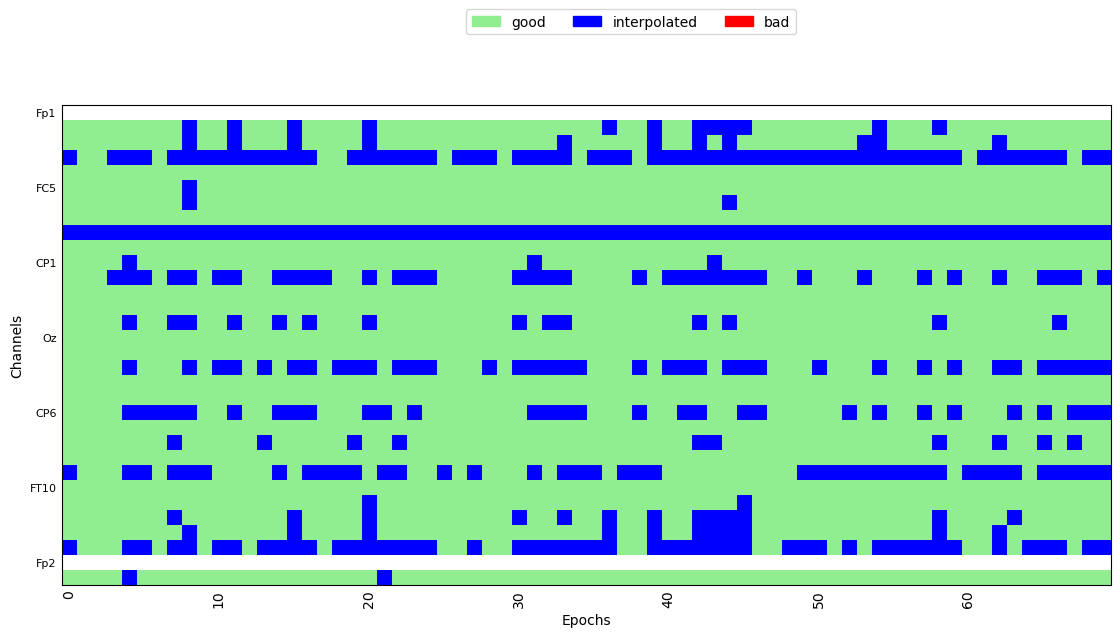

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


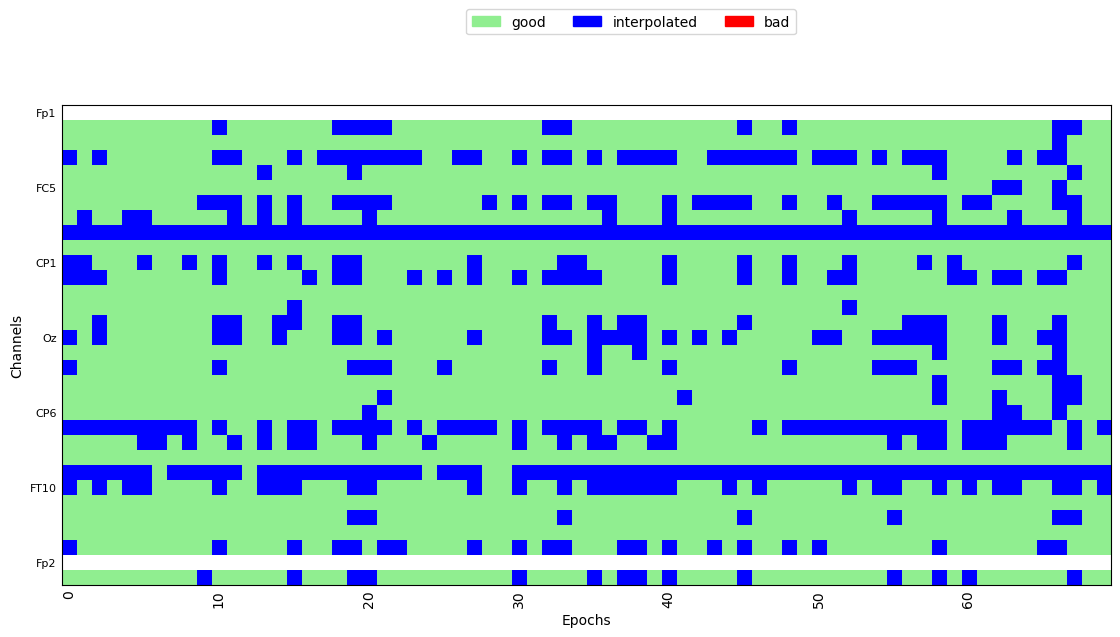

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


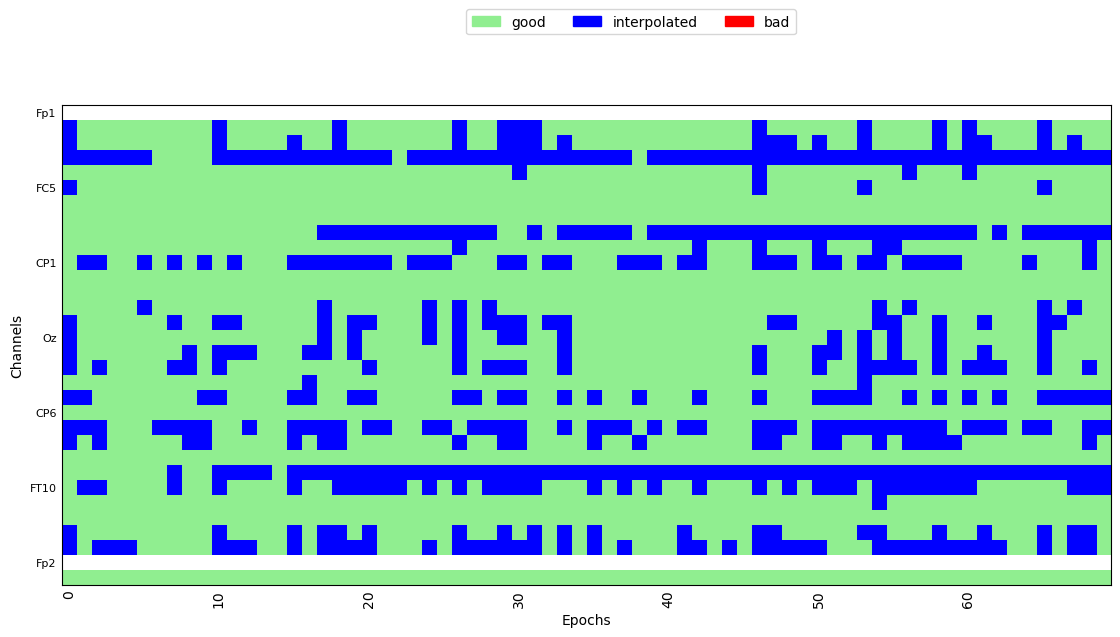

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 67


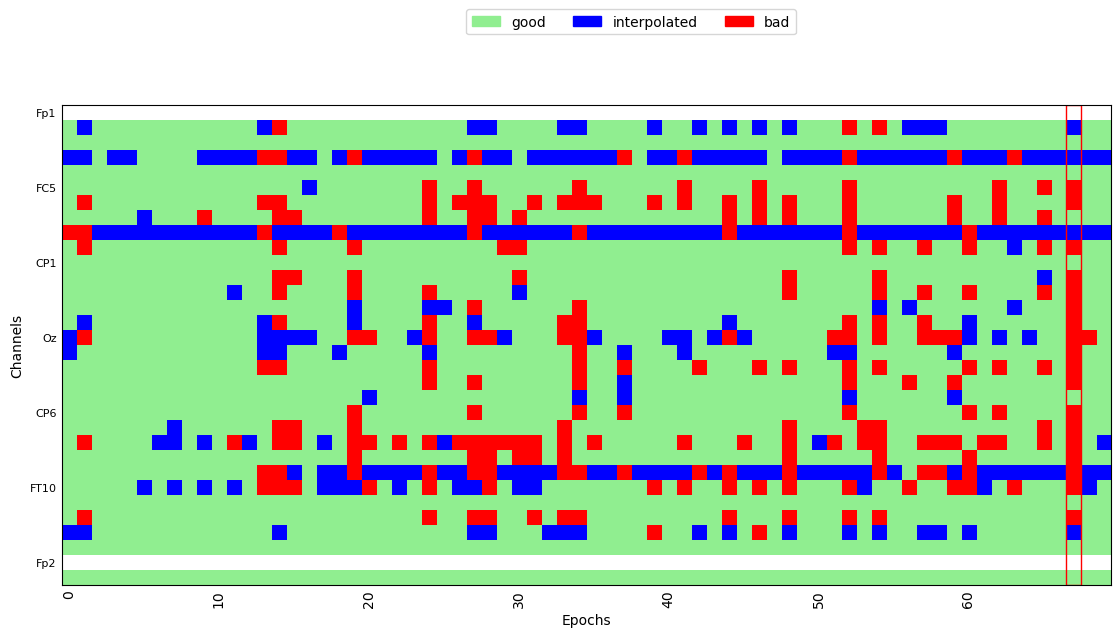

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.90 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


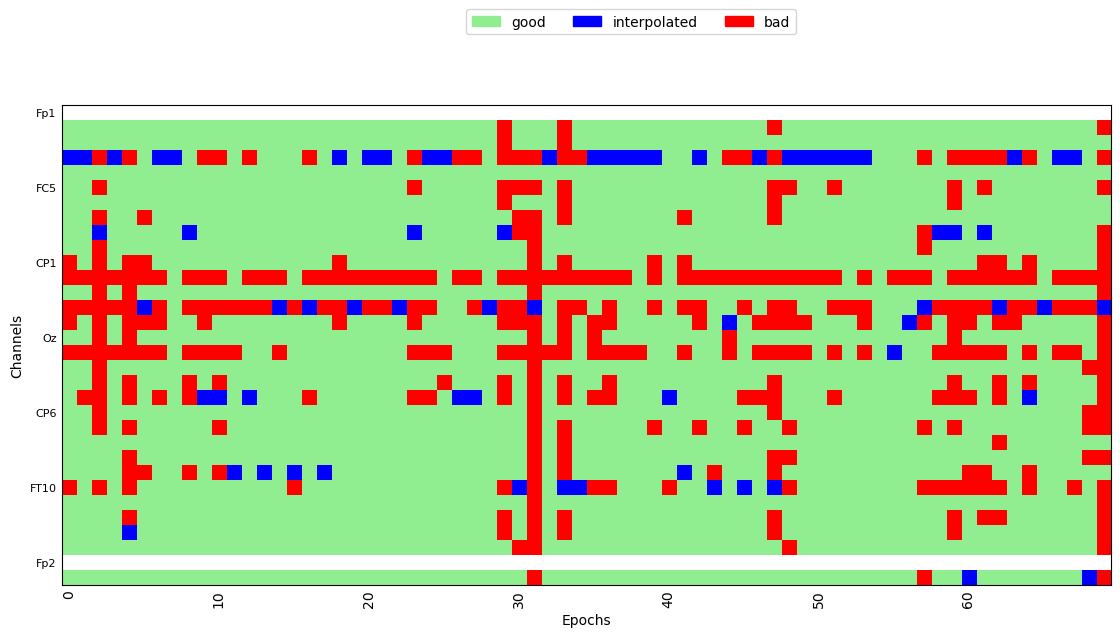

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 0, 16, 18, 20, 22, 23, 29, 32, 37, 45, 58, 59, 60, 68, 69


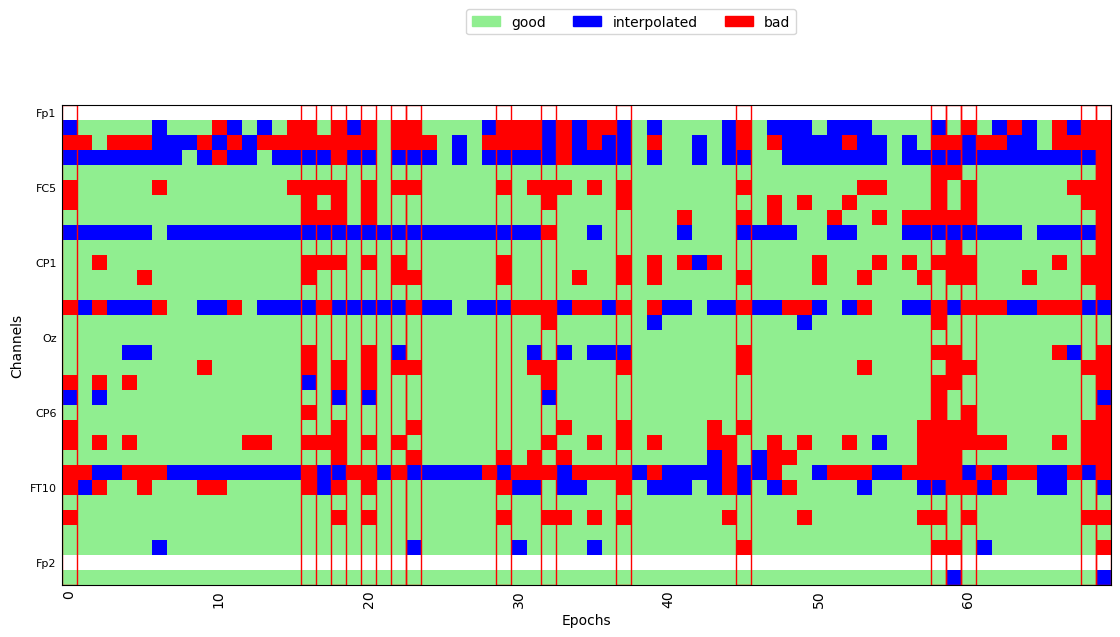

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 7, 23, 30, 43, 63


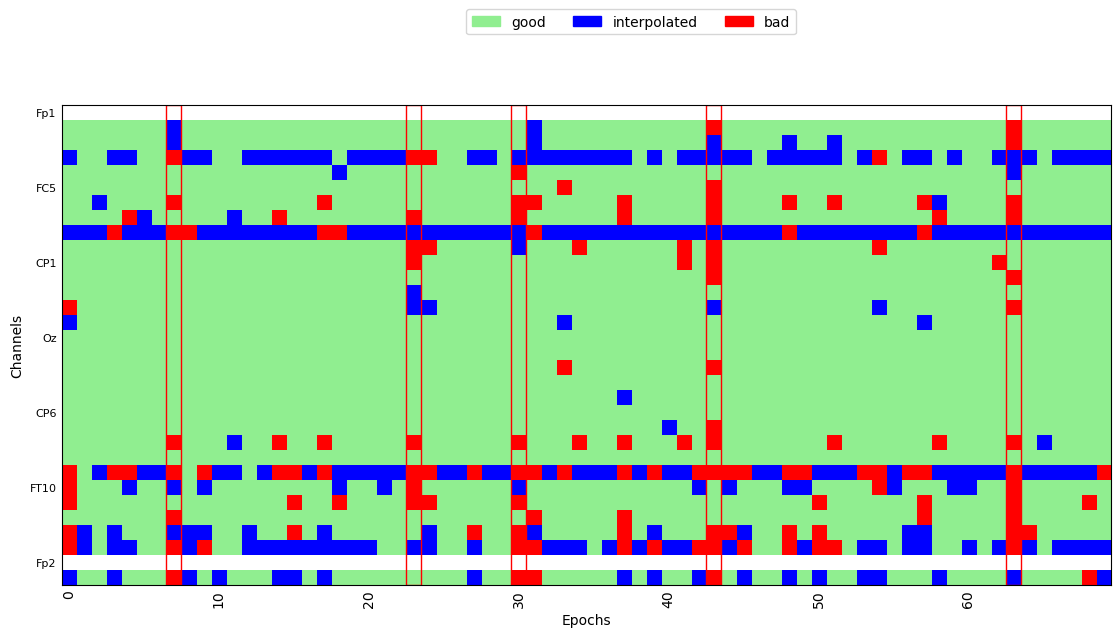

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


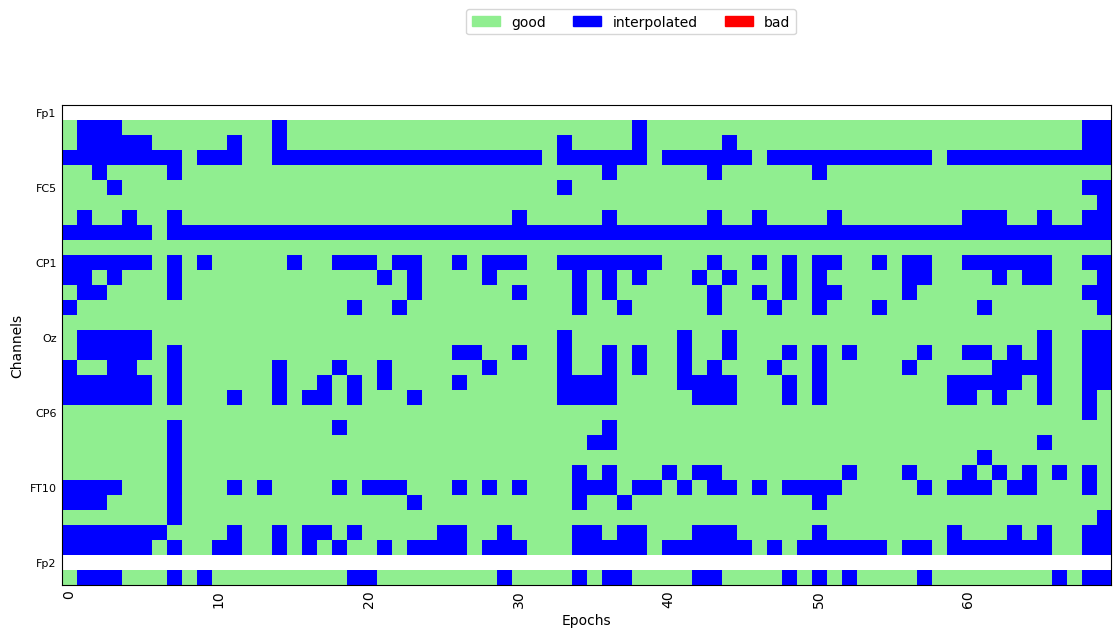

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0069_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1053019 =      0.000 ...  4212.076 secs
Ready.
Reading 0 ... 1053019  =      0.000 ...  4212.076 secs...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0069_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 13 epochs: 0, 5, 16, 22, 24, 33, 42, 43, 45, 48, 51, 60, 65


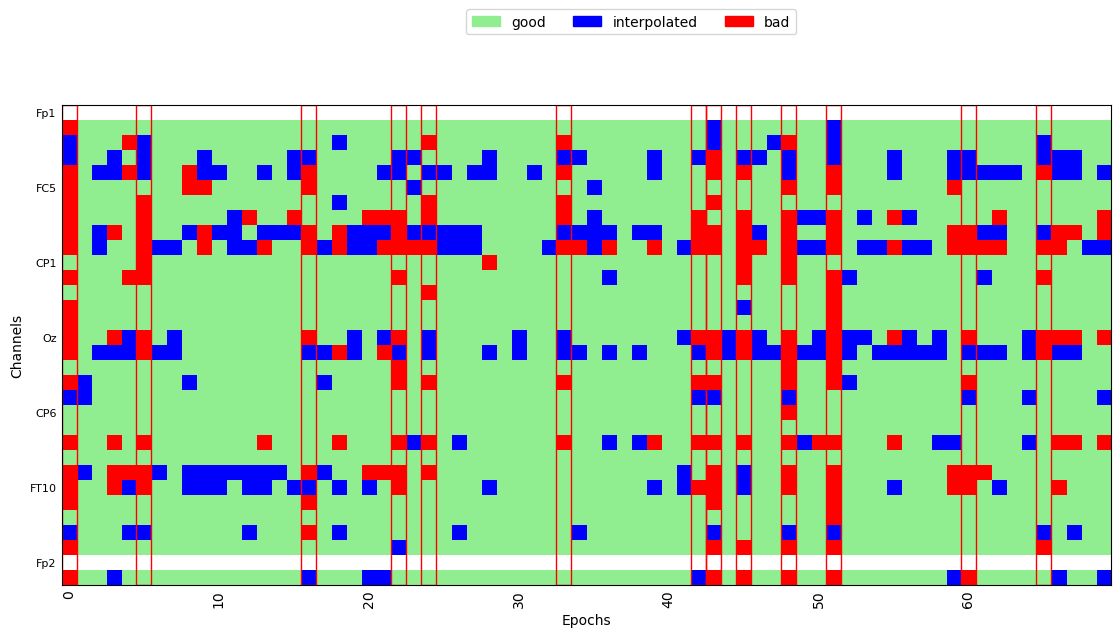

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 6, 42


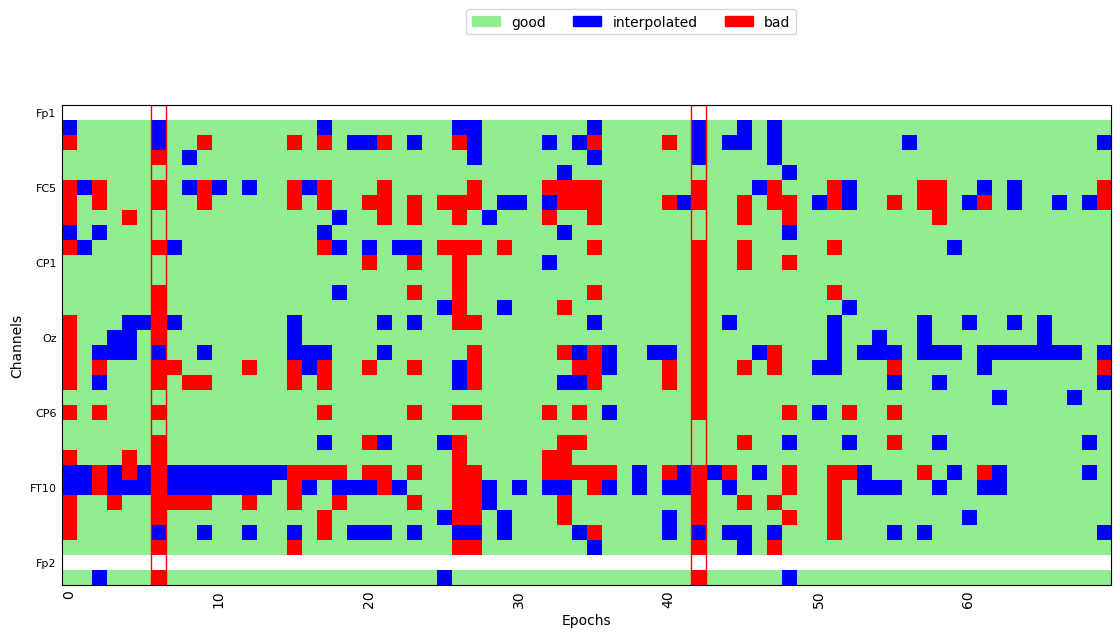

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


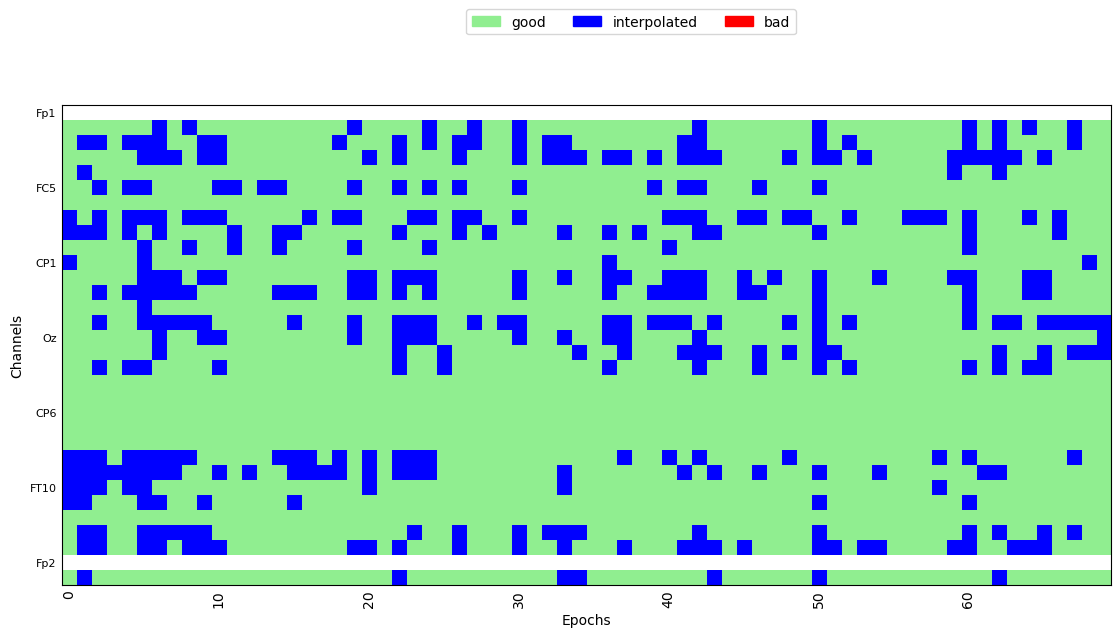

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


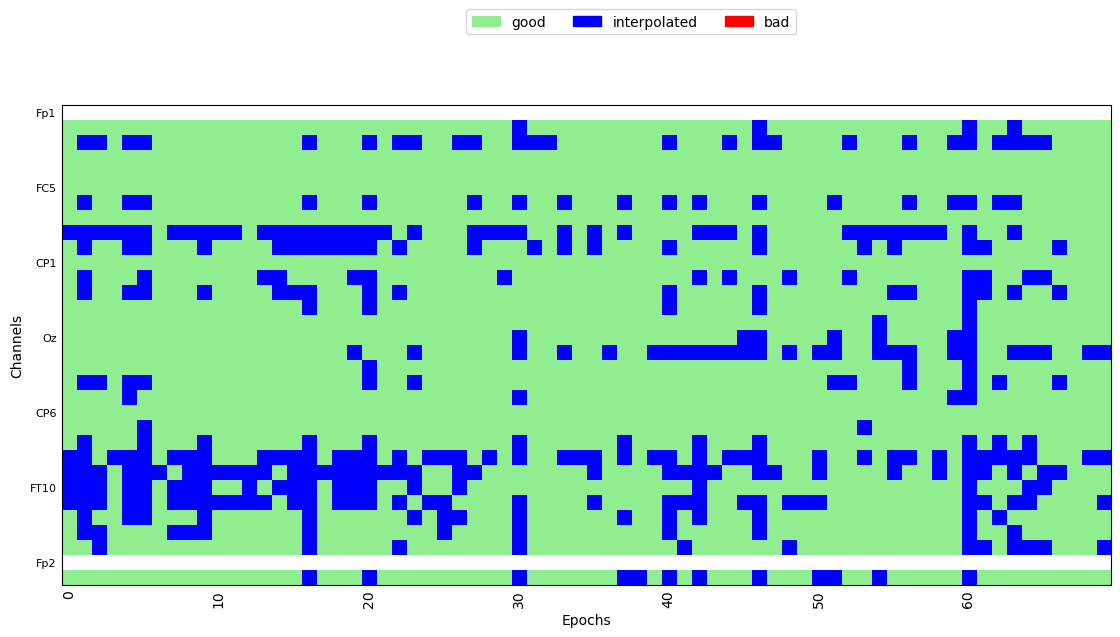

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 48, 51, 64


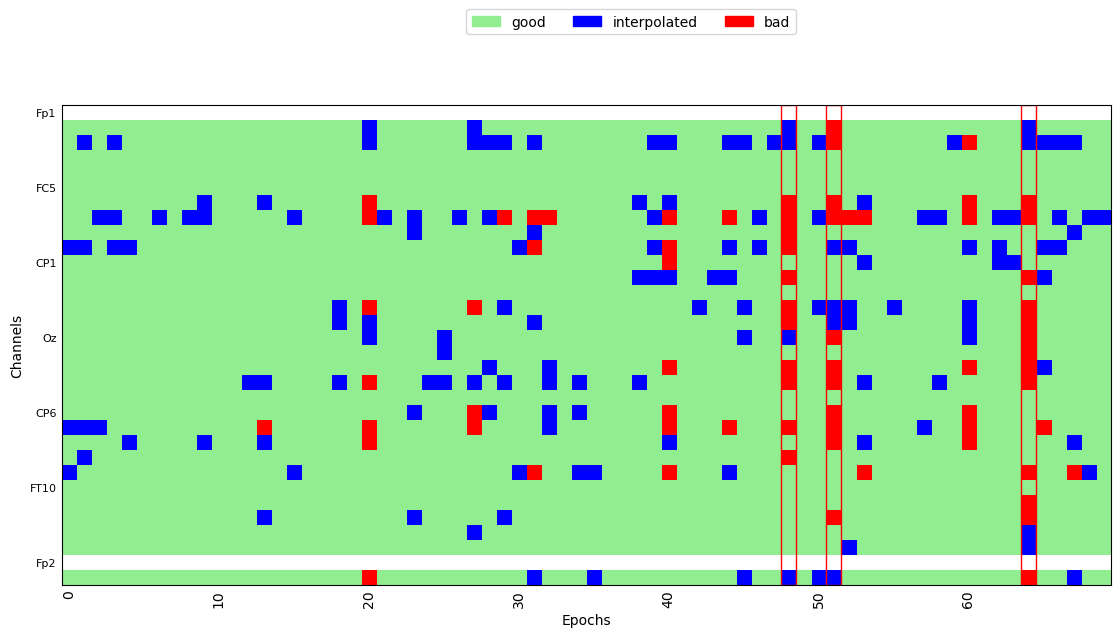

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 43, 55, 60


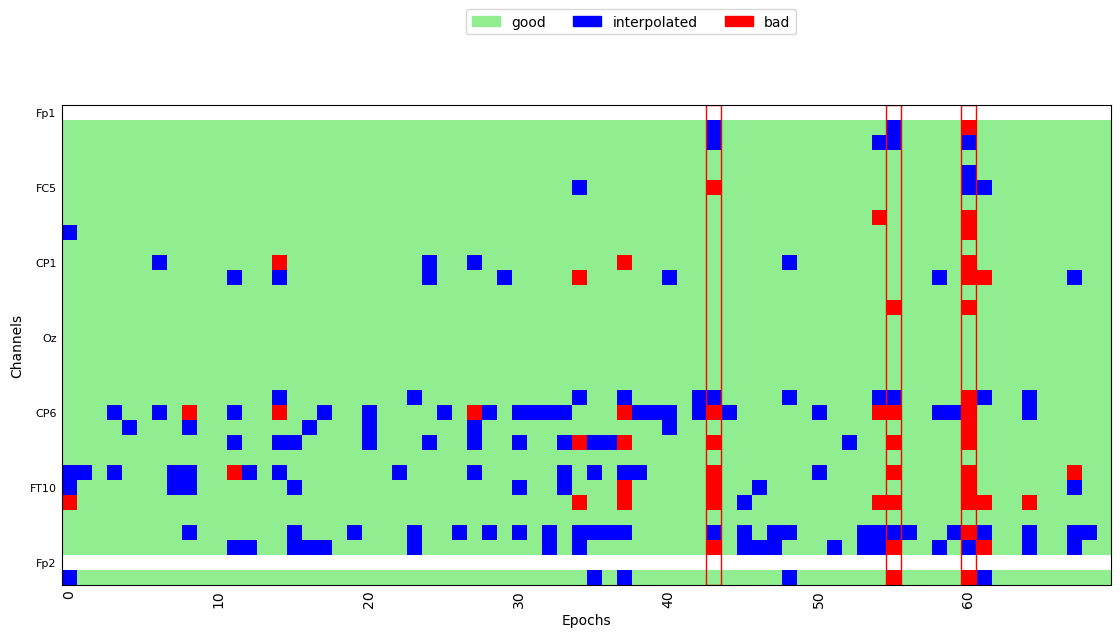

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 21, 36, 59


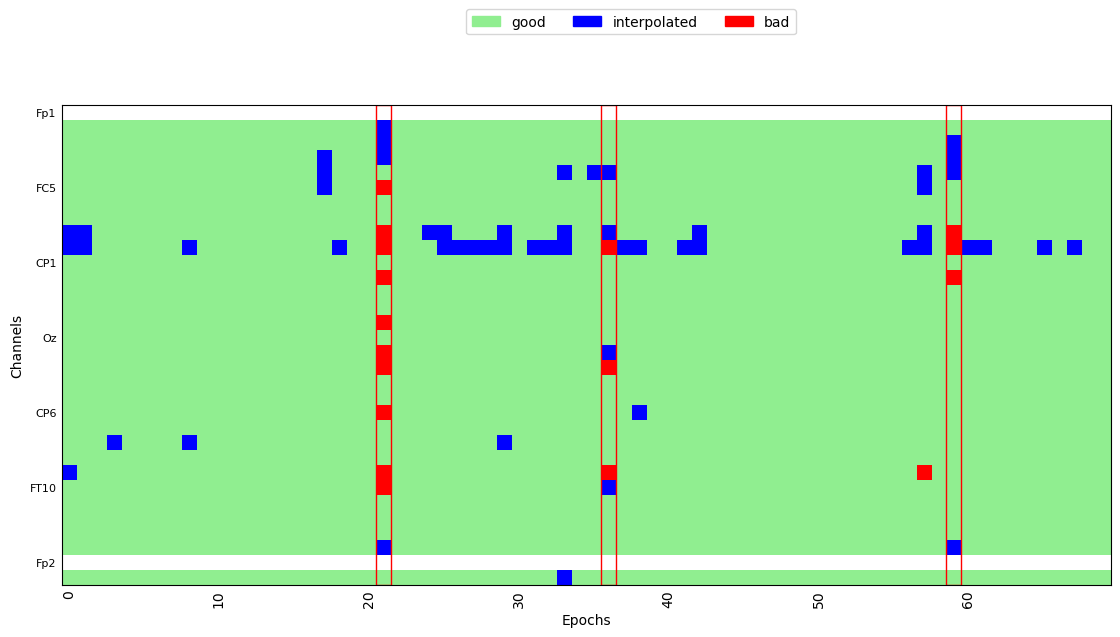

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 36, 41, 59


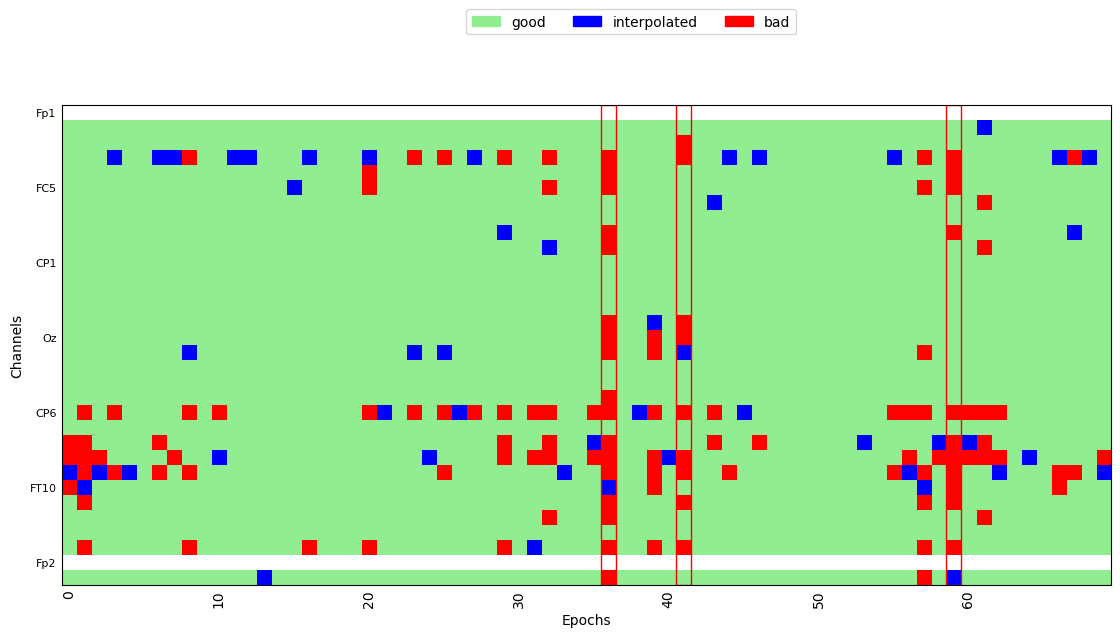

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0050_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0050_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1035504 =      0.000 ...  4142.016 secs
Ready.
Reading 0 ... 1035504  =      0.000 ...  4142.016 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 43, 46, 64, 67


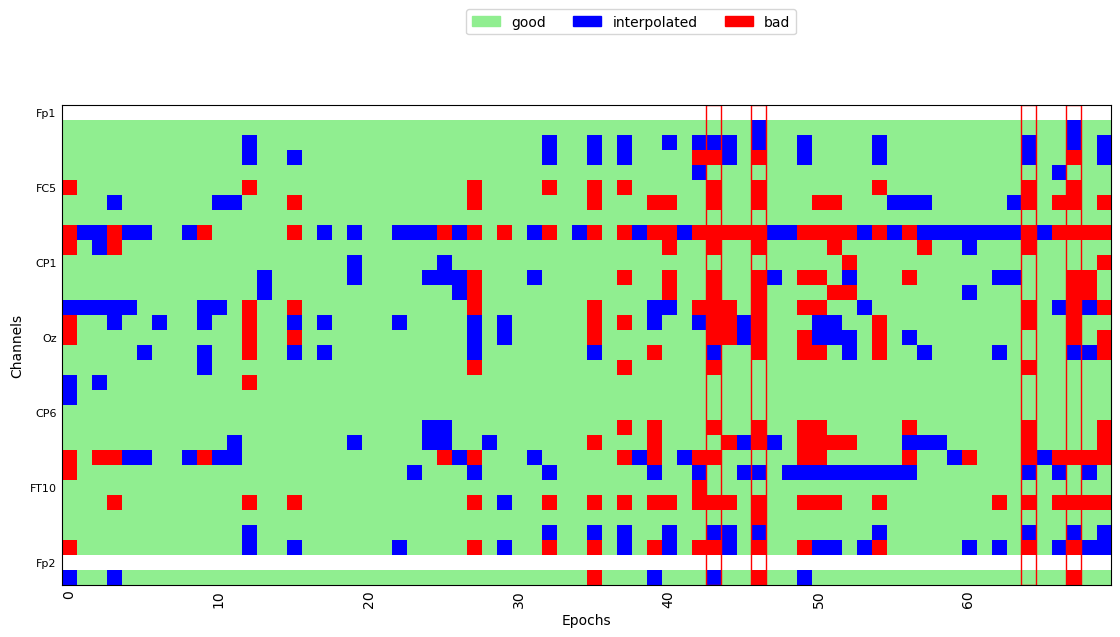

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 18, 36, 43, 68


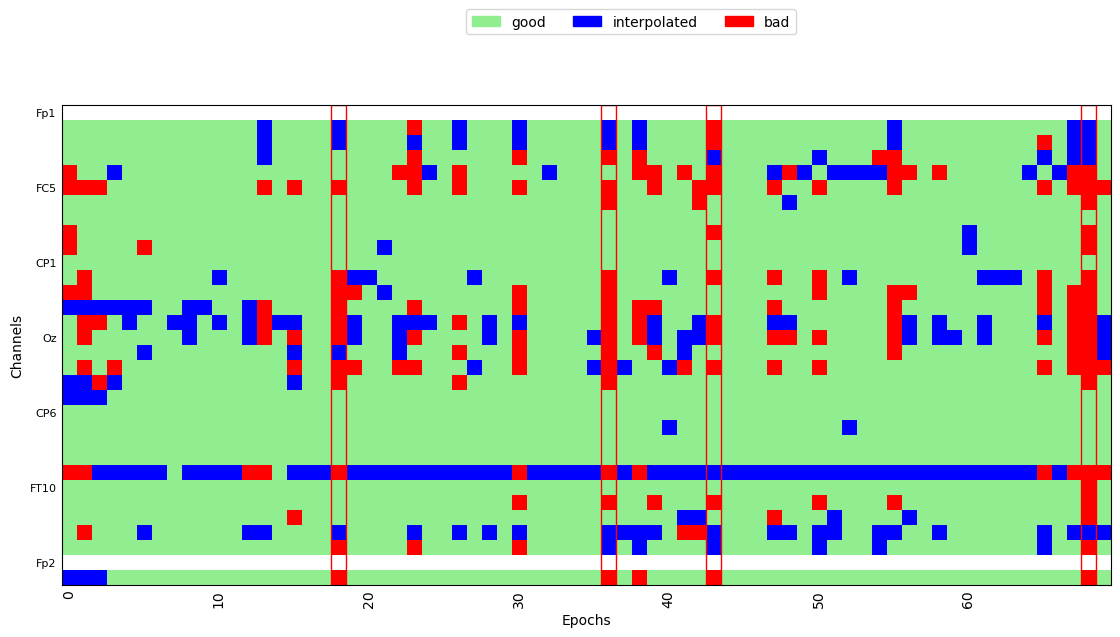

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 15, 18, 20, 23, 34, 46, 47, 49, 52, 53, 55, 56, 60, 62, 63, 64, 65, 68


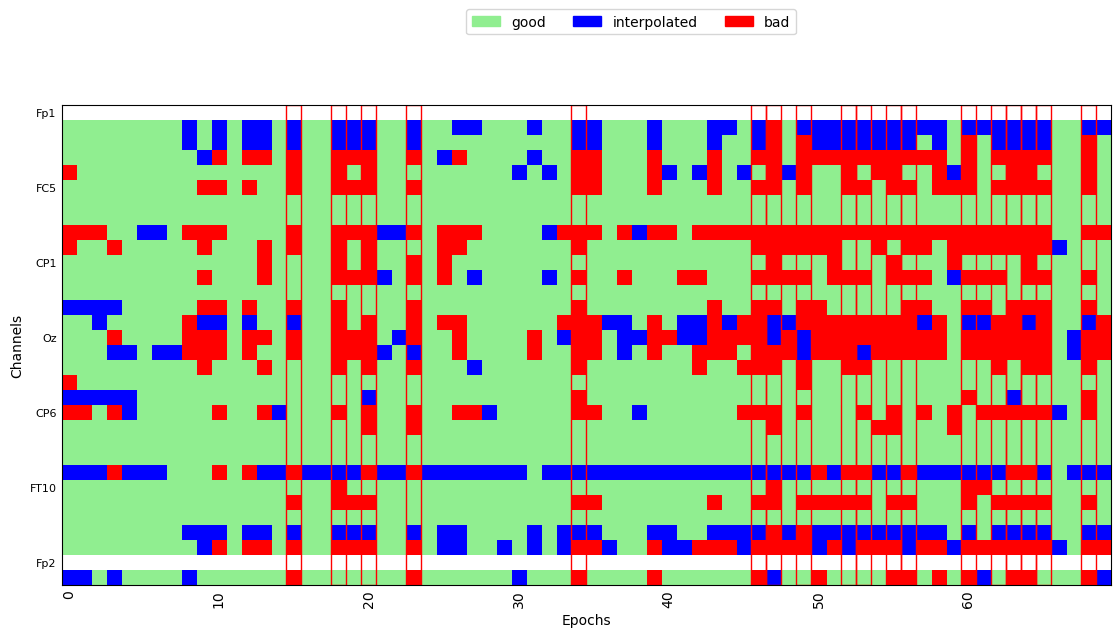

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


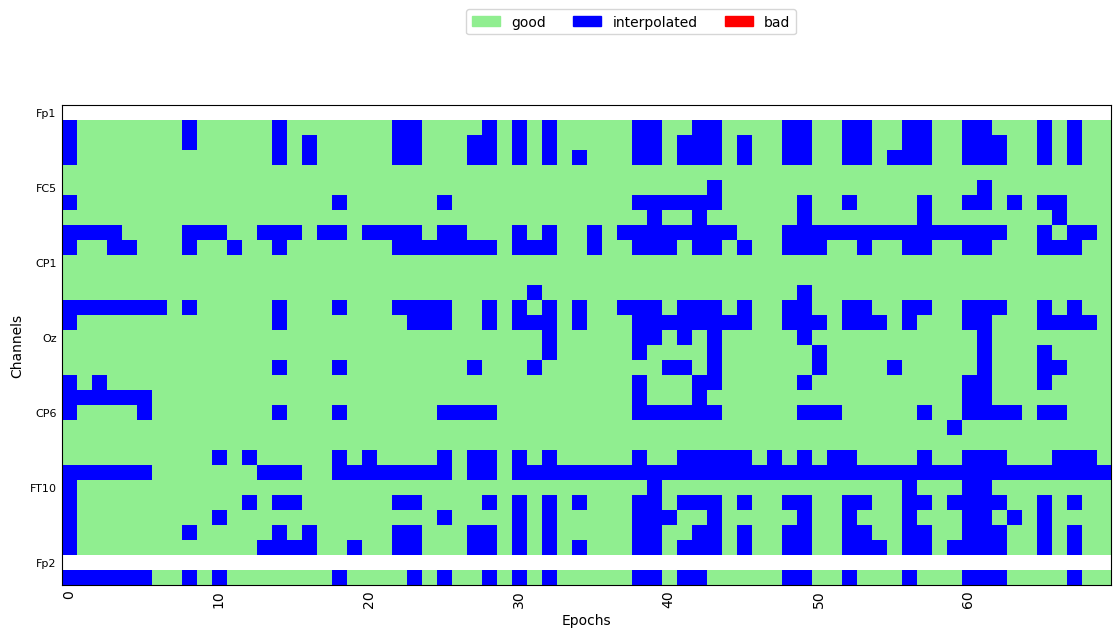

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 13 epochs: 2, 4, 10, 11, 18, 24, 38, 40, 48, 52, 54, 60, 67


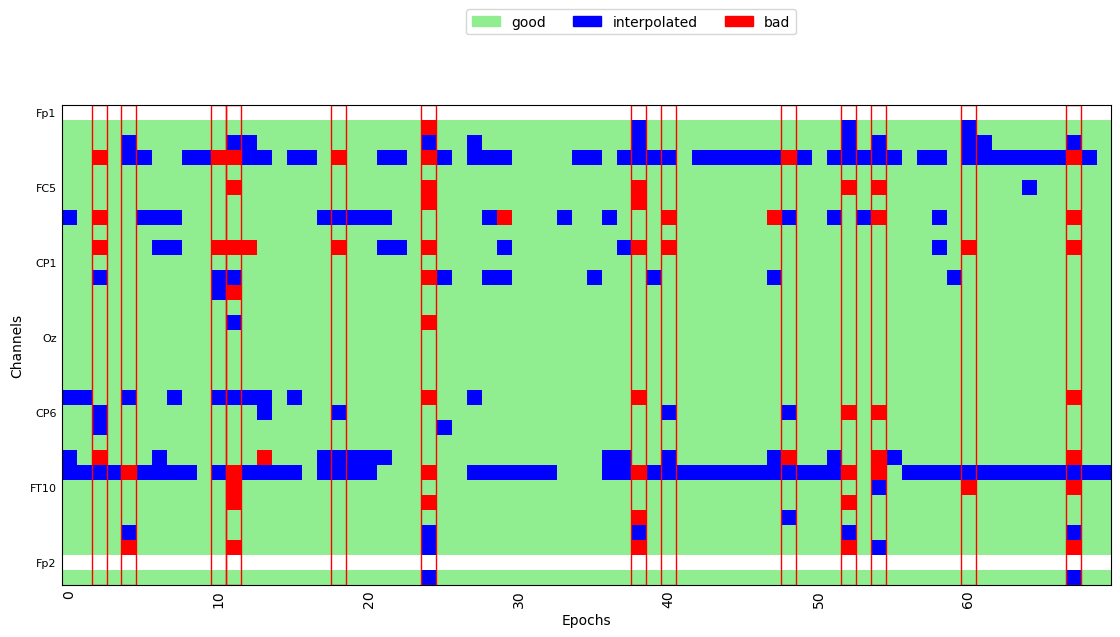

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


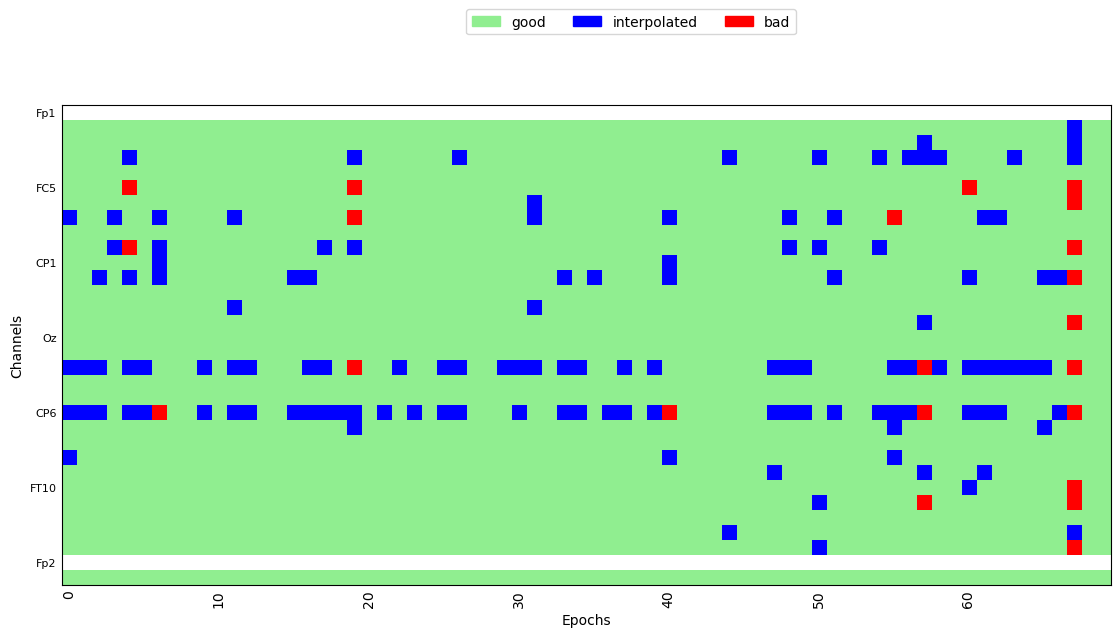

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 17, 36, 41, 45, 48, 52, 54, 63, 66, 67


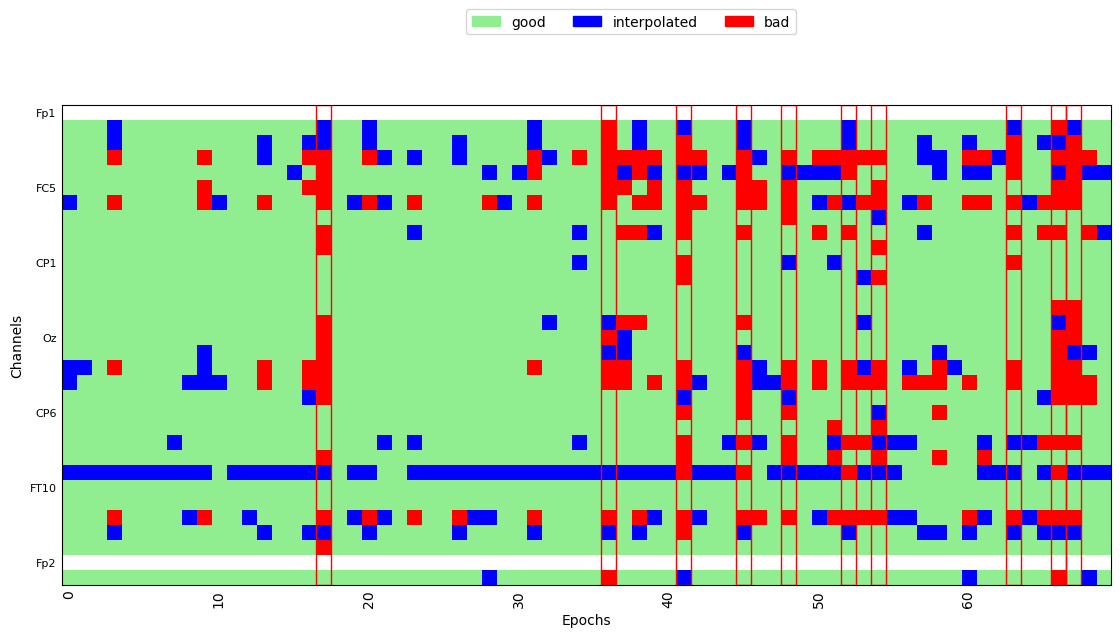

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 9, 12, 15, 25, 28, 30, 36, 37, 39, 40, 43, 50, 54, 63, 64


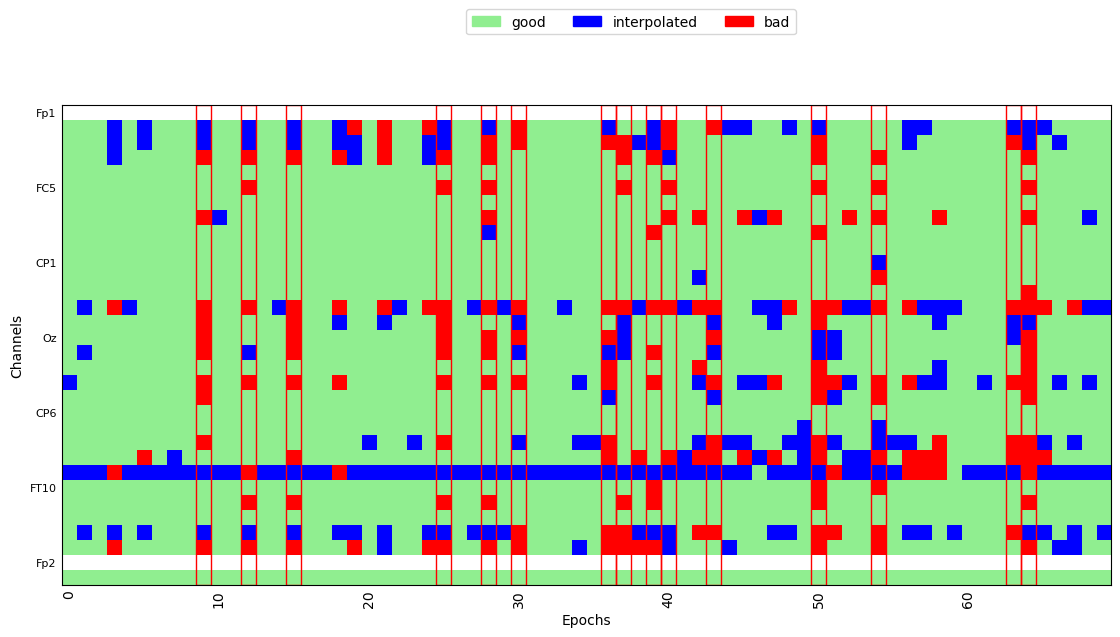

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0041_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0041_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1051579 =      0.000 ...  4206.316 secs
Ready.
Reading 0 ... 1051579  =      0.000 ...  4206.316 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 10, 26, 68


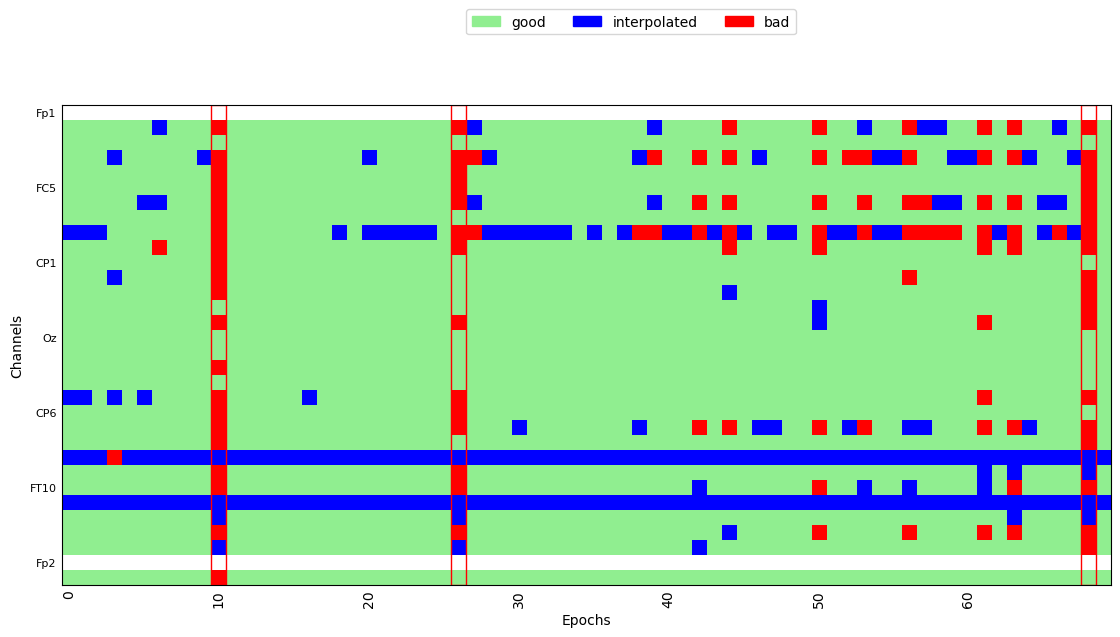

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 6, 42, 44, 45, 50, 53, 55, 56, 58, 62, 68


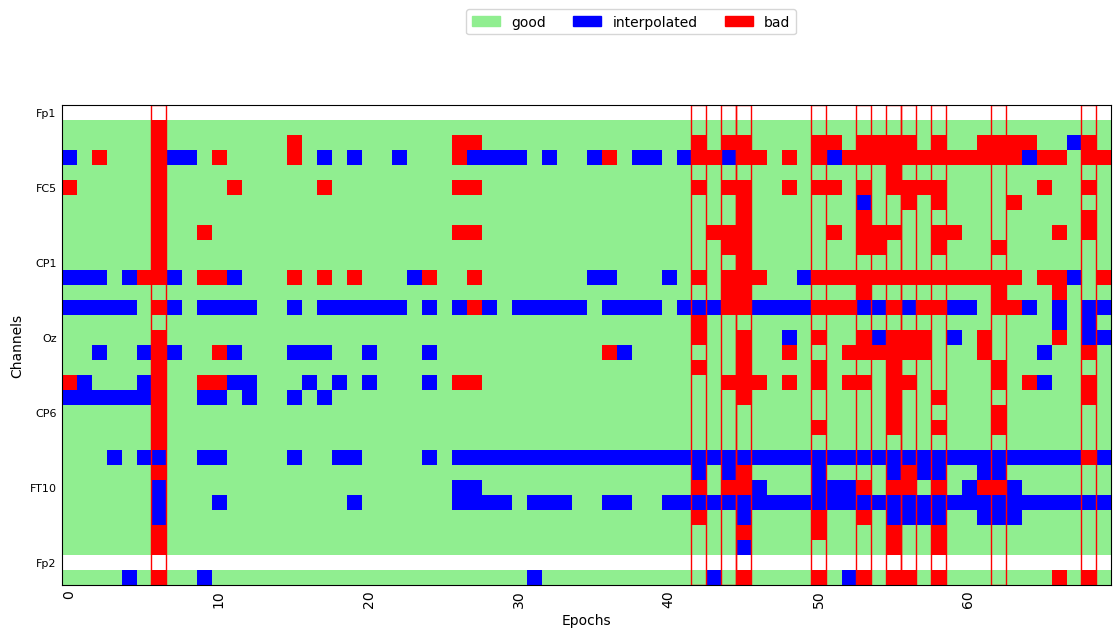

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 14, 22, 26, 27, 41, 51, 56, 58, 59


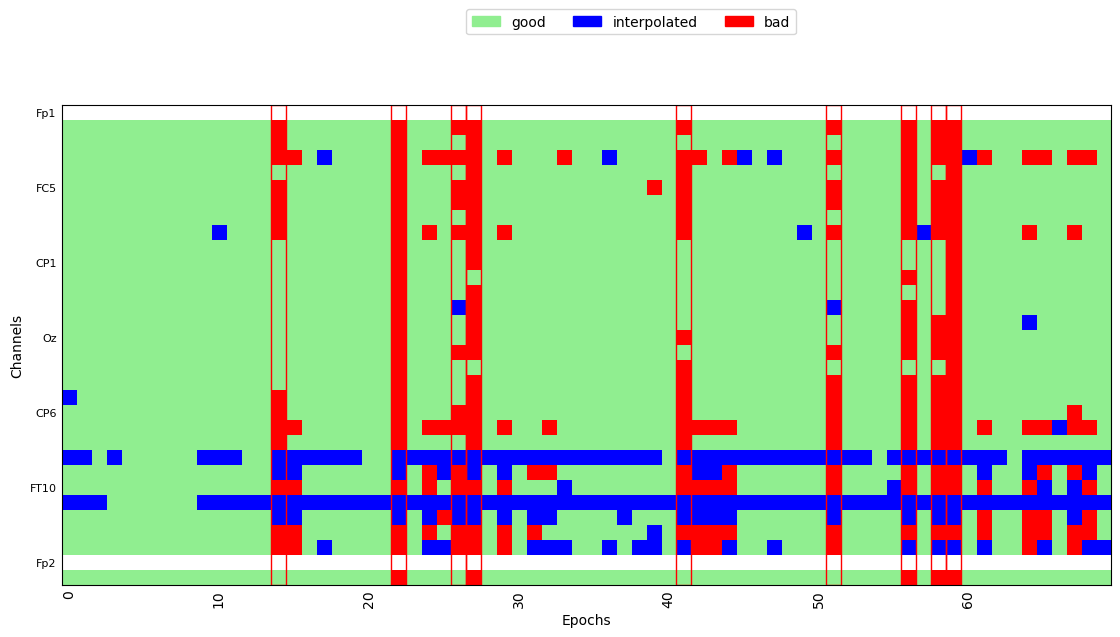

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 22, 26, 27, 41, 51, 55, 56, 58, 60


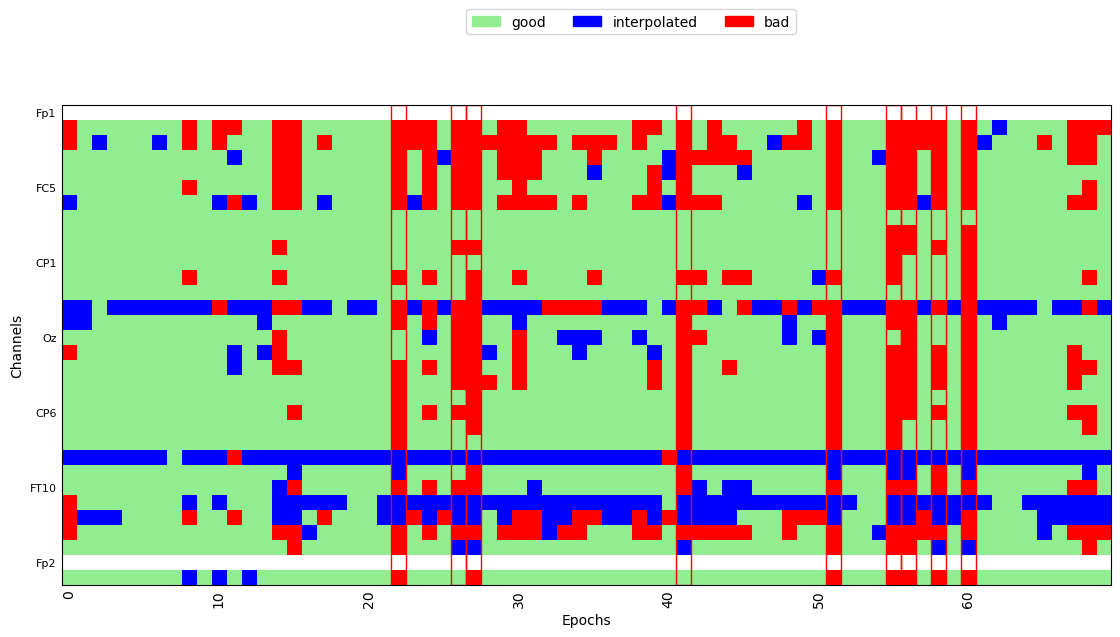

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 8


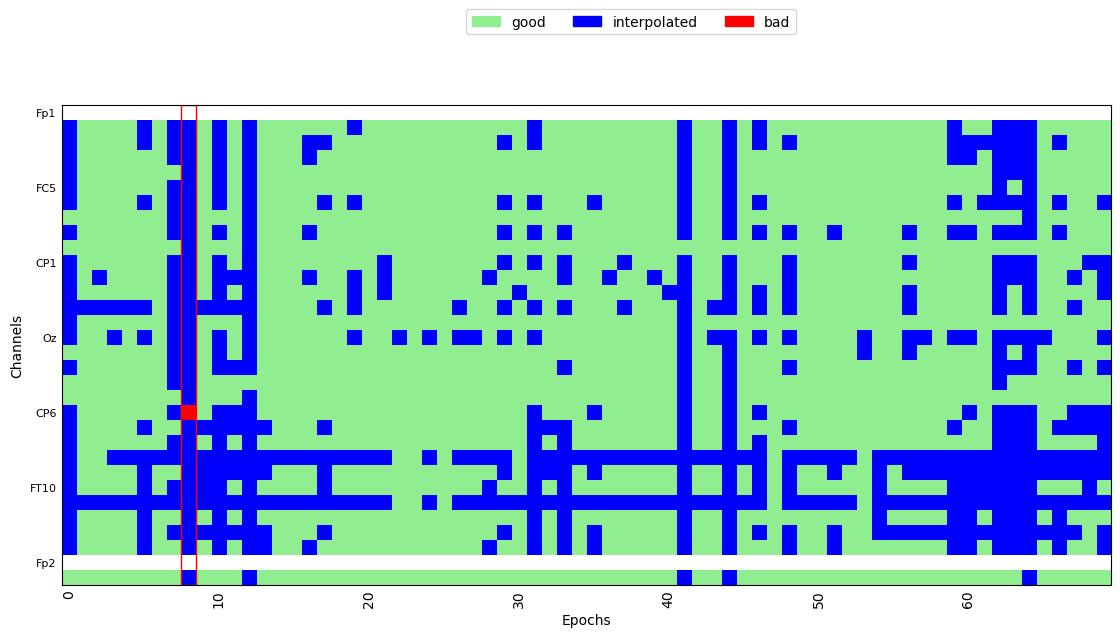

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 8 epochs: 0, 1, 8, 12, 35, 46, 62, 63


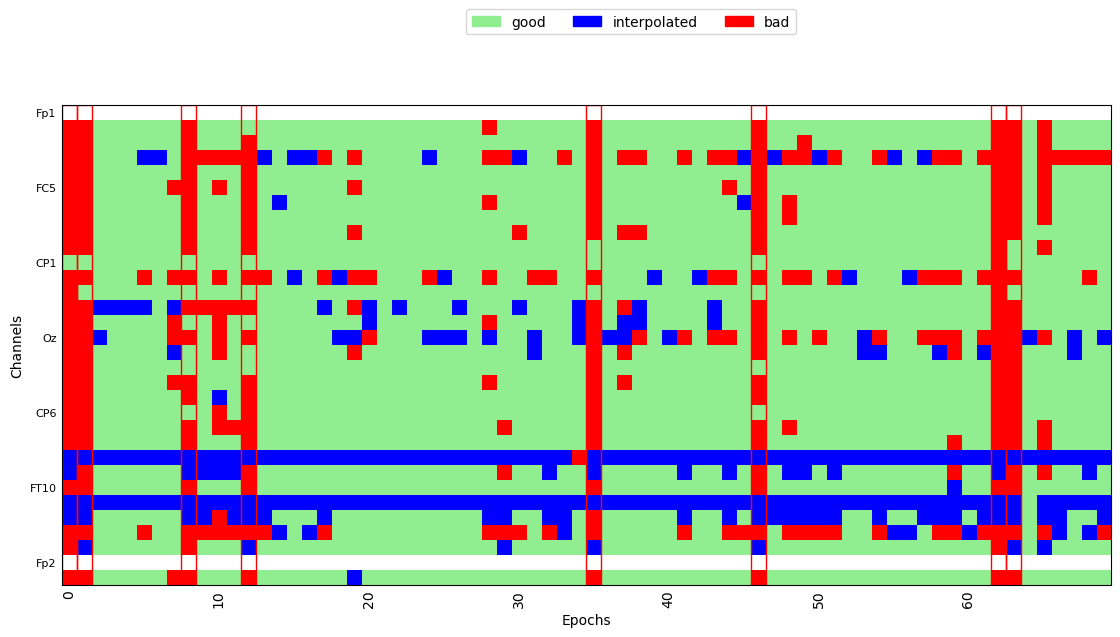

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 10, 14, 19, 42, 63


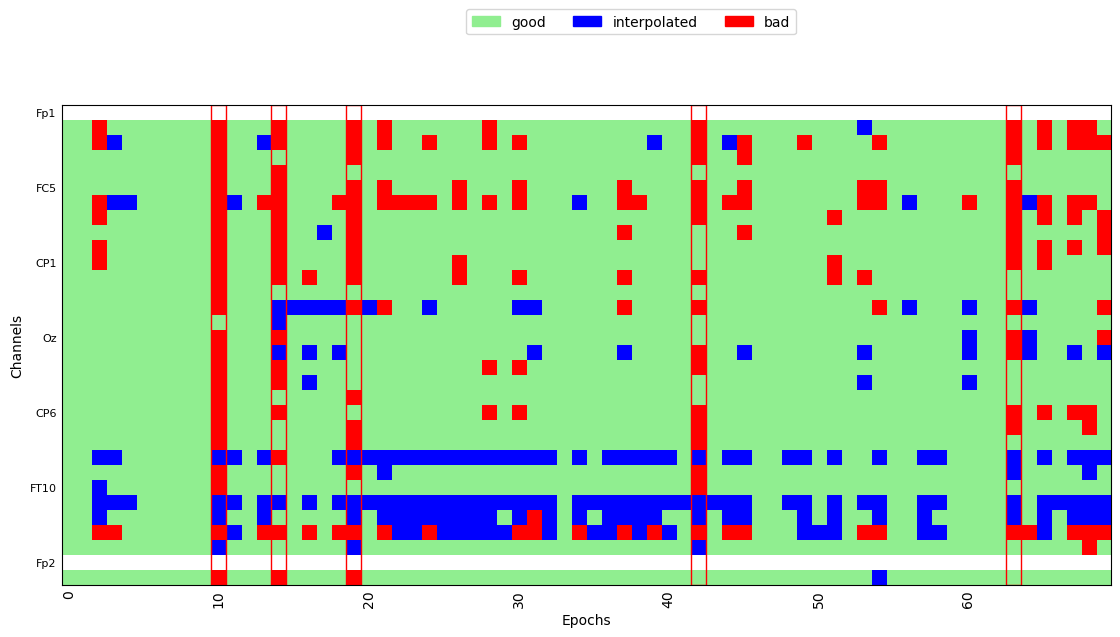

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 10, 14, 18, 19, 45


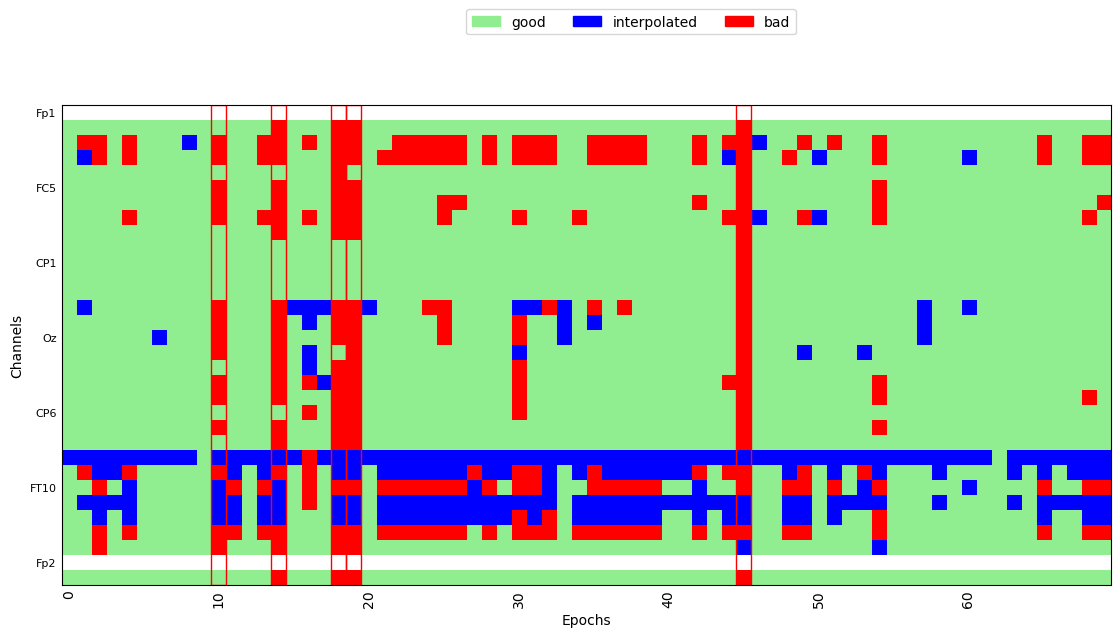

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0062_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1048569 =      0.000 ...  4194.276 secs
Ready.


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0062_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1048569  =      0.000 ...  4194.276 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 8, 14, 18, 19, 20, 21, 33, 39, 48, 51, 52, 55, 56, 59, 64


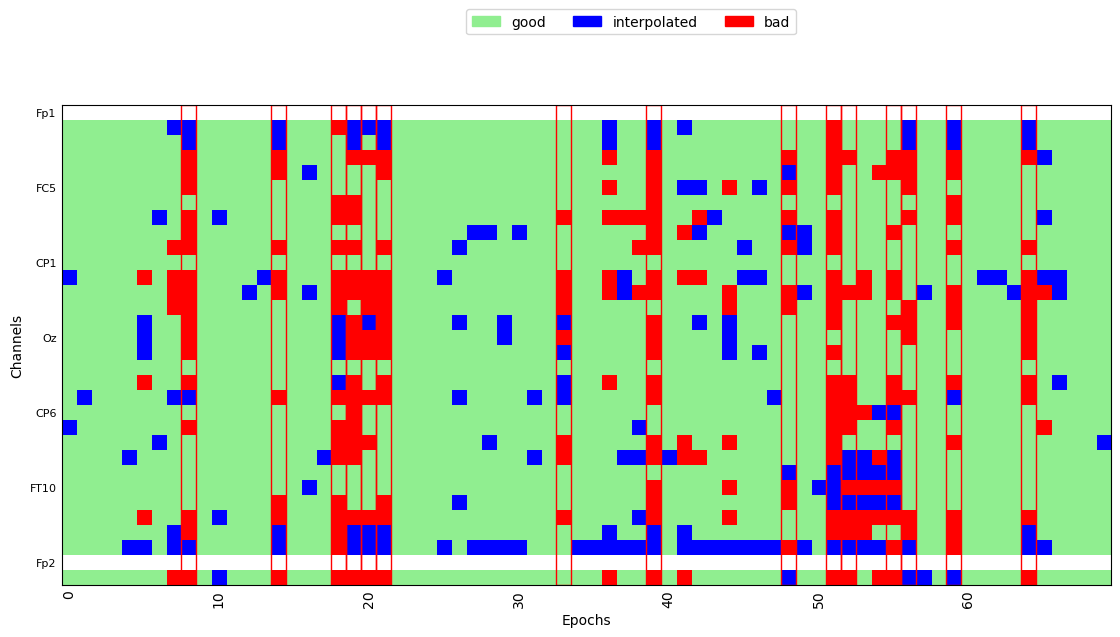

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 18, 48, 51, 52


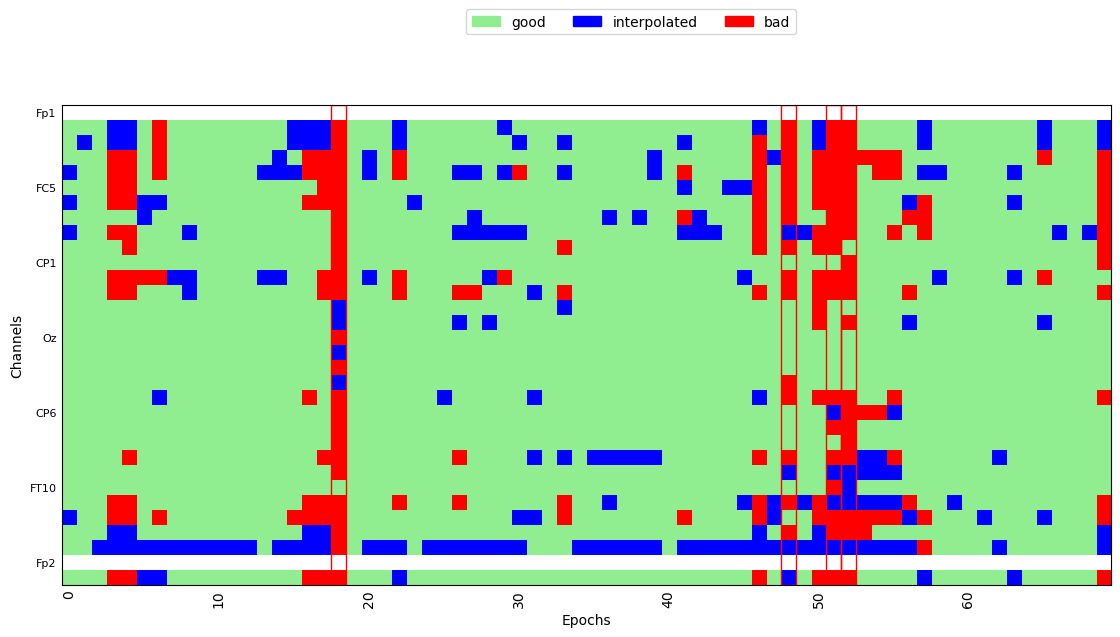

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 23 epochs: 0, 5, 6, 10, 11, 15, 24, 25, 26, 27, 28, 31, 35, 41, 55, 56, 58, 61, 62, 64, 67, 68, 69


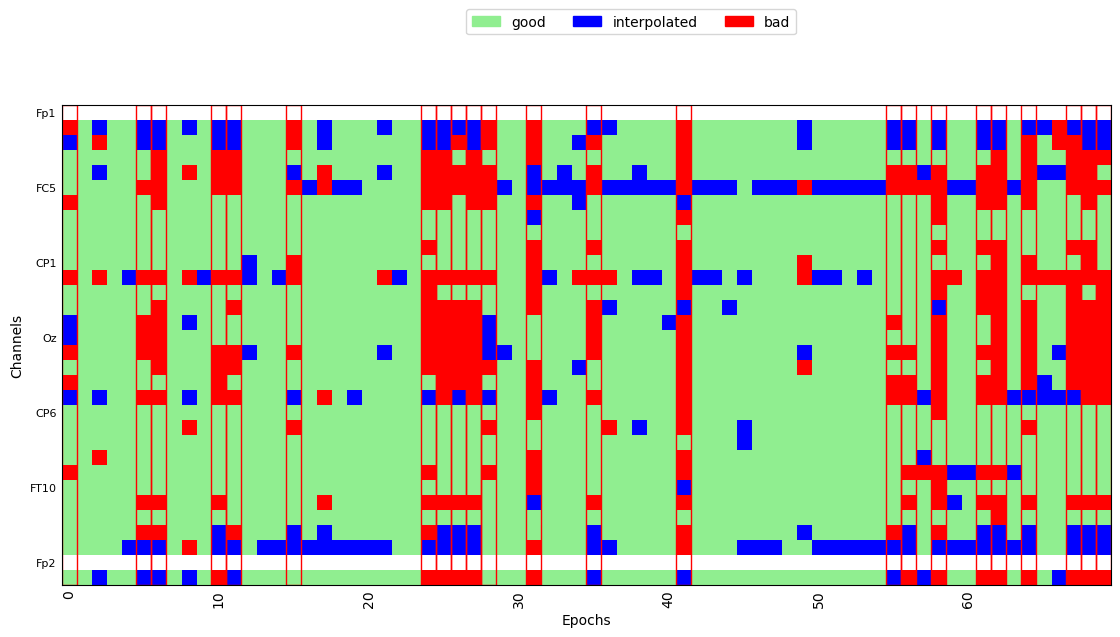

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 17 epochs: 4, 8, 18, 22, 28, 31, 33, 41, 45, 50, 54, 56, 57, 58, 61, 62, 65


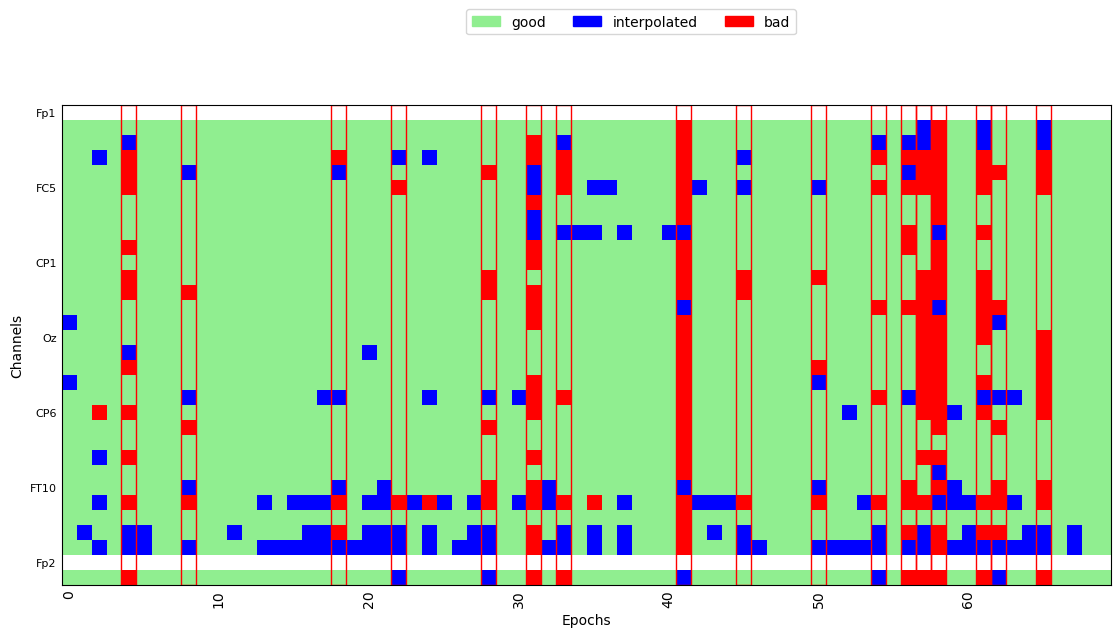

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 3, 4, 8, 9, 16, 19, 20, 39, 40, 41, 49, 56, 58, 59, 64, 69


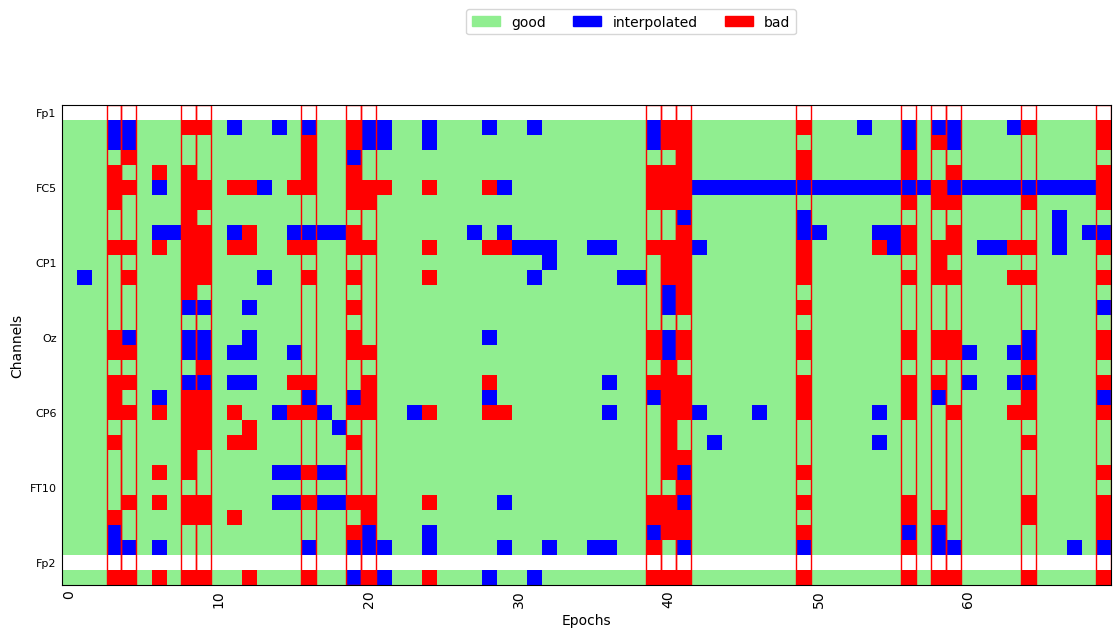

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 1, 8, 9, 15, 21, 31, 34, 40, 52, 64, 69


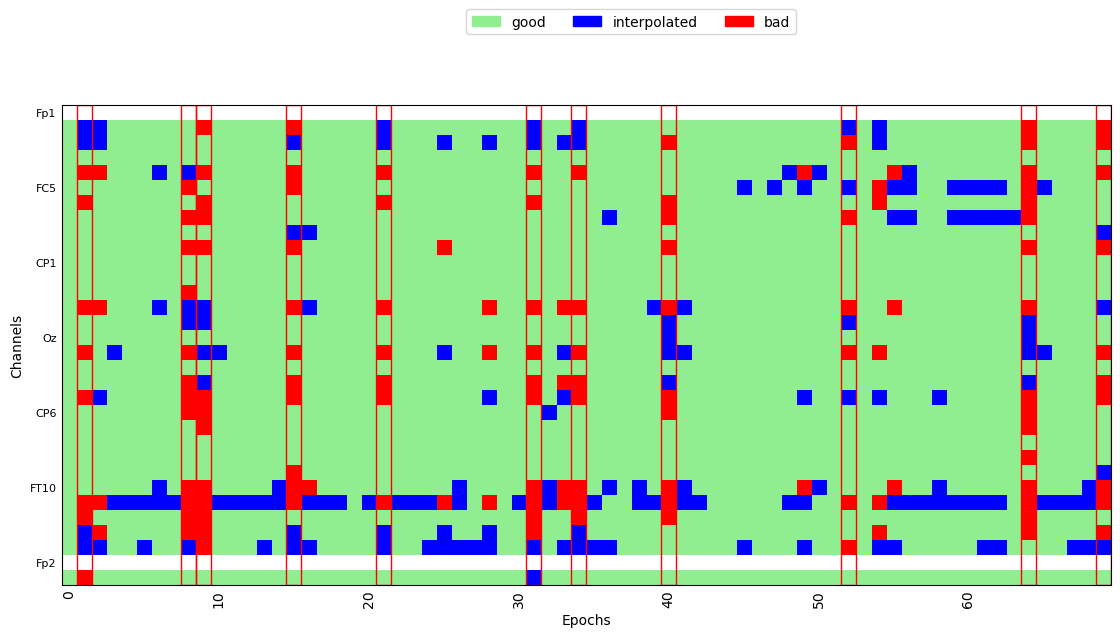

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 14 epochs: 2, 17, 25, 32, 34, 35, 36, 38, 45, 47, 51, 52, 63, 68


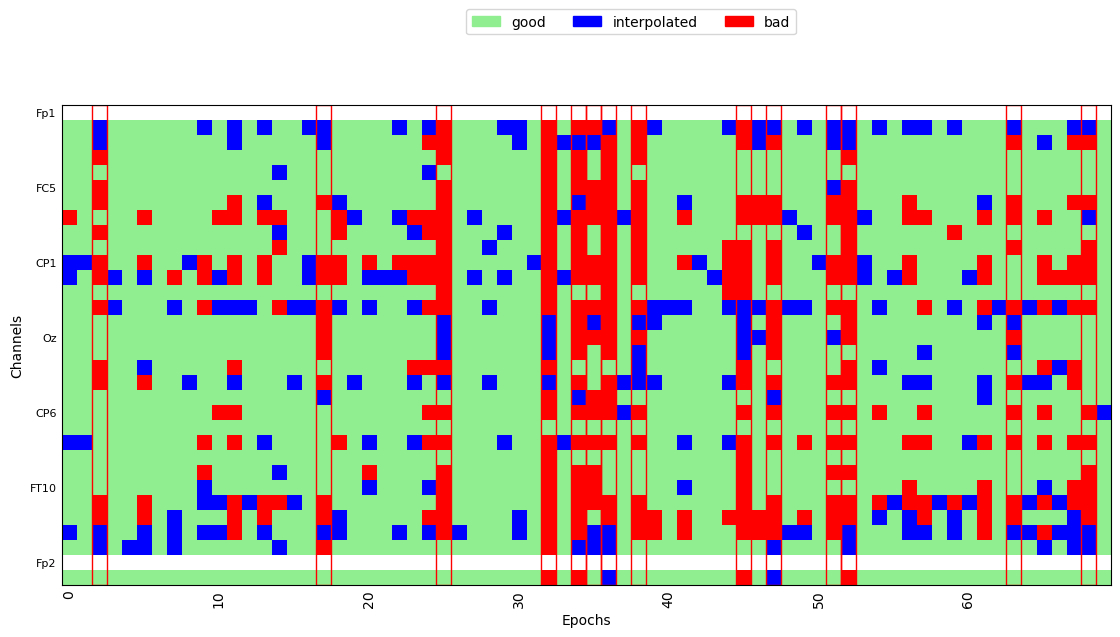

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


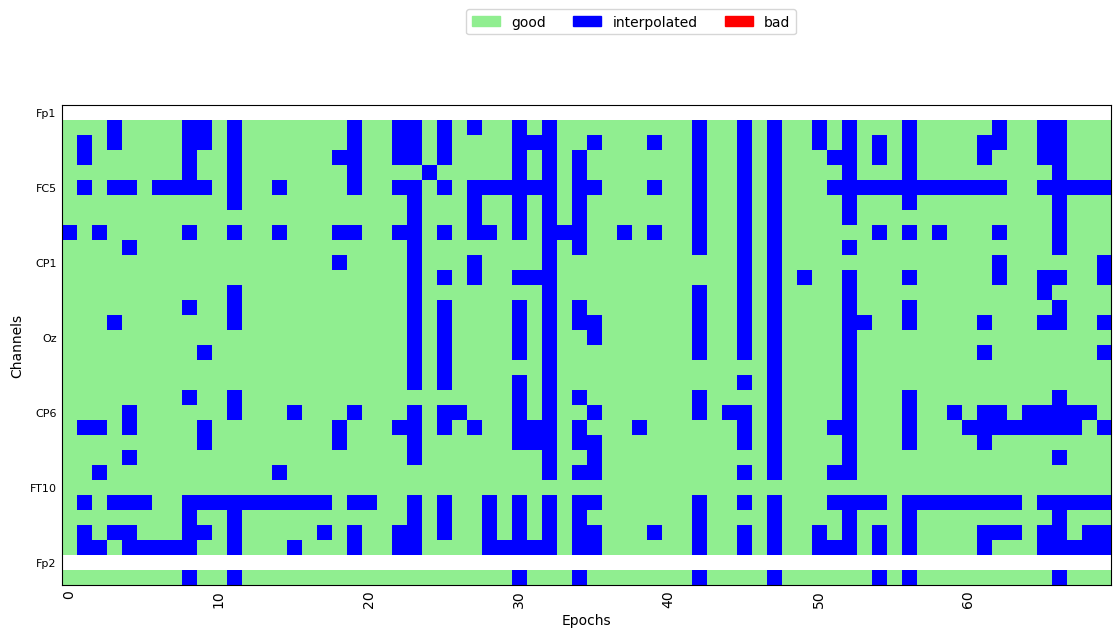

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0021_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1049609 =      0.000 ...  4198.436 secs
Ready.
Reading 0 ... 1049609  =      0.000 ...  4198.436 secs...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0021_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 22 epochs: 0, 1, 2, 3, 9, 10, 11, 15, 17, 18, 22, 27, 31, 36, 40, 46, 53, 54, 55, 56, 59, 61


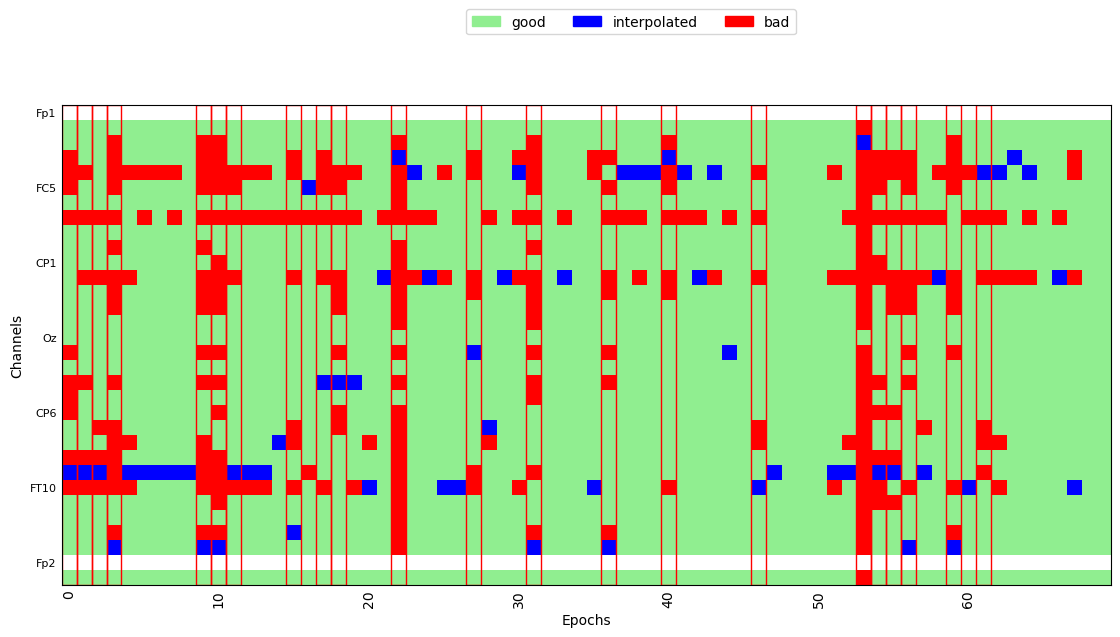

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 10, 18, 20, 22, 23, 38, 53, 54, 66


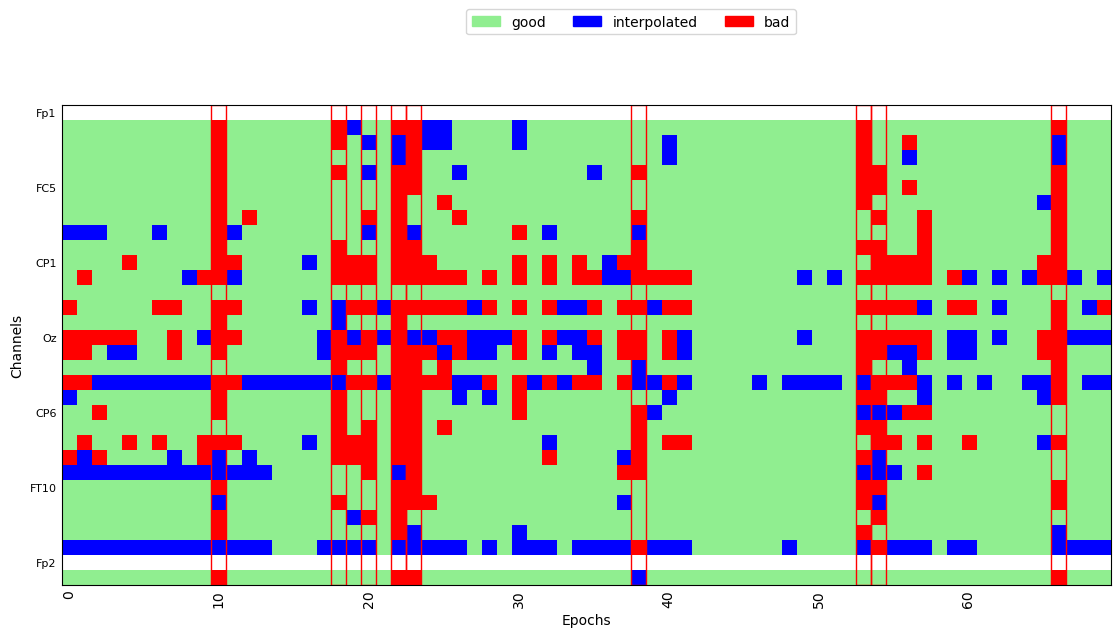

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 17, 29, 31, 36, 42, 49, 50


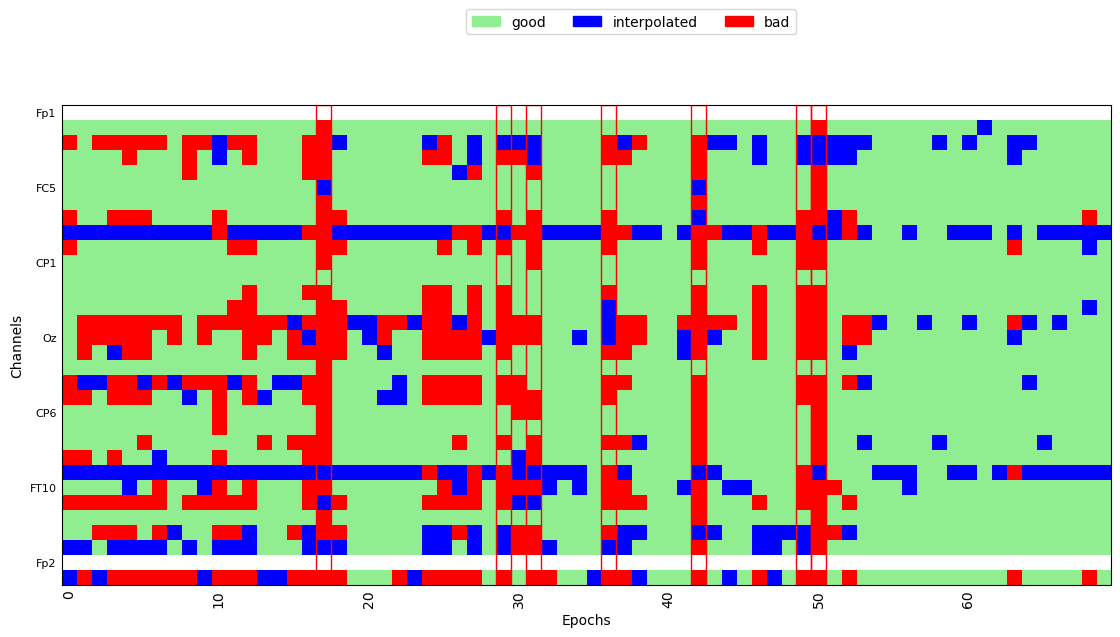

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 7, 30, 42


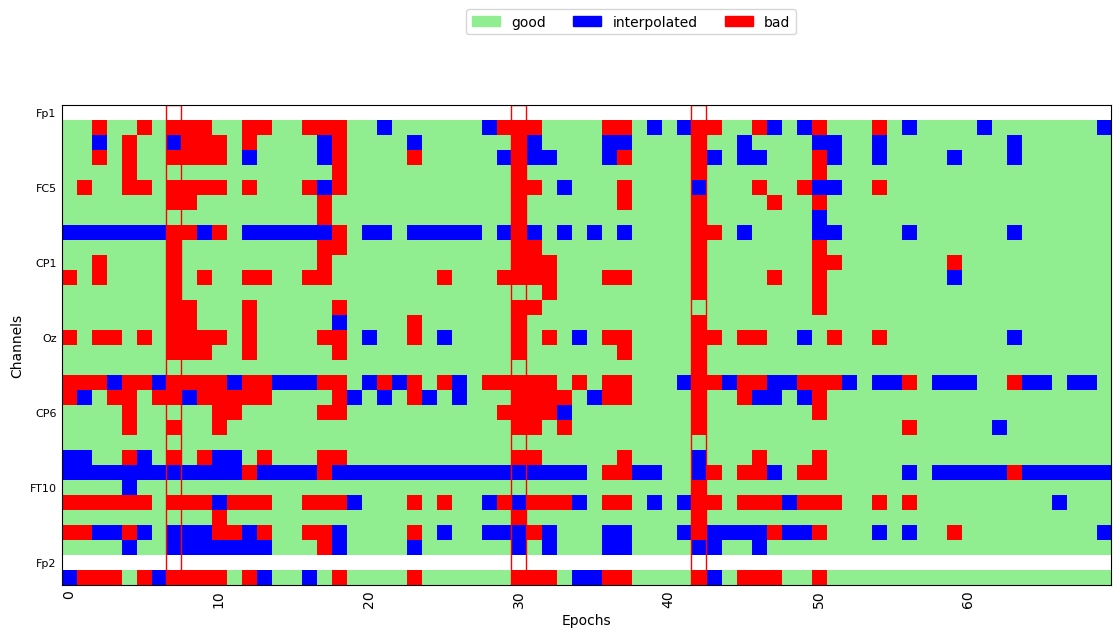

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 8 epochs: 20, 24, 38, 43, 48, 52, 61, 62


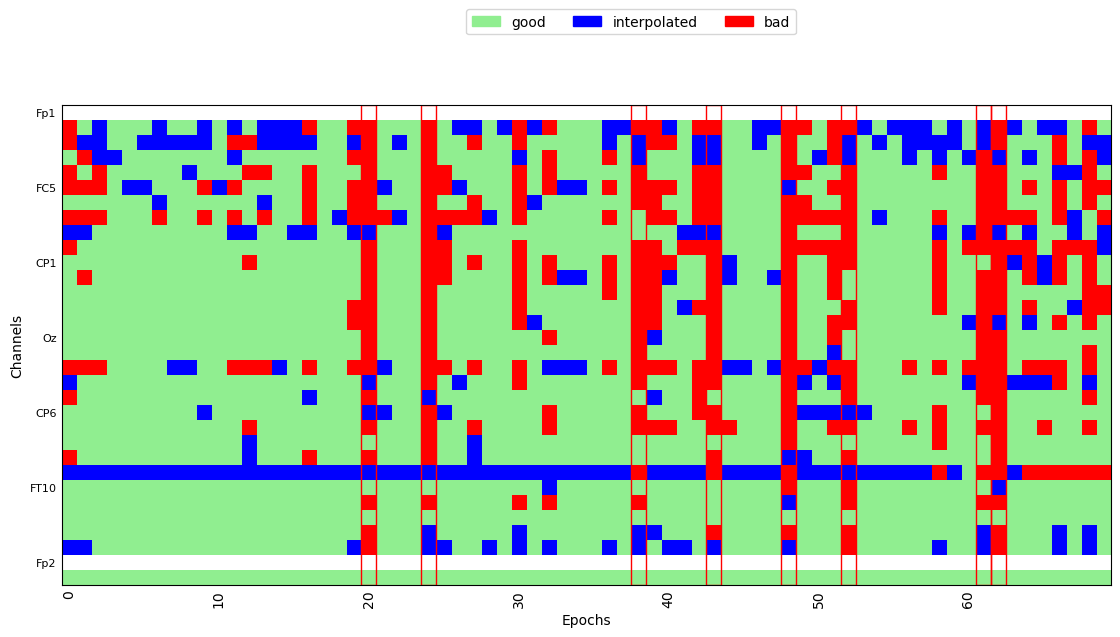

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 26 epochs: 0, 6, 8, 20, 24, 30, 31, 37, 38, 40, 41, 42, 43, 48, 49, 50, 52, 55, 58, 59, 60, 62, 63, 66, 68, 69


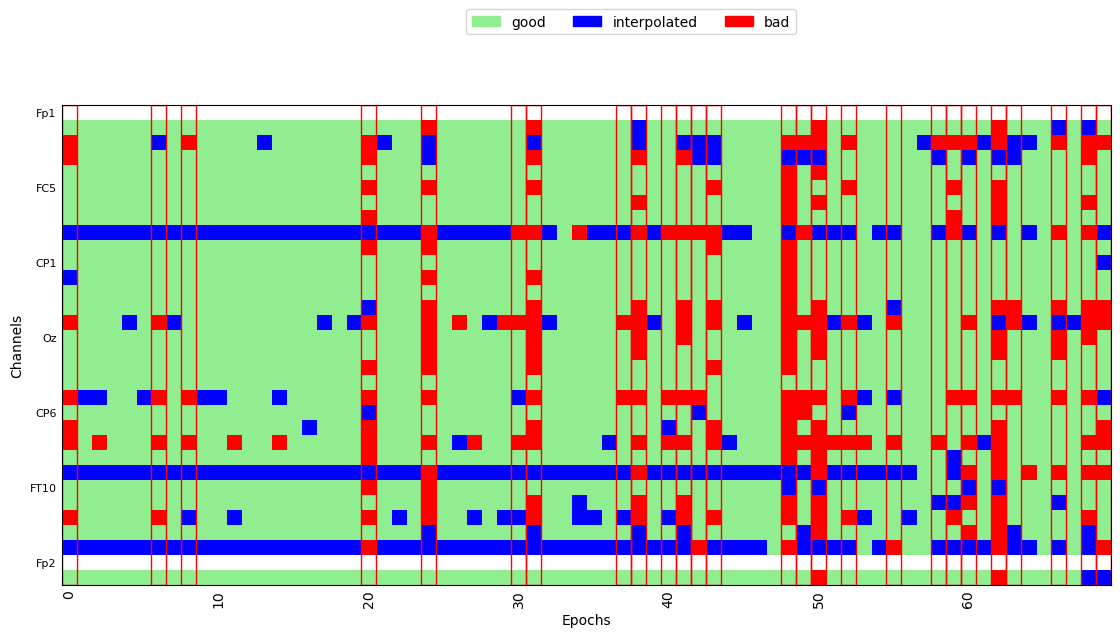

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 3, 17


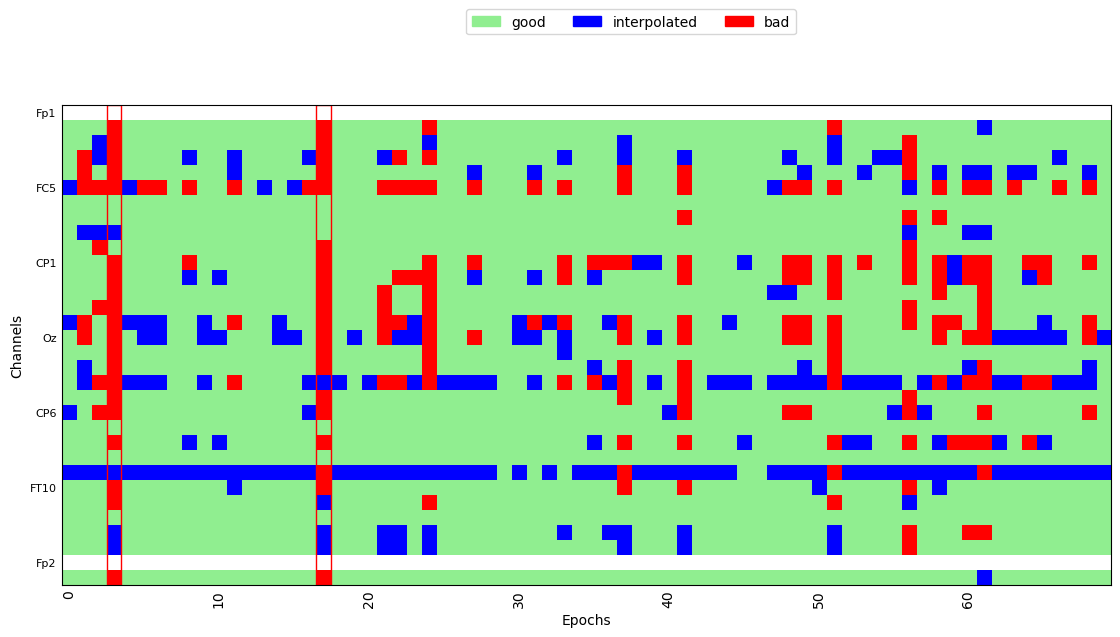

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 26, 30, 37, 56


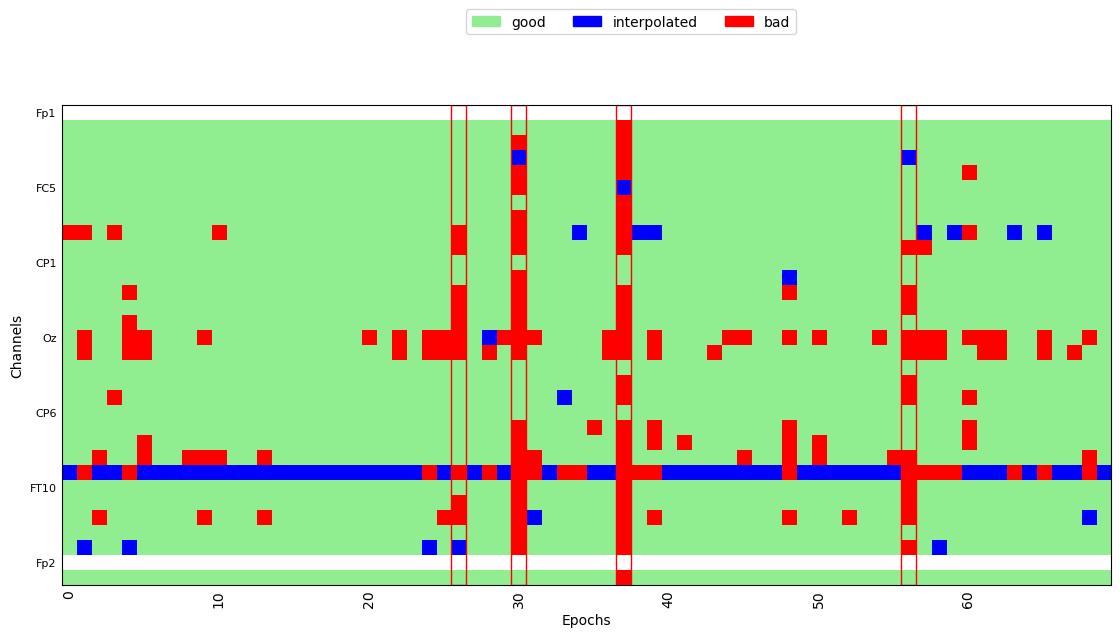

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0071_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0071_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1040589 =      0.000 ...  4162.356 secs
Ready.
Reading 0 ... 1040589  =      0.000 ...  4162.356 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 23 epochs: 0, 2, 16, 24, 26, 31, 33, 35, 37, 40, 41, 43, 44, 48, 49, 54, 55, 57, 62, 63, 64, 66, 69


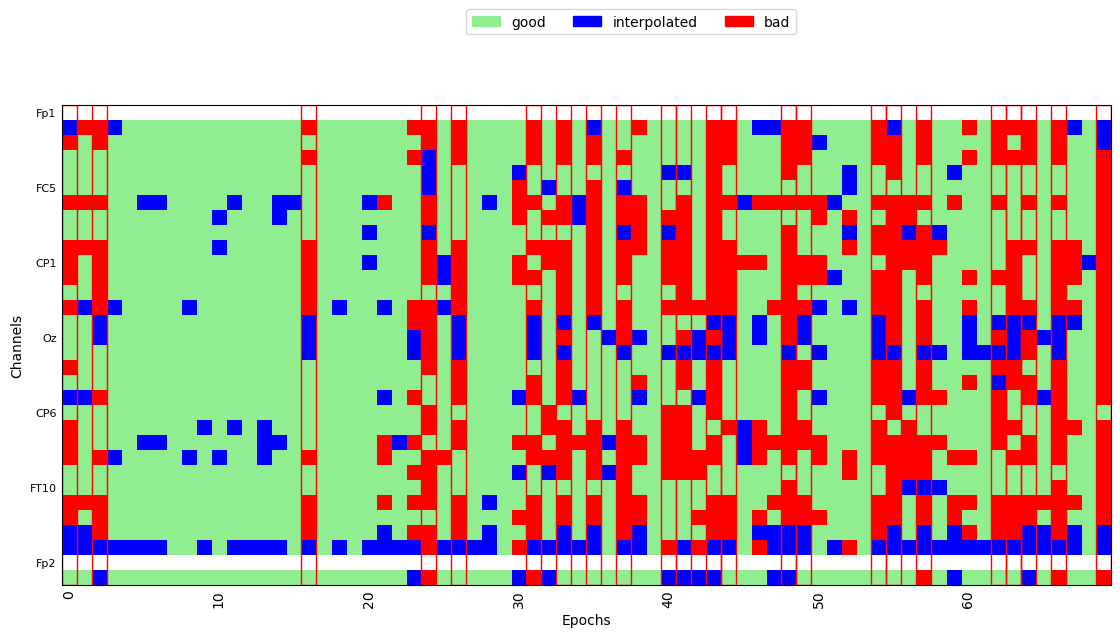

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 24, 28, 30, 33, 38, 40, 45, 50, 55, 56, 58


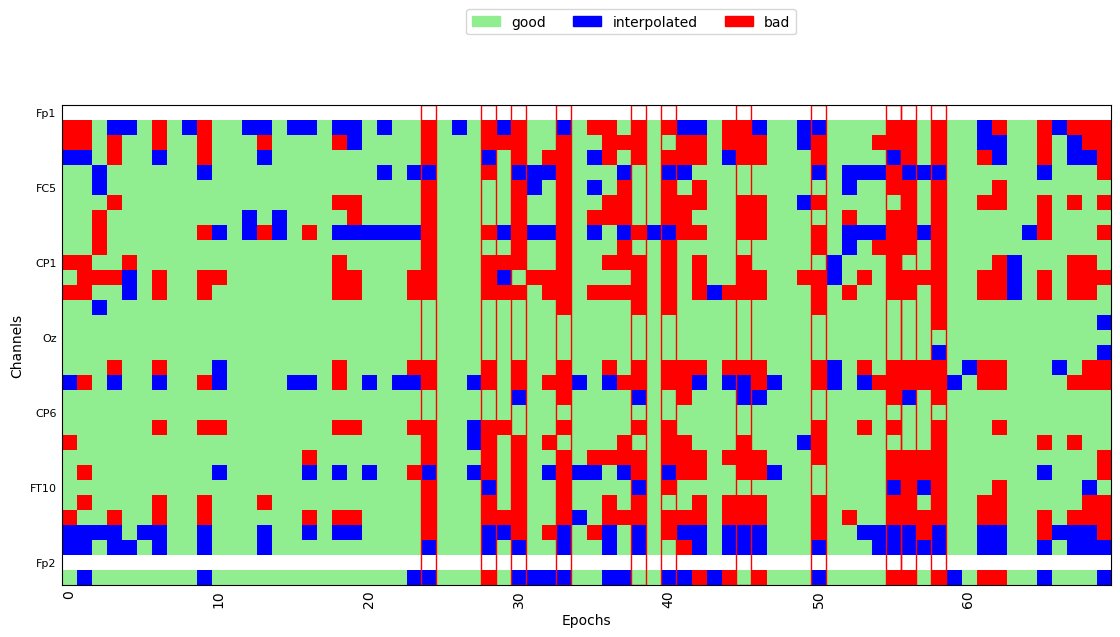

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 27 epochs: 4, 5, 11, 13, 16, 19, 21, 27, 30, 33, 35, 37, 40, 42, 44, 48, 50, 51, 56, 57, 60, 61, 62, 63, 64, 65, 68


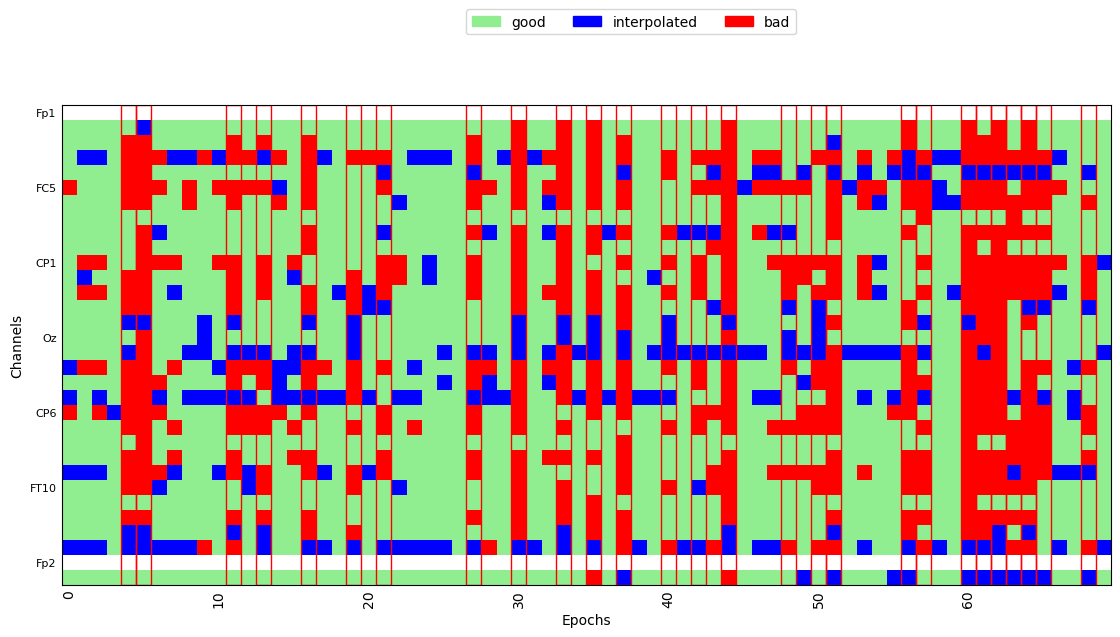

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 11, 15, 17, 26, 49, 50, 54, 60, 61, 64, 68


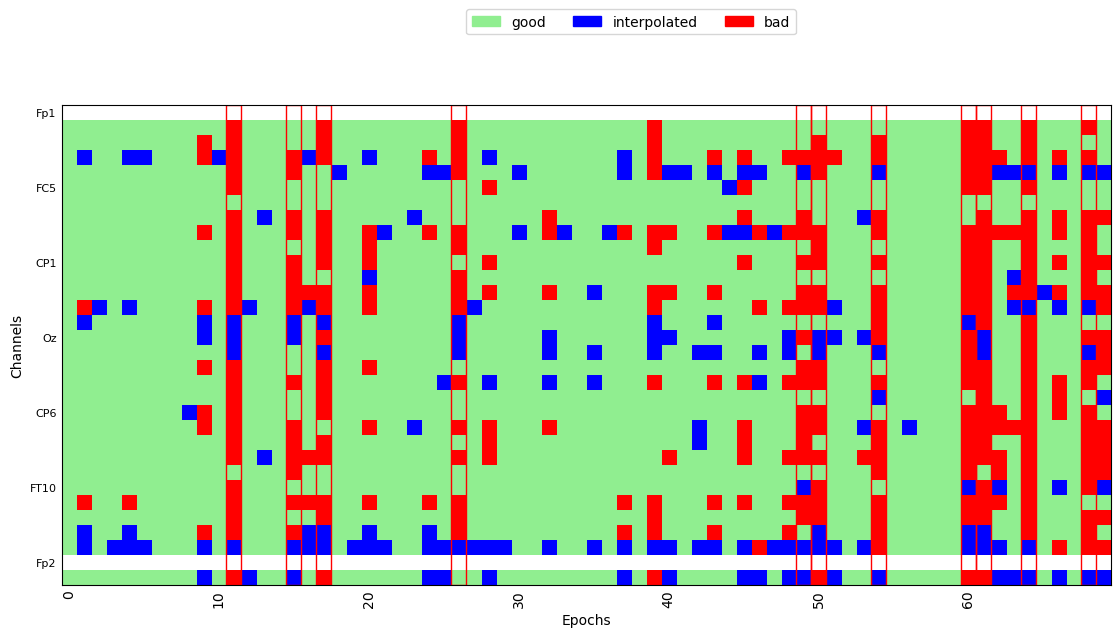

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 34


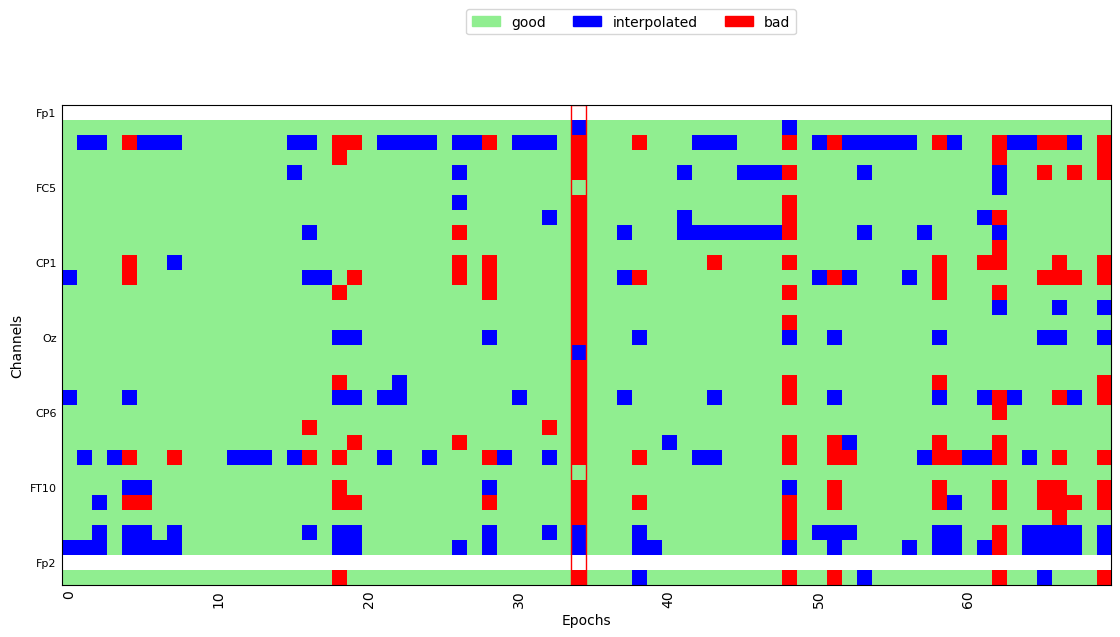

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 62


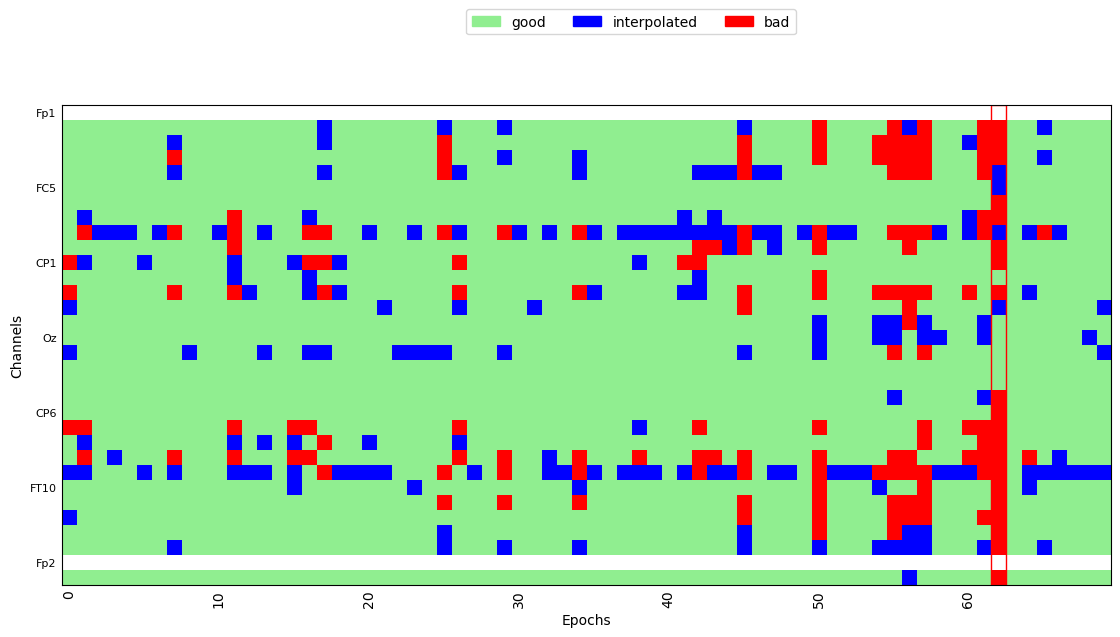

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 4, 10, 16, 19, 26, 30, 33, 38, 45, 50, 54, 55, 59, 61, 65


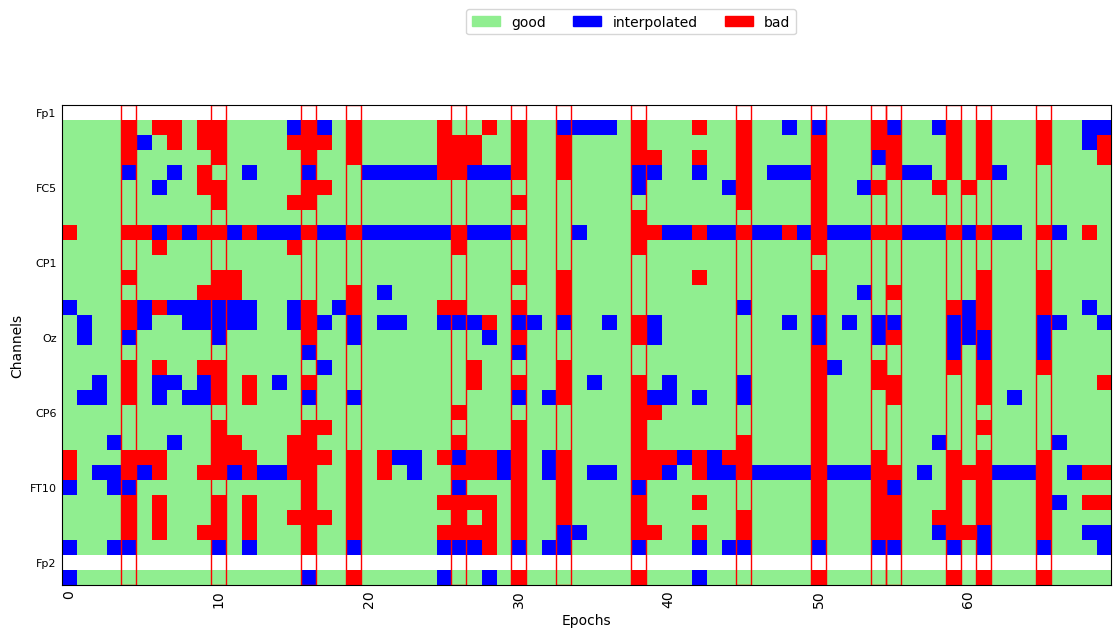

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 38, 68


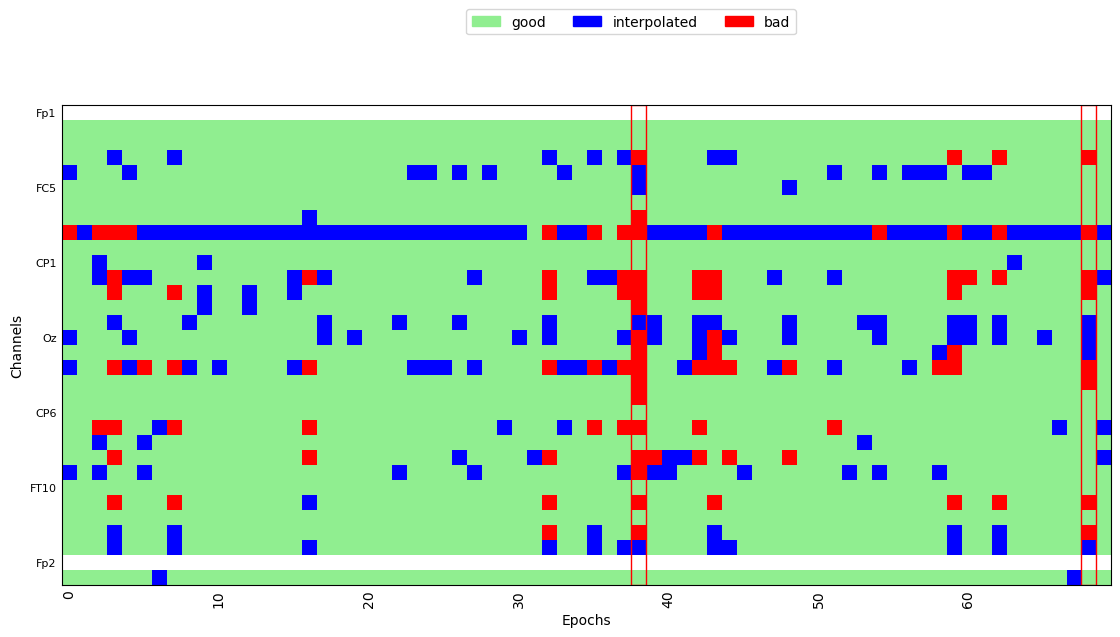

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0052_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1032049 =      0.000 ...  4128.196 secs
Ready.
Reading 0 ... 1032049  =      0.000 ...  4128.196 secs...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0052_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 21, 23, 24, 26, 27, 36, 37, 42, 43, 46, 50, 53, 56, 59, 65, 67


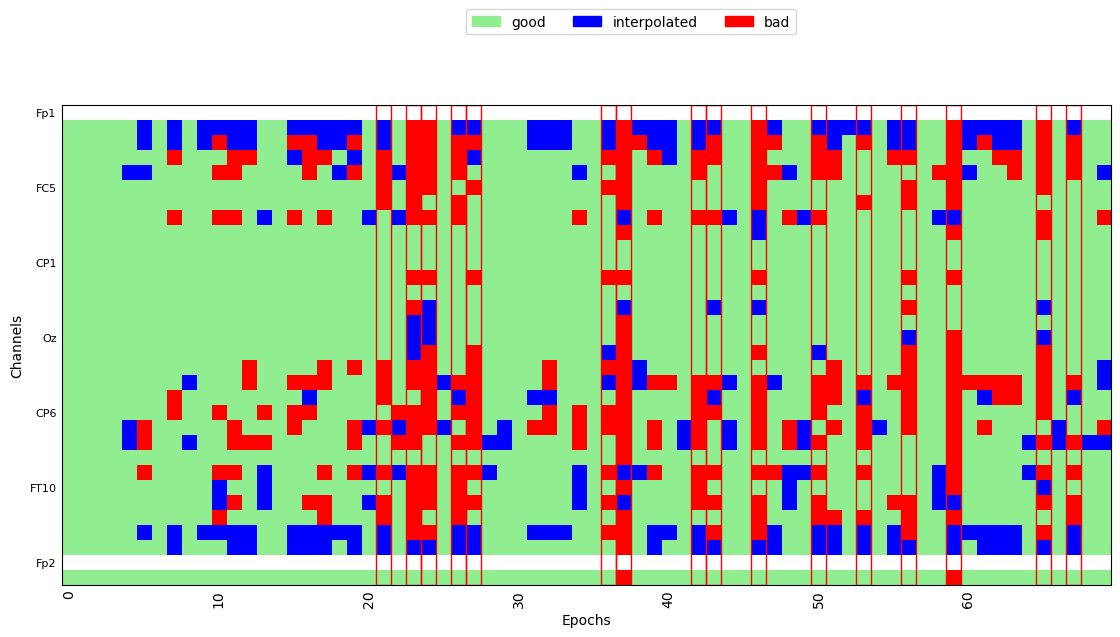

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 0, 7, 9, 10, 17, 21, 25, 35, 37, 44, 49, 59, 66, 68, 69


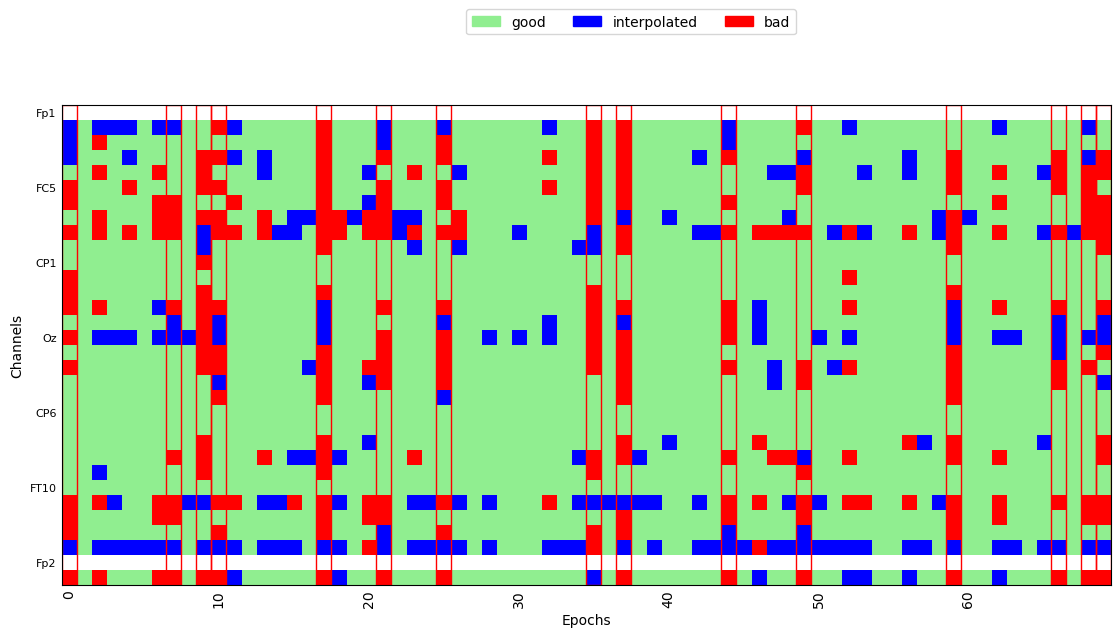

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 4, 17, 19, 22, 25, 32, 35, 38, 40, 51, 53, 56, 57, 59, 63, 65, 66, 69


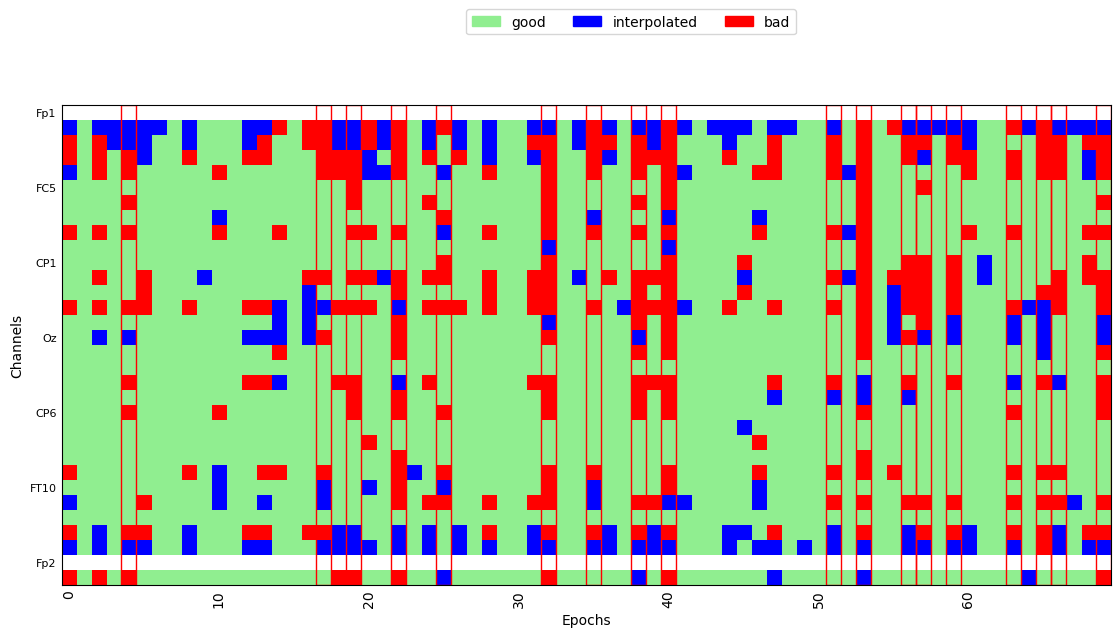

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 27 epochs: 0, 1, 10, 11, 12, 14, 22, 25, 31, 36, 37, 38, 40, 41, 42, 43, 51, 52, 53, 55, 56, 58, 60, 64, 66, 68, 69


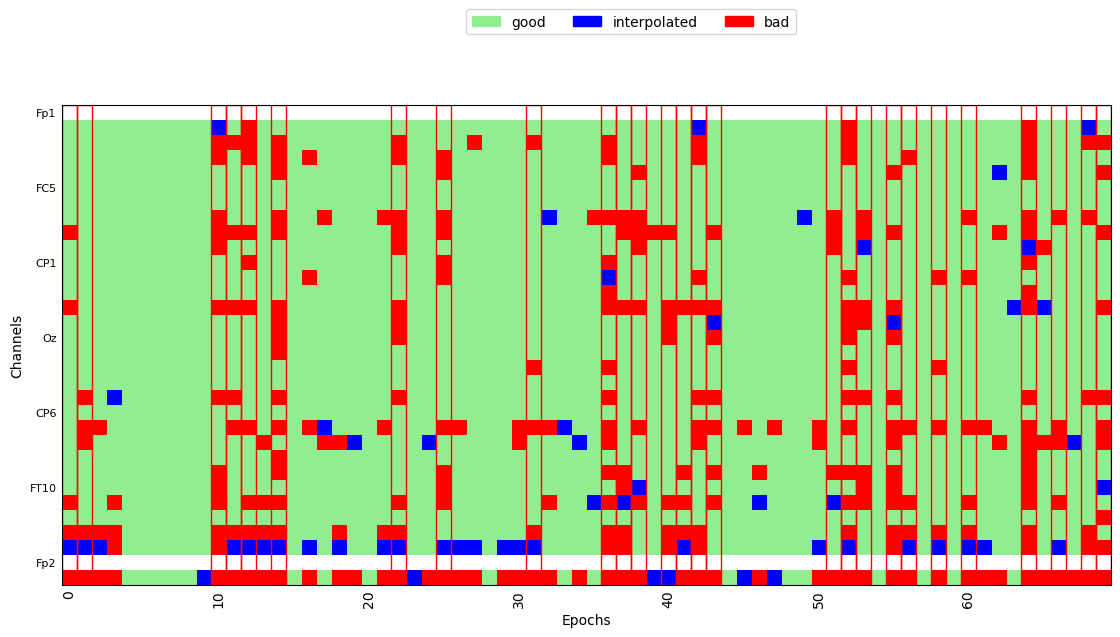

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 36 epochs: 0, 5, 12, 13, 15, 16, 17, 19, 21, 22, 23, 28, 31, 32, 33, 34, 35, 37, 38, 40, 41, 42, 43, 46, 48, 51, 53, 57, 58, 60, 62, 63, 64, 65, 67, 68


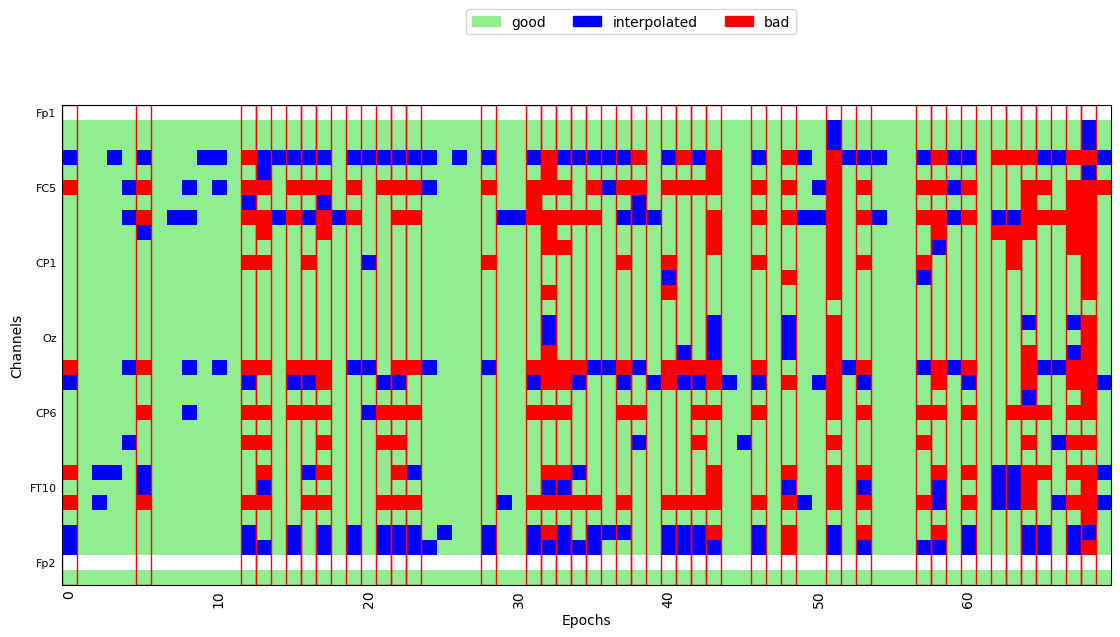

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 20, 53


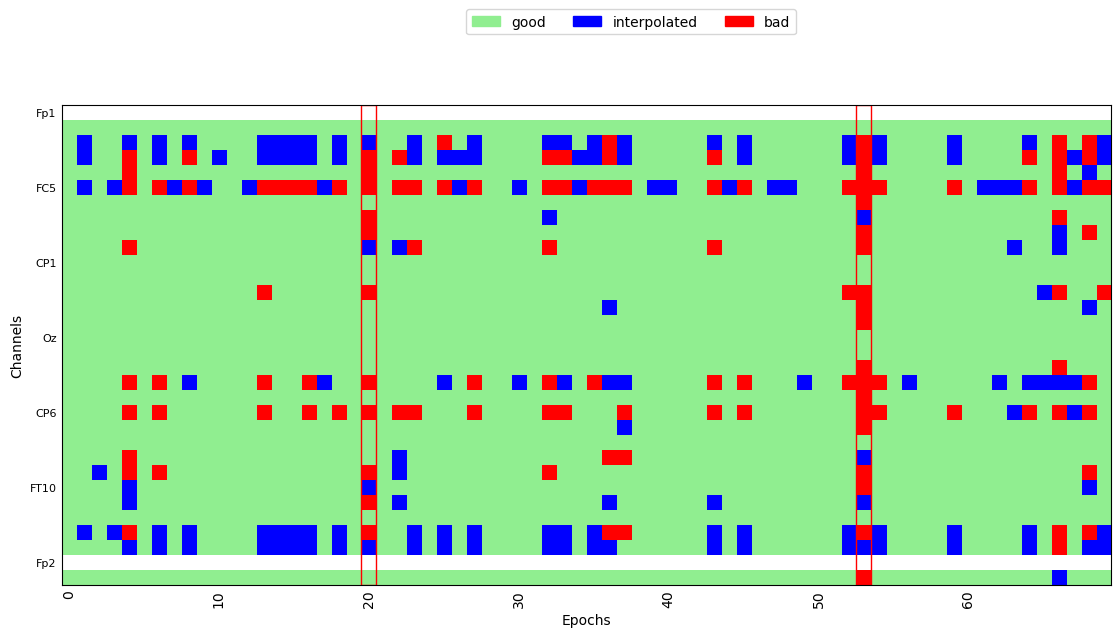

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 54, 64


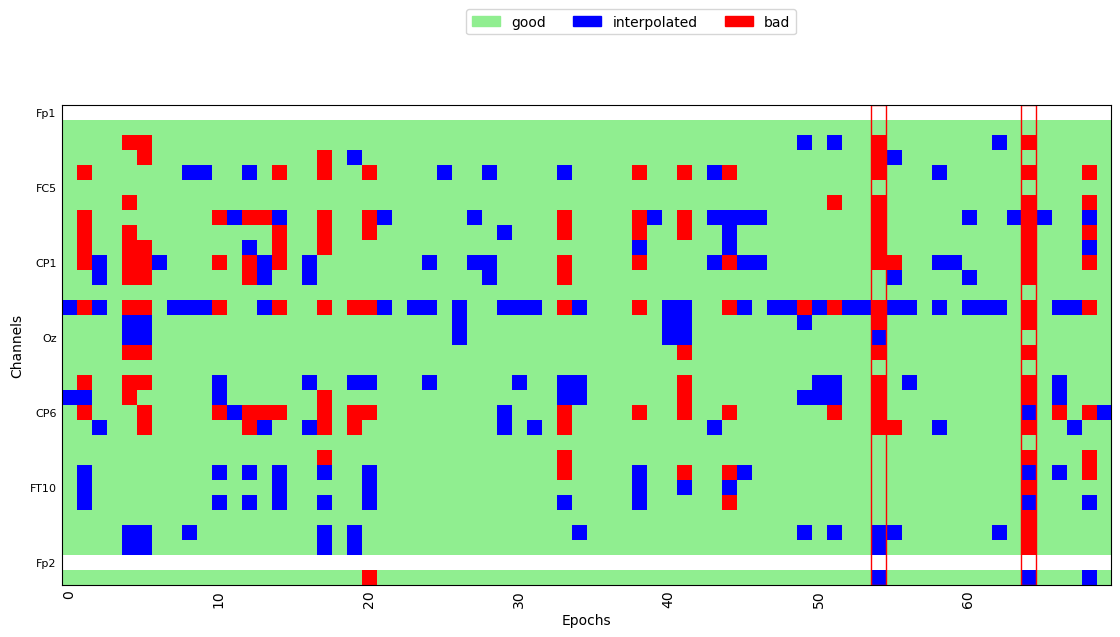

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 28 epochs: 1, 2, 10, 11, 12, 14, 16, 17, 20, 22, 24, 30, 31, 32, 33, 37, 38, 39, 43, 45, 46, 47, 54, 55, 56, 61, 64, 68


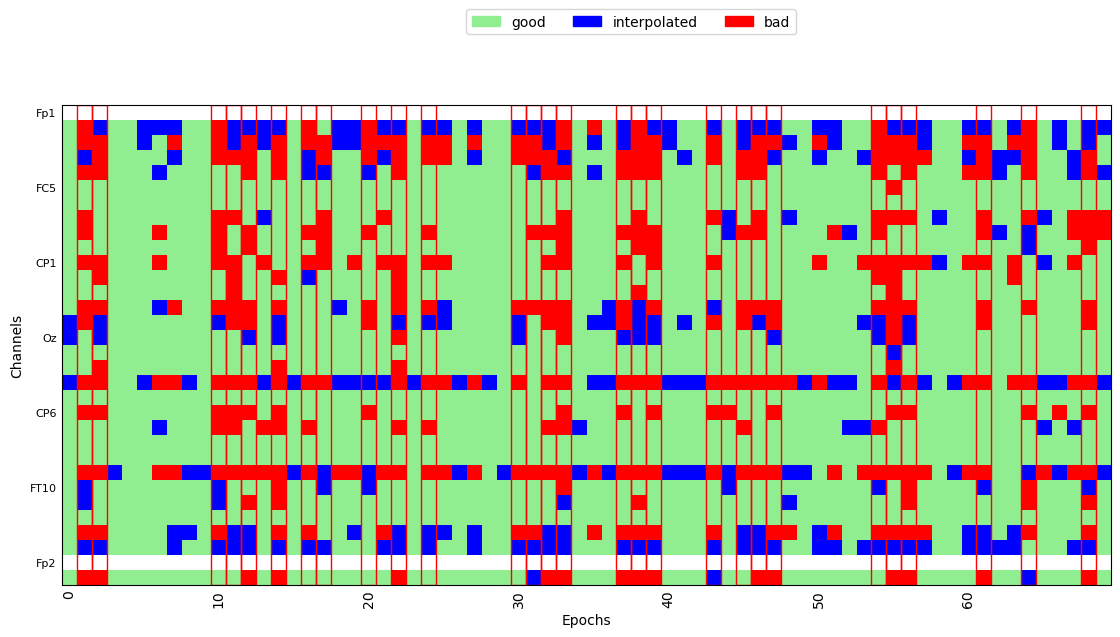

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0060_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1049839 =      0.000 ...  4199.356 secs
Ready.


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0060_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Reading 0 ... 1049839  =      0.000 ...  4199.356 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 32, 33, 67


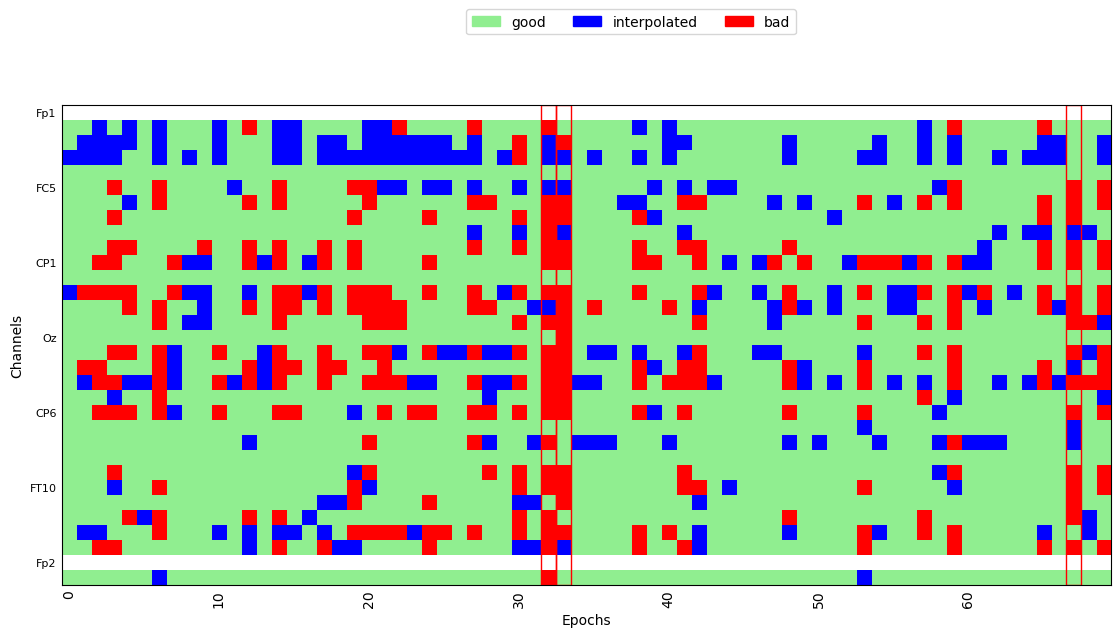

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 15, 24, 30, 43, 44, 53, 60, 68, 69


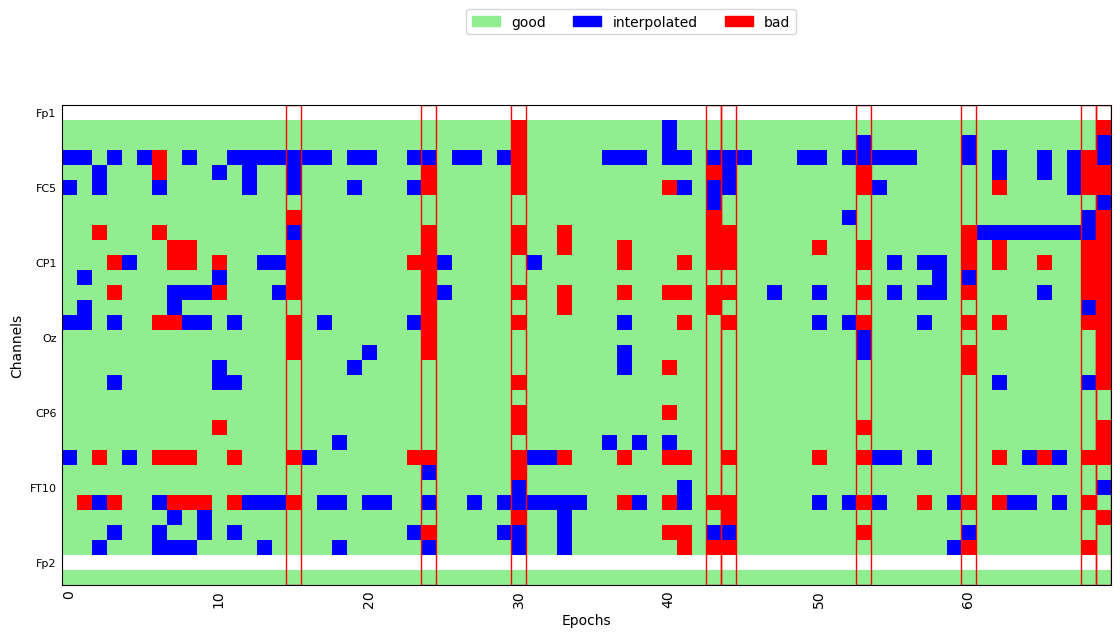

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 0, 1, 4, 33, 36, 39, 64, 65, 69


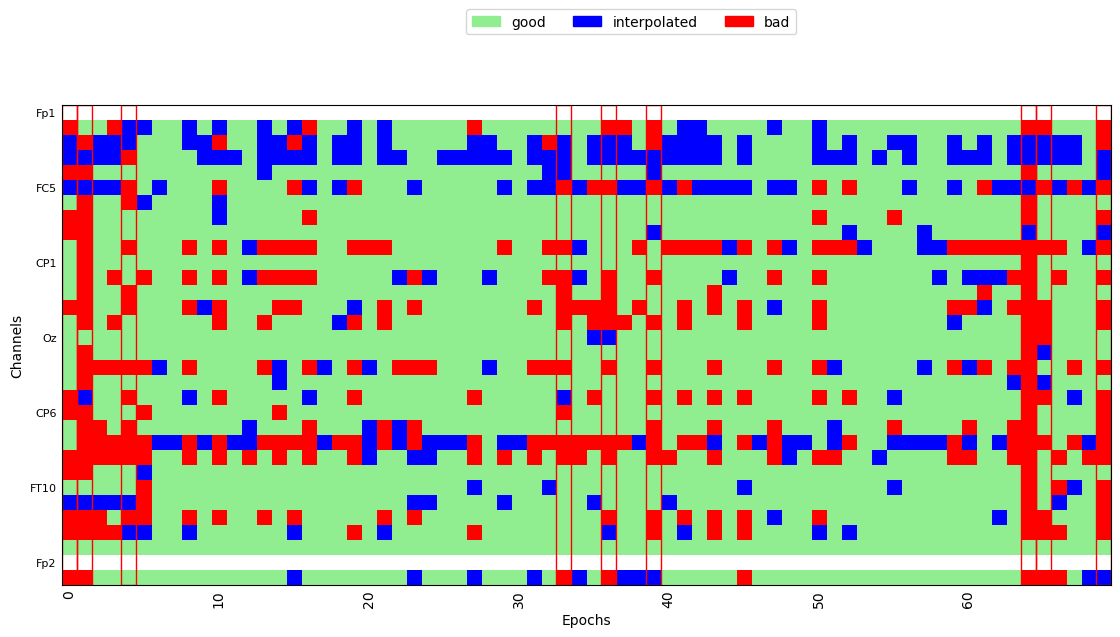

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 44, 54, 60, 64


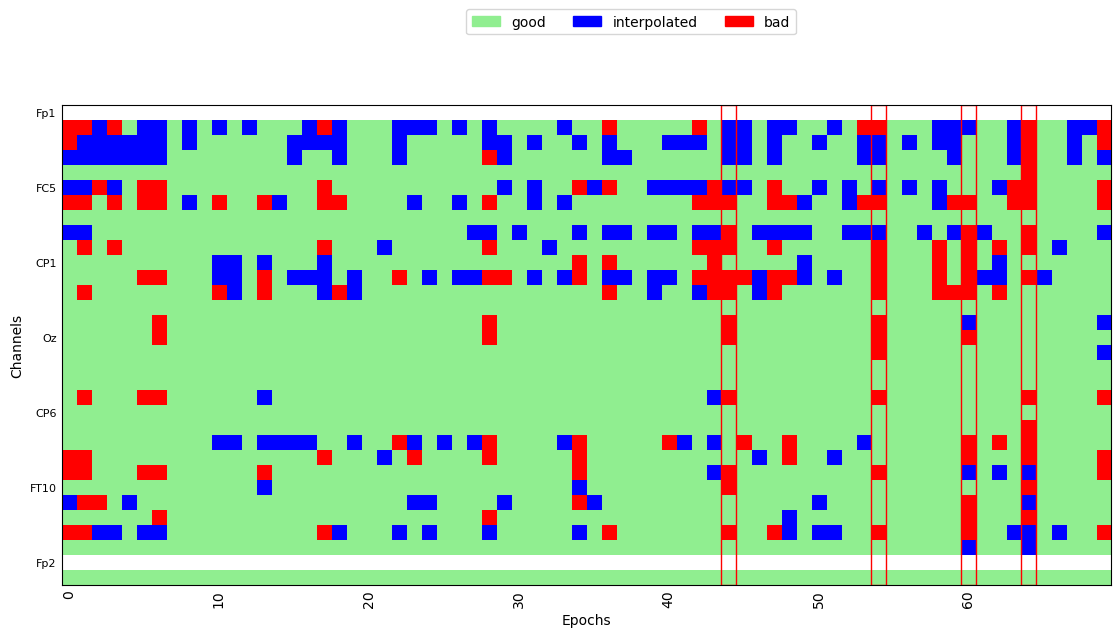

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 3, 24, 39, 59, 62


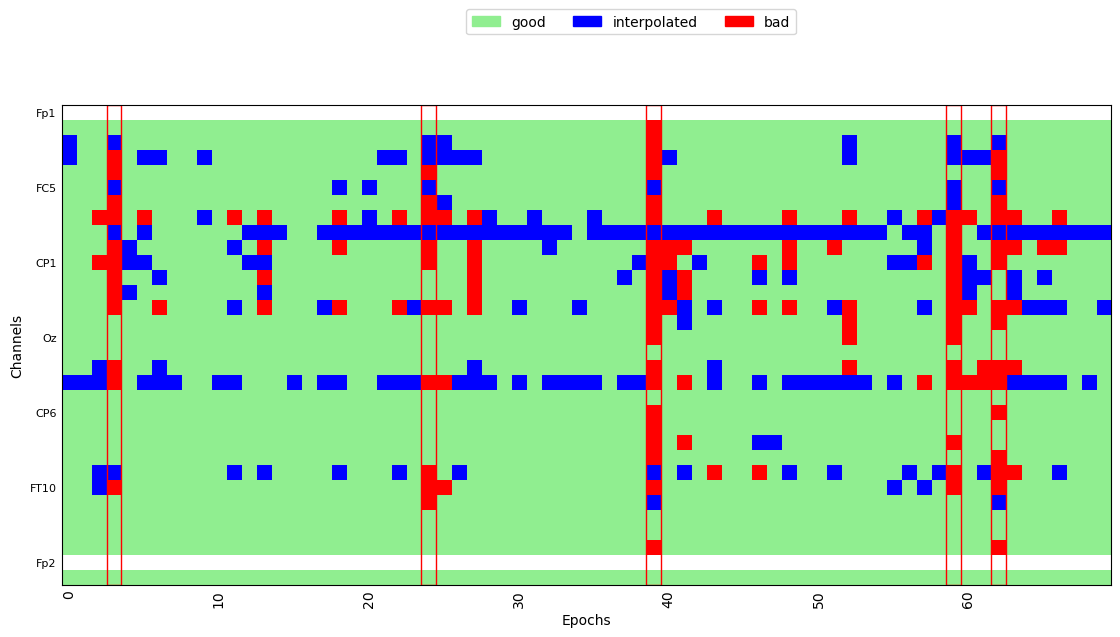

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (5 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 7, 15, 24, 27, 35, 39, 44, 52, 59, 62, 69


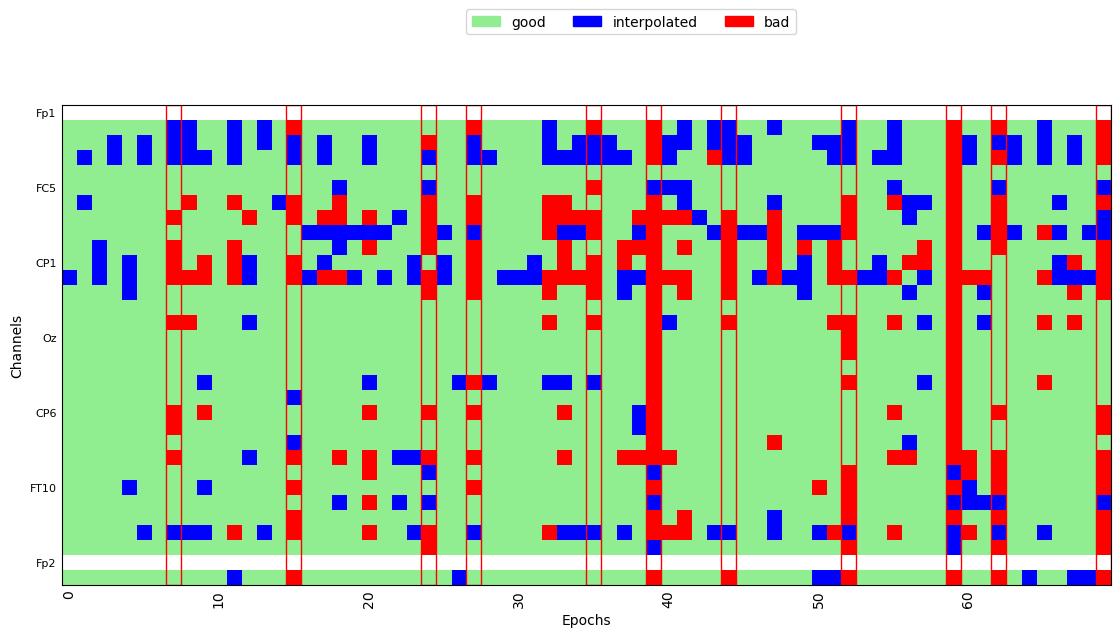

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 25 epochs: 4, 6, 7, 12, 17, 23, 24, 25, 29, 32, 35, 39, 40, 42, 45, 46, 50, 51, 56, 60, 61, 62, 65, 67, 69


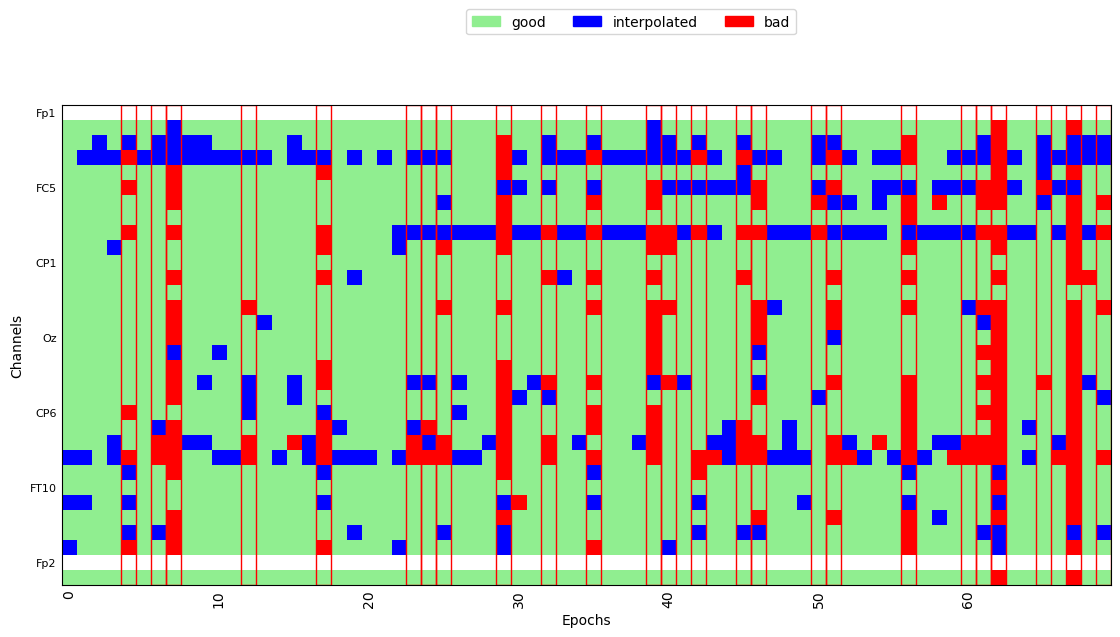

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 0, 4, 10, 17, 29, 30, 42, 62, 64, 65, 67


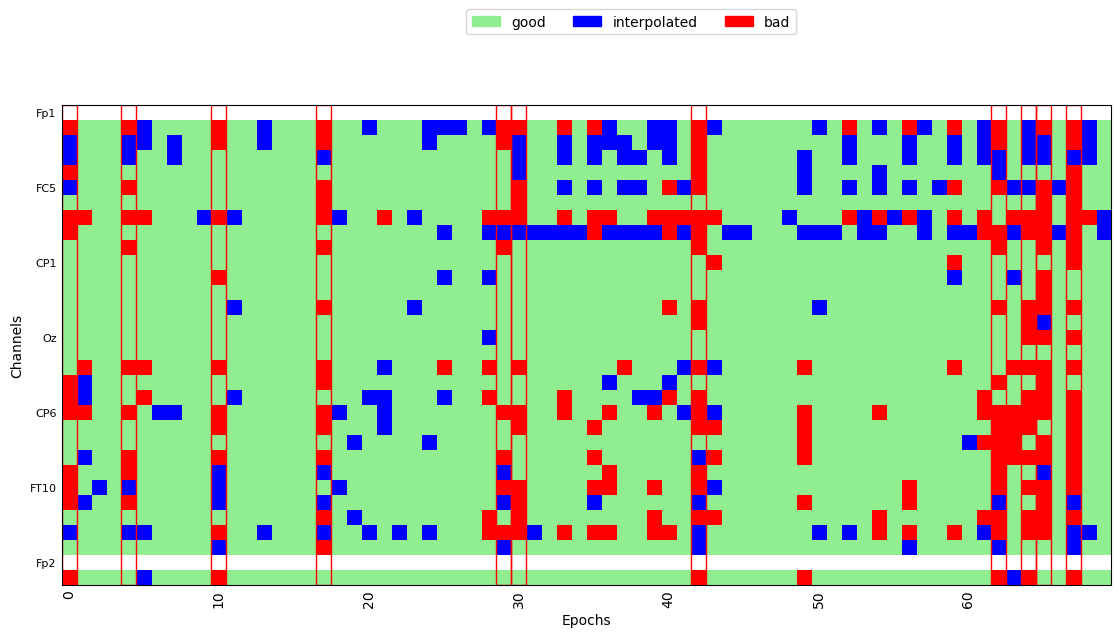

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0042_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0042_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1033989 =      0.000 ...  4135.956 secs
Ready.
Reading 0 ... 1033989  =      0.000 ...  4135.956 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 13, 17, 19, 20, 21, 22, 36, 37, 42, 46, 50, 52, 56, 60, 61, 64, 65, 69


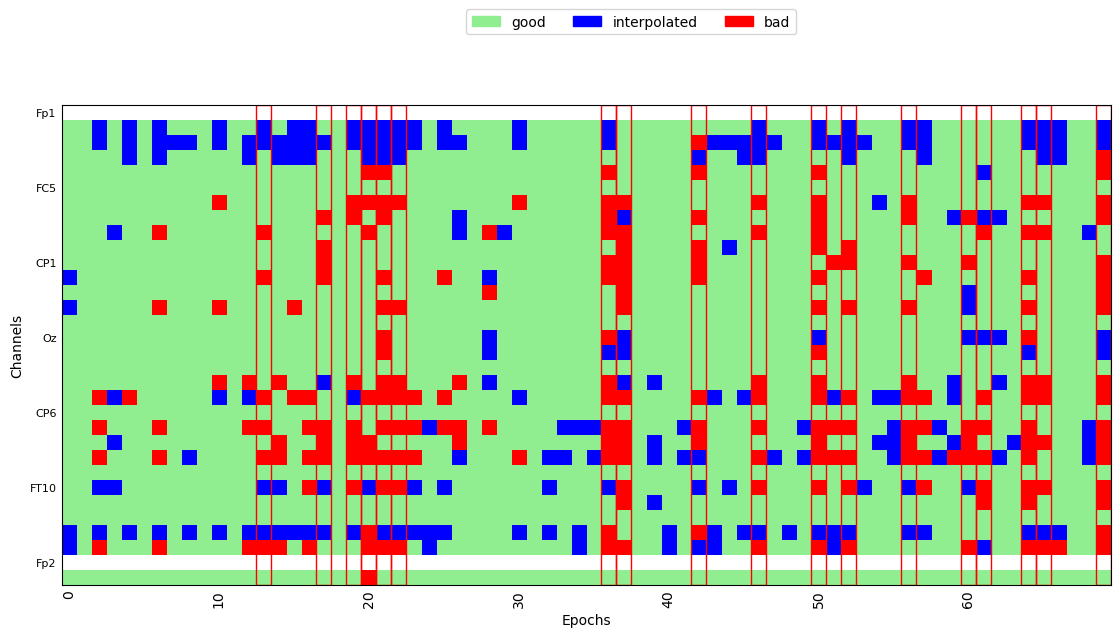

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 14 epochs: 2, 14, 26, 32, 35, 36, 37, 39, 42, 50, 56, 59, 64, 65


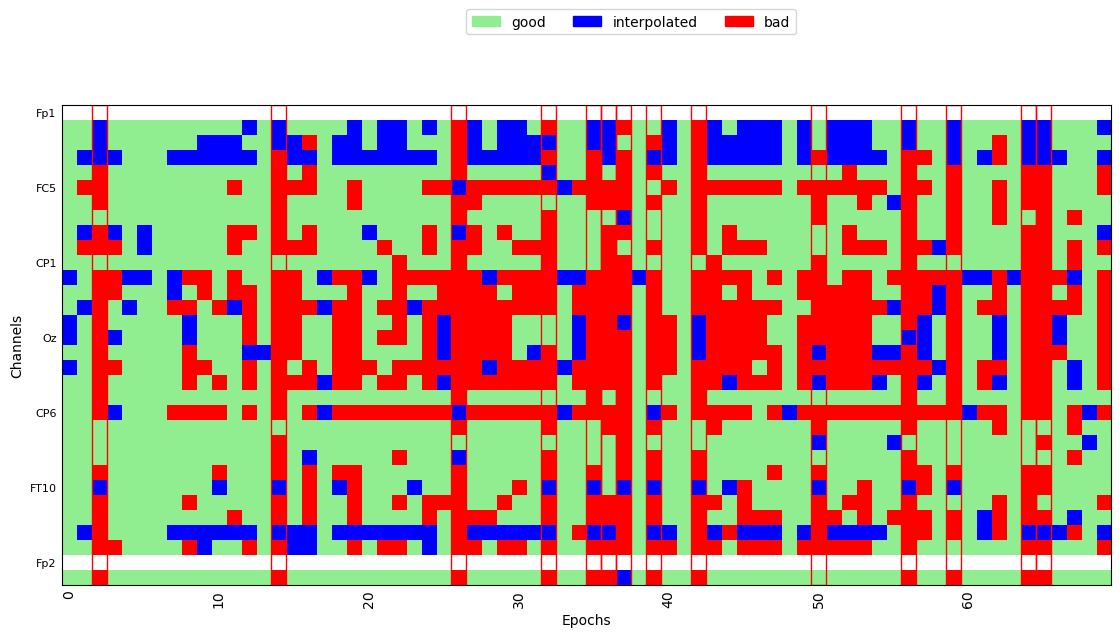

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 22 epochs: 2, 11, 14, 15, 17, 22, 25, 27, 29, 32, 41, 45, 46, 48, 49, 50, 55, 58, 61, 63, 65, 66


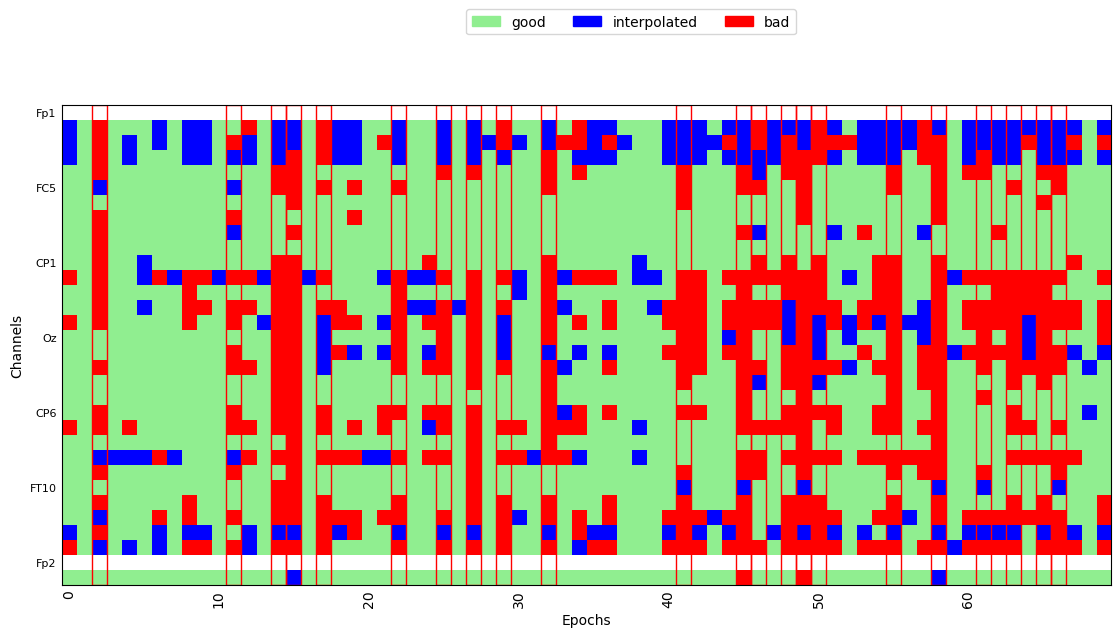

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 24, 28, 38, 43, 45, 48, 49, 50, 62, 64, 65


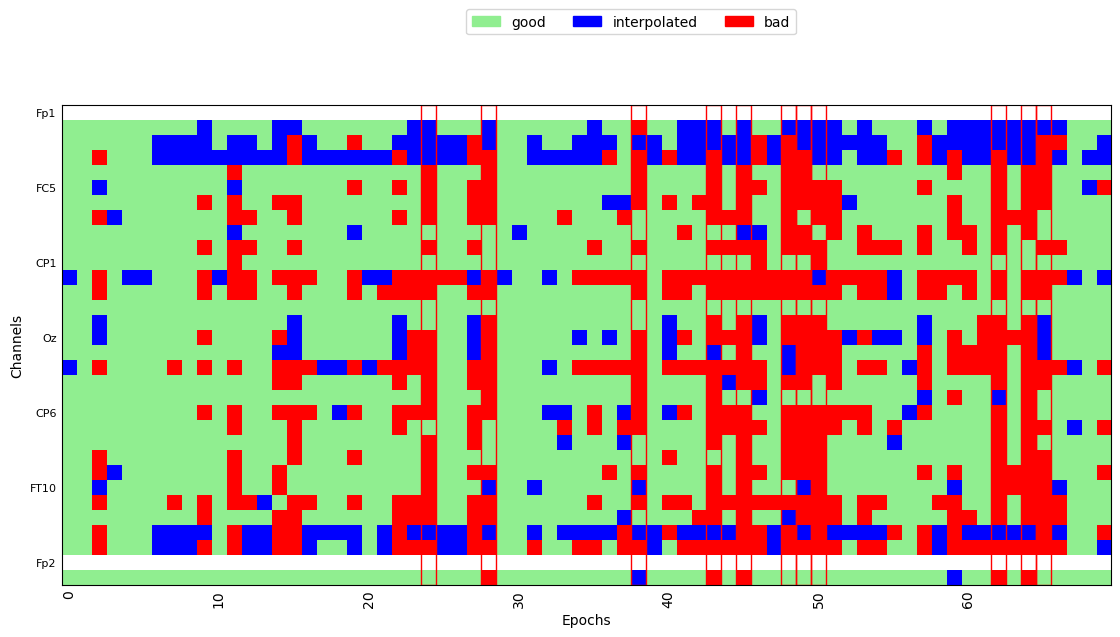

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 23 epochs: 0, 1, 2, 3, 8, 25, 27, 28, 29, 30, 31, 35, 36, 39, 41, 45, 46, 49, 51, 52, 55, 62, 67


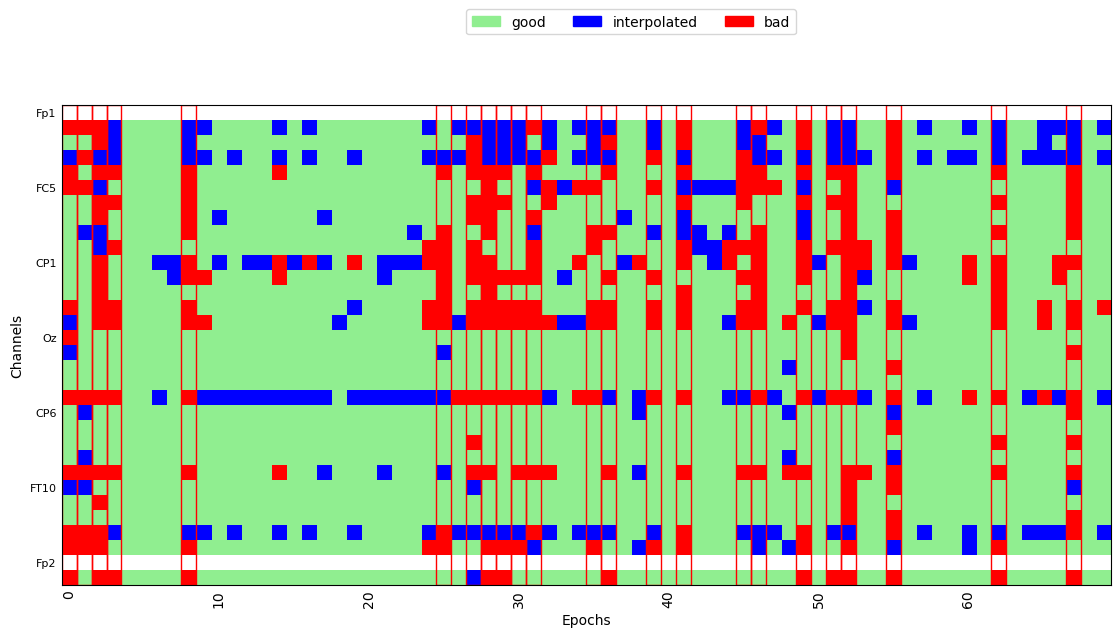

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 25, 27, 31, 41, 47, 49, 52, 56, 67


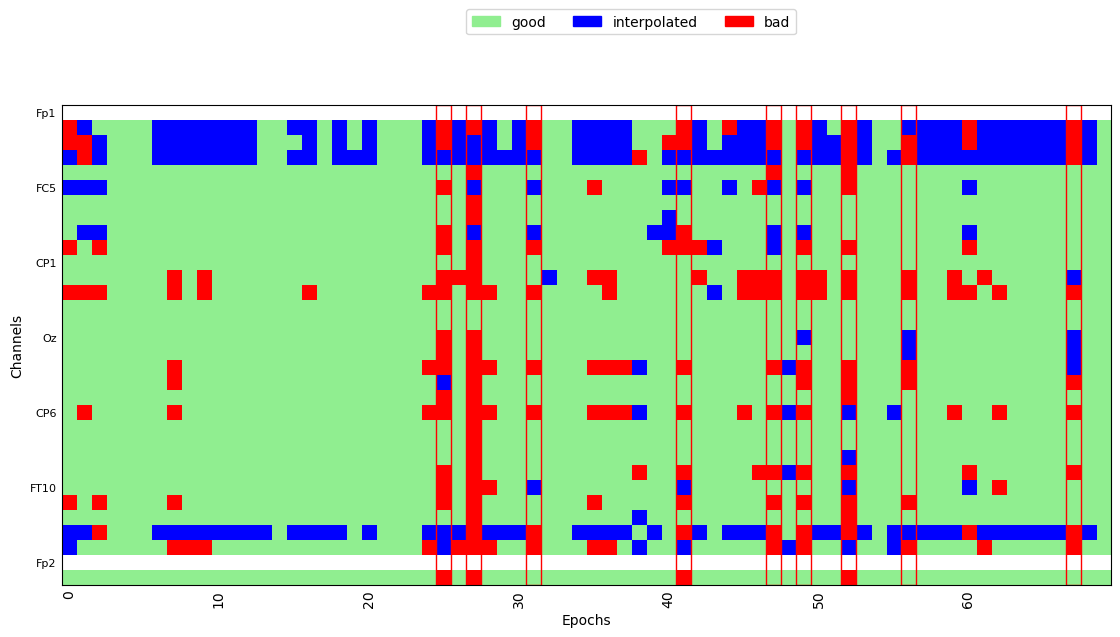

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 19 epochs: 1, 10, 12, 13, 20, 24, 29, 31, 42, 44, 46, 50, 53, 54, 55, 56, 62, 64, 67


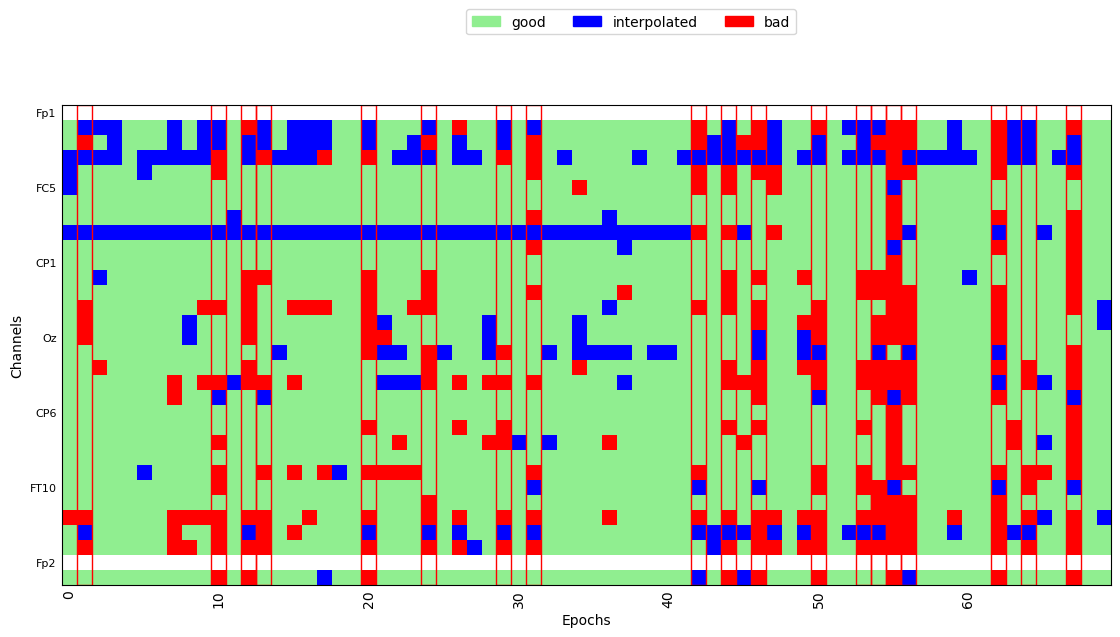

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


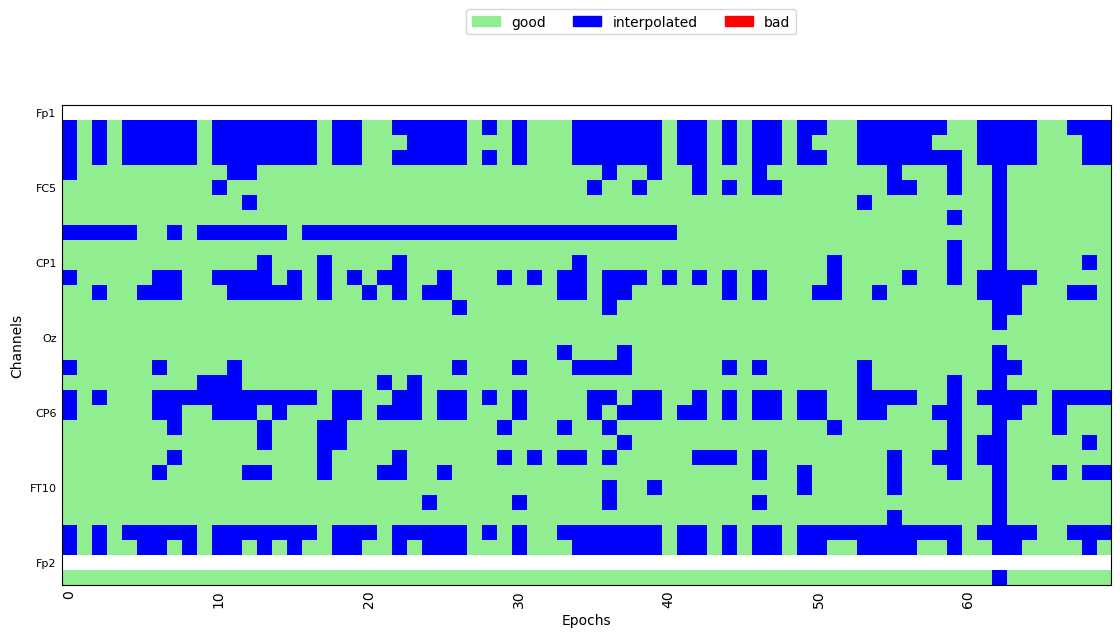

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0031_VOT_corr_filt_bads_ica.fif...
    Range : 0 ... 1063019 =      0.000 ...  4252.076 secs
Ready.
Reading 0 ... 1063019  =      0.000 ...  4252.076 secs...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0031_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 4, 12, 18, 19, 23, 27, 30, 32, 56, 59, 66


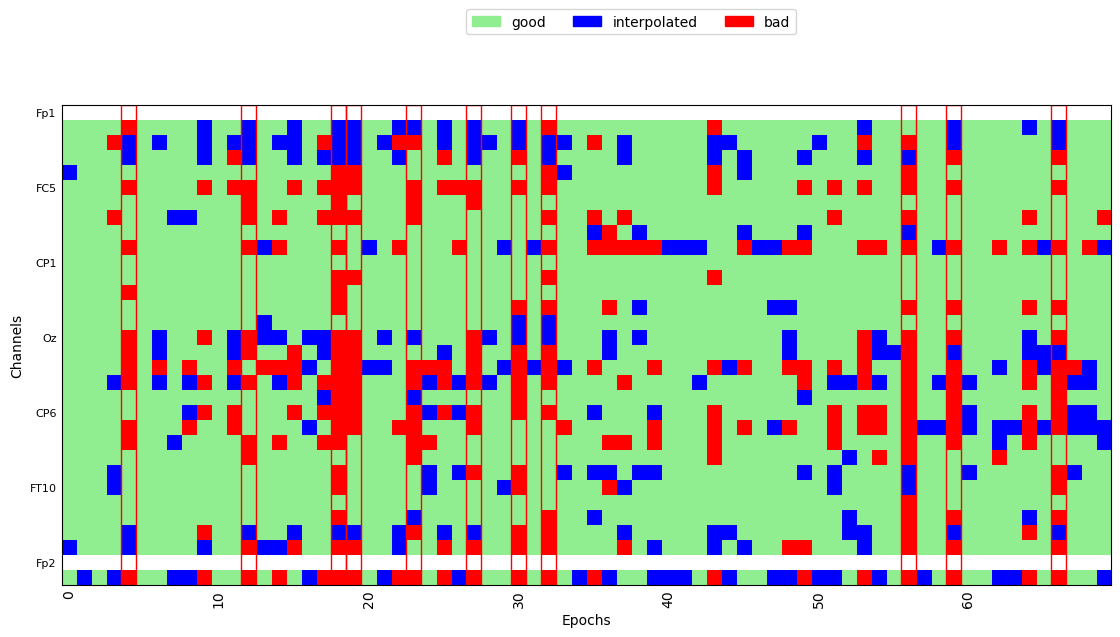

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 28


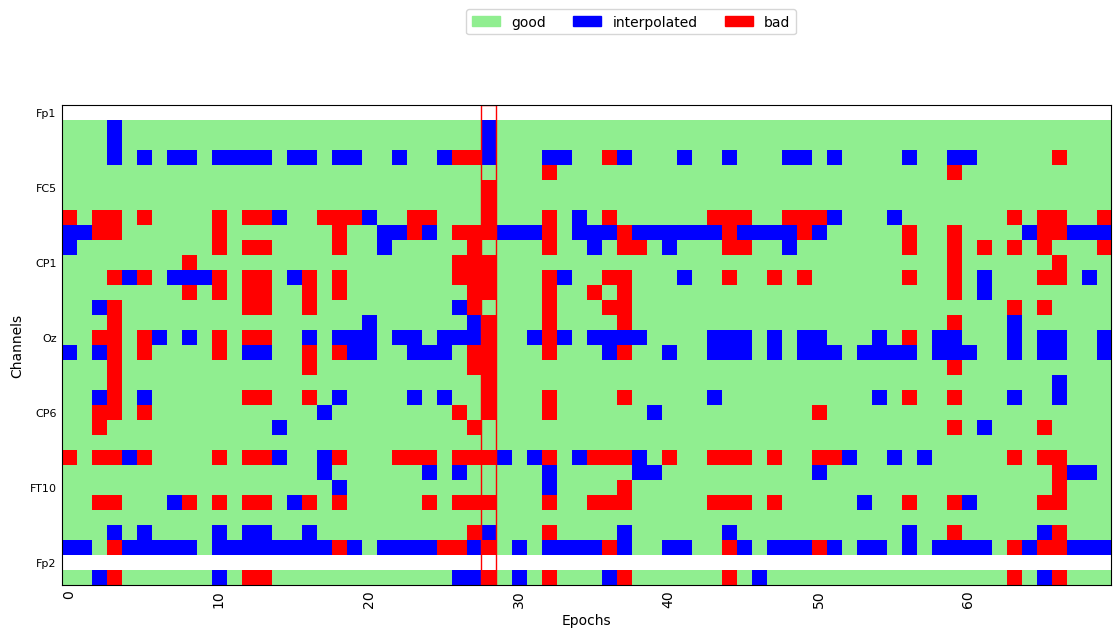

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.20 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 22 epochs: 2, 3, 7, 8, 10, 13, 16, 19, 22, 26, 34, 38, 39, 47, 48, 51, 52, 54, 59, 63, 68, 69


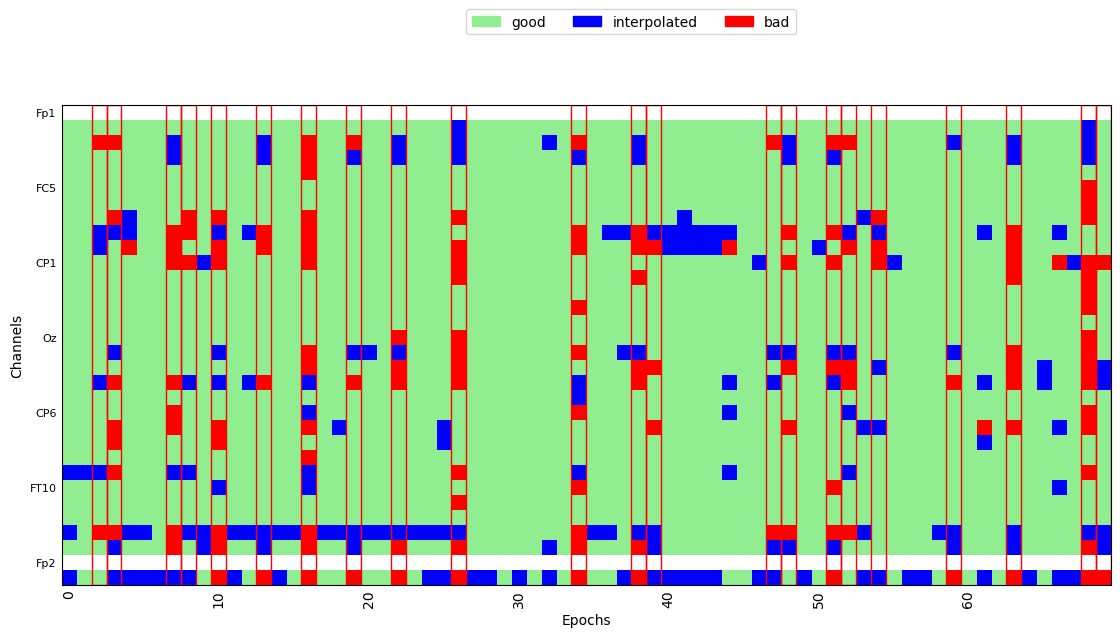

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 13 epochs: 4, 10, 16, 17, 19, 23, 26, 35, 37, 39, 50, 51, 69


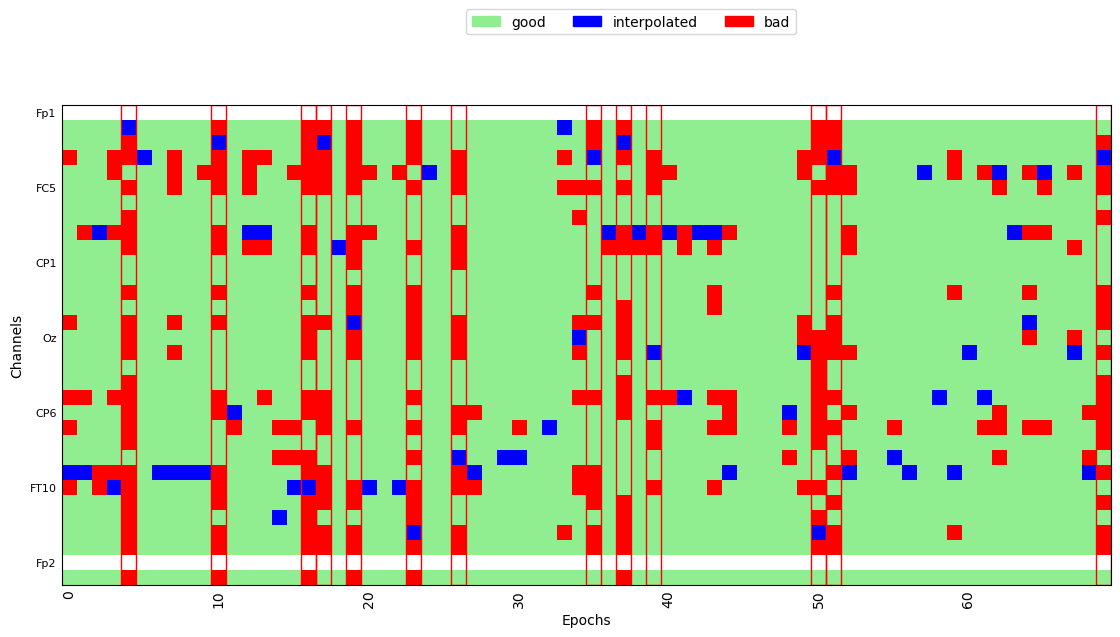

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


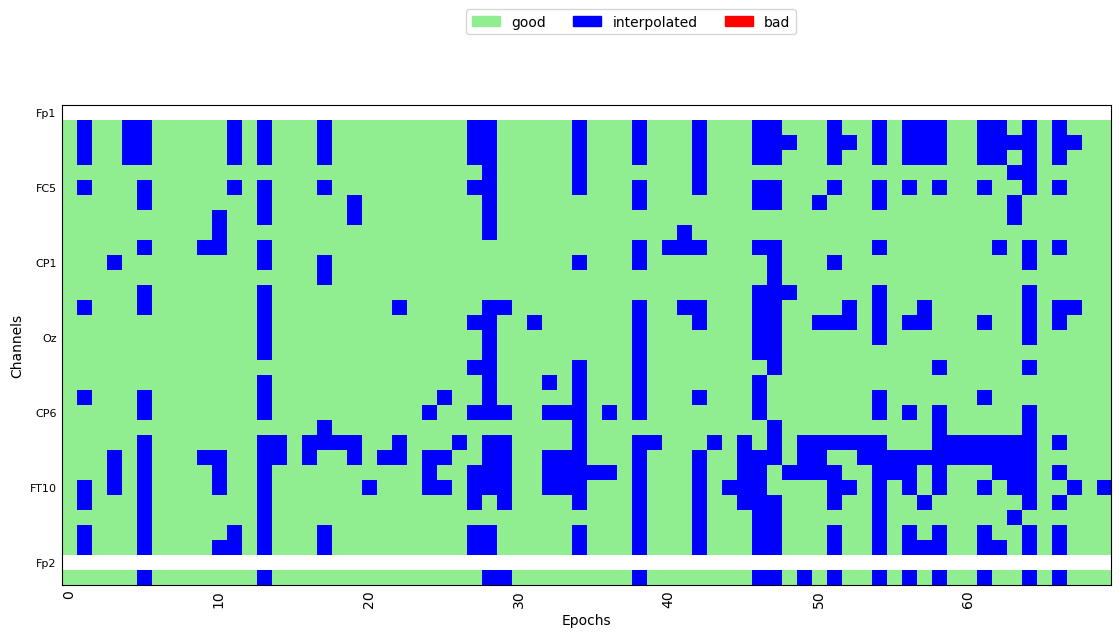

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 12 epochs: 1, 5, 16, 26, 31, 42, 51, 57, 58, 60, 63, 64


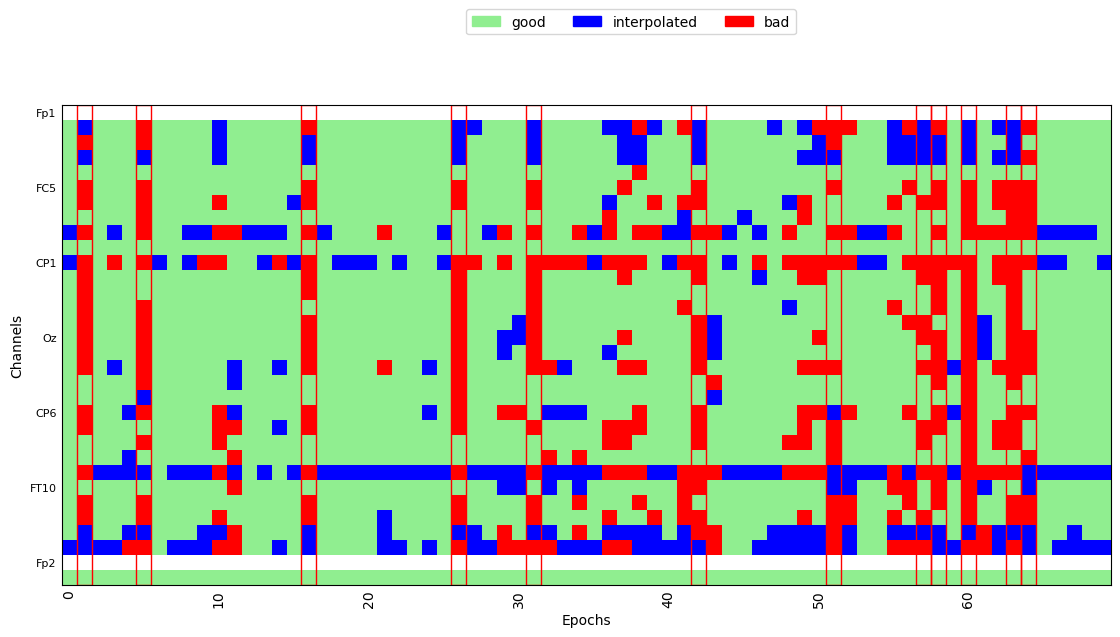

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 21, 42, 45, 50, 58, 68


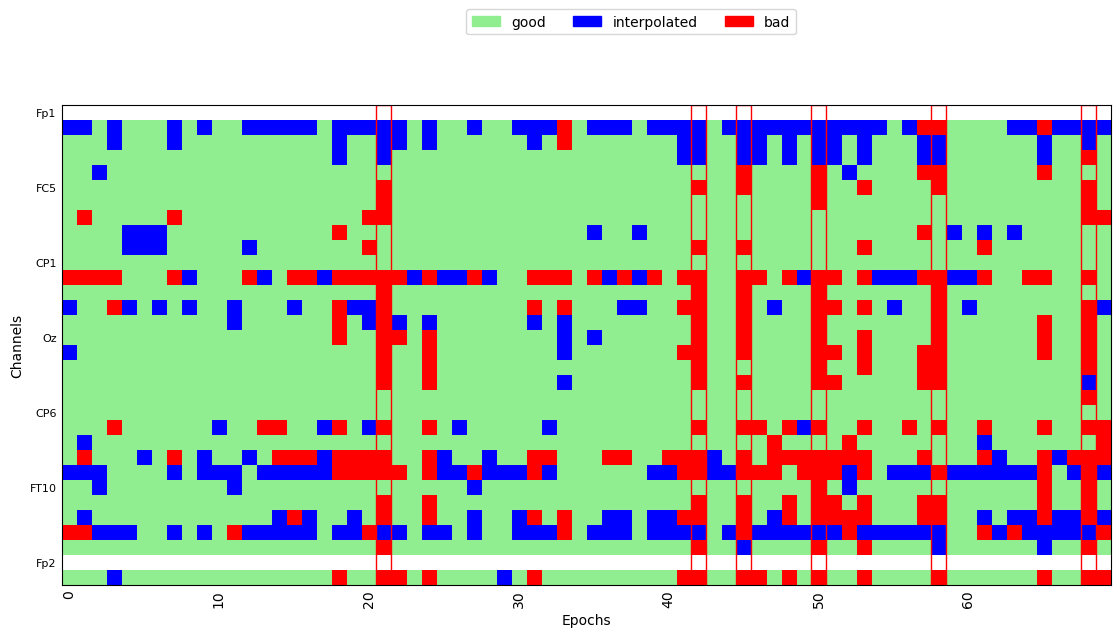

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


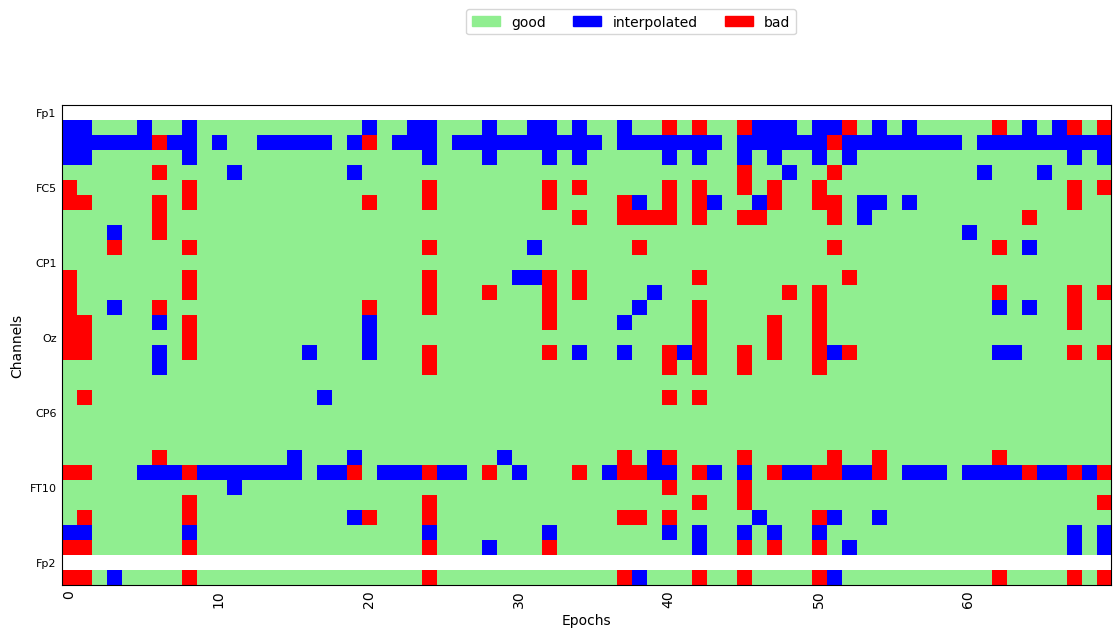

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0019_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0019_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1036644 =      0.000 ...  4146.576 secs
Ready.
Reading 0 ... 1036644  =      0.000 ...  4146.576 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 12 epochs: 15, 16, 18, 22, 23, 36, 37, 38, 39, 65, 67, 69


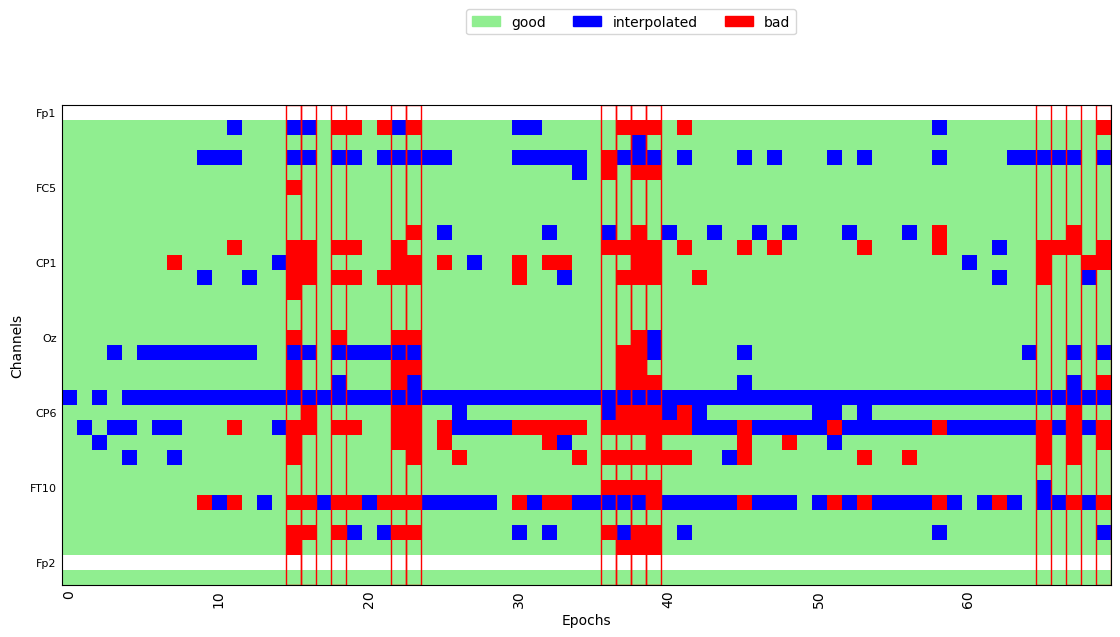

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 16 epochs: 15, 18, 21, 22, 24, 33, 37, 38, 39, 41, 51, 62, 63, 64, 68, 69


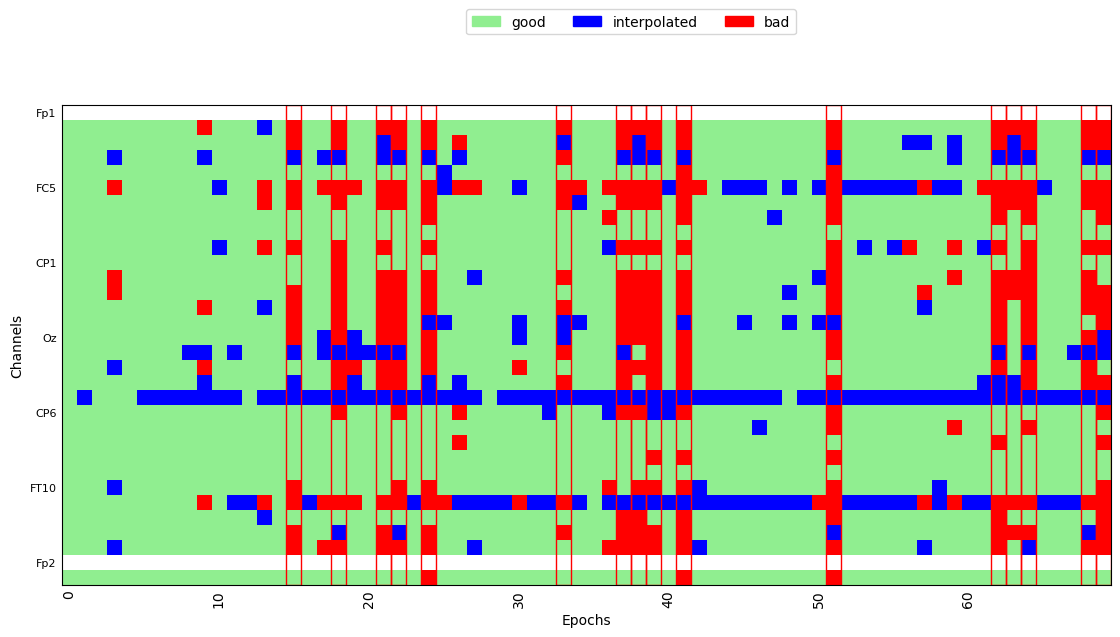

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=1


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 9, 59, 65, 66


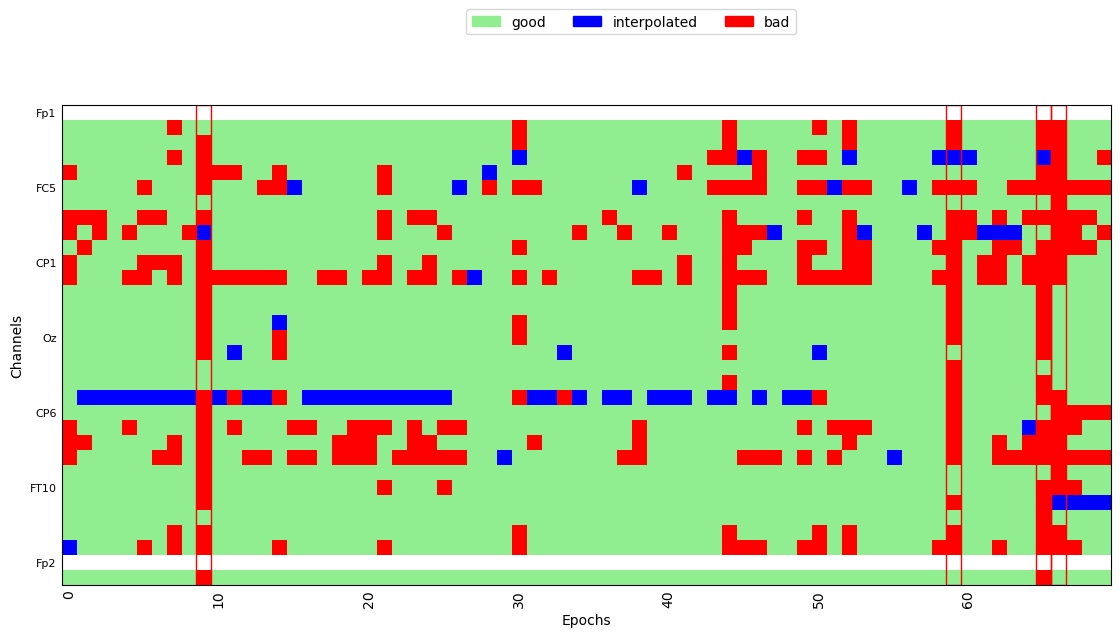

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


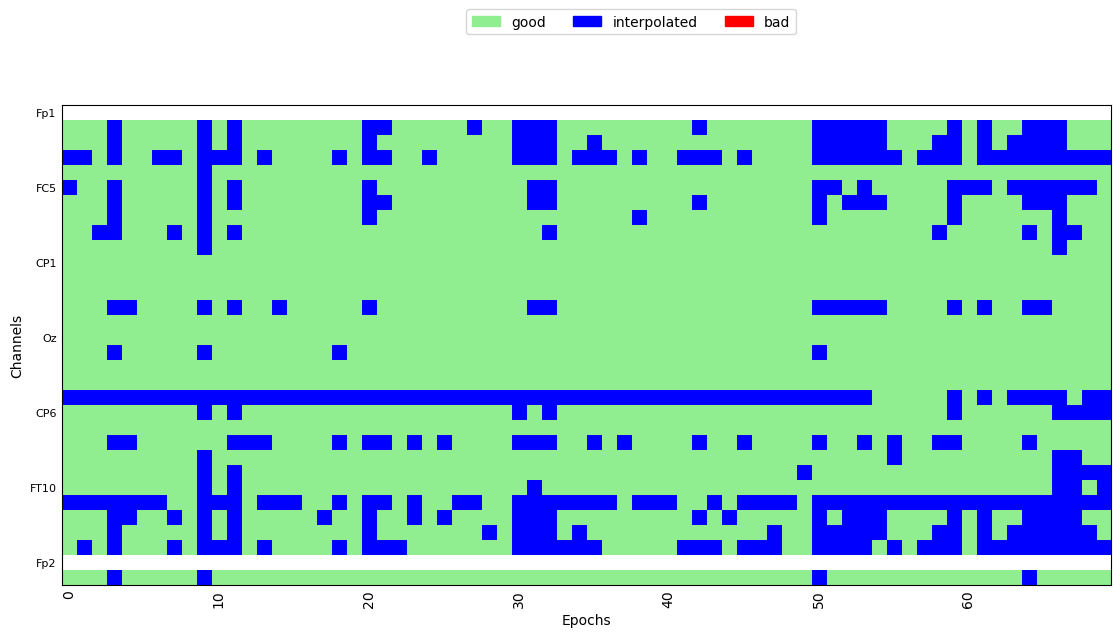

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 63, 65


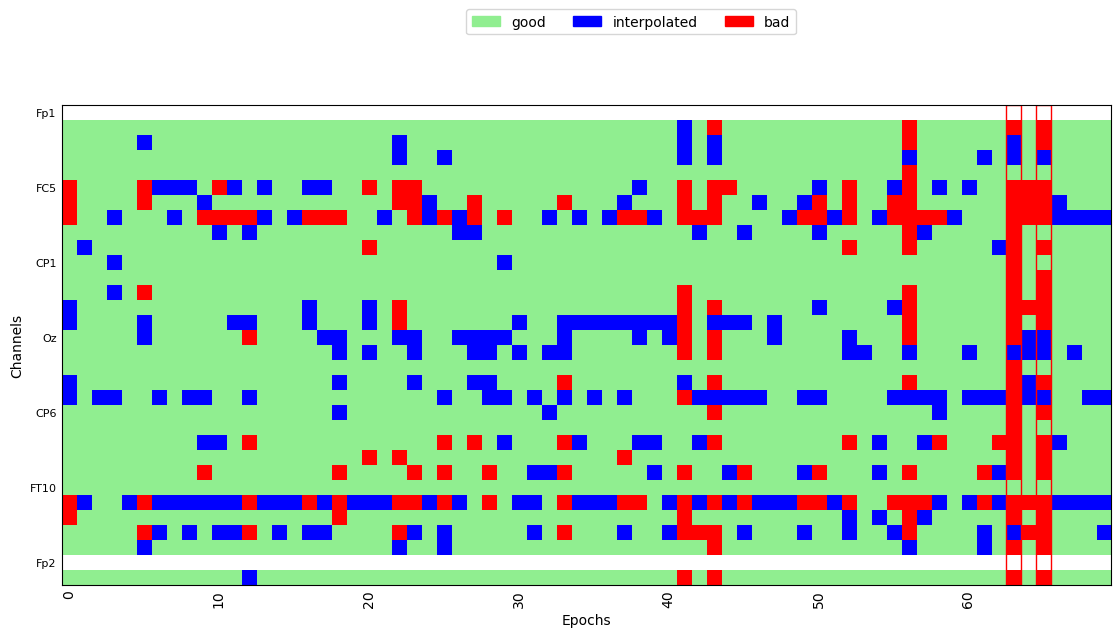

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 50, 63


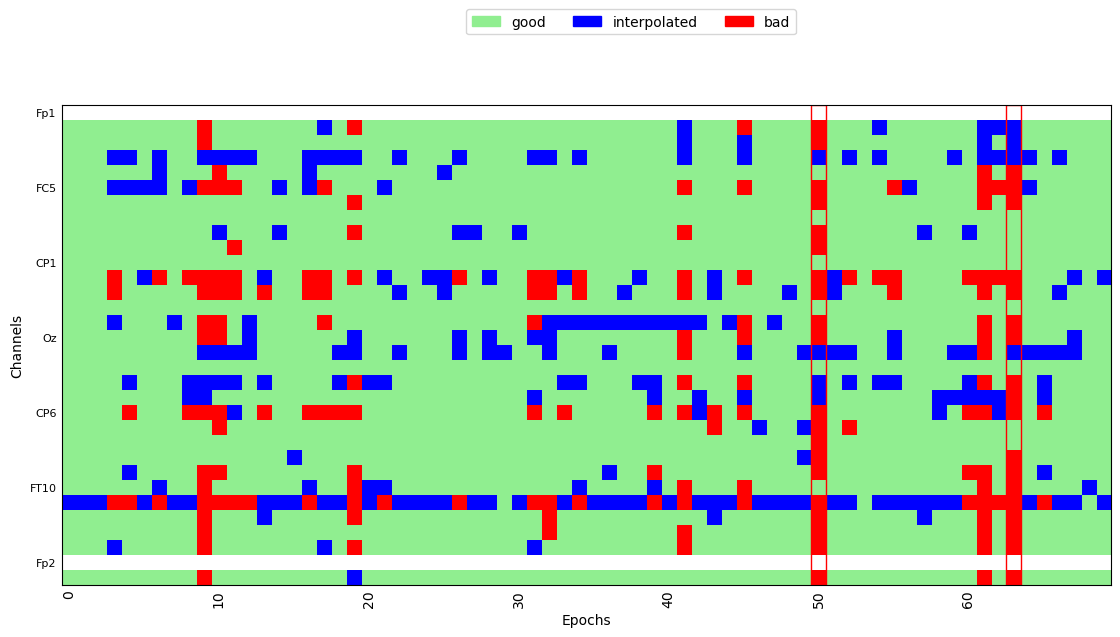

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 2, 5, 8, 11, 12, 13, 16, 19, 23, 39, 40, 41, 46, 49, 57, 63, 67, 69


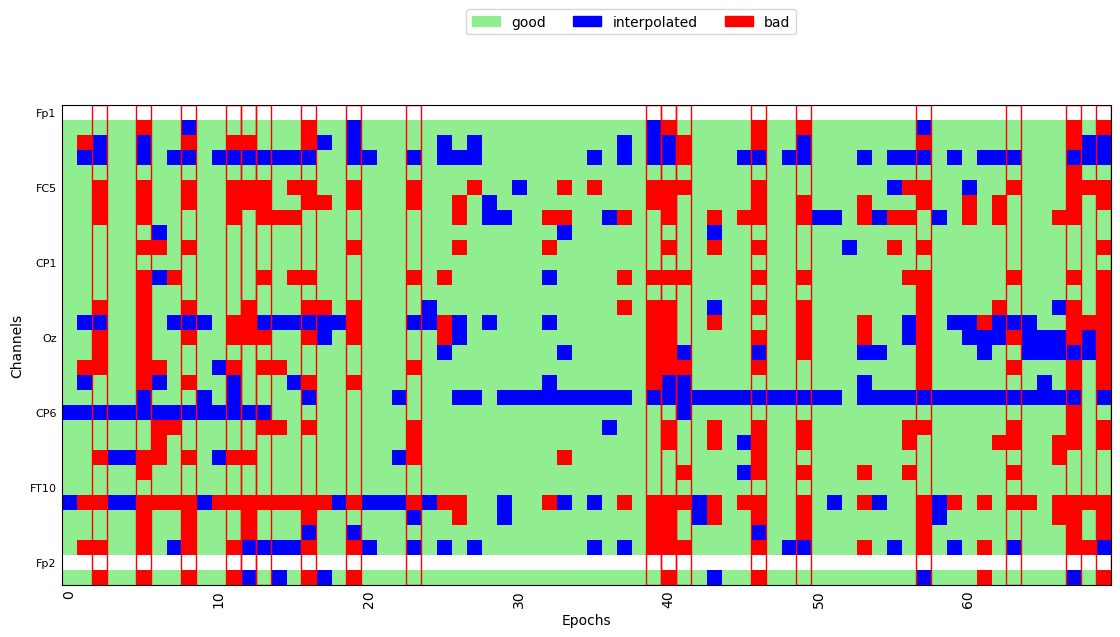

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 6 epochs: 1, 24, 40, 43, 46, 67


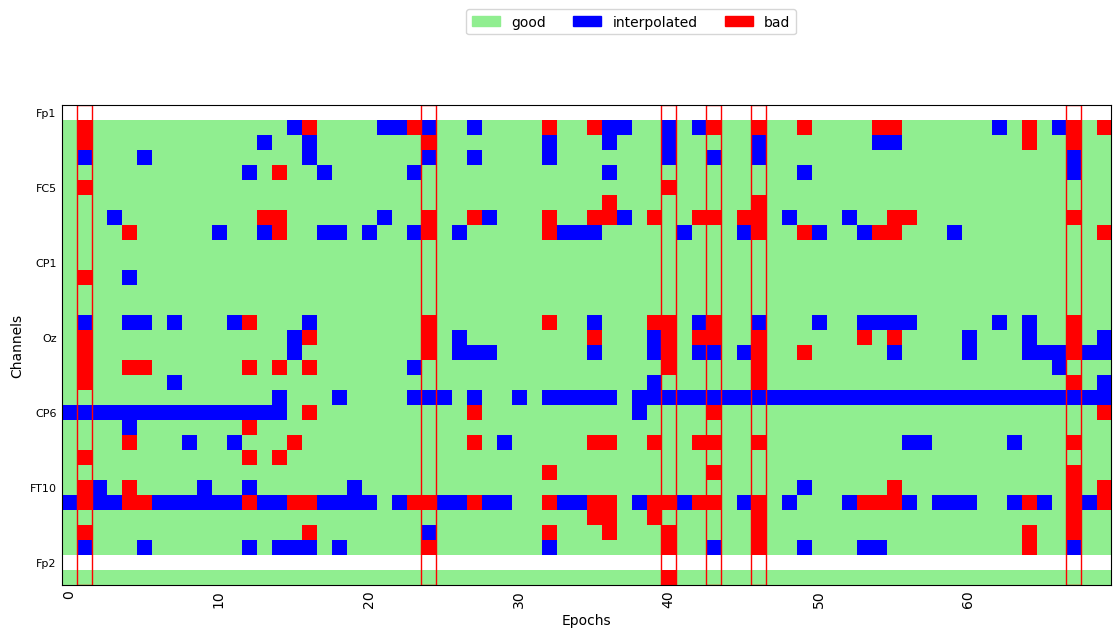

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0045_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0045_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1055834 =      0.000 ...  4223.336 secs
Ready.
Reading 0 ... 1055834  =      0.000 ...  4223.336 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


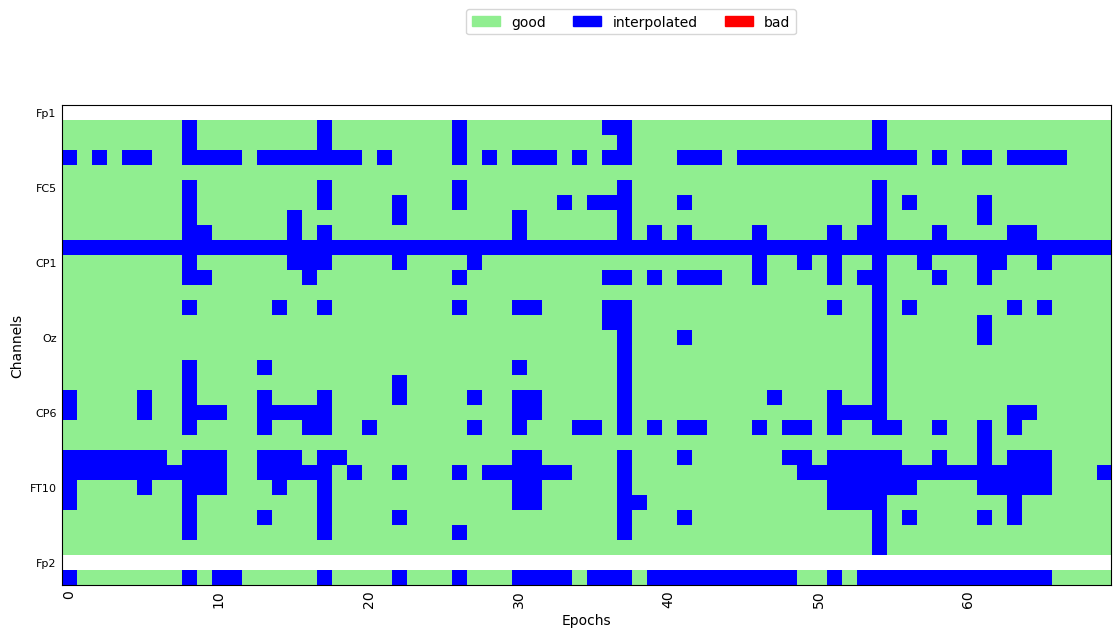

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 8 epochs: 1, 11, 30, 42, 51, 56, 57, 63


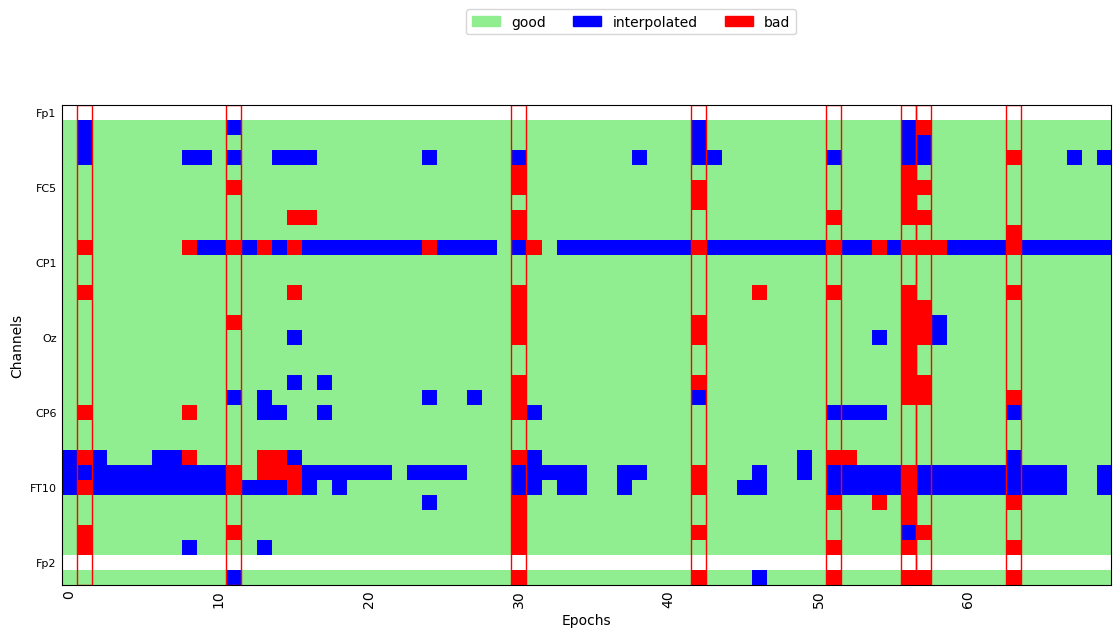

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 3, 17, 45, 59


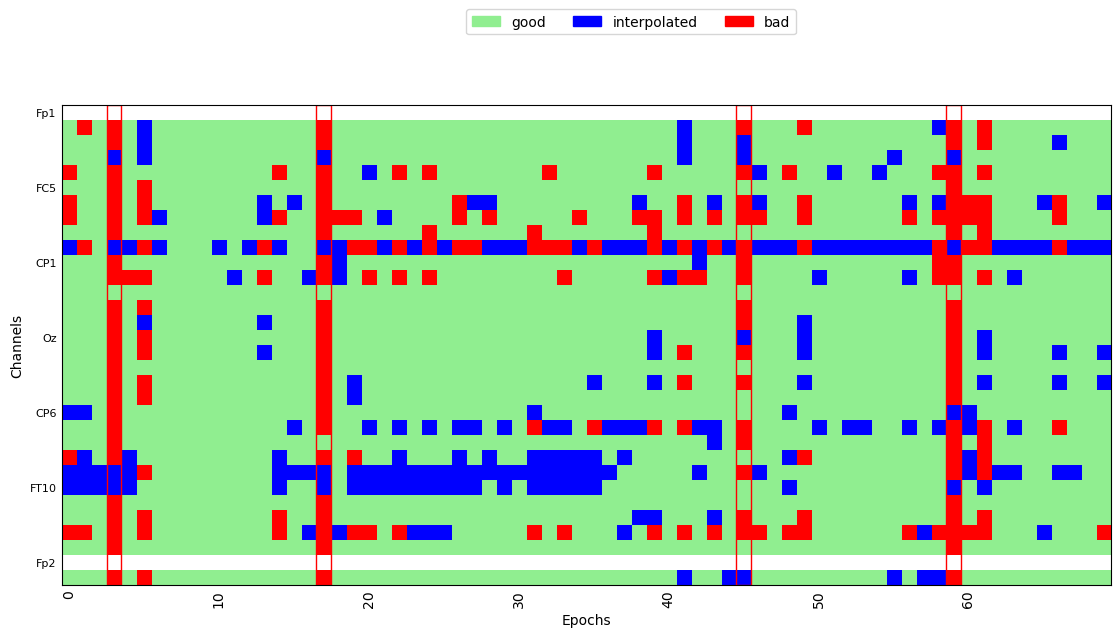

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 0, 3, 17, 34


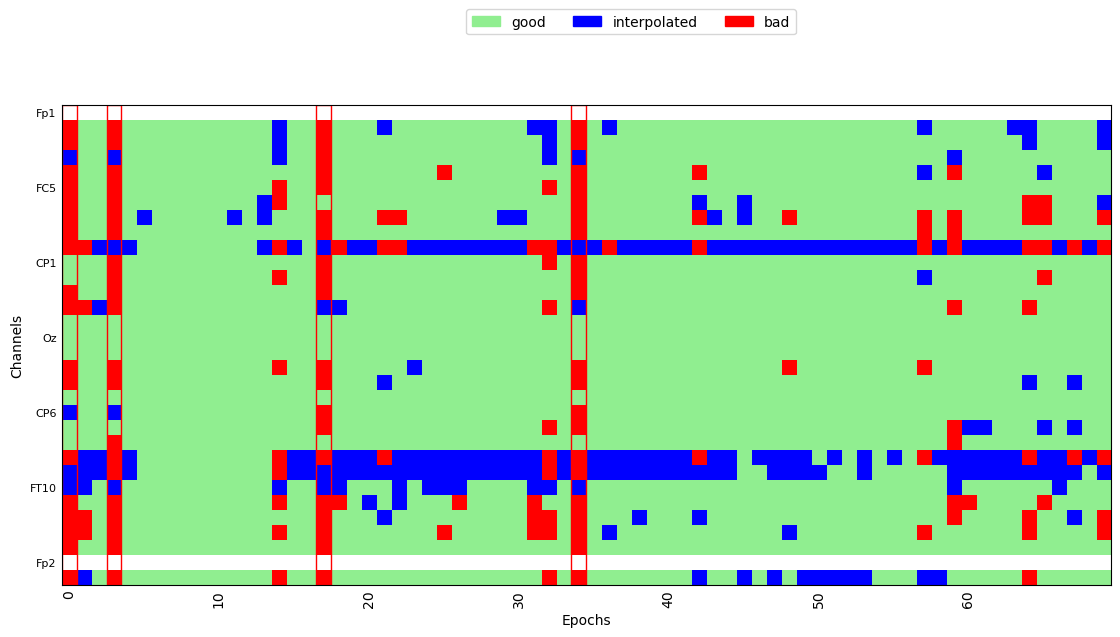

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 5, 28, 41, 64


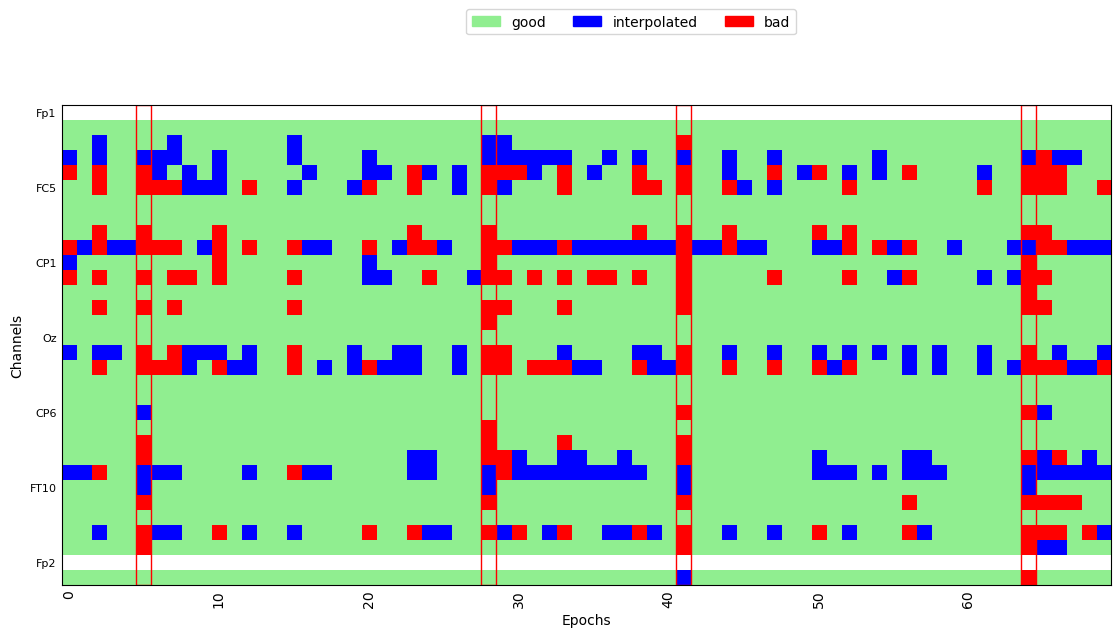

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 5, 64, 67, 68


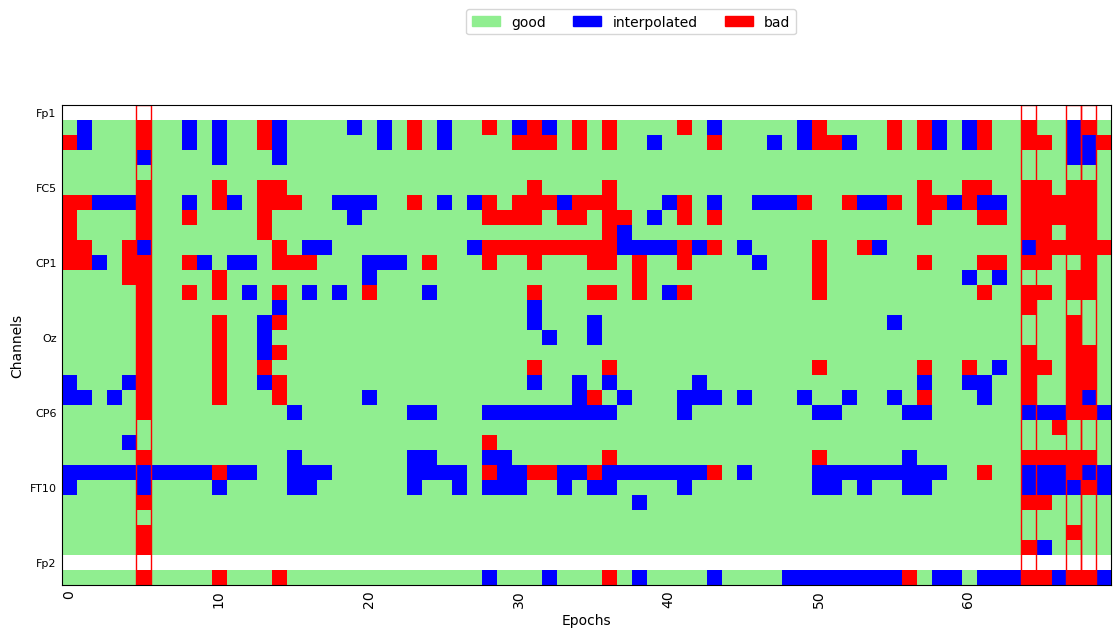

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 1, 5, 27, 34, 41, 48, 61


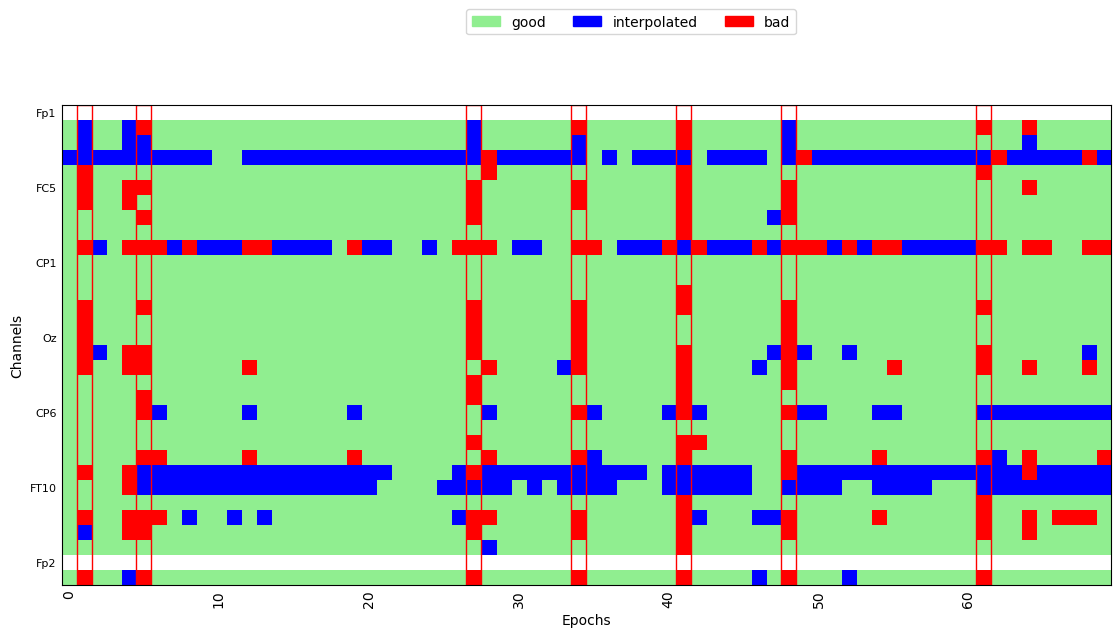

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 18 epochs: 0, 2, 3, 5, 7, 12, 14, 18, 32, 33, 35, 41, 44, 48, 54, 61, 64, 69


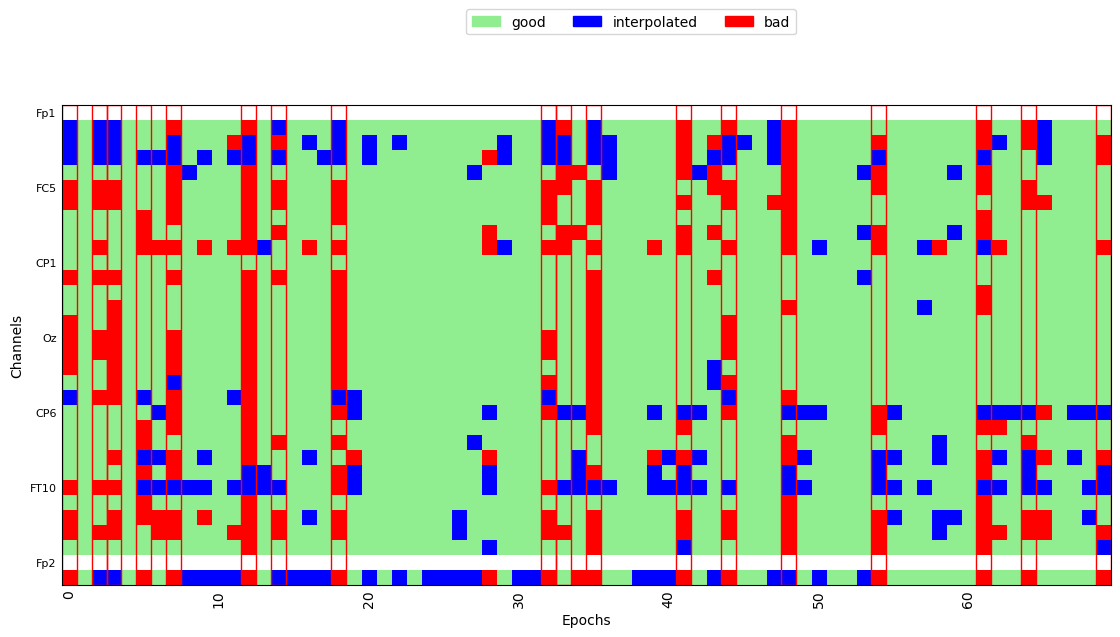

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0049_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0049_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1020879 =      0.000 ...  4083.516 secs
Ready.
Reading 0 ... 1020879  =      0.000 ...  4083.516 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (6 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 0, 6, 22, 32, 33


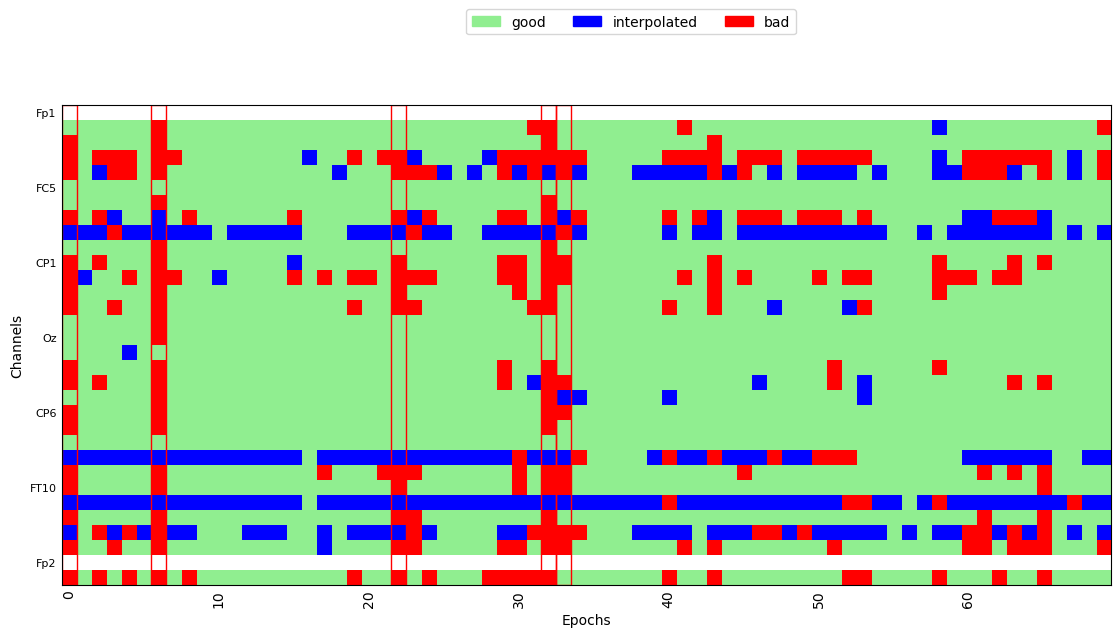

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 5 epochs: 31, 38, 51, 60, 65


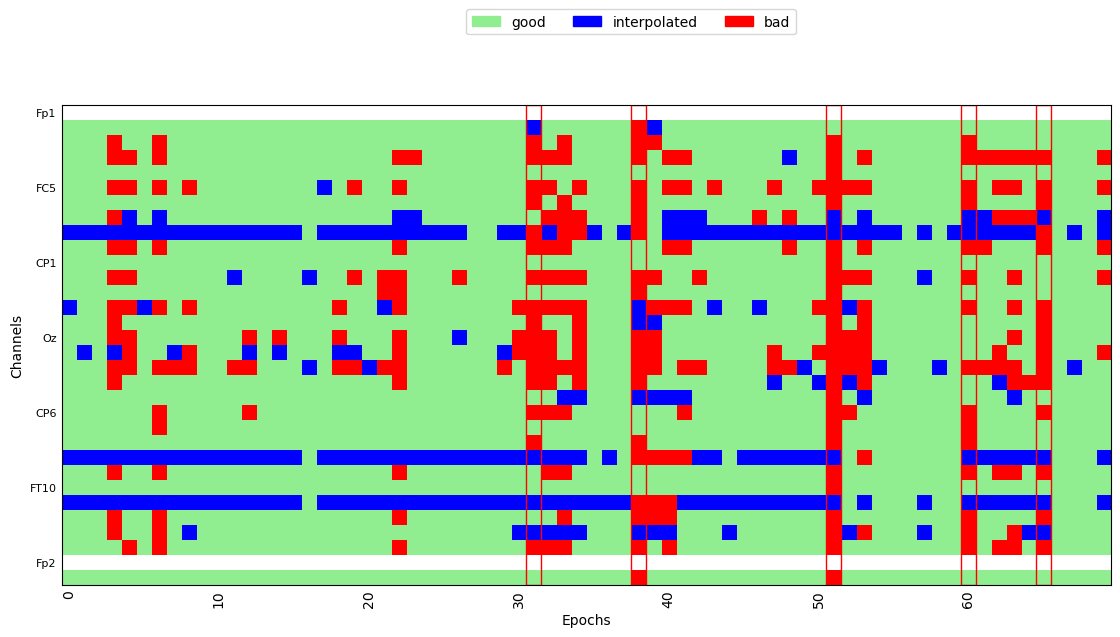

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 4 epochs: 31, 61, 65, 67


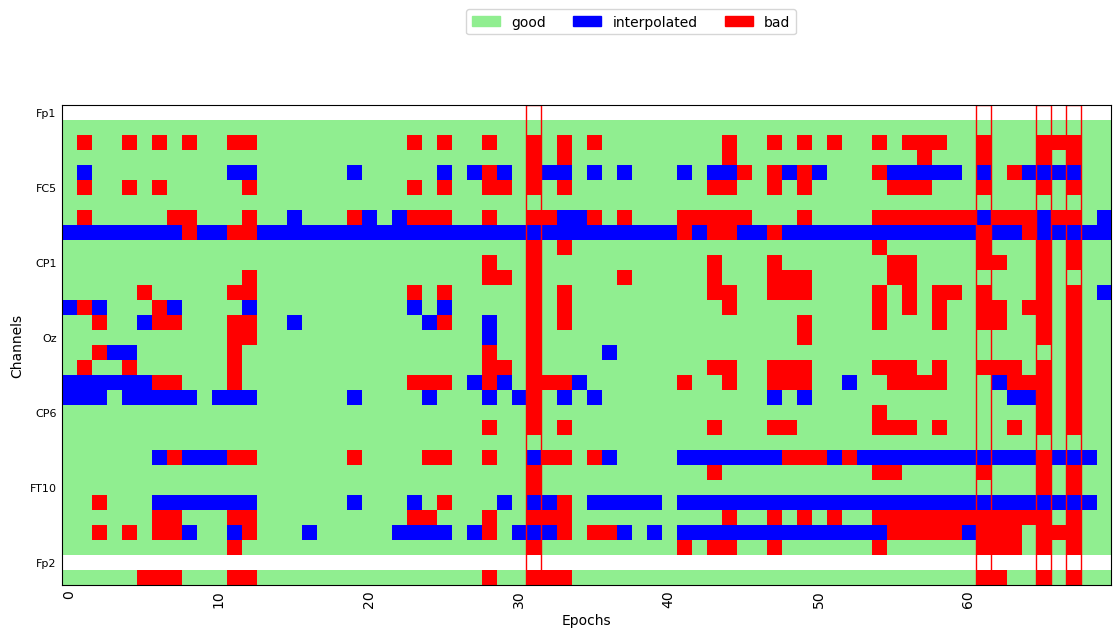

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 10 epochs: 31, 33, 44, 48, 54, 61, 63, 64, 65, 66


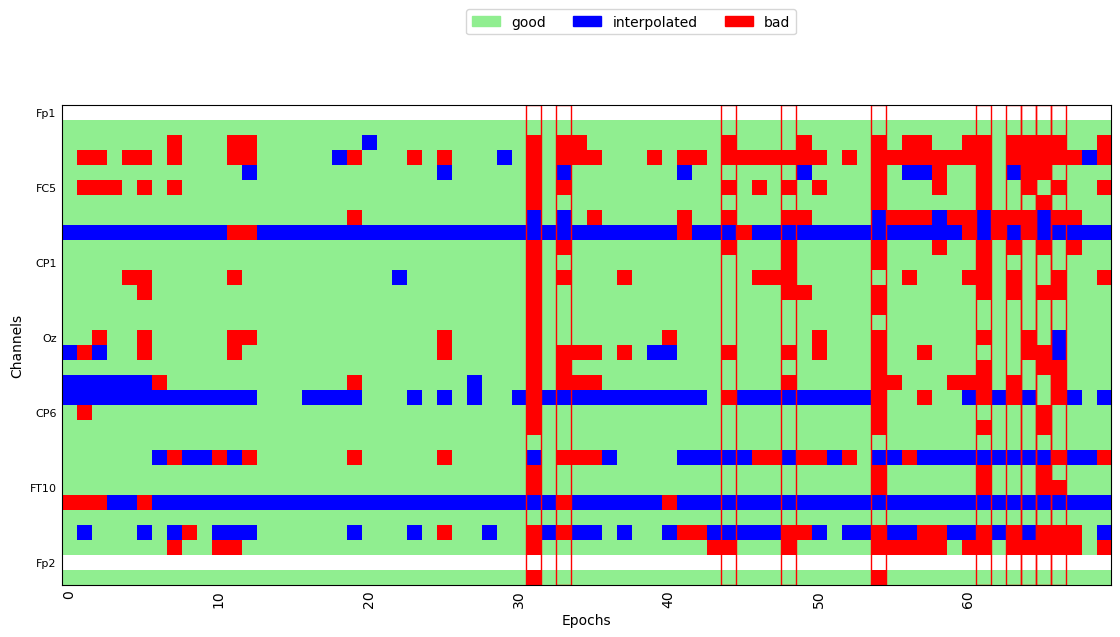

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 1 epoch: 12


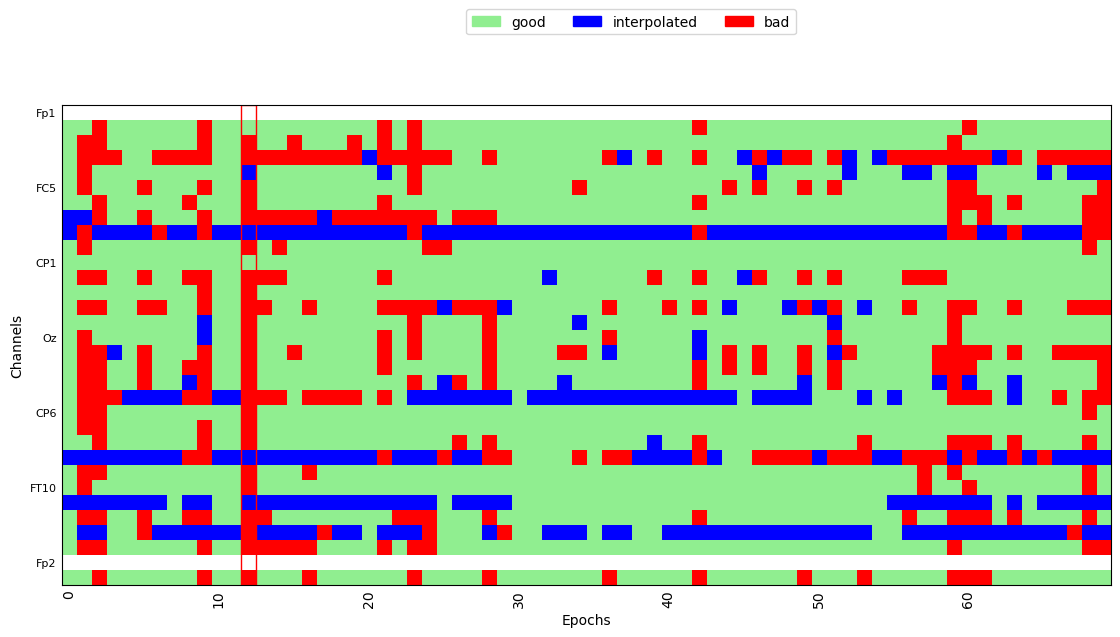

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.80 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 12, 67


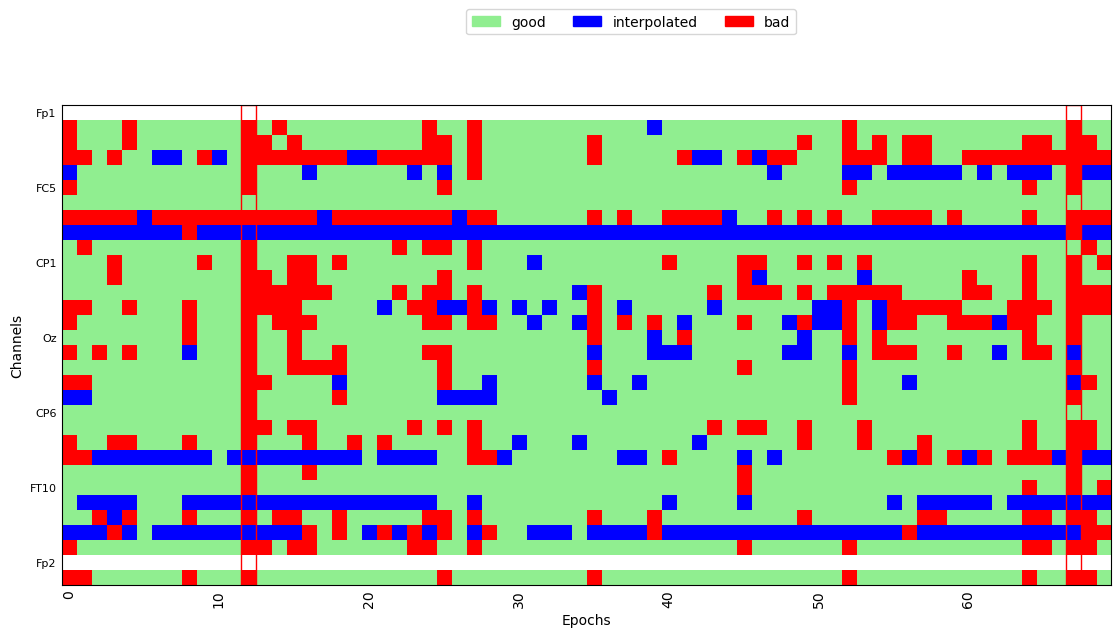

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 52, 56


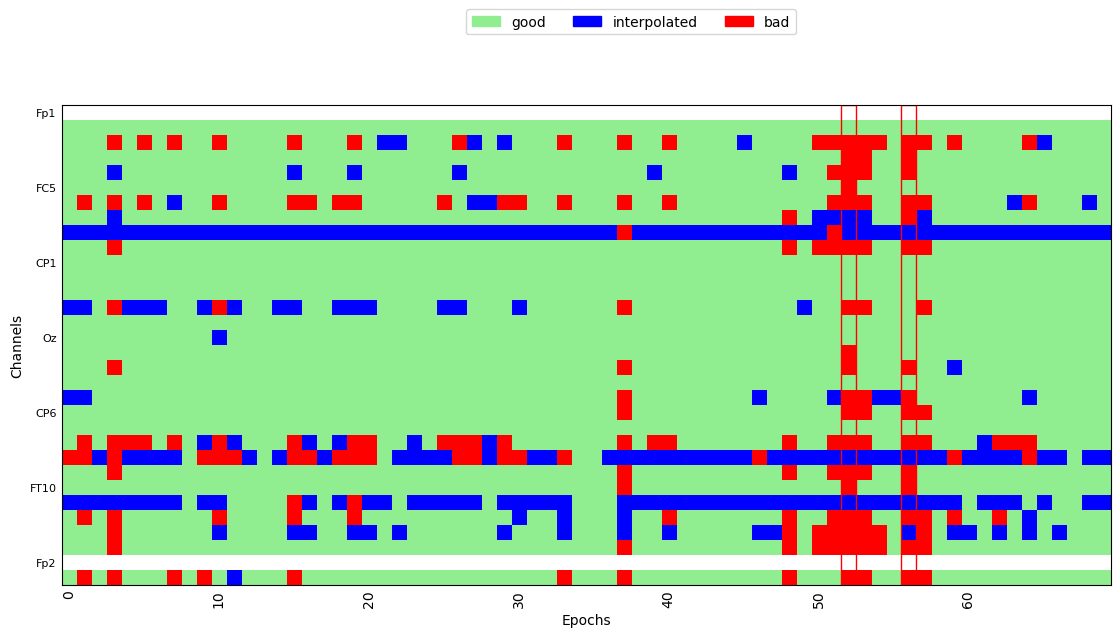

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 7 epochs: 10, 36, 51, 52, 53, 56, 67


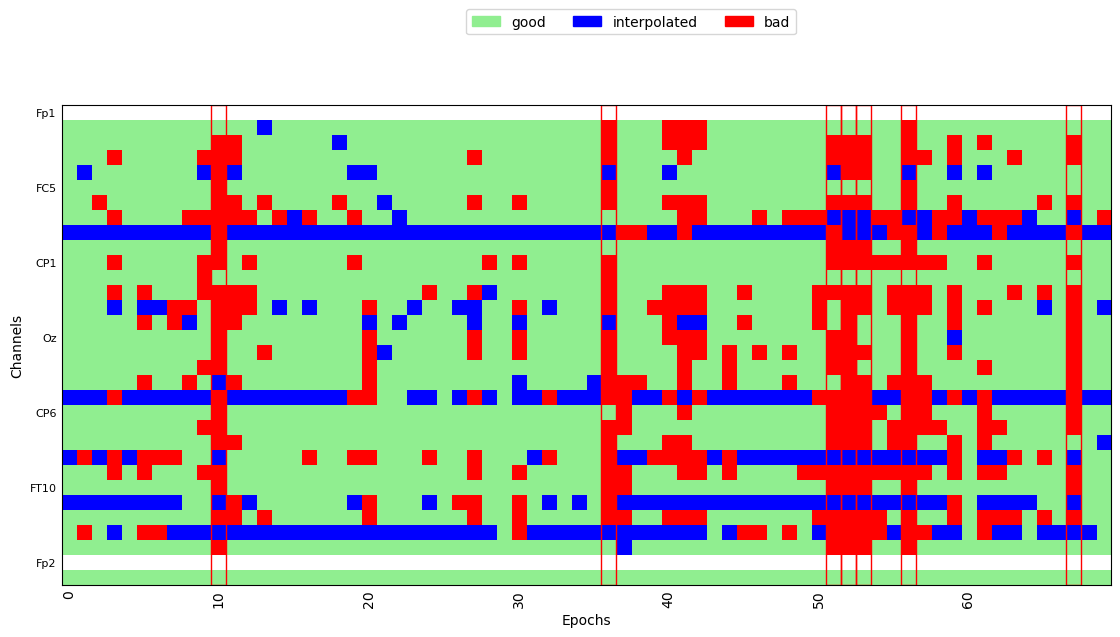

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Opening raw data file /Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0070_VOT_corr_filt_bads_ica.fif...


/var/folders/j8/8nyf6njj5nzfjcv6s23y3nn40000gn/T/ipykernel_27719/3955615729.py:44: RuntimeWarning: This filename (/Users/chaohan/Library/CloudStorage/OneDrive-UniversityofToronto/Projects/Laryngeal/eeg_preprocessed_NEW/4_ica/CUE2024_0070_VOT_corr_filt_bads_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(input_dir + file, preload = True)


    Range : 0 ... 1020014 =      0.000 ...  4080.056 secs
Ready.
Reading 0 ... 1020014  =      0.000 ...  4080.056 secs...
Not setting metadata
560 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 560 events and 301 original time points ...
0 bad epochs dropped
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (7 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 13 epochs: 3, 4, 6, 8, 9, 13, 17, 21, 31, 40, 53, 55, 68


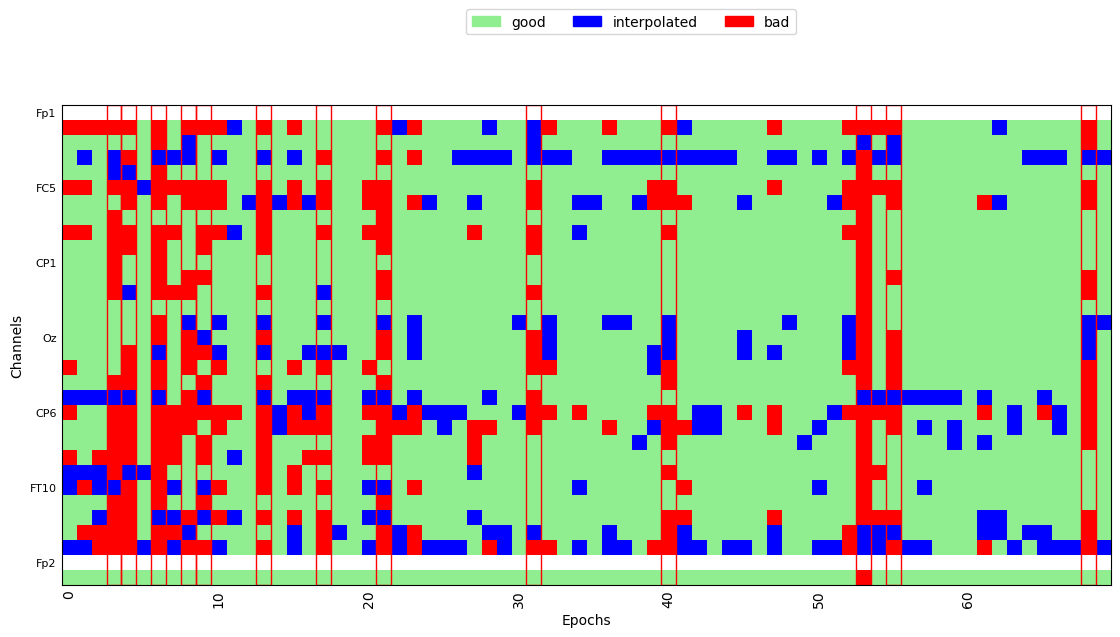

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=1.00 and n_interpolate=29


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

No bad epochs were found for your data. Returning a copy of the data you wanted to clean. Interpolation may have been done.


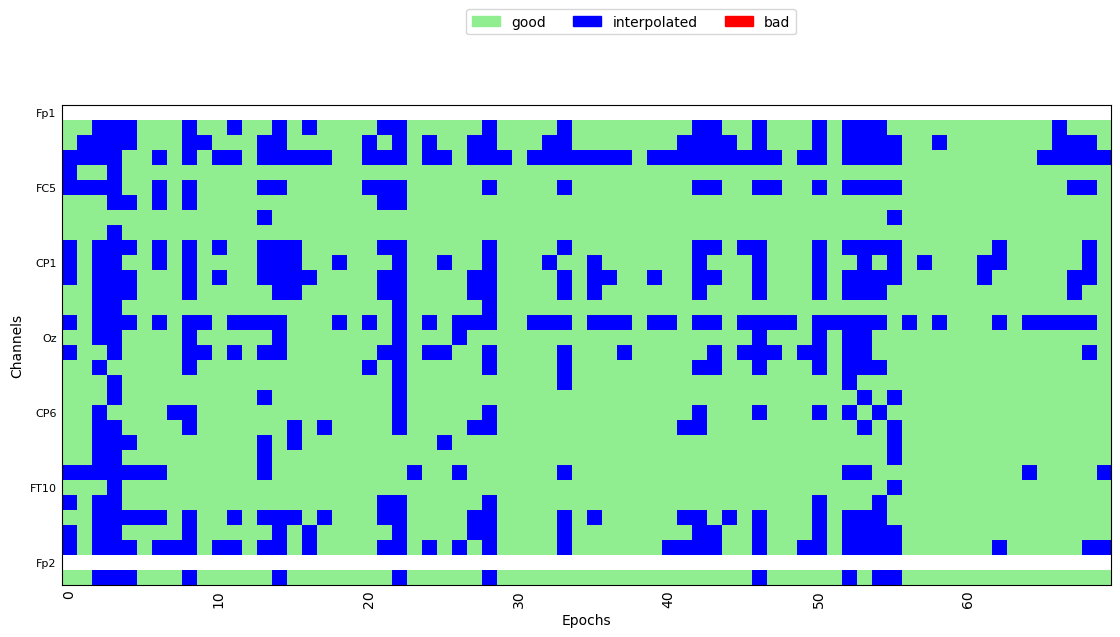

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.60 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 3 epochs: 4, 21, 58


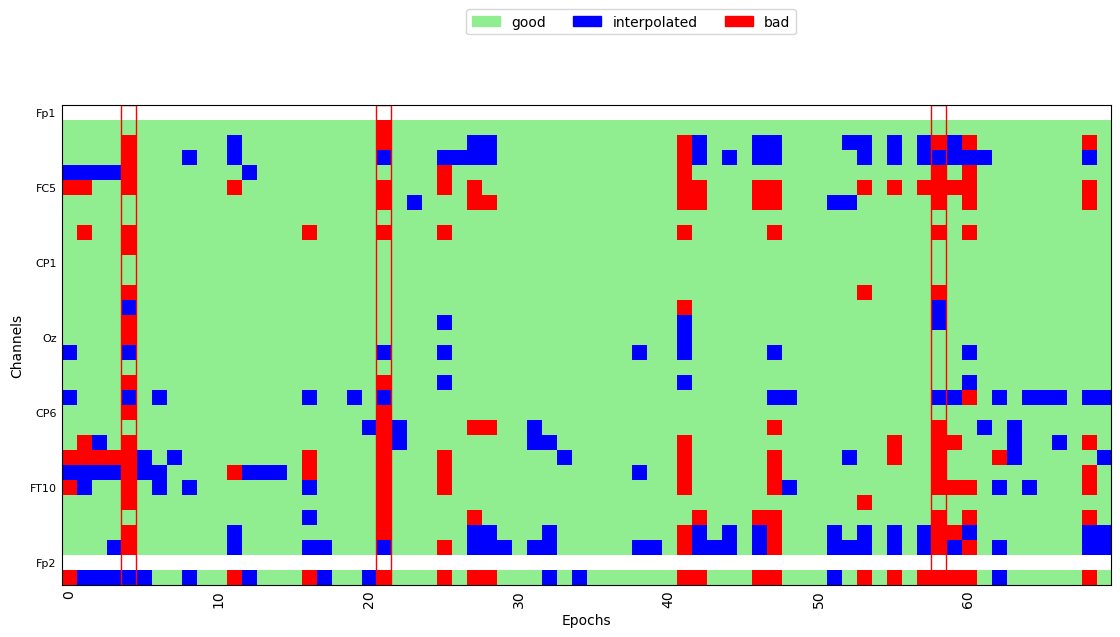

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.30 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 17 epochs: 0, 1, 4, 6, 8, 9, 10, 25, 47, 48, 52, 58, 59, 60, 64, 67, 69


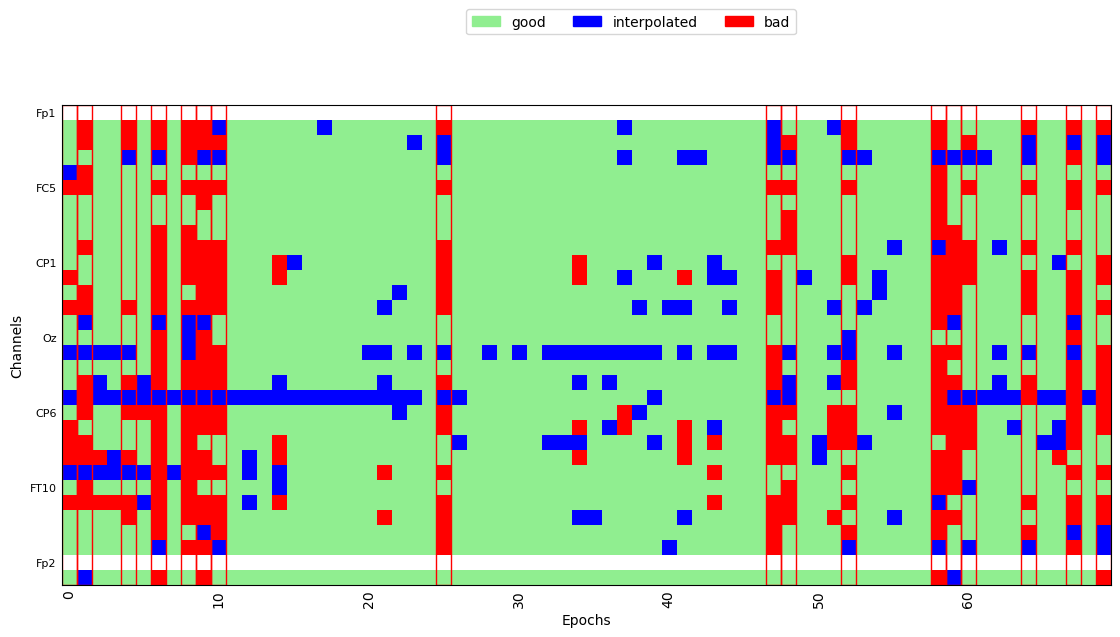

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.70 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 2 epochs: 0, 49


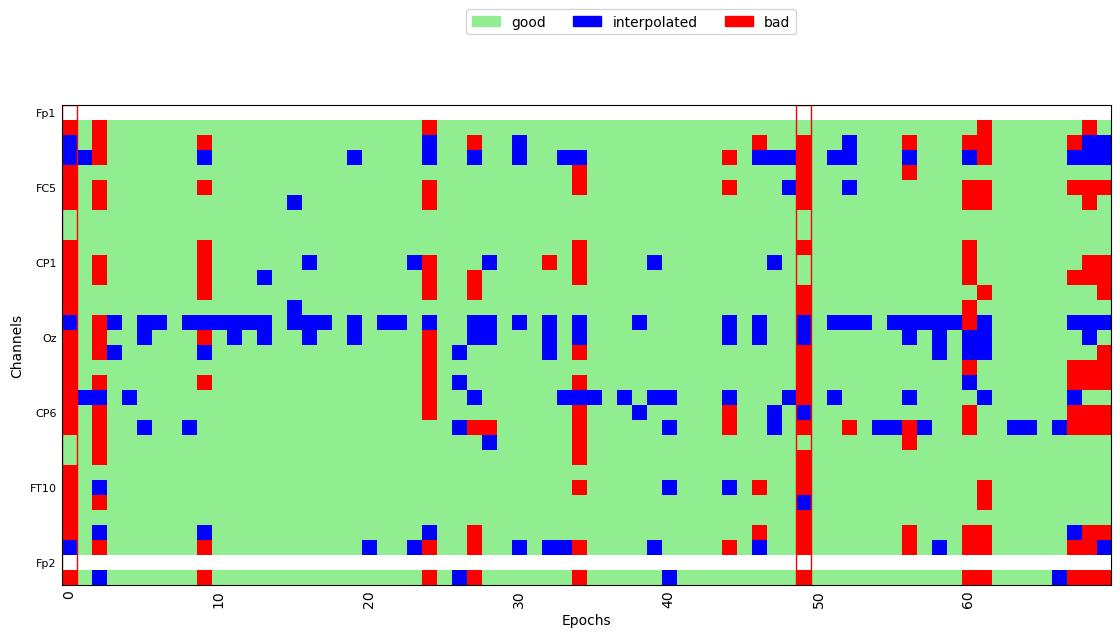

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 11 epochs: 0, 18, 23, 33, 34, 39, 49, 50, 59, 60, 61


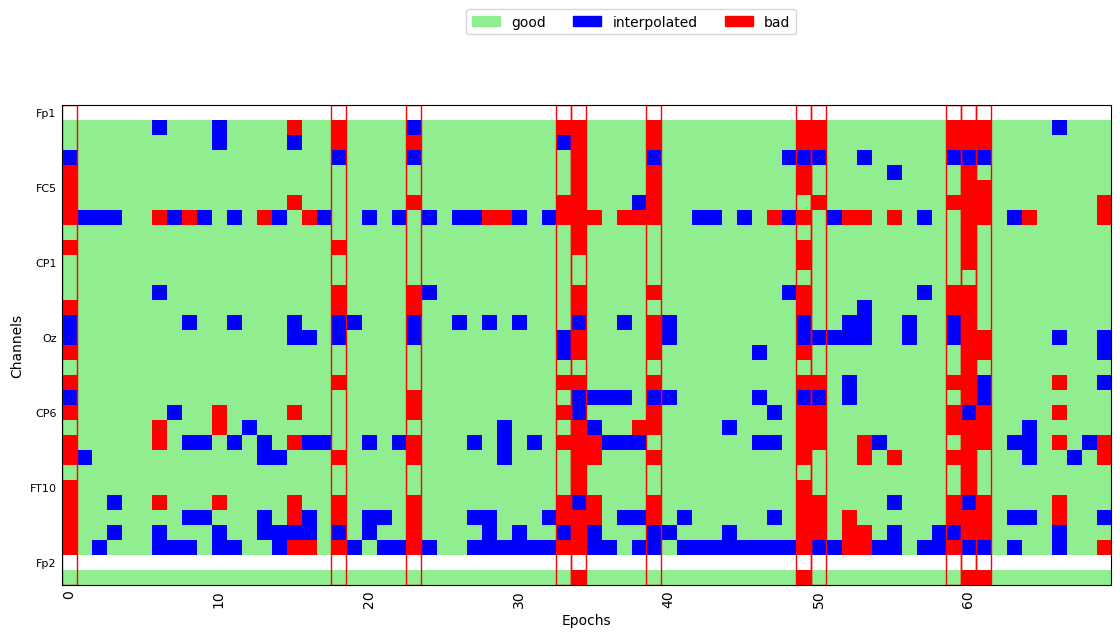

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.40 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 15 epochs: 2, 5, 13, 15, 24, 25, 26, 33, 56, 57, 58, 59, 61, 62, 68


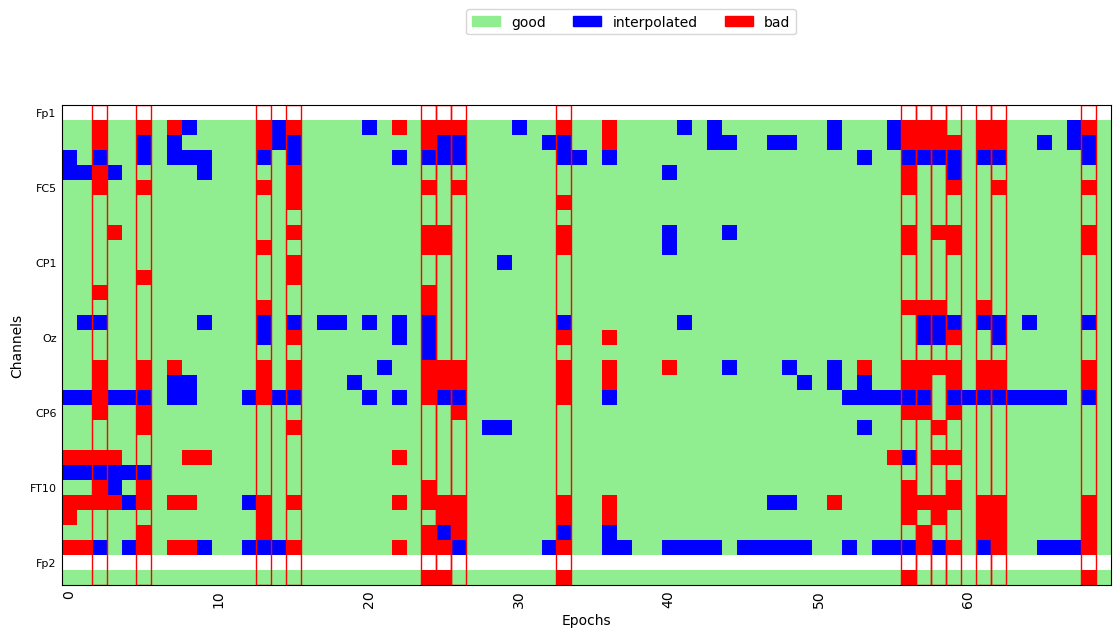

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Running autoreject on ch_type=eeg


  0%|          | Creating augmented epochs : 0/30 [00:00<?,       ?it/s]

  0%|          | Computing thresholds ... : 0/30 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

  0%|          | n_interp : 0/3 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

... (4 outputs left out)

  0%|          | Fold : 0/10 [00:00<?,       ?it/s]





Estimated consensus=0.50 and n_interpolate=4


  0%|          | Repairing epochs : 0/70 [00:00<?,       ?it/s]

Dropped 9 epochs: 1, 8, 37, 42, 47, 51, 58, 64, 65


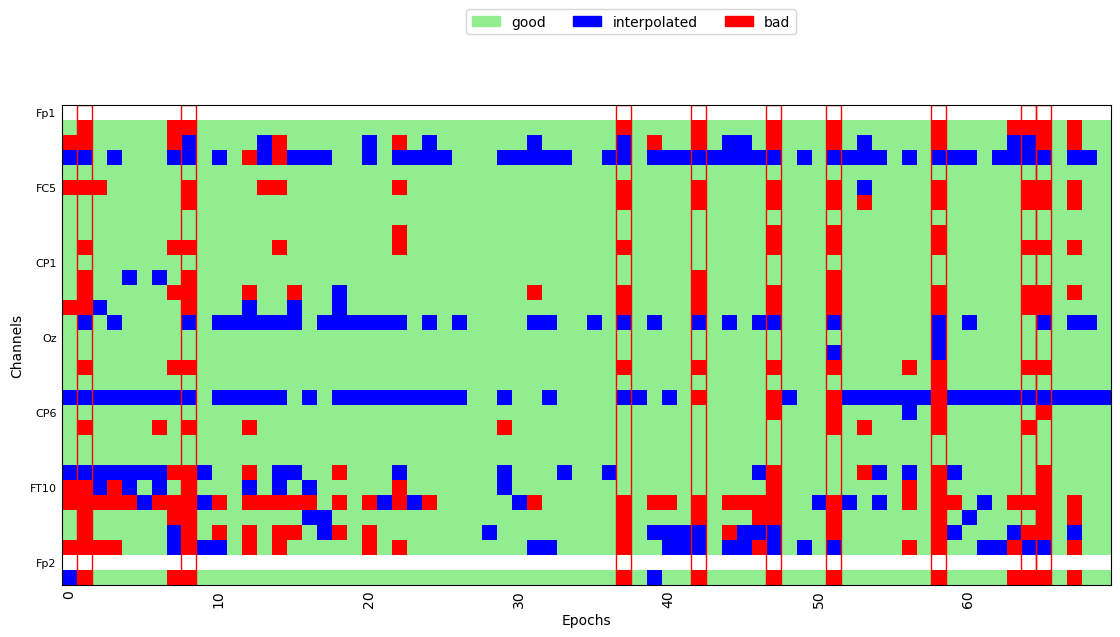

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


In [6]:
#### parameters ####

# directory
input_dir = work_dir + 'eeg_preprocessed_NEW/4_ica/'
output_dir = work_dir + 'eeg_preprocessed_NEW/5_evokeds/'

# epoch window: 
erp_t_start = -0.2; erp_t_end = 1

# exclude participants
exclude_ppts = [
    'VOT_0064', # too many bad channels
]

# condition
conditions = [
    'dorsal_highStan_lowDevi_stan', 
    'dorsal_highStan_lowDevi_devi', 
    'dorsal_lowStan_highDevi_stan', 
    'dorsal_lowStan_highDevi_devi', 
    'glottal_highStan_lowDevi_stan', 
    'glottal_highStan_lowDevi_devi', 
    'glottal_lowStan_highDevi_stan', 
    'glottal_lowStan_highDevi_devi',
]
        
# get file names
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


# initialize a log file
if ('epoch_log.txt' not in all_output):
    with open(output_dir + '/epoch_log.txt', 'a+') as f:
        f.write('participant' + '\t' + 'n_total_trials' + '\t' + 'rate_bad_trials' + '\n')


# re-reference, then epoch
for file in all_input:
    
    if file.endswith("ica.fif") and (file.split('_')[2] + '_' + file.split('_')[1] + '_ave.fif' not in all_output):
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)

        # # set eog
        # raw.set_channel_types({'Fp1':'eog', 'Fp2':'eog'})
        # # read in channel location info
        # raw.set_montage(montage)
        
        #### this is for source calculation ####
        # filter the data, optional
        # raw = raw.filter(l_freq=None, h_freq=30) 

        # sphere = mne.make_sphere_model('auto', 'auto', raw.info)
        # src = mne.setup_volume_source_space(sphere=sphere, exclude=30., pos=15.)
        # forward = mne.make_forward_solution(raw.info, trans=None, src=src, bem=sphere)
        # raw = raw.set_eeg_reference('REST', forward=forward)
        ########################################
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochsArray = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = erp_t_start, tmax = erp_t_end,
            # apply baseline correction
            # baseline = (None, 0),
            # remove epochs that meet the rejection criteria
            reject = None,
            preload = True,
        )

        ##### autoreject #####
        
        # get ppt info
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        # initialize evoked list
        evoked_list = []
        
        for cond in conditions:

            # extract epochs of that condition
            epochs = epochsArray[cond]

            # apply autoreject
            # set param
            ar = AutoReject(random_state=42)
            # apply
            epochs_ar, reject_log = ar.fit_transform(epochs, return_log=True)

            # save the reject log figure to a file
            reject_log.plot('horizontal').savefig(output_dir + ppt + '_' + cond + '_reject.png', dpi=300, bbox_inches='tight')

            ##### log trial count #####
            n_totalEpochs = len(reject_log.bad_epochs)
            n_badEpochs = sum(reject_log.bad_epochs)

            # # remove 0-trial events
            # if trial_count==0:
            #     del epochs.event_id[k]
            
            # good trial rate
            badEpochs_rate = round(n_badEpochs/n_totalEpochs, 2)

            # log reject summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + cond + '\t' + str(n_totalEpochs) + '\t' + str(badEpochs_rate) + '\n')

            # average-mastoids re-reference
            epochs_ar.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
            
            # average | get ERP for each condition
            evoked = epochs_ar.average(picks=['eeg'], by_event_type=False)

            # add condition label
            evoked.comment = cond

            # append
            evoked_list.append(evoked)
            
        # save
        mne.write_evokeds(output_dir + ppt + '_ave.fif', evoked_list)

## Evoked data quality check

In [ ]:
## parameters
# frequency of the eeg recording for audio downsampling
# eeg_freq = 500

# directory
input_dir = work_dir + '/data_preprocessed/5_evokeds/'

# file name
file = 'F0_0001_ave.fif'

# read in file
evokeds = mne.read_evokeds(input_dir + file, condition='dorsal_highStan_lowDevi_stan')

# check information
print(evokeds.info)

# plot spectrum of raw EEG
evokeds.compute_psd(fmax=30).plot()
plt.show()

# # if needed, plot a spectrum for each channel
# for ch_ind in epochs.info['ch_names']:
#     print('=====================')
#     print(ch_ind)
#     epochs.compute_psd(fmax=30, picks = ch_ind).plot(show=False, amplitude=False)
#     plt.show()

# butterfly plot
evokeds.plot_joint(picks="eeg")
evokeds.plot_topomap(times=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7], ch_type="eeg")
plt.show()

# TRF
segmenting continuous EEG into epochs for ERSP analysis
- re-reference
- segmentation

In [ ]:
# directory
input_dir = work_dir + 'data_preprocessed/3_ica/'
output_dir = work_dir + 'data_preprocessed/4_tfr_evokeds_unnormalized/'

# Epoch window: 
epoch_t_start = -1; epoch_t_end = 2

# criteria to reject epoch
reject_criteria = dict(eeg = 100e-6)       # 100 µV
# reject_criteria = dict(eeg = 150e-6)       # 150 µV
# reject_criteria = dict(eeg = 200e-6)       # 200 µV

exclude_ppts = [
    'F0_0059', # too noisy -> cells of 0 trial
]

tfr_method = 'morlet'

# frequencies
freq_start = 3
freq_end = 30
n_freq = 28
freqs = np.linspace(start=freq_start, stop=freq_end, num=n_freq)

# cycles
cycl_start = 3
cycl_step = 0.8
n_cycl = n_freq
n_cycles = np.linspace(start=cycl_start, stop=cycl_start+cycl_step*(n_cycl-1), num=n_cycl)

condition_list = [
    'dorsal_highStan_lowDevi_stan',
    'dorsal_lowStan_highDevi_stan',
    'glottal_highStan_lowDevi_stan',
    'glottal_lowStan_highDevi_stan',
]

# initialize a list for subjects with too many bad trials
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


#### re-reference, and epoch ####
for file in all_input:
    
    if file.endswith("ica.fif"):

        # get participant info
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        # skip bad participants
        if (ppt + '_tfr.hdf5' in all_output) or (ppt in exclude_ppts):
            continue
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)
        
        # average-mastoids re-reference
        raw.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
        
        #### this is for source calculation ####
        # filter the data, optional
        # raw = raw.filter(l_freq=None, h_freq=30) 

        # sphere = mne.make_sphere_model('auto', 'auto', raw.info)
        # src = mne.setup_volume_source_space(sphere=sphere, exclude=30., pos=15.)
        # forward = mne.make_forward_solution(raw.info, trans=None, src=src, bem=sphere)
        # raw = raw.set_eeg_reference('REST', forward=forward)
        ########################################

        # pick EEG channels
        # picks = mne.pick_types(raw.info, eeg = True)
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochs = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = epoch_t_start, tmax = epoch_t_end,
            # apply baseline correction
            baseline = None,
            # remove epochs that meet the rejection criteria
            reject = reject_criteria,
            preload = True,
        )
        


        # for each event, remove 0 trial events, record info, and check if a subject is bad
        for k, v in event_dict.items():
            
            # good trial count
            trial_count = len(epochs[k])
            
            # remove 0 trial event
            if trial_count==0:
                del epochs.event_id[k]
                
            # good trial rate
            goodTrial_rate = round( trial_count/sum(events_from_annot[:,2]==v), 2 )
            
            # record epoch summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + k + '\t' + str(trial_count) + '\t' + str(goodTrial_rate) + '\n')


        # ERSP

        # initialize tfrs list
        tfrs = []
        
        for condition in condition_list:
            # compute ERSP
            power = epochs[condition].compute_tfr(
                method=tfr_method,
                freqs=freqs,
                n_cycles=n_cycles,
                # return_itc=True,
            )
            
            # average
            power = power.average(method = 'mean', dim = 'epochs')

            # add comment
            power.comment = condition

            # append
            tfrs.append(power)
            
        # save single subject file
        mne.time_frequency.write_tfrs(fname=output_dir + ppt + '_tfr.hdf5', 
                                      tfr=tfrs)

        # release memory
        del power, tfrs

# Data for GAM

In [ ]:
# directory
input_dir = work_dir + 'data_preprocessed/3_ica/'
output_dir = work_dir + 'data_analysis/gam/'
# create a folder if the folder doesn't exist
# os.makedirs(output_dir, exist_ok=True)


# epoch window: 
erp_t_start = -0.2; erp_t_end = 0.8
# baseline
epoch_baseline = (-0.2, 0)

# criteria to reject epoch
reject_criteria = dict(eeg = 100e-6)       # 100 µV


#### get data ####

# get file names
all_input = os.listdir(input_dir)
all_output = os.listdir(output_dir)


# re-reference, then epoch
for file in all_input:
    
    if file.endswith("ica.fif") and (file.split('_')[2] + '_' + file.split('_')[1] + '_gam.csv' not in all_output):
        
        # read in data
        raw = mne.io.read_raw_fif(input_dir + file, preload = True)
        
        # average-mastoids re-reference
        raw.set_eeg_reference(ref_channels = ['TP9', 'TP10'])
        
        # get event info for segmentation
        events_from_annot, event_dict = mne.events_from_annotations(raw, verbose='WARNING')
        
        # segmentation for ERP
        epochs = mne.Epochs(
            raw,
            events = events_from_annot, event_id = event_dict,
            tmin = erp_t_start, tmax = erp_t_end,
            # apply baseline correction
            baseline = epoch_baseline,
            # remove epochs that meet the rejection criteria
            reject = reject_criteria,
            preload = True,
        )

        # get participant label
        ppt = file.split('_')[2] + '_' + file.split('_')[1]

        ##########################################################
        #### remove 0-trial events, and log epoch info ####
        for k, v in event_dict.items():
            
            # good trial count
            trial_count = len(epochs[k])
            
            # remove 0 trial event
            if trial_count==0:
                del epochs.event_id[k]
                
            # good trial rate
            goodTrial_rate = round( trial_count/sum(events_from_annot[:,2]==v), 2 )
            
            # record epoch summary
            with open(output_dir + 'epoch_summary.txt', 'a+') as f:
                _ =f.write(ppt + '\t' + k + '\t' + str(trial_count) + '\t' + str(goodTrial_rate) + '\n')
        ##########################################################
        
        # apply baseline
        epochs.apply_baseline(baseline=epoch_baseline, verbose='WARNING')

        # extract data
        df = epochs.to_data_frame(time_format='ms')

        # add info of group, ppt, and item
        df['participant'] = ppt
            
        # save
        df.to_csv(output_dir + ppt + '_gam.csv', index=False)
        
        # reduce memory usage
        del df